# New Section

In [ ]:
!pip install -q \
    huggingface_hub \
    monai \
    timm \
    segmentation-models-pytorch \
    torchmetrics \
    scikit-image \
    scipy \
    scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 82.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 67.0 MB/s eta 0:00:00


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
from huggingface_hub import snapshot_download

DATA_ROOT = "/content/ACDC-PNG"

snapshot_download(
    repo_id="yscript/ACDC-PNG",
    repo_type="dataset",
    local_dir=DATA_ROOT
)

print("Download complete.")
print("Dataset location:", DATA_ROOT)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Download complete.
Dataset location: /content/ACDC-PNG


In [ ]:
for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level < 4:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for f in files[:5]:
            print(f"{indent}    {f}")

ACDC-PNG/
    ACDC_png_ysc.zip
    .gitattributes
    README.md
    .cache/
        huggingface/
            .gitignore
            CACHEDIR.TAG
            download/
                README.md.lock
                README.md.metadata
                ACDC_png_ysc.zip.lock
                .gitattributes.lock
                ACDC_png_ysc.zip.metadata
            trees/
                f0420792cbd0481117cdcf528727554c000b26f4.json


Extract The ACDC Dataset

In [ ]:
import os
import zipfile

zip_path = "/content/ACDC-PNG/ACDC_png_ysc.zip"
extract_path = "/content/ACDC-PNG/ACDC_png_ysc"

# Extract only if needed
if not os.path.exists(extract_path):
    print("Extracting ACDC dataset...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/ACDC-PNG")

    print("Extraction complete.")
else:
    print("Dataset already extracted.")

print("\nContents of /content/ACDC-PNG:")
print(os.listdir("/content/ACDC-PNG"))

Extracting ACDC dataset...
Extraction complete.

Contents of /content/ACDC-PNG:
['ACDC_png_ysc.zip', '.gitattributes', 'ACDC_png_ysc', 'README.md', '.cache']


In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level < 4:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for f in files[:5]:
            print(f"{indent}    {f}")

ACDC_png_ysc/
    ACDC_png_split_5percent/
        train-label/
            mask/
                patient050_frame02_slice_5.npy
                patient099_frame02_slice_6.npy
                patient099_frame02_slice_14.npy
                patient099_frame01_slice_4.npy
                patient038_frame01_slice_1.npy
            image/
                patient050_frame01_slice_7.png
                patient050_frame01_slice_5.png
                patient050_frame02_slice_3.png
                patient099_frame01_slice_4.png
                patient099_frame02_slice_6.png
        val/
            mask/
                patient030_frame01_slice003.npy
                patient078_frame01_slice000.npy
                patient019_frame01_slice009.npy
                patient087_frame01_slice003.npy
                patient039_frame01_slice008.npy
            image/
                patient085_frame01_slice006.png
                patient030_frame01_slice000.png
                patient087_frame01_slice00

In [ ]:
print("\nTop-level folders inside extracted dataset:\n")

for item in os.listdir(extract_path):
    full_path = os.path.join(extract_path, item)

    if os.path.isdir(full_path):
        print("📁", item)
    else:
        print("📄", item)


Top-level folders inside extracted dataset:

📁 ACDC_png_split_5percent
📁 ACDC_png_split_10percent


In [ ]:
DATA_DIR = "/content/ACDC-PNG/ACDC_png_ysc/ACDC_png_split_10percent"

print("Using:", DATA_DIR)
print("Contents:", os.listdir(DATA_DIR))

Using: /content/ACDC-PNG/ACDC_png_ysc/ACDC_png_split_10percent
Contents: ['train-label', 'val', 'train-unlabel', 'test']


In [ ]:
import os
import re
from glob import glob

splits = ["train-label", "train-unlabel", "val", "test"]

for split in splits:
    split_path = os.path.join(DATA_DIR, split)

    print(f"\n{'='*60}")
    print(split.upper())
    print(f"{'='*60}")

    if not os.path.exists(split_path):
        print("Folder not found")
        continue

    image_dir = os.path.join(split_path, "image")
    mask_dir  = os.path.join(split_path, "mask")

    images = sorted(glob(os.path.join(image_dir, "*.png")))
    masks  = sorted(glob(os.path.join(mask_dir, "*.npy")))

    # Extract patientXXX from filenames
    patients = set()

    for path in images:
        match = re.search(r"(patient\d+)", os.path.basename(path))
        if match:
            patients.add(match.group(1))

    print("Images:   ", len(images))
    print("Masks:    ", len(masks))
    print("Patients: ", len(patients))
    print("Patient IDs:", sorted(patients))


TRAIN-LABEL
Images:    136
Masks:     136
Patients:  7
Patient IDs: ['patient021', 'patient038', 'patient049', 'patient050', 'patient058', 'patient099', 'patient100']

TRAIN-UNLABEL
Images:    1176
Masks:     1176
Patients:  63
Patient IDs: ['patient003', 'patient004', 'patient005', 'patient006', 'patient009', 'patient010', 'patient012', 'patient014', 'patient015', 'patient016', 'patient017', 'patient018', 'patient020', 'patient023', 'patient025', 'patient026', 'patient027', 'patient029', 'patient031', 'patient032', 'patient034', 'patient035', 'patient036', 'patient037', 'patient040', 'patient041', 'patient042', 'patient043', 'patient044', 'patient046', 'patient047', 'patient048', 'patient051', 'patient053', 'patient054', 'patient055', 'patient056', 'patient057', 'patient060', 'patient061', 'patient062', 'patient063', 'patient067', 'patient069', 'patient070', 'patient071', 'patient072', 'patient073', 'patient074', 'patient076', 'patient077', 'patient079', 'patient086', 'patient088', '

In [ ]:
import os
import numpy as np
from glob import glob
from collections import Counter

unlabel_mask_dir = os.path.join(
    DATA_DIR,
    "train-unlabel",
    "mask"
)

mask_files = sorted(glob(os.path.join(unlabel_mask_dir, "*.npy")))

print("Total train-unlabel masks:", len(mask_files))

# Check every mask, not just a few examples

global_labels = set()
label_occurrence = Counter()
nonzero_masks = 0
empty_masks = 0

for mask_path in mask_files:

    mask = np.load(mask_path)

    unique_labels = np.unique(mask)

    global_labels.update(unique_labels.tolist())

    for label in unique_labels:
        label_occurrence[int(label)] += 1

    if np.any(mask > 0):
        nonzero_masks += 1
    else:
        empty_masks += 1


print("\nUnique labels across ALL train-unlabel masks:")
print(sorted(global_labels))

print("\nLabel occurrence:")
for label in sorted(label_occurrence):
    print(
        f"Label {label}: "
        f"{label_occurrence[label]} masks"
    )

print("\nNon-empty masks:", nonzero_masks)
print("Empty/background-only masks:", empty_masks)

Total train-unlabel masks: 1176

Unique labels across ALL train-unlabel masks:
[0, 1, 2, 3]

Label occurrence:
Label 0: 1176 masks
Label 1: 962 masks
Label 2: 1132 masks
Label 3: 1119 masks

Non-empty masks: 1138
Empty/background-only masks: 38


In [ ]:
print("\nExample masks:\n")

for mask_path in mask_files[::100][:10]:

    mask = np.load(mask_path)

    print(
        os.path.basename(mask_path),
        "| shape:", mask.shape,
        "| dtype:", mask.dtype,
        "| labels:", np.unique(mask)
    )


Example masks:

patient003_frame01_slice_1.npy | shape: (256, 256) | dtype: uint8 | labels: [0 2 3]
patient009_frame02_slice_8.npy | shape: (256, 208) | dtype: uint8 | labels: [0 1 2 3]
patient017_frame01_slice_1.npy | shape: (256, 216) | dtype: uint8 | labels: [0 1 2 3]
patient026_frame02_slice_4.npy | shape: (256, 216) | dtype: uint8 | labels: [0 1 2 3]
patient034_frame02_slice_2.npy | shape: (256, 224) | dtype: uint8 | labels: [0 1 2 3]
patient042_frame01_slice_5.npy | shape: (256, 232) | dtype: uint8 | labels: [0 1 2 3]
patient048_frame02_slice_1.npy | shape: (256, 208) | dtype: uint8 | labels: [0 2 3]
patient057_frame01_slice_7.npy | shape: (512, 428) | dtype: uint8 | labels: [0 1 2 3]
patient067_frame02_slice_8.npy | shape: (216, 256) | dtype: uint8 | labels: [0 1 2 3]
patient076_frame01_slice_7.npy | shape: (256, 256) | dtype: uint8 | labels: [0 1 2 3]


Image: patient003_frame01_slice_1.png
Mask: patient003_frame01_slice_1.npy
Labels: [0 2 3]


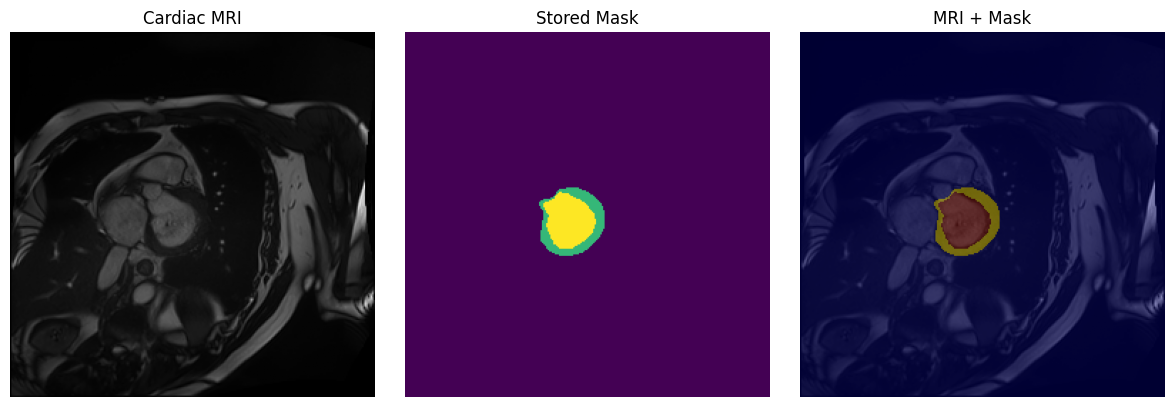

In [ ]:
import matplotlib.pyplot as plt

for mask_path in mask_files:

    mask = np.load(mask_path)

    if len(np.unique(mask)) >= 3:

        filename = os.path.basename(mask_path)

        image_name = filename.replace(".npy", ".png")

        image_path = os.path.join(
            DATA_DIR,
            "train-unlabel",
            "image",
            image_name
        )

        from PIL import Image
        image = np.array(Image.open(image_path))

        print("Image:", image_name)
        print("Mask:", filename)
        print("Labels:", np.unique(mask))

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(image, cmap="gray")
        plt.title("Cardiac MRI")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(mask, cmap="viridis", vmin=0, vmax=3)
        plt.title("Stored Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(image, cmap="gray")
        plt.imshow(mask, cmap="jet", alpha=0.4, vmin=0, vmax=3)
        plt.title("MRI + Mask")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        break

Verify the Actual Supervised Mask

In [ ]:
import os
import numpy as np
from glob import glob
from collections import Counter

train_mask_dir = os.path.join(
    DATA_DIR,
    "train-label",
    "mask"
)

mask_files = sorted(glob(os.path.join(train_mask_dir, "*.npy")))

global_labels = set()
label_occurrence = Counter()

for mask_path in mask_files:

    mask = np.load(mask_path)

    unique_labels = np.unique(mask)

    global_labels.update(unique_labels.tolist())

    for label in unique_labels:
        label_occurrence[int(label)] += 1


print("Total supervised masks:", len(mask_files))

print("\nUnique labels:")
print(sorted(global_labels))

print("\nLabel occurrence:")

label_names = {
    0: "Background",
    1: "Right Ventricle (RV)",
    2: "Myocardium",
    3: "Left Ventricle (LV)"
}

for label in sorted(label_occurrence):

    print(
        f"{label} = {label_names[label]}: "
        f"{label_occurrence[label]} masks"
    )

Total supervised masks: 136

Unique labels:
[0, 1, 2, 3]

Label occurrence:
0 = Background: 136 masks
1 = Right Ventricle (RV): 100 masks
2 = Myocardium: 129 masks
3 = Left Ventricle (LV): 128 masks


In [ ]:
from PIL import Image
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
import torch
import numpy as np
import os


IMAGE_SIZE = 224


class ACDCDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir,
        image_size=224
    ):

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".png")
        ])

        self.masks = sorted([
            f for f in os.listdir(mask_dir)
            if f.endswith(".npy")
        ])

        assert len(self.images) == len(self.masks), \
            "Number of images and masks do not match."

        print(
            f"Loaded {len(self.images)} image-mask pairs "
            f"from {image_dir}"
        )


    def __len__(self):
        return len(self.images)


    def __getitem__(self, idx):


        # IMAGE


        image_name = self.images[idx]
        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        image = Image.open(image_path).convert("L")

        # Resize MRI
        image = TF.resize(
            image,
            [self.image_size, self.image_size],
            interpolation=TF.InterpolationMode.BILINEAR
        )

        image = TF.to_tensor(image)

        # Grayscale → 3 channels
        image = image.repeat(3, 1, 1)



        # MASK


        mask_name = self.masks[idx]
        mask_path = os.path.join(
            self.mask_dir,
            mask_name
        )

        mask = np.load(mask_path)

        mask = torch.tensor(
            mask,
            dtype=torch.long
        )

        # IMPORTANT:
        # nearest-neighbor interpolation preserves
        # class IDs 0,1,2,3

        mask = mask.unsqueeze(0).float()

        mask = TF.resize(
            mask,
            [self.image_size, self.image_size],
            interpolation=TF.InterpolationMode.NEAREST
        )

        mask = mask.squeeze(0).long()


        return image, mask

Train Test Validation

In [ ]:
train_dataset = ACDCDataset(
    image_dir=os.path.join(
        DATA_DIR,
        "train-label",
        "image"
    ),
    mask_dir=os.path.join(
        DATA_DIR,
        "train-label",
        "mask"
    ),
    image_size=IMAGE_SIZE
)


val_dataset = ACDCDataset(
    image_dir=os.path.join(
        DATA_DIR,
        "val",
        "image"
    ),
    mask_dir=os.path.join(
        DATA_DIR,
        "val",
        "mask"
    ),
    image_size=IMAGE_SIZE
)


test_dataset = ACDCDataset(
    image_dir=os.path.join(
        DATA_DIR,
        "test",
        "image"
    ),
    mask_dir=os.path.join(
        DATA_DIR,
        "test",
        "mask"
    ),
    image_size=IMAGE_SIZE
)

Loaded 136 image-mask pairs from /content/ACDC-PNG/ACDC_png_ysc/ACDC_png_split_10percent/train-label/image
Loaded 210 image-mask pairs from /content/ACDC-PNG/ACDC_png_ysc/ACDC_png_split_10percent/val/image
Loaded 380 image-mask pairs from /content/ACDC-PNG/ACDC_png_ysc/ACDC_png_split_10percent/test/image


Verify Tensor Shapes

In [ ]:
image, mask = train_dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("\nImage dtype:", image.dtype)
print("Mask dtype:", mask.dtype)

print("\nImage min:", image.min().item())
print("Image max:", image.max().item())

print("\nMask labels:", torch.unique(mask))

Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([224, 224])

Image dtype: torch.float32
Mask dtype: torch.int64

Image min: 0.0
Image max: 0.9921568632125854

Mask labels: tensor([0, 2, 3])


Verify Resized Sample

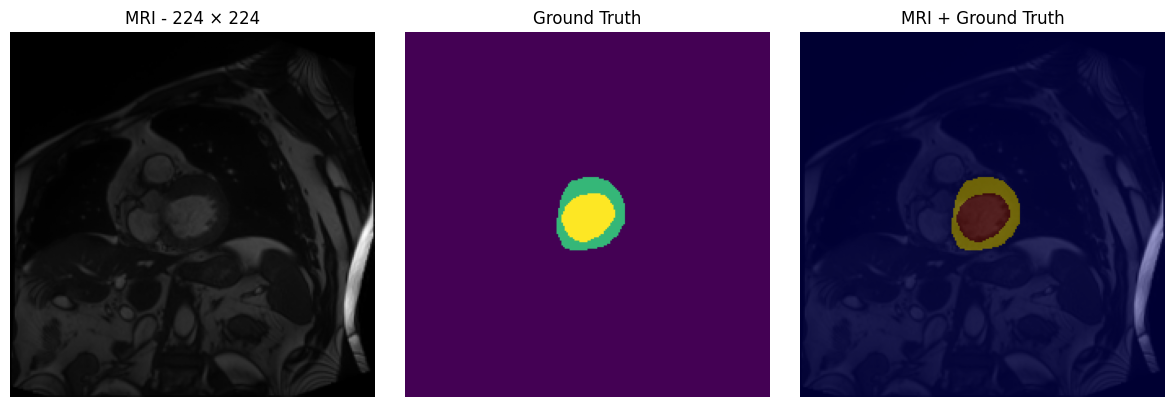

In [ ]:
image, mask = train_dataset[0]

image_show = image[0].numpy()
mask_show = mask.numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_show, cmap="gray")
plt.title("MRI - 224 × 224")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    mask_show,
    cmap="viridis",
    vmin=0,
    vmax=3
)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image_show, cmap="gray")
plt.imshow(
    mask_show,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=3
)
plt.title("MRI + Ground Truth")
plt.axis("off")

plt.tight_layout()
plt.show()

Install Albumentations

In [ ]:
!pip install -q albumentations

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

Training Augmentation

In [ ]:
train_transform = A.Compose([
    A.Resize(
        height=224,
        width=224
    ),

    A.HorizontalFlip(p=0.5),

    A.Affine(
        scale=(0.90, 1.10),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.3
    ),

    A.GaussNoise(
        std_range=(0.01, 0.03),
        p=0.2
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

In [ ]:
eval_transform = A.Compose([
    A.Resize(
        height=224,
        width=224
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

Replace Dataset Class

In [ ]:
from torch.utils.data import Dataset
from PIL import Image

import os
import numpy as np
import torch


class ACDCDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir,
        transform=None
    ):

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".png")
        ])

        self.masks = sorted([
            f for f in os.listdir(mask_dir)
            if f.endswith(".npy")
        ])

        assert len(self.images) == len(self.masks)

        print(
            f"Loaded {len(self.images)} image-mask pairs"
        )


    def __len__(self):
        return len(self.images)


    def __getitem__(self, idx):

        # Load MRI

        image_path = os.path.join(
            self.image_dir,
            self.images[idx]
        )

        image = np.array(
            Image.open(image_path).convert("L")
        )

        # Convert grayscale → RGB
        image = np.stack(
            [image, image, image],
            axis=-1
        )


        # Load mask

        mask_path = os.path.join(
            self.mask_dir,
            self.masks[idx]
        )

        mask = np.load(mask_path).astype(
            np.int64
        )


        # Transform together

        if self.transform:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]


        # Mask must remain LONG
        mask = mask.long()


        return image, mask

Recreate Dataset

In [ ]:
train_dataset = ACDCDataset(
    image_dir=os.path.join(
        DATA_DIR,
        "train-label",
        "image"
    ),
    mask_dir=os.path.join(
        DATA_DIR,
        "train-label",
        "mask"
    ),
    transform=train_transform
)


val_dataset = ACDCDataset(
    image_dir=os.path.join(
        DATA_DIR,
        "val",
        "image"
    ),
    mask_dir=os.path.join(
        DATA_DIR,
        "val",
        "mask"
    ),
    transform=eval_transform
)


test_dataset = ACDCDataset(
    image_dir=os.path.join(
        DATA_DIR,
        "test",
        "image"
    ),
    mask_dir=os.path.join(
        DATA_DIR,
        "test",
        "mask"
    ),
    transform=eval_transform
)

Loaded 136 image-mask pairs
Loaded 210 image-mask pairs
Loaded 380 image-mask pairs


Data Loaders

In [ ]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)

print("\nImage dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("\nImage range:")
print("Min:", images.min().item())
print("Max:", images.max().item())

print("\nLabels in batch:")
print(torch.unique(masks))

Images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])

Image dtype: torch.float32
Mask dtype: torch.int64

Image range:
Min: -2.1179039478302
Max: 2.6399998664855957

Labels in batch:
tensor([0, 1, 2, 3])


PreTrained ResNet34 U-Net

In [ ]:
import segmentation_models_pytorch as smp

NUM_CLASSES = 4

resnet_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",   # PRETRAINED
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None
)

resnet_model = resnet_model.to(device)

print("Model created successfully.")
print("Encoder: ResNet34")
print("Pretrained weights: ImageNet")
print("Output classes:", NUM_CLASSES)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model created successfully.
Encoder: ResNet34
Pretrained weights: ImageNet
Output classes: 4


Verify Model Output

In [ ]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

resnet_model.eval()

with torch.no_grad():
    outputs = resnet_model(images)

print("Input: ", images.shape)
print("Output:", outputs.shape)
print("Target:", masks.shape)

Input:  torch.Size([8, 3, 224, 224])
Output: torch.Size([8, 4, 224, 224])
Target: torch.Size([8, 224, 224])


Dice + Cross-Entropy Loss

In [ ]:
dice_loss = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True
)

ce_loss = nn.CrossEntropyLoss()


def combined_loss(outputs, targets):
    dice = dice_loss(outputs, targets)
    ce = ce_loss(outputs, targets)

    return 0.5 * dice + 0.5 * ce

In [ ]:
resnet_model.eval()

with torch.no_grad():

    outputs = resnet_model(images)

    loss = combined_loss(
        outputs,
        masks
    )

print("Initial loss:", loss.item())

Initial loss: 1.3011655807495117


In [ ]:
@torch.no_grad()
def calculate_dice(
    logits,
    targets,
    num_classes=4,
    smooth=1e-6
):

    predictions = torch.argmax(
        logits,
        dim=1
    )

    dice_scores = []

    # Exclude background = class 0
    for cls in range(1, num_classes):

        pred_cls = (
            predictions == cls
        ).float()

        target_cls = (
            targets == cls
        ).float()

        intersection = (
            pred_cls * target_cls
        ).sum()

        denominator = (
            pred_cls.sum()
            + target_cls.sum()
        )

        if denominator == 0:
            dice = torch.tensor(
                float("nan"),
                device=logits.device
            )
        else:
            dice = (
                (2 * intersection + smooth)
                /
                (denominator + smooth)
            )

        dice_scores.append(
            dice.item()
        )

    return dice_scores

In [ ]:
dice = calculate_dice(
    outputs,
    masks
)

print("RV Dice:        ", dice[0])
print("Myocardium Dice:", dice[1])
print("LV Dice:        ", dice[2])

print(
    "Mean Dice:",
    np.nanmean(dice)
)

RV Dice:         0.000994777656160295
Myocardium Dice: 2.339728688571796e-10
LV Dice:         0.01662510447204113
Mean Dice: 0.005873294120724765


Optimizer and Scheduler

In [ ]:
optimizer = torch.optim.AdamW(
    [
        {
            "params": resnet_model.encoder.parameters(),
            "lr": 1e-4
        },
        {
            "params": resnet_model.decoder.parameters(),
            "lr": 5e-4
        },
        {
            "params": resnet_model.segmentation_head.parameters(),
            "lr": 5e-4
        }
    ],
    weight_decay=1e-4
)

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

Epoch Training

In [ ]:
import os
import numpy as np
import torch

EPOCHS = 20

BEST_MODEL_PATH = "/content/best_resnet34_unet_acdc.pth"

best_val_dice = -1.0

history = {
    "train_loss": [],
    "val_loss": [],
    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],
    "mean_dice": []
}


for epoch in range(EPOCHS):

    # TRAINING

    resnet_model.train()

    train_loss_total = 0.0

    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = resnet_model(images)

        loss = combined_loss(
            outputs,
            masks
        )

        loss.backward()

        # Helps protect against unstable gradients
        torch.nn.utils.clip_grad_norm_(
            resnet_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss_total += (
            loss.item() * images.size(0)
        )


    train_loss = (
        train_loss_total /
        len(train_loader.dataset)
    )


    # VALIDATION

    resnet_model.eval()

    val_loss_total = 0.0

    # Accumulate intersections/denominators over
    # the ENTIRE validation dataset.
    intersections = np.zeros(3)
    denominators = np.zeros(3)


    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            outputs = resnet_model(images)

            loss = combined_loss(
                outputs,
                masks
            )

            val_loss_total += (
                loss.item() * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )


            # Classes:
            # 1 = RV
            # 2 = Myocardium
            # 3 = LV

            for index, cls in enumerate([1, 2, 3]):

                pred_cls = (
                    predictions == cls
                )

                target_cls = (
                    masks == cls
                )

                intersections[index] += (
                    pred_cls & target_cls
                ).sum().item()

                denominators[index] += (
                    pred_cls.sum().item()
                    +
                    target_cls.sum().item()
                )


    val_loss = (
        val_loss_total /
        len(val_loader.dataset)
    )


    dice_scores = (
        (2.0 * intersections + 1e-6)
        /
        (denominators + 1e-6)
    )


    rv_dice = dice_scores[0]
    myo_dice = dice_scores[1]
    lv_dice = dice_scores[2]

    mean_dice = np.mean(dice_scores)


    # SCHEDULER

    scheduler.step(mean_dice)


    # SAVE HISTORY

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["rv_dice"].append(rv_dice)
    history["myo_dice"].append(myo_dice)
    history["lv_dice"].append(lv_dice)

    history["mean_dice"].append(mean_dice)


    # BEST MODEL

    improved = mean_dice > best_val_dice

    if improved:

        best_val_dice = mean_dice

        torch.save(
            {
                "epoch": epoch + 1,

                "model_state_dict":
                    resnet_model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "history":
                    history
            },

            BEST_MODEL_PATH
        )


    # PRINT RESULTS


    marker = "  ← BEST" if improved else ""

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"RV: {rv_dice:.4f} | "
        f"Myo: {myo_dice:.4f} | "
        f"LV: {lv_dice:.4f} | "
        f"Mean Dice: {mean_dice:.4f}"
        f"{marker}"
    )


print("\nTraining complete.")
print(f"Best Validation Mean Dice: {best_val_dice:.4f}")
print("Best model saved to:")
print(BEST_MODEL_PATH)

Epoch 01/20 | Train Loss: 1.1458 | Val Loss: 1.1525 | RV: 0.1080 | Myo: 0.0181 | LV: 0.1602 | Mean Dice: 0.0954  ← BEST
Epoch 02/20 | Train Loss: 0.7599 | Val Loss: 0.6744 | RV: 0.0006 | Myo: 0.2402 | LV: 0.6432 | Mean Dice: 0.2947  ← BEST
Epoch 03/20 | Train Loss: 0.4893 | Val Loss: 0.4494 | RV: 0.0750 | Myo: 0.3460 | LV: 0.5605 | Mean Dice: 0.3271  ← BEST
Epoch 04/20 | Train Loss: 0.3631 | Val Loss: 0.4228 | RV: 0.1033 | Myo: 0.1294 | LV: 0.4787 | Mean Dice: 0.2371
Epoch 05/20 | Train Loss: 0.2782 | Val Loss: 0.3128 | RV: 0.4363 | Myo: 0.6195 | LV: 0.7002 | Mean Dice: 0.5853  ← BEST
Epoch 06/20 | Train Loss: 0.2026 | Val Loss: 0.2357 | RV: 0.5215 | Myo: 0.6862 | LV: 0.8648 | Mean Dice: 0.6908  ← BEST
Epoch 07/20 | Train Loss: 0.1582 | Val Loss: 0.2392 | RV: 0.3058 | Myo: 0.6282 | LV: 0.7934 | Mean Dice: 0.5758
Epoch 08/20 | Train Loss: 0.1330 | Val Loss: 0.1788 | RV: 0.6354 | Myo: 0.6600 | LV: 0.8834 | Mean Dice: 0.7263  ← BEST
Epoch 09/20 | Train Loss: 0.1132 | Val Loss: 0.1480 | RV

ResNet34 Evaluation Test

In [ ]:
checkpoint = torch.load(
    "/content/best_resnet34_unet_acdc.pth",
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

resnet_model.eval()

print("Checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)

Checkpoint loaded successfully!
Best epoch: 18
Best validation Dice: 0.8167640103264837


Test Evaluation

In [ ]:
import numpy as np
import torch

from sklearn.metrics import roc_auc_score
from skimage.metrics import structural_similarity
from scipy.ndimage import binary_erosion
from scipy.spatial.distance import cdist


CLASS_NAMES = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


def dice_score(pred, target):
    intersection = np.logical_and(pred, target).sum()
    denominator = pred.sum() + target.sum()

    if denominator == 0:
        return np.nan

    return (2.0 * intersection) / denominator


def iou_score(pred, target):
    intersection = np.logical_and(pred, target).sum()
    union = np.logical_or(pred, target).sum()

    if union == 0:
        return np.nan

    return intersection / union


def surface_points(mask):
    mask = mask.astype(bool)

    if mask.sum() == 0:
        return np.empty((0, 2))

    eroded = binary_erosion(mask)

    boundary = np.logical_and(
        mask,
        np.logical_not(eroded)
    )

    return np.argwhere(boundary)


def hausdorff_metrics(pred, target):

    pred_points = surface_points(pred)
    target_points = surface_points(target)

    # Undefined when one structure is absent
    if (
        len(pred_points) == 0
        or len(target_points) == 0
    ):
        return np.nan, np.nan

    distances = cdist(
        pred_points,
        target_points
    )

    pred_to_target = distances.min(axis=1)
    target_to_pred = distances.min(axis=0)

    all_distances = np.concatenate([
        pred_to_target,
        target_to_pred
    ])

    hd = np.max(all_distances)
    hd95 = np.percentile(
        all_distances,
        95
    )

    return hd, hd95

In [ ]:
results = {
    cls: {
        "dice": [],
        "iou": [],
        "auc": [],
        "ssim": [],
        "hd": [],
        "hd95": []
    }
    for cls in [1, 2, 3]
}


resnet_model.eval()


with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)

        outputs = resnet_model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        probabilities = (
            probabilities
            .cpu()
            .numpy()
        )

        predictions = (
            predictions
            .cpu()
            .numpy()
        )

        masks = masks.numpy()

        # Evaluate every image

        for b in range(len(masks)):

            gt = masks[b]
            pred = predictions[b]


            for cls in [1, 2, 3]:

                gt_binary = (
                    gt == cls
                ).astype(np.uint8)

                pred_binary = (
                    pred == cls
                ).astype(np.uint8)

                prob_map = probabilities[
                    b,
                    cls
                ]

                # DICE

                dice = dice_score(
                    pred_binary,
                    gt_binary
                )

                results[cls]["dice"].append(
                    dice
                )

                # IoU

                iou = iou_score(
                    pred_binary,
                    gt_binary
                )

                results[cls]["iou"].append(
                    iou
                )

                # ROC-AUC

                gt_flat = gt_binary.flatten()
                prob_flat = prob_map.flatten()

                # ROC-AUC requires both positive and negative pixels.
                if len(np.unique(gt_flat)) == 2:

                    auc = roc_auc_score(
                        gt_flat,
                        prob_flat
                    )

                    results[cls]["auc"].append(
                        auc
                    )

                # SSIM

                ssim = structural_similarity(
                    gt_binary.astype(np.float32),
                    pred_binary.astype(np.float32),
                    data_range=1.0
                )

                results[cls]["ssim"].append(
                    ssim
                )


                # Hausdorff + HD95

                hd, hd95 = hausdorff_metrics(
                    pred_binary,
                    gt_binary
                )

                results[cls]["hd"].append(
                    hd
                )

                results[cls]["hd95"].append(
                    hd95
                )

In [ ]:
import pandas as pd


rows = []

for cls in [1, 2, 3]:

    class_results = results[cls]

    row = {
        "Class": CLASS_NAMES[cls],

        "Dice":
            np.nanmean(
                class_results["dice"]
            ),

        "IoU":
            np.nanmean(
                class_results["iou"]
            ),

        "ROC-AUC":
            np.nanmean(
                class_results["auc"]
            ),

        "SSIM":
            np.nanmean(
                class_results["ssim"]
            ),

        "Hausdorff":
            np.nanmean(
                class_results["hd"]
            ),

        "HD95":
            np.nanmean(
                class_results["hd95"]
            )
    }

    rows.append(row)


results_df = pd.DataFrame(rows)

print("\nRESNET34 U-NET — TEST RESULTS")
print("=" * 70)

display(
    results_df.round(4)
)


RESNET34 U-NET — TEST RESULTS


,Class,Dice,IoU,ROC-AUC,SSIM,Hausdorff,HD95
0,RV,0.6396,0.5561,0.9901,0.9864,11.8647,8.5302
1,Myocardium,0.7034,0.5882,0.9894,0.9823,6.9062,4.5463
2,LV,0.8027,0.7338,0.9894,0.9908,5.7543,4.5602


In [ ]:
macro_results = {
    "Dice": results_df["Dice"].mean(),
    "IoU": results_df["IoU"].mean(),
    "ROC-AUC": results_df["ROC-AUC"].mean(),
    "SSIM": results_df["SSIM"].mean(),
    "Hausdorff": results_df["Hausdorff"].mean(),
    "HD95": results_df["HD95"].mean()
}

print("\nMACRO AVERAGE")
print("=" * 40)

for metric, value in macro_results.items():
    print(f"{metric:12s}: {value:.4f}")


MACRO AVERAGE
Dice        : 0.7152
IoU         : 0.6260
ROC-AUC     : 0.9896
SSIM        : 0.9865
Hausdorff   : 8.1751
HD95        : 5.8789


  Install Transformer

In [ ]:
!pip install -q -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 72.2 MB/s eta 0:00:00


In [ ]:
from transformers import UperNetForSemanticSegmentation
import torch
import torch.nn.functional as F

print("Imports successful.")

Imports successful.


Load SWIN

In [ ]:
MODEL_NAME = "openmmlab/upernet-swin-small"

swin_model = UperNetForSemanticSegmentation.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    ignore_mismatched_sizes=True
)

swin_model = swin_model.to(device)

print("Model loaded successfully.")
print("Model:", MODEL_NAME)
print("Number of ACDC classes:", swin_model.config.num_labels)

config.json:   0%|          | 0.00/8.98k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  326MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

[transformers] UperNetForSemanticSegmentation LOAD REPORT from: openmmlab/upernet-swin-small
Key                              | Status   |                                                                                                     
---------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight    | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 512, 1, 1]) vs model:torch.Size([4, 512, 1, 1])
auxiliary_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
decode_head.classifier.bias      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
auxiliary_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([4, 256, 1, 1])

Notes:
- MISMATCH:	ckpt 

Model loaded successfully.
Model: openmmlab/upernet-swin-small
Number of ACDC classes: 4


Verify SWIN

In [ ]:
print(type(swin_model.backbone))

print(
    "Total parameters:",
    f"{sum(p.numel() for p in swin_model.parameters()):,}"
)

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in swin_model.parameters() if p.requires_grad):,}"
)

<class 'transformers.models.swin.modeling_swin.SwinBackbone'>
Total parameters: 81,148,882
Trainable parameters: 81,148,882


In [ ]:
print(swin_model.config.backbone_config)

SwinConfig {
  "add_cross_attention": false,
  "attention_probs_dropout_prob": 0.0,
  "bos_token_id": null,
  "cross_attention_hidden_size": null,
  "decoder_start_token_id": null,
  "depths": [
    2,
    2,
    18,
    2
  ],
  "drop_path_rate": 0.1,
  "dtype": "float32",
  "embed_dim": 96,
  "encoder_stride": 32,
  "eos_token_id": null,
  "finetuning_task": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 224,
  "initializer_range": 0.02,
  "is_decoder": false,
  "layer_norm_eps": 1e-05,
  "mlp_ratio": 4.0,
  "model_type": "swin",
  "num_channels": 3,
  "num_heads": [
    3,
    6,
    12,
    24
  ],
  "num_layers": 4,
  "out_features": [
    "stage1",
    "stage2",
    "stage3",
    "stage4"
  ],
  "out_indices": [
    1,
    2,
    3,
    4
  ],
  "pad_token_id": null,
  "patch_size": 4,
  "path_norm": true,
  "prefix": null,
  "pruned_heads": {},
  "qkv_bias": true,
  "sep_token_id": null,
  "stage_names": [
    "stem",
    "stage

Testing

In [ ]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

swin_model.eval()

with torch.no_grad():

    outputs = swin_model(
        pixel_values=images
    )

    logits = outputs.logits

print("Input:      ", images.shape)
print("Raw logits: ", logits.shape)
print("Target:     ", masks.shape)

Input:       torch.Size([8, 3, 224, 224])
Raw logits:  torch.Size([8, 4, 224, 224])
Target:      torch.Size([8, 224, 224])


In [ ]:
logits = F.interpolate(
    logits,
    size=masks.shape[-2:],
    mode="bilinear",
    align_corners=False
)

print("Resized logits:", logits.shape)
print("Target:        ", masks.shape)

Resized logits: torch.Size([8, 4, 224, 224])
Target:         torch.Size([8, 224, 224])


Use the same Loss Function

In [ ]:
dice_loss = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True
)

ce_loss = nn.CrossEntropyLoss()


def combined_loss(outputs, targets):

    dice = dice_loss(
        outputs,
        targets
    )

    ce = ce_loss(
        outputs,
        targets
    )

    return 0.5 * dice + 0.5 * ce

In [ ]:
swin_model.eval()

with torch.no_grad():

    outputs = swin_model(
        pixel_values=images
    )

    logits = F.interpolate(
        outputs.logits,
        size=masks.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    loss = combined_loss(
        logits,
        masks
    )

print("Initial Swin loss:", loss.item())

Initial Swin loss: 1.1961207389831543


In [ ]:
dice = calculate_dice(
    logits,
    masks
)

print("Initial Swin Dice")
print("------------------------------")
print("RV:        ", dice[0])
print("Myocardium:", dice[1])
print("LV:        ", dice[2])
print("Mean:      ", np.nanmean(dice))

Initial Swin Dice
------------------------------
RV:         0.013193322345614433
Myocardium: 0.045356329530477524
LV:         0.022654281929135323
Mean:       0.02706797793507576


Optimizer

In [ ]:
swin_optimizer = torch.optim.AdamW(
    swin_model.parameters(),
    lr=5e-5,
    weight_decay=1e-4
)

In [ ]:
swin_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    swin_optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

Train SWIN for 20 Epochs

In [ ]:
import torch
import numpy as np
import os

EPOCHS = 20

SWIN_BEST_PATH = "/content/best_swin_upernet_acdc.pth"

best_swin_dice = -1.0

swin_history = {
    "train_loss": [],
    "val_loss": [],
    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],
    "mean_dice": []
}

# Mixed precision
use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("AMP enabled:", use_amp)

AMP enabled: True


In [ ]:
for epoch in range(EPOCHS):

    # TRAIN

    swin_model.train()

    train_loss_total = 0.0


    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        swin_optimizer.zero_grad(
            set_to_none=True
        )

        # Mixed precision forward pass

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            outputs = swin_model(
                pixel_values=images
            )

            logits = outputs.logits


            # Safety:
            # resize only if model output differs
            # from target dimensions

            if logits.shape[-2:] != masks.shape[-2:]:

                logits = F.interpolate(
                    logits,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )


            loss = combined_loss(
                logits,
                masks
            )

        # Backpropagation

        scaler.scale(
            loss
        ).backward()


        scaler.unscale_(
            swin_optimizer
        )


        torch.nn.utils.clip_grad_norm_(
            swin_model.parameters(),
            max_norm=1.0
        )


        scaler.step(
            swin_optimizer
        )

        scaler.update()


        train_loss_total += (
            loss.item()
            * images.size(0)
        )


    train_loss = (
        train_loss_total
        /
        len(train_loader.dataset)
    )

    # VALIDATION

    swin_model.eval()

    val_loss_total = 0.0

    intersections = np.zeros(
        3,
        dtype=np.float64
    )

    denominators = np.zeros(
        3,
        dtype=np.float64
    )


    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            with torch.amp.autocast(
                device_type="cuda",
                enabled=use_amp
            ):

                outputs = swin_model(
                    pixel_values=images
                )

                logits = outputs.logits


                if logits.shape[-2:] != masks.shape[-2:]:

                    logits = F.interpolate(
                        logits,
                        size=masks.shape[-2:],
                        mode="bilinear",
                        align_corners=False
                    )


                loss = combined_loss(
                    logits,
                    masks
                )


            val_loss_total += (
                loss.item()
                * images.size(0)
            )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            # Dataset-level Dice


            for index, cls in enumerate(
                [1, 2, 3]
            ):

                pred_cls = (
                    predictions == cls
                )

                target_cls = (
                    masks == cls
                )


                intersections[index] += (
                    pred_cls
                    & target_cls
                ).sum().item()


                denominators[index] += (
                    pred_cls.sum().item()
                    +
                    target_cls.sum().item()
                )


    val_loss = (
        val_loss_total
        /
        len(val_loader.dataset)
    )


    dice_scores = (
        (2.0 * intersections + 1e-6)
        /
        (denominators + 1e-6)
    )


    rv_dice = dice_scores[0]
    myo_dice = dice_scores[1]
    lv_dice = dice_scores[2]

    mean_dice = np.mean(
        dice_scores
    )


    # LEARNING-RATE SCHEDULER


    swin_scheduler.step(
        mean_dice
    )


    # HISTORY


    swin_history["train_loss"].append(
        train_loss
    )

    swin_history["val_loss"].append(
        val_loss
    )

    swin_history["rv_dice"].append(
        rv_dice
    )

    swin_history["myo_dice"].append(
        myo_dice
    )

    swin_history["lv_dice"].append(
        lv_dice
    )

    swin_history["mean_dice"].append(
        mean_dice
    )

    # BEST CHECKPOINT

    improved = (
        mean_dice > best_swin_dice
    )


    if improved:

        best_swin_dice = mean_dice


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    swin_model.state_dict(),

                "optimizer_state_dict":
                    swin_optimizer.state_dict(),

                "best_val_dice":
                    float(best_swin_dice),

                "history":
                    swin_history
            },

            SWIN_BEST_PATH
        )


    # CURRENT LEARNING RATE

    current_lr = (
        swin_optimizer
        .param_groups[0]["lr"]
    )


    # PRINT

    marker = (
        "  ← BEST"
        if improved
        else ""
    )


    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"RV: {rv_dice:.4f} | "
        f"Myo: {myo_dice:.4f} | "
        f"LV: {lv_dice:.4f} | "
        f"Mean Dice: {mean_dice:.4f} | "
        f"LR: {current_lr:.2e}"
        f"{marker}"
    )


print("\nTraining complete.")

print(
    "Best Swin Validation Mean Dice:",
    f"{best_swin_dice:.4f}"
)

print(
    "Best checkpoint:",
    SWIN_BEST_PATH
)

Epoch 01/20 | Train Loss: 1.2235 | Val Loss: 1.2248 | RV: 0.0373 | Myo: 0.0364 | LV: 0.1342 | Mean Dice: 0.0693 | LR: 5.00e-05  ← BEST
Epoch 02/20 | Train Loss: 0.9383 | Val Loss: 0.8079 | RV: 0.1162 | Myo: 0.1062 | LV: 0.4884 | Mean Dice: 0.2369 | LR: 5.00e-05  ← BEST
Epoch 03/20 | Train Loss: 0.6045 | Val Loss: 0.6311 | RV: 0.3729 | Myo: 0.3736 | LV: 0.7376 | Mean Dice: 0.4947 | LR: 5.00e-05  ← BEST
Epoch 04/20 | Train Loss: 0.3957 | Val Loss: 0.4364 | RV: 0.4307 | Myo: 0.4939 | LV: 0.7306 | Mean Dice: 0.5517 | LR: 5.00e-05  ← BEST
Epoch 05/20 | Train Loss: 0.3031 | Val Loss: 0.3631 | RV: 0.5643 | Myo: 0.5795 | LV: 0.7940 | Mean Dice: 0.6459 | LR: 5.00e-05  ← BEST
Epoch 06/20 | Train Loss: 0.2461 | Val Loss: 0.3086 | RV: 0.5778 | Myo: 0.6237 | LV: 0.8177 | Mean Dice: 0.6730 | LR: 5.00e-05  ← BEST
Epoch 07/20 | Train Loss: 0.1985 | Val Loss: 0.2336 | RV: 0.6811 | Myo: 0.6926 | LV: 0.8272 | Mean Dice: 0.7336 | LR: 5.00e-05  ← BEST
Epoch 08/20 | Train Loss: 0.1687 | Val Loss: 0.2102 | R

Best SWIN

In [ ]:
swin_checkpoint = torch.load(
    "/content/best_swin_upernet_acdc.pth",
    map_location=device,
    weights_only=False
)

swin_model.load_state_dict(
    swin_checkpoint["model_state_dict"]
)

swin_model.eval()

print("Checkpoint loaded successfully!")
print("Best epoch:", swin_checkpoint["epoch"])
print(
    "Best validation Dice:",
    swin_checkpoint["best_val_dice"]
)

Checkpoint loaded successfully!
Best epoch: 19
Best validation Dice: 0.8097045583453867


SWIN Test Evaluation

In [ ]:
swin_results = {
    cls: {
        "dice": [],
        "iou": [],
        "auc": [],
        "ssim": [],
        "hd": [],
        "hd95": []
    }
    for cls in [1, 2, 3]
}

In [ ]:
swin_model.eval()

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = swin_model(
            pixel_values=images
        )

        logits = outputs.logits

        # Safety in case output resolution differs
        if logits.shape[-2:] != masks.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        probabilities = (
            probabilities
            .cpu()
            .numpy()
        )

        predictions = (
            predictions
            .cpu()
            .numpy()
        )

        masks_np = masks.numpy()


        # Each test image


        for b in range(len(masks_np)):

            gt = masks_np[b]
            pred = predictions[b]


            for cls in [1, 2, 3]:

                gt_binary = (
                    gt == cls
                ).astype(np.uint8)

                pred_binary = (
                    pred == cls
                ).astype(np.uint8)

                prob_map = probabilities[
                    b,
                    cls
                ]


                # Dice


                dice = dice_score(
                    pred_binary,
                    gt_binary
                )

                swin_results[cls][
                    "dice"
                ].append(dice)

                # IoU


                iou = iou_score(
                    pred_binary,
                    gt_binary
                )

                swin_results[cls][
                    "iou"
                ].append(iou)


                # ROC-AUC


                gt_flat = (
                    gt_binary.flatten()
                )

                prob_flat = (
                    prob_map.flatten()
                )

                if len(
                    np.unique(gt_flat)
                ) == 2:

                    auc = roc_auc_score(
                        gt_flat,
                        prob_flat
                    )

                    swin_results[cls][
                        "auc"
                    ].append(auc)

                # SSIM


                ssim = structural_similarity(
                    gt_binary.astype(
                        np.float32
                    ),
                    pred_binary.astype(
                        np.float32
                    ),
                    data_range=1.0
                )

                swin_results[cls][
                    "ssim"
                ].append(ssim)

                # Hausdorff / HD95

                hd, hd95 = hausdorff_metrics(
                    pred_binary,
                    gt_binary
                )

                swin_results[cls][
                    "hd"
                ].append(hd)

                swin_results[cls][
                    "hd95"
                ].append(hd95)

In [ ]:
swin_rows = []

for cls in [1, 2, 3]:

    r = swin_results[cls]

    swin_rows.append({

        "Class":
            CLASS_NAMES[cls],

        "Dice":
            np.nanmean(r["dice"]),

        "IoU":
            np.nanmean(r["iou"]),

        "ROC-AUC":
            np.nanmean(r["auc"]),

        "SSIM":
            np.nanmean(r["ssim"]),

        "Hausdorff":
            np.nanmean(r["hd"]),

        "HD95":
            np.nanmean(r["hd95"])
    })


swin_results_df = pd.DataFrame(
    swin_rows
)

print(
    "\nSWIN-SMALL UPerNet — TEST RESULTS"
)

print("=" * 70)

display(
    swin_results_df.round(4)
)


SWIN-SMALL UPerNet — TEST RESULTS


,Class,Dice,IoU,ROC-AUC,SSIM,Hausdorff,HD95
0,RV,0.6667,0.5794,0.9936,0.9851,11.7004,9.0465
1,Myocardium,0.6893,0.5668,0.9873,0.9807,7.3900,5.3385
2,LV,0.7732,0.6912,0.9886,0.9895,6.5511,5.7841


In [ ]:
swin_macro_results = {

    "Dice":
        swin_results_df["Dice"].mean(),

    "IoU":
        swin_results_df["IoU"].mean(),

    "ROC-AUC":
        swin_results_df["ROC-AUC"].mean(),

    "SSIM":
        swin_results_df["SSIM"].mean(),

    "Hausdorff":
        swin_results_df["Hausdorff"].mean(),

    "HD95":
        swin_results_df["HD95"].mean()
}


print("\nSWIN MACRO AVERAGE")
print("=" * 40)

for metric, value in swin_macro_results.items():

    print(
        f"{metric:12s}: "
        f"{value:.4f}"
    )


SWIN MACRO AVERAGE
Dice        : 0.7097
IoU         : 0.6125
ROC-AUC     : 0.9899
SSIM        : 0.9851
Hausdorff   : 8.5472
HD95        : 6.7230


CNN vs Transformer

In [ ]:
comparison = pd.DataFrame({

    "Metric": [
        "Dice",
        "IoU",
        "ROC-AUC",
        "SSIM",
        "Hausdorff",
        "HD95"
    ],

    "ResNet34 U-Net": [
        macro_results["Dice"],
        macro_results["IoU"],
        macro_results["ROC-AUC"],
        macro_results["SSIM"],
        macro_results["Hausdorff"],
        macro_results["HD95"]
    ],

    "Swin-Small UPerNet": [
        swin_macro_results["Dice"],
        swin_macro_results["IoU"],
        swin_macro_results["ROC-AUC"],
        swin_macro_results["SSIM"],
        swin_macro_results["Hausdorff"],
        swin_macro_results["HD95"]
    ]
})

display(
    comparison.round(4)
)

,Metric,ResNet34 U-Net,Swin-Small UPerNet
0,Dice,0.7152,0.7097
1,IoU,0.6260,0.6125
2,ROC-AUC,0.9896,0.9899
3,SSIM,0.9865,0.9851
4,Hausdorff,8.1751,8.5472
5,HD95,5.8789,6.7230


In [ ]:
# SELECT 3 TEST SLICES CONTAINING RV + MYOCARDIUM + LV

selected_indices = []

for idx in range(len(test_dataset)):

    image, mask = test_dataset[idx]

    labels = torch.unique(mask).cpu().numpy()

    if all(cls in labels for cls in [1, 2, 3]):

        selected_indices.append(idx)

    if len(selected_indices) == 3:
        break


print("Selected test indices:", selected_indices)

Selected test indices: [1, 2, 3]


In [ ]:
# SELECT 3 SLICES FROM 3 DIFFERENT PATIENTS
# Each slice must contain RV + Myocardium + LV

selected_indices = []
selected_patients = set()


for idx in range(len(test_dataset)):

    image, mask = test_dataset[idx]

    labels = torch.unique(mask).cpu().numpy()

    filename = test_dataset.images[idx]

    patient_id = filename.split("_")[0]


    if (
        all(cls in labels for cls in [1, 2, 3])
        and patient_id not in selected_patients
    ):

        selected_indices.append(idx)

        selected_patients.add(
            patient_id
        )


    if len(selected_indices) == 3:
        break


print("Selected indices:", selected_indices)
print("Selected patients:", selected_patients)

Selected indices: [1, 21, 40]
Selected patients: {'patient008', 'patient007', 'patient001'}


In [ ]:
# LOAD BEST CHECKPOINTS

resnet_checkpoint = torch.load(
    "/content/best_resnet34_unet_acdc.pth",
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    resnet_checkpoint["model_state_dict"]
)

resnet_model.eval()


swin_checkpoint = torch.load(
    "/content/best_swin_upernet_acdc.pth",
    map_location=device,
    weights_only=False
)

swin_model.load_state_dict(
    swin_checkpoint["model_state_dict"]
)

swin_model.eval()


print("Best ResNet and Swin checkpoints loaded.")

Best ResNet and Swin checkpoints loaded.


In [ ]:
# PREDICTIONS FOR THREE TEST SLICES


visualization_results = []


for idx in selected_indices:

    image, gt_mask = test_dataset[idx]

    input_image = (
        image
        .unsqueeze(0)
        .to(device)
    )


    with torch.no_grad():


        # RESNET


        resnet_logits = resnet_model(
            input_image
        )


        if resnet_logits.shape[-2:] != gt_mask.shape[-2:]:

            resnet_logits = F.interpolate(
                resnet_logits,
                size=gt_mask.shape[-2:],
                mode="bilinear",
                align_corners=False
            )


        resnet_pred = torch.argmax(
            resnet_logits,
            dim=1
        )[0].cpu().numpy()


        # SWIN

        swin_outputs = swin_model(
            pixel_values=input_image
        )

        swin_logits = swin_outputs.logits


        if swin_logits.shape[-2:] != gt_mask.shape[-2:]:

            swin_logits = F.interpolate(
                swin_logits,
                size=gt_mask.shape[-2:],
                mode="bilinear",
                align_corners=False
            )


        swin_pred = torch.argmax(
            swin_logits,
            dim=1
        )[0].cpu().numpy()


    visualization_results.append({

        "index":
            idx,

        "filename":
            test_dataset.images[idx],

        "image":
            image.cpu(),

        "ground_truth":
            gt_mask.cpu().numpy(),

        "resnet":
            resnet_pred,

        "swin":
            swin_pred
    })


print(
    "Predictions generated for",
    len(visualization_results),
    "test images."
)

Predictions generated for 3 test images.


Create 3 x 4 Thesis Figure

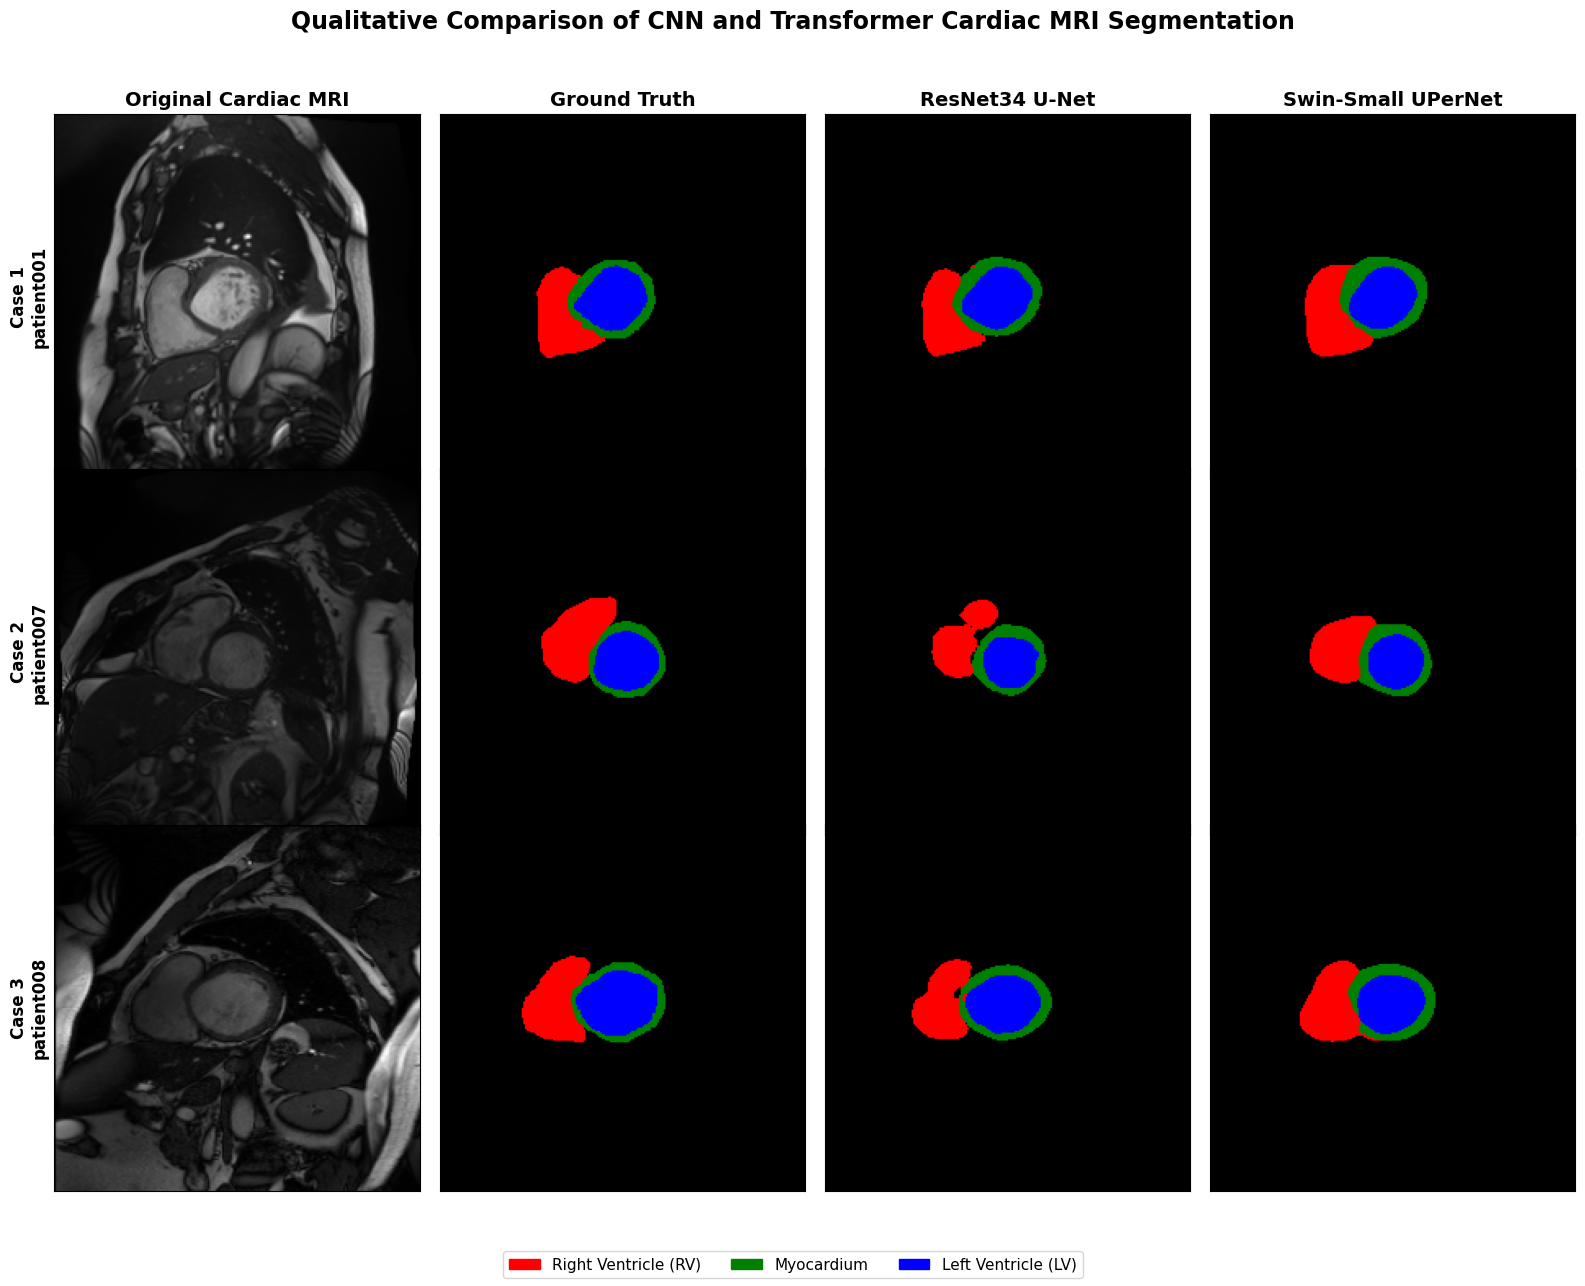

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import numpy as np


# COLOR MAP


seg_cmap = ListedColormap([
    "black",   # Background
    "red",     # RV
    "green",   # Myocardium
    "blue"     # LV
])


# ImageNet normalization values
mean = np.array([
    0.485,
    0.456,
    0.406
])

std = np.array([
    0.229,
    0.224,
    0.225
])


# FIGURE


fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 13)
)


column_titles = [
    "Original Cardiac MRI",
    "Ground Truth",
    "ResNet34 U-Net",
    "Swin-Small UPerNet"
]


for col in range(4):

    axes[0, col].set_title(
        column_titles[col],
        fontsize=14,
        fontweight="bold"
    )


# EACH TEST IMAGE


for row, result in enumerate(
    visualization_results
):

    image = result["image"]

    gt = result["ground_truth"]

    resnet_pred = result["resnet"]

    swin_pred = result["swin"]


    # Undo ImageNet normalization


    display_image = (
        image
        .permute(1, 2, 0)
        .numpy()
    )

    display_image = (
        display_image * std
        + mean
    )

    display_image = np.clip(
        display_image,
        0,
        1
    )

    display_image = display_image[:, :, 0]


    # MRI


    axes[row, 0].imshow(
        display_image,
        cmap="gray"
    )


    # Ground truth


    axes[row, 1].imshow(
        gt,
        cmap=seg_cmap,
        vmin=0,
        vmax=3
    )


    # ResNet


    axes[row, 2].imshow(
        resnet_pred,
        cmap=seg_cmap,
        vmin=0,
        vmax=3
    )


    # Swin


    axes[row, 3].imshow(
        swin_pred,
        cmap=seg_cmap,
        vmin=0,
        vmax=3
    )


    # Row label


    patient_id = (
        result["filename"]
        .split("_")[0]
    )

    axes[row, 0].set_ylabel(
        f"Case {row + 1}\n{patient_id}",
        fontsize=12,
        fontweight="bold"
    )


    # Remove axes
    for col in range(4):

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])


# LEGEND


legend_elements = [

    mpatches.Patch(
        color="red",
        label="Right Ventricle (RV)"
    ),

    mpatches.Patch(
        color="green",
        label="Myocardium"
    ),

    mpatches.Patch(
        color="blue",
        label="Left Ventricle (LV)"
    )
]


fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=11
)


# TITLE


fig.suptitle(
    "Qualitative Comparison of CNN and Transformer Cardiac MRI Segmentation",
    fontsize=17,
    fontweight="bold"
)


plt.tight_layout(
    rect=[0, 0.06, 1, 0.95]
)

# SAVE FOR THESIS

plt.savefig(
    "/content/CNN_vs_Transformer_3_Cases.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
plt.savefig(
    "/content/CNN_vs_Transformer_ACDC.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

Install PyToch Geometric

In [ ]:
!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 72.2 MB/s eta 0:00:00


In [ ]:
import torch_geometric

print(
    "PyTorch Geometric version:",
    torch_geometric.__version__
)

PyTorch Geometric version: 2.8.0.post1


In [ ]:
from torch_geometric.nn import GATv2Conv

print("GATv2Conv imported successfully.")

GATv2Conv imported successfully.


Inspect PreTrained ResNet34 Features

In [ ]:
resnet_model.encoder

ResNetEncoder(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=T

In [ ]:
# One batch
images, masks = next(iter(train_loader))

images = images.to(device)

resnet_model.eval()

with torch.no_grad():

    features = resnet_model.encoder(
        images
    )


print("Number of feature levels:", len(features))

for i, feature in enumerate(features):

    print(
        f"Feature {i}:",
        feature.shape
    )

Number of feature levels: 6
Feature 0: torch.Size([8, 3, 224, 224])
Feature 1: torch.Size([8, 64, 112, 112])
Feature 2: torch.Size([8, 64, 56, 56])
Feature 3: torch.Size([8, 128, 28, 28])
Feature 4: torch.Size([8, 256, 14, 14])
Feature 5: torch.Size([8, 512, 7, 7])


Build 14x14 Graph

In [ ]:
import torch


def create_grid_edges(height, width):

    edges = []

    # 8-neighborhood
    directions = [
        (-1, -1),
        (-1,  0),
        (-1,  1),
        ( 0, -1),
        ( 0,  1),
        ( 1, -1),
        ( 1,  0),
        ( 1,  1)
    ]

    for row in range(height):

        for col in range(width):

            source = row * width + col

            for dr, dc in directions:

                nr = row + dr
                nc = col + dc

                if (
                    0 <= nr < height
                    and
                    0 <= nc < width
                ):

                    target = nr * width + nc

                    edges.append(
                        [source, target]
                    )


    edge_index = torch.tensor(
        edges,
        dtype=torch.long
    ).t().contiguous()

    return edge_index


edge_index = create_grid_edges(
    14,
    14
)

print("Edge index shape:", edge_index.shape)
print("Number of nodes:", 14 * 14)
print("Number of directed edges:", edge_index.shape[1])

Edge index shape: torch.Size([2, 1404])
Number of nodes: 196
Number of directed edges: 1404


Build GATv2 Graph Segmentation Head

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GATv2Conv


class GATSegmentationHead(nn.Module):

    def __init__(
        self,
        in_channels=256,
        hidden_channels=128,
        num_classes=4
    ):

        super().__init__()


        # First graph attention layer


        self.gat1 = GATv2Conv(
            in_channels,
            hidden_channels,
            heads=4,
            concat=False,
            dropout=0.1
        )

        # Second graph attention layer


        self.gat2 = GATv2Conv(
            hidden_channels,
            hidden_channels,
            heads=4,
            concat=False,
            dropout=0.1
        )


        # Node classifier

        self.classifier = nn.Linear(
            hidden_channels,
            num_classes
        )


    def forward(
        self,
        x,
        edge_index
    ):

        x = self.gat1(
            x,
            edge_index
        )

        x = F.gelu(x)


        x = self.gat2(
            x,
            edge_index
        )

        x = F.gelu(x)


        x = self.classifier(x)

        return x

Combine Pretrained ResNet34 + GNN

In [ ]:
class ResNetGATSegmentation(nn.Module):

    def __init__(
        self,
        pretrained_encoder,
        edge_index,
        num_classes=4
    ):

        super().__init__()


        # PRETRAINED CNN ENCODER


        self.encoder = pretrained_encoder


        # GRAPH


        self.register_buffer(
            "base_edge_index",
            edge_index
        )


        # GRAPH SEGMENTATION HEAD


        self.gnn = GATSegmentationHead(
            in_channels=256,
            hidden_channels=128,
            num_classes=num_classes
        )


    def forward(self, x):

        batch_size = x.shape[0]


        # PRETRAINED RESNET FEATURES


        features = self.encoder(x)

        # Feature level 4
        feature_map = features[4]

        # [B, 256, 14, 14]

        B, C, H, W = feature_map.shape


        # FEATURE MAP → GRAPH NODES


        nodes = (
            feature_map
            .permute(0, 2, 3, 1)
            .reshape(B * H * W, C)
        )


        # CREATE BATCHED GRAPH EDGES


        num_nodes = H * W

        edge_list = []


        for b in range(B):

            offset = (
                b * num_nodes
            )

            edge_list.append(
                self.base_edge_index
                +
                offset
            )


        batch_edge_index = torch.cat(
            edge_list,
            dim=1
        )

        # GNN


        node_logits = self.gnn(
            nodes,
            batch_edge_index
        )


        # GRAPH → SPATIAL MAP


        logits = (
            node_logits
            .reshape(
                B,
                H,
                W,
                4
            )
            .permute(
                0,
                3,
                1,
                2
            )
        )


        # 14×14 → ORIGINAL IMAGE SIZE


        logits = F.interpolate(
            logits,
            size=x.shape[-2:],
            mode="bilinear",
            align_corners=False
        )


        return logits

Load PreTrained Encoder

In [ ]:
import segmentation_models_pytorch as smp


fresh_pretrained_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4
)


pretrained_encoder = (
    fresh_pretrained_model.encoder
)


print(
    "Fresh ImageNet-pretrained "
    "ResNet34 encoder loaded."
)

Fresh ImageNet-pretrained ResNet34 encoder loaded.


In [ ]:
gnn_model = ResNetGATSegmentation(
    pretrained_encoder=pretrained_encoder,
    edge_index=edge_index,
    num_classes=4
).to(device)


print(
    "GNN segmentation model created."
)

GNN segmentation model created.


Verification

In [ ]:
images, masks = next(
    iter(train_loader)
)

images = images.to(device)
masks = masks.to(device)


gnn_model.eval()


with torch.no_grad():

    gnn_logits = gnn_model(
        images
    )


print(
    "Input:",
    images.shape
)

print(
    "GNN output:",
    gnn_logits.shape
)

print(
    "Target:",
    masks.shape
)

Input: torch.Size([8, 3, 224, 224])
GNN output: torch.Size([8, 4, 224, 224])
Target: torch.Size([8, 224, 224])


In [ ]:
with torch.no_grad():

    initial_gnn_loss = combined_loss(
        gnn_logits,
        masks
    )


print(
    "Initial GNN loss:",
    initial_gnn_loss.item()
)

Initial GNN loss: 1.1394133567810059


In [ ]:
gnn_dice = calculate_dice(
    gnn_logits,
    masks
)


print("\nINITIAL GNN DICE")
print("=" * 35)

print(
    f"RV:         {gnn_dice[0]:.4f}"
)

print(
    f"Myocardium: {gnn_dice[1]:.4f}"
)

print(
    f"LV:         {gnn_dice[2]:.4f}"
)

print(
    f"Mean:       {np.nanmean(gnn_dice):.4f}"
)


INITIAL GNN DICE
RV:         0.0000
Myocardium: 0.0000
LV:         0.0220
Mean:       0.0073


GNN Training

In [ ]:
gnn_optimizer = torch.optim.AdamW(
    [
        {
            "params": gnn_model.encoder.parameters(),
            "lr": 1e-4
        },
        {
            "params": gnn_model.gnn.parameters(),
            "lr": 5e-4
        }
    ],
    weight_decay=1e-4
)


gnn_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    gnn_optimizer,
    mode="max",
    factor=0.5,
    patience=3
)


print("GNN optimizer and scheduler ready.")

GNN optimizer and scheduler ready.


In [ ]:
EPOCHS = 20

GNN_BEST_PATH = "/content/best_resnet34_gatv2_acdc.pth"

best_gnn_dice = -1.0

gnn_history = {
    "train_loss": [],
    "val_loss": [],
    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],
    "mean_dice": []
}


use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)


for epoch in range(EPOCHS):


    # TRAINING


    gnn_model.train()

    train_loss_total = 0.0


    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        gnn_optimizer.zero_grad(
            set_to_none=True
        )


        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            logits = gnn_model(
                images
            )

            loss = combined_loss(
                logits,
                masks
            )


        scaler.scale(
            loss
        ).backward()


        scaler.unscale_(
            gnn_optimizer
        )


        torch.nn.utils.clip_grad_norm_(
            gnn_model.parameters(),
            max_norm=1.0
        )


        scaler.step(
            gnn_optimizer
        )

        scaler.update()


        train_loss_total += (
            loss.item()
            * images.size(0)
        )


    train_loss = (
        train_loss_total
        /
        len(train_loader.dataset)
    )


    # VALIDATION


    gnn_model.eval()

    val_loss_total = 0.0

    intersections = np.zeros(
        3,
        dtype=np.float64
    )

    denominators = np.zeros(
        3,
        dtype=np.float64
    )


    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            with torch.amp.autocast(
                device_type="cuda",
                enabled=use_amp
            ):

                logits = gnn_model(
                    images
                )

                loss = combined_loss(
                    logits,
                    masks
                )


            val_loss_total += (
                loss.item()
                * images.size(0)
            )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            # Dataset-level Dice
            # Classes 1,2,3 only


            for index, cls in enumerate(
                [1, 2, 3]
            ):

                pred_cls = (
                    predictions == cls
                )

                target_cls = (
                    masks == cls
                )


                intersections[index] += (
                    pred_cls
                    &
                    target_cls
                ).sum().item()


                denominators[index] += (
                    pred_cls.sum().item()
                    +
                    target_cls.sum().item()
                )


    val_loss = (
        val_loss_total
        /
        len(val_loader.dataset)
    )


    dice_scores = (
        (2.0 * intersections + 1e-6)
        /
        (denominators + 1e-6)
    )


    rv_dice = dice_scores[0]
    myo_dice = dice_scores[1]
    lv_dice = dice_scores[2]

    mean_dice = np.mean(
        dice_scores
    )


    # SCHEDULER


    gnn_scheduler.step(
        mean_dice
    )


    # SAVE HISTORY


    gnn_history["train_loss"].append(
        train_loss
    )

    gnn_history["val_loss"].append(
        val_loss
    )

    gnn_history["rv_dice"].append(
        rv_dice
    )

    gnn_history["myo_dice"].append(
        myo_dice
    )

    gnn_history["lv_dice"].append(
        lv_dice
    )

    gnn_history["mean_dice"].append(
        mean_dice
    )

    # BEST MODEL


    improved = (
        mean_dice > best_gnn_dice
    )


    if improved:

        best_gnn_dice = mean_dice


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    gnn_model.state_dict(),

                "optimizer_state_dict":
                    gnn_optimizer.state_dict(),

                "best_val_dice":
                    float(best_gnn_dice),

                "history":
                    gnn_history
            },

            GNN_BEST_PATH
        )


    # CURRENT LEARNING RATES


    encoder_lr = (
        gnn_optimizer
        .param_groups[0]["lr"]
    )

    gnn_lr = (
        gnn_optimizer
        .param_groups[1]["lr"]
    )


    marker = (
        "  ← BEST"
        if improved
        else ""
    )


    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"RV: {rv_dice:.4f} | "
        f"Myo: {myo_dice:.4f} | "
        f"LV: {lv_dice:.4f} | "
        f"Mean Dice: {mean_dice:.4f} | "
        f"Encoder LR: {encoder_lr:.1e} | "
        f"GNN LR: {gnn_lr:.1e}"
        f"{marker}"
    )


print("\nGNN training complete.")

print(
    "Best GNN Validation Mean Dice:",
    f"{best_gnn_dice:.4f}"
)

print(
    "Best checkpoint:",
    GNN_BEST_PATH
)

Epoch 01/20 | Train Loss: 1.0161 | Val Loss: 0.7131 | RV: 0.0000 | Myo: 0.0000 | LV: 0.0000 | Mean Dice: 0.0000 | Encoder LR: 1.0e-04 | GNN LR: 5.0e-04  ← BEST
Epoch 02/20 | Train Loss: 0.4862 | Val Loss: 0.4504 | RV: 0.0000 | Myo: 0.0000 | LV: 0.0000 | Mean Dice: 0.0000 | Encoder LR: 1.0e-04 | GNN LR: 5.0e-04
Epoch 03/20 | Train Loss: 0.3927 | Val Loss: 0.4005 | RV: 0.0000 | Myo: 0.0000 | LV: 0.0000 | Mean Dice: 0.0000 | Encoder LR: 1.0e-04 | GNN LR: 5.0e-04
Epoch 04/20 | Train Loss: 0.3628 | Val Loss: 0.3782 | RV: 0.0000 | Myo: 0.0000 | LV: 0.0000 | Mean Dice: 0.0000 | Encoder LR: 1.0e-04 | GNN LR: 5.0e-04
Epoch 05/20 | Train Loss: 0.3491 | Val Loss: 0.3795 | RV: 0.0000 | Myo: 0.0000 | LV: 0.0000 | Mean Dice: 0.0000 | Encoder LR: 5.0e-05 | GNN LR: 2.5e-04
Epoch 06/20 | Train Loss: 0.3424 | Val Loss: 0.3725 | RV: 0.0000 | Myo: 0.0000 | LV: 0.0000 | Mean Dice: 0.0000 | Encoder LR: 5.0e-05 | GNN LR: 2.5e-04
Epoch 07/20 | Train Loss: 0.3363 | Val Loss: 0.3677 | RV: 0.0000 | Myo: 0.0000 |

In [ ]:
# Load best GNN checkpoint

gnn_checkpoint = torch.load(
    "/content/best_resnet34_gatv2_acdc.pth",
    map_location=device,
    weights_only=False
)

gnn_model.load_state_dict(
    gnn_checkpoint["model_state_dict"]
)

gnn_model.eval()

print("Best epoch:", gnn_checkpoint["epoch"])
print(
    "Best validation Dice:",
    gnn_checkpoint["best_val_dice"]
)

Best epoch: 20
Best validation Dice: 0.29027402303262223


In [ ]:
idx = selected_indices[0]

image, gt_mask = test_dataset[idx]

input_image = (
    image
    .unsqueeze(0)
    .to(device)
)


with torch.no_grad():

    logits = gnn_model(
        input_image
    )

    prediction = torch.argmax(
        logits,
        dim=1
    )[0].cpu().numpy()


gt = gt_mask.cpu().numpy()


print(
    "Ground truth labels:",
    np.unique(gt)
)

print(
    "GNN predicted labels:",
    np.unique(prediction)
)

Ground truth labels: [0 1 2 3]
GNN predicted labels: [0 2 3]


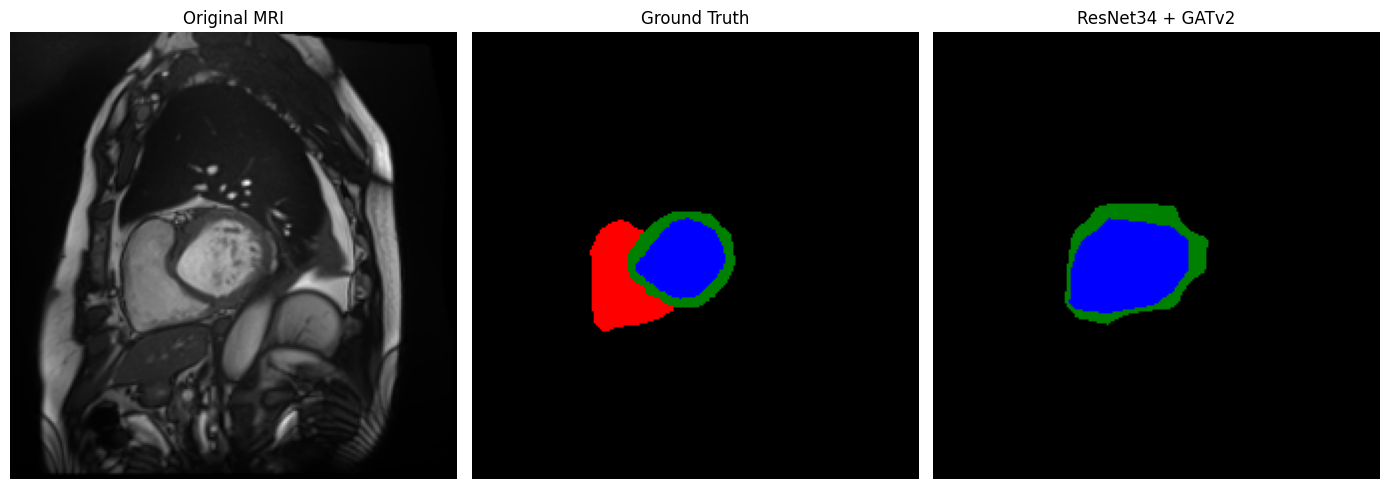

In [ ]:
# Undo normalization

display_image = (
    image
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)

display_image = (
    display_image * std
    + mean
)

display_image = np.clip(
    display_image,
    0,
    1
)

display_image = display_image[:, :, 0]


fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 5)
)


axes[0].imshow(
    display_image,
    cmap="gray"
)

axes[0].set_title(
    "Original MRI"
)


axes[1].imshow(
    gt,
    cmap=seg_cmap,
    vmin=0,
    vmax=3
)

axes[1].set_title(
    "Ground Truth"
)


axes[2].imshow(
    prediction,
    cmap=seg_cmap,
    vmin=0,
    vmax=3
)

axes[2].set_title(
    "ResNet34 + GATv2"
)


for ax in axes:
    ax.axis("off")


plt.tight_layout()

plt.show()

Creat 28x28 Graph

In [ ]:
edge_index_28 = create_grid_edges(
    28,
    28
)

print(
    "Number of nodes:",
    28 * 28
)

print(
    "Edge index:",
    edge_index_28.shape
)

print(
    "Number of directed edges:",
    edge_index_28.shape[1]
)

Number of nodes: 784
Edge index: torch.Size([2, 5940])
Number of directed edges: 5940


In [ ]:
class ImprovedGATBlock(nn.Module):

    def __init__(
        self,
        in_channels=128,
        hidden_channels=128
    ):

        super().__init__()

        self.gat1 = GATv2Conv(
            in_channels,
            hidden_channels,
            heads=4,
            concat=False,
            dropout=0.1
        )

        self.gat2 = GATv2Conv(
            hidden_channels,
            hidden_channels,
            heads=4,
            concat=False,
            dropout=0.1
        )

        self.norm1 = nn.LayerNorm(
            hidden_channels
        )

        self.norm2 = nn.LayerNorm(
            hidden_channels
        )


    def forward(
        self,
        x,
        edge_index
    ):

        # First graph layer
        residual = x

        x = self.gat1(
            x,
            edge_index
        )

        x = F.gelu(x)

        x = self.norm1(
            x + residual
        )


        # Second graph layer
        residual = x

        x = self.gat2(
            x,
            edge_index
        )

        x = F.gelu(x)

        x = self.norm2(
            x + residual
        )

        return x

Decoder

In [ ]:
class GNNDecoder(nn.Module):

    def __init__(
        self,
        num_classes=4
    ):

        super().__init__()


        # 28 → 56
        self.decoder1 = nn.Sequential(

            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(inplace=True)
        )


        # 56 → 112
        self.decoder2 = nn.Sequential(

            nn.Conv2d(
                128,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True)
        )


        # 112 → 224
        self.decoder3 = nn.Sequential(

            nn.Conv2d(
                64,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(inplace=True)
        )


        self.classifier = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )


    def forward(self, x):

        # 28 → 56
        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        x = self.decoder1(x)


        # 56 → 112
        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        x = self.decoder2(x)


        # 112 → 224
        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        x = self.decoder3(x)


        return self.classifier(x)

GNN Model

In [ ]:
class ImprovedResNetGATSegmentation(nn.Module):

    def __init__(
        self,
        pretrained_encoder,
        edge_index,
        num_classes=4
    ):

        super().__init__()

        self.encoder = pretrained_encoder

        self.register_buffer(
            "base_edge_index",
            edge_index
        )

        self.gnn = ImprovedGATBlock(
            in_channels=128,
            hidden_channels=128
        )

        self.decoder = GNNDecoder(
            num_classes=num_classes
        )


    def forward(self, x):

        B = x.shape[0]


        # PRETRAINED RESNET


        features = self.encoder(x)

        # Feature 3:
        # [B,128,28,28]

        feature_map = features[3]

        B, C, H, W = feature_map.shape


        # FEATURE MAP → GRAPH


        nodes = (
            feature_map
            .permute(0, 2, 3, 1)
            .reshape(
                B * H * W,
                C
            )
        )



        # BATCH GRAPH EDGES


        num_nodes = H * W

        batch_edges = []

        for b in range(B):

            batch_edges.append(
                self.base_edge_index
                +
                b * num_nodes
            )


        batch_edge_index = torch.cat(
            batch_edges,
            dim=1
        )


        # GRAPH REASONING


        graph_features = self.gnn(
            nodes,
            batch_edge_index
        )


        # GRAPH → FEATURE MAP


        graph_map = (
            graph_features
            .reshape(
                B,
                H,
                W,
                128
            )
            .permute(
                0,
                3,
                1,
                2
            )
        )


        # DECODER


        logits = self.decoder(
            graph_map
        )


        return logits

Pretrained Encoder

In [ ]:
fresh_model_3b = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4
)

fresh_encoder_3b = (
    fresh_model_3b.encoder
)


improved_gnn_model = (
    ImprovedResNetGATSegmentation(
        pretrained_encoder=fresh_encoder_3b,
        edge_index=edge_index_28,
        num_classes=4
    )
    .to(device)
)


print(
    "Improved GNN model created."
)

Improved GNN model created.


In [ ]:
images, masks = next(
    iter(train_loader)
)

images = images.to(device)
masks = masks.to(device)


improved_gnn_model.eval()


with torch.no_grad():

    improved_logits = (
        improved_gnn_model(images)
    )


print(
    "Input:",
    images.shape
)

print(
    "Output:",
    improved_logits.shape
)

print(
    "Target:",
    masks.shape
)


initial_loss = combined_loss(
    improved_logits,
    masks
)


initial_dice = calculate_dice(
    improved_logits,
    masks
)


print(
    "\nInitial loss:",
    initial_loss.item()
)

print(
    "Initial RV:",
    initial_dice[0]
)

print(
    "Initial Myocardium:",
    initial_dice[1]
)

print(
    "Initial LV:",
    initial_dice[2]
)

print(
    "Initial Mean:",
    np.nanmean(initial_dice)
)

Input: torch.Size([8, 3, 224, 224])
Output: torch.Size([8, 4, 224, 224])
Target: torch.Size([8, 224, 224])

Initial loss: 1.1817924976348877
Initial RV: 0.025402607396245003
Initial Myocardium: 1.9193857614396848e-10
Initial LV: 0.01831643283367157
Initial Mean: 0.014573013473951716


Calculate Class Frequencies from the Training Masks

In [ ]:
# COUNT PIXELS PER CLASS — TRAINING SET ONLY


class_pixel_counts = np.zeros(
    4,
    dtype=np.int64
)

for _, mask in train_dataset:

    mask_np = mask.cpu().numpy()

    counts = np.bincount(
        mask_np.flatten(),
        minlength=4
    )

    class_pixel_counts += counts


total_pixels = class_pixel_counts.sum()

class_frequencies = (
    class_pixel_counts
    /
    total_pixels
)


class_names = [
    "Background",
    "RV",
    "Myocardium",
    "LV"
]


print("TRAINING-SET CLASS DISTRIBUTION")
print("=" * 50)

for i in range(4):

    print(
        f"{class_names[i]:12s}: "
        f"{class_pixel_counts[i]:10,d} pixels | "
        f"{class_frequencies[i] * 100:.2f}%"
    )

TRAINING-SET CLASS DISTRIBUTION
Background  :  6,566,375 pixels | 96.23%
RV          :     75,756 pixels | 1.11%
Myocardium  :     92,472 pixels | 1.36%
LV          :     89,333 pixels | 1.31%


In [ ]:
# INVERSE SQRT FREQUENCY WEIGHTS


class_weights = (
    1.0
    /
    np.sqrt(
        class_frequencies + 1e-8
    )
)

class_weights = (
    class_weights
    /
    class_weights.mean()
)


class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)


print("\nCLASS WEIGHTS")
print("=" * 40)

for i in range(4):

    print(
        f"{class_names[i]:12s}: "
        f"{class_weights[i].item():.4f}"
    )


CLASS WEIGHTS
Background  : 0.1465
RV          : 1.3636
Myocardium  : 1.2342
LV          : 1.2557


Weighted CE + Dice loss

In [ ]:
weighted_ce_loss = nn.CrossEntropyLoss(
    weight=class_weights
)


gnn_dice_loss = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True
)


def improved_gnn_loss(
    outputs,
    targets
):

    ce = weighted_ce_loss(
        outputs,
        targets
    )

    dice = gnn_dice_loss(
        outputs,
        targets
    )

    return (
        0.5 * ce
        +
        0.5 * dice
    )

In [ ]:
with torch.no_grad():

    test_weighted_loss = improved_gnn_loss(
        improved_logits,
        masks
    )


print(
    "Initial weighted GNN loss:",
    test_weighted_loss.item()
)

Initial weighted GNN loss: 1.170594334602356


Optimizer

In [ ]:
improved_gnn_optimizer = torch.optim.AdamW(

    [
        {
            "params":
                improved_gnn_model
                .encoder
                .parameters(),

            "lr": 1e-4
        },

        {
            "params":
                improved_gnn_model
                .gnn
                .parameters(),

            "lr": 5e-4
        },

        {
            "params":
                improved_gnn_model
                .decoder
                .parameters(),

            "lr": 5e-4
        }
    ],

    weight_decay=1e-4
)


improved_gnn_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        improved_gnn_optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )
)

In [ ]:
EPOCHS = 20

IMPROVED_GNN_PATH = (
    "/content/best_improved_resnet34_gatv2_acdc.pth"
)

best_improved_gnn_dice = -1.0


improved_gnn_history = {

    "train_loss": [],
    "val_loss": [],

    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],

    "mean_dice": []
}


use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)


for epoch in range(EPOCHS):

    # TRAIN


    improved_gnn_model.train()

    train_loss_total = 0.0


    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        improved_gnn_optimizer.zero_grad(
            set_to_none=True
        )


        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            logits = improved_gnn_model(
                images
            )

            loss = improved_gnn_loss(
                logits,
                masks
            )


        scaler.scale(
            loss
        ).backward()


        scaler.unscale_(
            improved_gnn_optimizer
        )


        torch.nn.utils.clip_grad_norm_(
            improved_gnn_model.parameters(),
            max_norm=1.0
        )


        scaler.step(
            improved_gnn_optimizer
        )

        scaler.update()


        train_loss_total += (
            loss.item()
            *
            images.size(0)
        )


    train_loss = (
        train_loss_total
        /
        len(train_loader.dataset)
    )


    # VALIDATION


    improved_gnn_model.eval()

    val_loss_total = 0.0

    intersections = np.zeros(
        3,
        dtype=np.float64
    )

    denominators = np.zeros(
        3,
        dtype=np.float64
    )


    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            with torch.amp.autocast(
                device_type="cuda",
                enabled=use_amp
            ):

                logits = improved_gnn_model(
                    images
                )

                loss = improved_gnn_loss(
                    logits,
                    masks
                )


            val_loss_total += (
                loss.item()
                *
                images.size(0)
            )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            for index, cls in enumerate(
                [1, 2, 3]
            ):

                pred_cls = (
                    predictions == cls
                )

                target_cls = (
                    masks == cls
                )


                intersections[index] += (
                    pred_cls
                    &
                    target_cls
                ).sum().item()


                denominators[index] += (
                    pred_cls.sum().item()
                    +
                    target_cls.sum().item()
                )


    val_loss = (
        val_loss_total
        /
        len(val_loader.dataset)
    )


    dice_scores = (
        (2.0 * intersections + 1e-6)
        /
        (denominators + 1e-6)
    )


    rv_dice = dice_scores[0]
    myo_dice = dice_scores[1]
    lv_dice = dice_scores[2]

    mean_dice = np.mean(
        dice_scores
    )


    # SCHEDULER


    improved_gnn_scheduler.step(
        mean_dice
    )


    # HISTORY


    improved_gnn_history[
        "train_loss"
    ].append(train_loss)

    improved_gnn_history[
        "val_loss"
    ].append(val_loss)

    improved_gnn_history[
        "rv_dice"
    ].append(rv_dice)

    improved_gnn_history[
        "myo_dice"
    ].append(myo_dice)

    improved_gnn_history[
        "lv_dice"
    ].append(lv_dice)

    improved_gnn_history[
        "mean_dice"
    ].append(mean_dice)


    # CHECKPOINT


    improved = (
        mean_dice
        >
        best_improved_gnn_dice
    )


    if improved:

        best_improved_gnn_dice = (
            mean_dice
        )


        torch.save(

            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    improved_gnn_model
                    .state_dict(),

                "optimizer_state_dict":
                    improved_gnn_optimizer
                    .state_dict(),

                "best_val_dice":
                    float(
                        best_improved_gnn_dice
                    ),

                "history":
                    improved_gnn_history,

                "class_weights":
                    class_weights
                    .detach()
                    .cpu()
            },

            IMPROVED_GNN_PATH
        )


    encoder_lr = (
        improved_gnn_optimizer
        .param_groups[0]["lr"]
    )

    graph_lr = (
        improved_gnn_optimizer
        .param_groups[1]["lr"]
    )


    marker = (
        "  ← BEST"
        if improved
        else ""
    )


    print(

        f"Epoch {epoch+1:02d}/{EPOCHS} | "

        f"Train Loss: "
        f"{train_loss:.4f} | "

        f"Val Loss: "
        f"{val_loss:.4f} | "

        f"RV: "
        f"{rv_dice:.4f} | "

        f"Myo: "
        f"{myo_dice:.4f} | "

        f"LV: "
        f"{lv_dice:.4f} | "

        f"Mean Dice: "
        f"{mean_dice:.4f} | "

        f"Enc LR: "
        f"{encoder_lr:.1e} | "

        f"Graph LR: "
        f"{graph_lr:.1e}"

        f"{marker}"
    )


print(
    "\nImproved GNN training complete."
)

print(
    "Best validation Mean Dice:",
    f"{best_improved_gnn_dice:.4f}"
)

print(
    "Checkpoint:",
    IMPROVED_GNN_PATH
)

Epoch 01/20 | Train Loss: 0.9385 | Val Loss: 0.9350 | RV: 0.2575 | Myo: 0.3859 | LV: 0.6229 | Mean Dice: 0.4221 | Enc LR: 1.0e-04 | Graph LR: 5.0e-04  ← BEST
Epoch 02/20 | Train Loss: 0.7632 | Val Loss: 0.7577 | RV: 0.4298 | Myo: 0.5917 | LV: 0.7545 | Mean Dice: 0.5920 | Enc LR: 1.0e-04 | Graph LR: 5.0e-04  ← BEST
Epoch 03/20 | Train Loss: 0.6789 | Val Loss: 0.6720 | RV: 0.4879 | Myo: 0.5608 | LV: 0.7847 | Mean Dice: 0.6111 | Enc LR: 1.0e-04 | Graph LR: 5.0e-04  ← BEST
Epoch 04/20 | Train Loss: 0.6111 | Val Loss: 0.6248 | RV: 0.5707 | Myo: 0.6676 | LV: 0.8093 | Mean Dice: 0.6826 | Enc LR: 1.0e-04 | Graph LR: 5.0e-04  ← BEST
Epoch 05/20 | Train Loss: 0.5518 | Val Loss: 0.5774 | RV: 0.5899 | Myo: 0.6764 | LV: 0.8250 | Mean Dice: 0.6971 | Enc LR: 1.0e-04 | Graph LR: 5.0e-04  ← BEST
Epoch 06/20 | Train Loss: 0.5074 | Val Loss: 0.5318 | RV: 0.6283 | Myo: 0.6703 | LV: 0.8142 | Mean Dice: 0.7043 | Enc LR: 1.0e-04 | Graph LR: 5.0e-04  ← BEST
Epoch 07/20 | Train Loss: 0.4584 | Val Loss: 0.4886 

3C GNN

Create GraphSAGE Bottleneck

In [ ]:
from torch_geometric.nn import SAGEConv

In [ ]:
class GraphSAGEBottleneck(nn.Module):

    def __init__(
        self,
        feature_dim=512,
        hidden_dim=512,
        num_layers=4
    ):
        super().__init__()

        self.num_layers = num_layers

        self.gnn_layers = nn.ModuleList()
        self.norm_layers = nn.ModuleList()

        for _ in range(num_layers):

            self.gnn_layers.append(
                SAGEConv(
                    feature_dim,
                    hidden_dim
                )
            )

            self.norm_layers.append(
                nn.LayerNorm(
                    hidden_dim
                )
            )


    def forward(
        self,
        x,
        edge_index
    ):

        # x:
        # [batch, nodes, features]

        batch_size = x.size(0)

        output_list = []

        for batch_index in range(
            batch_size
        ):

            node_features = x[
                batch_index
            ]

            for layer_index in range(
                self.num_layers
            ):

                residual = node_features

                node_features = (
                    self.gnn_layers[
                        layer_index
                    ](
                        node_features,
                        edge_index
                    )
                )

                node_features = (
                    self.norm_layers[
                        layer_index
                    ](
                        node_features
                    )
                )

                node_features = F.gelu(
                    node_features
                )

                node_features = (
                    node_features
                    +
                    residual
                )

            output_list.append(
                node_features
            )

        return torch.stack(
            output_list,
            dim=0
        )


print(
    "GraphSAGE bottleneck ready!"
)

GraphSAGE bottleneck ready!


Create CNN Refinement Block

In [ ]:
class GraphConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(
            out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(
            out_channels
        )

        if in_channels != out_channels:

            self.residual = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False
            )

        else:

            self.residual = nn.Identity()


    def forward(self, x):

        residual = self.residual(x)

        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x, inplace=True)

        x = self.conv2(x)
        x = self.bn2(x)

        x = x + residual

        return F.relu(
            x,
            inplace=True
        )

In [ ]:
class GraphDecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):
        super().__init__()

        self.conv = GraphConvBlock(
            in_channels + skip_channels,
            out_channels
        )


    def forward(
        self,
        x,
        skip
    ):

        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat(
            [x, skip],
            dim=1
        )

        return self.conv(x)

Build GraphSAGE U-Net

In [ ]:
from torchvision import models


class ResNet34GraphSAGEUNet(nn.Module):

    def __init__(
        self,
        num_classes=4,
        pretrained=True
    ):

        super().__init__()

        # PRETRAINED RESNET34

        weights = (
            models.ResNet34_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )

        resnet = models.resnet34(
            weights=weights
        )


        # 224 -> 112
        self.stem = nn.Sequential(
            resnet.conv1,
            resnet.bn1,
            resnet.relu
        )

        # 112 -> 56
        self.pool = resnet.maxpool


        # 56 x 56
        self.layer1 = resnet.layer1

        # 28 x 28
        self.layer2 = resnet.layer2

        # 14 x 14
        self.layer3 = resnet.layer3

        # 7 x 7
        self.layer4 = resnet.layer4


        # BOTTLENECK

        self.bottleneck = GraphConvBlock(
            512,
            512
        )


        # GRAPHSAGE

        self.graph_reasoning = (
            GraphSAGEBottleneck(
                feature_dim=512,
                hidden_dim=512,
                num_layers=4
            )
        )


        # 224 input -> 7x7 bottleneck
        edge_index = create_grid_edges(
            height=7,
            width=7
        )

        self.register_buffer(
            "bottleneck_edge_index",
            edge_index
        )



        # POST-GRAPH REFINEMENT


        self.graph_refine = (
            GraphConvBlock(
                512,
                512
            )
        )


        # U-NET DECODER

        # 7 -> 14
        self.decoder4 = GraphDecoderBlock(
            in_channels=512,
            skip_channels=256,
            out_channels=256
        )

        # 14 -> 28
        self.decoder3 = GraphDecoderBlock(
            in_channels=256,
            skip_channels=128,
            out_channels=128
        )

        # 28 -> 56
        self.decoder2 = GraphDecoderBlock(
            in_channels=128,
            skip_channels=64,
            out_channels=64
        )

        # 56 -> 112
        self.decoder1 = GraphDecoderBlock(
            in_channels=64,
            skip_channels=64,
            out_channels=64
        )


        self.final_refine = (
            GraphConvBlock(
                64,
                32
            )
        )


        self.output_layer = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )


    def forward(self, x):

        input_size = x.shape[2:]


        # RESNET ENCODER


        s = self.stem(x)
        # [B,64,112,112]

        p = self.pool(s)
        # [B,64,56,56]

        e1 = self.layer1(p)
        # [B,64,56,56]

        e2 = self.layer2(e1)
        # [B,128,28,28]

        e3 = self.layer3(e2)
        # [B,256,14,14]

        e4 = self.layer4(e3)
        # [B,512,7,7]


        # CNN BOTTLENECK


        b = self.bottleneck(e4)


        batch_size, channels, height, width = (
            b.shape
        )


        # IMAGE -> GRAPH


        graph_input = (
            b
            .flatten(2)
            .transpose(1, 2)
        )

        # [B,49,512]


        graph_output = (
            self.graph_reasoning(
                graph_input,
                self.bottleneck_edge_index
            )
        )


        # GRAPH -> IMAGE

        b = (
            graph_output
            .transpose(1, 2)
            .reshape(
                batch_size,
                channels,
                height,
                width
            )
        )


        b = self.graph_refine(b)


        # U-NET DECODER + SKIPS

        d4 = self.decoder4(
            b,
            e3
        )

        d3 = self.decoder3(
            d4,
            e2
        )

        d2 = self.decoder2(
            d3,
            e1
        )

        d1 = self.decoder1(
            d2,
            s
        )


        # 112 -> 224
        d1 = F.interpolate(
            d1,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )


        d1 = self.final_refine(
            d1
        )


        logits = self.output_layer(
            d1
        )


        return logits

Create Experiment 3C

In [ ]:
graphsage_model = (
    ResNet34GraphSAGEUNet(
        num_classes=4,
        pretrained=True
    )
    .to(device)
)


total_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
)


trainable_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
    if p.requires_grad
)


print(
    "Experiment 3C created!"
)

print(
    "Total parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

print(
    "Graph nodes:",
    7 * 7
)

print(
    "Graph edges:",
    graphsage_model
    .bottleneck_edge_index
    .shape
)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 110MB/s]


Experiment 3C created!
Total parameters: 36,334,660
Trainable parameters: 36,334,660
Graph nodes: 49
Graph edges: torch.Size([2, 312])


In [ ]:
images, masks = next(
    iter(train_loader)
)

images = images.to(device)
masks = masks.to(device)


graphsage_model.eval()


with torch.no_grad():

    graphsage_logits = (
        graphsage_model(
            images
        )
    )


print(
    "Input:",
    images.shape
)

print(
    "Output:",
    graphsage_logits.shape
)

print(
    "Target:",
    masks.shape
)

print(
    "Prediction labels:",
    torch.unique(
        torch.argmax(
            graphsage_logits,
            dim=1
        )
    )
)

Input: torch.Size([8, 3, 224, 224])
Output: torch.Size([8, 4, 224, 224])
Target: torch.Size([8, 224, 224])
Prediction labels: tensor([0], device='cuda:0')


Loss Function

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class MulticlassDiceLoss(nn.Module):
    def __init__(self, num_classes=4, smooth=1e-6):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(self, logits, targets):

        # Convert logits to probabilities
        probs = torch.softmax(logits, dim=1)

        # Convert target mask to one-hot format
        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        )

        targets_one_hot = targets_one_hot.permute(
            0, 3, 1, 2
        ).float()


        # Exclude background class 0
        probs = probs[:, 1:, :, :]
        targets_one_hot = targets_one_hot[:, 1:, :, :]


        # Dice across batch + spatial dimensions
        dims = (0, 2, 3)

        intersection = torch.sum(
            probs * targets_one_hot,
            dim=dims
        )

        denominator = (
            torch.sum(probs, dim=dims)
            +
            torch.sum(targets_one_hot, dim=dims)
        )


        dice = (
            (2.0 * intersection + self.smooth)
            /
            (denominator + self.smooth)
        )


        return 1.0 - dice.mean()


class ACDCLoss(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.ce = nn.CrossEntropyLoss()

        self.dice = MulticlassDiceLoss(
            num_classes=num_classes
        )


    def forward(self, logits, targets):

        ce_loss = self.ce(
            logits,
            targets
        )

        dice_loss = self.dice(
            logits,
            targets
        )

        return ce_loss + dice_loss


print("ACDCLoss restored!")

ACDCLoss restored!


In [ ]:
graphsage_loss_fn = ACDCLoss(
    num_classes=4
).to(device)

print("GraphSAGE loss ready!")

GraphSAGE loss ready!


In [ ]:
# PRETRAINED RESNET PARAMETERS


graphsage_encoder_params = (
    list(graphsage_model.stem.parameters())
    +
    list(graphsage_model.layer1.parameters())
    +
    list(graphsage_model.layer2.parameters())
    +
    list(graphsage_model.layer3.parameters())
    +
    list(graphsage_model.layer4.parameters())
)


# NEW GRAPHSAGE + DECODER PARAMETERS

graphsage_new_params = (
    list(graphsage_model.bottleneck.parameters())
    +
    list(graphsage_model.graph_reasoning.parameters())
    +
    list(graphsage_model.graph_refine.parameters())
    +
    list(graphsage_model.decoder4.parameters())
    +
    list(graphsage_model.decoder3.parameters())
    +
    list(graphsage_model.decoder2.parameters())
    +
    list(graphsage_model.decoder1.parameters())
    +
    list(graphsage_model.final_refine.parameters())
    +
    list(graphsage_model.output_layer.parameters())
)

Optimizer

In [ ]:
graphsage_optimizer = torch.optim.AdamW(
    [
        {
            "params": graphsage_encoder_params,
            "lr": 2e-5
        },

        {
            "params": graphsage_new_params,
            "lr": 1e-4
        }
    ],

    weight_decay=1e-4
)


print(
    "Encoder LR:",
    graphsage_optimizer.param_groups[0]["lr"]
)

print(
    "New layers LR:",
    graphsage_optimizer.param_groups[1]["lr"]
)

Encoder LR: 2e-05
New layers LR: 0.0001


In [ ]:
graphsage_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    graphsage_optimizer,
    mode="max",
    factor=0.5,
    patience=8,
    min_lr=1e-6
)

print("GraphSAGE scheduler ready!")

print(
    "Encoder LR:",
    graphsage_optimizer.param_groups[0]["lr"]
)

print(
    "New layers LR:",
    graphsage_optimizer.param_groups[1]["lr"]
)

GraphSAGE scheduler ready!
Encoder LR: 2e-05
New layers LR: 0.0001


In [ ]:
graphsage_model.eval()

with torch.no_grad():

    graphsage_logits = graphsage_model(
        images
    )

    initial_graphsage_loss = (
        graphsage_loss_fn(
            graphsage_logits,
            masks
        )
    )

    initial_graphsage_dice = (
        calculate_dice(
            graphsage_logits,
            masks
        )
    )


print(
    "Initial Loss:",
    initial_graphsage_loss.item()
)

print(
    "Initial RV Dice:",
    initial_graphsage_dice[0]
)

print(
    "Initial Myocardium Dice:",
    initial_graphsage_dice[1]
)

print(
    "Initial LV Dice:",
    initial_graphsage_dice[2]
)

print(
    "Initial Mean Dice:",
    np.nanmean(
        initial_graphsage_dice
    )
)

Initial Loss: 2.2516188621520996
Initial RV Dice: 2.3078698674350306e-10
Initial Myocardium Dice: 2.564102541402491e-10
Initial LV Dice: 2.6745120007554135e-10
Initial Mean Dice: 2.515494803197645e-10


In [ ]:
NUM_EPOCHS = 150

EARLY_STOP_PATIENCE = 15

best_graphsage_dice = -1.0

epochs_without_improvement = 0

GRAPHSAGE_PATH = (
    "/content/best_graphsage_unet_acdc.pth"
)


graphsage_history = {

    "train_loss": [],
    "val_loss": [],

    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],

    "mean_dice": []
}


print("=" * 65)

print(
    "EXPERIMENT 3C — "
    "RESNET34 + GRAPHSAGE U-NET"
)

print("=" * 65)

print(
    "Training images:",
    len(train_loader.dataset)
)

print(
    "Validation images:",
    len(val_loader.dataset)
)

print()


for epoch in range(NUM_EPOCHS):

    # TRAIN


    graphsage_model.train()

    total_train_loss = 0.0


    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        graphsage_optimizer.zero_grad(
            set_to_none=True
        )


        outputs = graphsage_model(
            images
        )


        loss = graphsage_loss_fn(
            outputs,
            masks
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            graphsage_model.parameters(),
            max_norm=1.0
        )


        graphsage_optimizer.step()


        total_train_loss += (
            loss.item()
            *
            images.size(0)
        )


    train_loss = (
        total_train_loss
        /
        len(train_loader.dataset)
    )


    # VALIDATION


    graphsage_model.eval()

    val_loss_total = 0.0

    intersections = np.zeros(
        3,
        dtype=np.float64
    )

    denominators = np.zeros(
        3,
        dtype=np.float64
    )


    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            outputs = graphsage_model(
                images
            )


            val_loss = graphsage_loss_fn(
                outputs,
                masks
            )


            val_loss_total += (
                val_loss.item()
                *
                images.size(0)
            )


            predictions = torch.argmax(
                outputs,
                dim=1
            )


            for index, cls in enumerate(
                [1, 2, 3]
            ):

                pred_cls = (
                    predictions == cls
                )

                target_cls = (
                    masks == cls
                )


                intersections[index] += (
                    pred_cls
                    &
                    target_cls
                ).sum().item()


                denominators[index] += (
                    pred_cls.sum().item()
                    +
                    target_cls.sum().item()
                )


    val_loss = (
        val_loss_total
        /
        len(val_loader.dataset)
    )


    dice_scores = (
        (2.0 * intersections + 1e-6)
        /
        (denominators + 1e-6)
    )


    rv_dice = dice_scores[0]
    myo_dice = dice_scores[1]
    lv_dice = dice_scores[2]

    mean_dice = np.mean(
        dice_scores
    )


    # SAVE HISTORY


    graphsage_history[
        "train_loss"
    ].append(train_loss)

    graphsage_history[
        "val_loss"
    ].append(val_loss)

    graphsage_history[
        "rv_dice"
    ].append(rv_dice)

    graphsage_history[
        "myo_dice"
    ].append(myo_dice)

    graphsage_history[
        "lv_dice"
    ].append(lv_dice)

    graphsage_history[
        "mean_dice"
    ].append(mean_dice)



    # CHECK FOR IMPROVEMENT


    improved = (
        mean_dice >
        best_graphsage_dice
    )


    if improved:

        best_graphsage_dice = (
            mean_dice
        )

        epochs_without_improvement = 0


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    graphsage_model
                    .state_dict(),

                "optimizer_state_dict":
                    graphsage_optimizer
                    .state_dict(),

                "best_val_dice":
                    float(
                        best_graphsage_dice
                    ),

                "history":
                    graphsage_history
            },

            GRAPHSAGE_PATH
        )


    else:

        epochs_without_improvement += 1


    # SCHEDULER


    graphsage_scheduler.step(
        mean_dice
    )


    encoder_lr = (
        graphsage_optimizer
        .param_groups[0]["lr"]
    )

    new_layers_lr = (
        graphsage_optimizer
        .param_groups[1]["lr"]
    )


    marker = (
        "  ← BEST"
        if improved
        else ""
    )


    print(

        f"Epoch {epoch+1:03d}/{NUM_EPOCHS} | "

        f"Train: "
        f"{train_loss:.4f} | "

        f"Val: "
        f"{val_loss:.4f} | "

        f"RV: "
        f"{rv_dice:.4f} | "

        f"Myo: "
        f"{myo_dice:.4f} | "

        f"LV: "
        f"{lv_dice:.4f} | "

        f"Mean: "
        f"{mean_dice:.4f} | "

        f"Enc LR: "
        f"{encoder_lr:.1e} | "

        f"New LR: "
        f"{new_layers_lr:.1e}"

        f"{marker}"
    )


    # EARLY STOPPING

    if (
        epochs_without_improvement
        >= EARLY_STOP_PATIENCE
    ):

        print()
        print(
            "Early stopping triggered."
        )

        print(
            "No validation improvement "
            f"for {EARLY_STOP_PATIENCE} epochs."
        )

        break


print()
print("=" * 65)

print(
    "EXPERIMENT 3C COMPLETE"
)

print(
    "Best Validation Mean Dice:",
    f"{best_graphsage_dice:.4f}"
)

print(
    "Best checkpoint:",
    GRAPHSAGE_PATH
)

print("=" * 65)

EXPERIMENT 3C — RESNET34 + GRAPHSAGE U-NET
Training images: 136
Validation images: 210

Epoch 001/150 | Train: 2.2016 | Val: 2.0588 | RV: 0.0000 | Myo: 0.0000 | LV: 0.3134 | Mean: 0.1045 | Enc LR: 2.0e-05 | New LR: 1.0e-04  ← BEST
Epoch 002/150 | Train: 1.7335 | Val: 1.6509 | RV: 0.0003 | Myo: 0.0966 | LV: 0.5308 | Mean: 0.2092 | Enc LR: 2.0e-05 | New LR: 1.0e-04  ← BEST
Epoch 003/150 | Train: 1.4657 | Val: 1.4674 | RV: 0.0651 | Myo: 0.2019 | LV: 0.6035 | Mean: 0.2902 | Enc LR: 2.0e-05 | New LR: 1.0e-04  ← BEST
Epoch 004/150 | Train: 1.1907 | Val: 1.2732 | RV: 0.3737 | Myo: 0.0578 | LV: 0.5488 | Mean: 0.3267 | Enc LR: 2.0e-05 | New LR: 1.0e-04  ← BEST
Epoch 005/150 | Train: 0.8260 | Val: 0.8327 | RV: 0.4603 | Myo: 0.5043 | LV: 0.7993 | Mean: 0.5880 | Enc LR: 2.0e-05 | New LR: 1.0e-04  ← BEST
Epoch 006/150 | Train: 0.4323 | Val: 0.7258 | RV: 0.2965 | Myo: 0.4674 | LV: 0.6461 | Mean: 0.4700 | Enc LR: 2.0e-05 | New LR: 1.0e-04
Epoch 007/150 | Train: 0.3190 | Val: 0.7234 | RV: 0.3373 | Myo

Best GraphSAGE

In [ ]:
GRAPHSAGE_PATH = "/content/best_graphsage_unet_acdc.pth"

graphsage_checkpoint = torch.load(
    GRAPHSAGE_PATH,
    map_location=device,
    weights_only=False
)

graphsage_model.load_state_dict(
    graphsage_checkpoint["model_state_dict"]
)

graphsage_model = graphsage_model.to(device)
graphsage_model.eval()

print("Best GraphSAGE checkpoint loaded!")
print("Best Epoch:", graphsage_checkpoint["epoch"])
print("Best Validation Dice:", graphsage_checkpoint["best_val_dice"])

Best GraphSAGE checkpoint loaded!
Best Epoch: 57
Best Validation Dice: 0.8208700311087646


Test Evaluation Function

In [ ]:
from sklearn.metrics import roc_auc_score
from skimage.metrics import structural_similarity as ssim
from scipy.spatial.distance import directed_hausdorff

import numpy as np
import torch
import torch.nn.functional as F


def compute_hd95(pred_mask, true_mask):

    pred_points = np.argwhere(pred_mask > 0)
    true_points = np.argwhere(true_mask > 0)

    if len(pred_points) == 0 and len(true_points) == 0:
        return 0.0

    if len(pred_points) == 0 or len(true_points) == 0:
        return np.nan

    distances_1 = []

    for p in pred_points:
        distances = np.sqrt(
            np.sum(
                (true_points - p) ** 2,
                axis=1
            )
        )
        distances_1.append(
            np.min(distances)
        )

    distances_2 = []

    for p in true_points:
        distances = np.sqrt(
            np.sum(
                (pred_points - p) ** 2,
                axis=1
            )
        )
        distances_2.append(
            np.min(distances)
        )

    all_distances = np.concatenate([
        distances_1,
        distances_2
    ])

    return np.percentile(
        all_distances,
        95
    )

In [ ]:
def evaluate_segmentation_model(
    model,
    loader,
    device,
    num_classes=4
):

    model.eval()

    class_names = {
        1: "RV",
        2: "Myocardium",
        3: "LV"
    }

    results = {
        class_names[c]: {
            "Dice": [],
            "IoU": [],
            "ROC-AUC": [],
            "SSIM": [],
            "Hausdorff": [],
            "HD95": []
        }
        for c in range(1, num_classes)
    }


    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )


            for batch_idx in range(
                images.size(0)
            ):

                true_mask = (
                    masks[batch_idx]
                    .cpu()
                    .numpy()
                )

                pred_mask = (
                    predictions[batch_idx]
                    .cpu()
                    .numpy()
                )


                for cls in range(
                    1,
                    num_classes
                ):

                    name = class_names[cls]

                    true_binary = (
                        true_mask == cls
                    ).astype(np.uint8)

                    pred_binary = (
                        pred_mask == cls
                    ).astype(np.uint8)

                    prob_binary = (
                        probabilities[
                            batch_idx,
                            cls
                        ]
                        .cpu()
                        .numpy()
                    )


                    # DICE


                    intersection = np.sum(
                        true_binary *
                        pred_binary
                    )

                    denominator = (
                        np.sum(true_binary)
                        +
                        np.sum(pred_binary)
                    )

                    if denominator > 0:

                        dice = (
                            2.0 * intersection
                            /
                            denominator
                        )

                        results[name][
                            "Dice"
                        ].append(dice)


                    # IoU


                    union = np.sum(
                        np.logical_or(
                            true_binary,
                            pred_binary
                        )
                    )

                    if union > 0:

                        iou = (
                            intersection
                            /
                            union
                        )

                        results[name][
                            "IoU"
                        ].append(iou)


                    # ROC-AUC


                    flat_true = (
                        true_binary.flatten()
                    )

                    flat_prob = (
                        prob_binary.flatten()
                    )

                    if (
                        len(
                            np.unique(
                                flat_true
                            )
                        )
                        > 1
                    ):

                        auc = roc_auc_score(
                            flat_true,
                            flat_prob
                        )

                        results[name][
                            "ROC-AUC"
                        ].append(auc)


                    # SSIM


                    ssim_score = ssim(
                        true_binary,
                        pred_binary,
                        data_range=1
                    )

                    results[name][
                        "SSIM"
                    ].append(
                        ssim_score
                    )

                    # HAUSDORFF + HD95

                    pred_points = np.argwhere(
                        pred_binary > 0
                    )

                    true_points = np.argwhere(
                        true_binary > 0
                    )


                    if (
                        len(pred_points) > 0
                        and
                        len(true_points) > 0
                    ):

                        hd_forward = (
                            directed_hausdorff(
                                pred_points,
                                true_points
                            )[0]
                        )

                        hd_backward = (
                            directed_hausdorff(
                                true_points,
                                pred_points
                            )[0]
                        )

                        hd = max(
                            hd_forward,
                            hd_backward
                        )

                        results[name][
                            "Hausdorff"
                        ].append(hd)


                        hd95 = compute_hd95(
                            pred_binary,
                            true_binary
                        )

                        if not np.isnan(
                            hd95
                        ):

                            results[name][
                                "HD95"
                            ].append(
                                hd95
                            )


    # MEANS


    final_results = {}

    for name in results:

        final_results[name] = {}

        for metric in results[name]:

            values = results[name][metric]

            final_results[name][metric] = (
                np.mean(values)
                if len(values) > 0
                else np.nan
            )


    return final_results

In [ ]:
print("=" * 60)
print("GRAPHSAGE U-NET — FINAL TEST")
print("=" * 60)

graphsage_test_results = evaluate_segmentation_model(
    graphsage_model,
    test_loader,
    device,
    num_classes=4
)

for structure, metrics in graphsage_test_results.items():

    print()
    print(structure)

    for metric, value in metrics.items():

        print(
            f"  {metric:12s}: {value:.4f}"
        )

GRAPHSAGE U-NET — FINAL TEST

RV
  Dice        : 0.6696
  IoU         : 0.5885
  ROC-AUC     : 0.9931
  SSIM        : 0.9875
  Hausdorff   : 12.6145
  HD95        : 5.3158

Myocardium
  Dice        : 0.7496
  IoU         : 0.6321
  ROC-AUC     : 0.9963
  SSIM        : 0.9828
  Hausdorff   : 9.6884
  HD95        : 4.8095

LV
  Dice        : 0.8208
  IoU         : 0.7541
  ROC-AUC     : 0.9976
  SSIM        : 0.9910
  Hausdorff   : 7.4813
  HD95        : 3.6510


In [ ]:
metric_names = [
    "Dice",
    "IoU",
    "ROC-AUC",
    "SSIM",
    "Hausdorff",
    "HD95"
]

graphsage_macro = {}

print()
print("=" * 60)
print("GRAPHSAGE U-NET — MACRO TEST RESULTS")
print("=" * 60)

for metric in metric_names:

    values = [
        graphsage_test_results[structure][metric]
        for structure in [
            "RV",
            "Myocardium",
            "LV"
        ]
    ]

    graphsage_macro[metric] = np.nanmean(
        values
    )

    print(
        f"{metric:12s}: "
        f"{graphsage_macro[metric]:.4f}"
    )


GRAPHSAGE U-NET — MACRO TEST RESULTS
Dice        : 0.7467
IoU         : 0.6582
ROC-AUC     : 0.9957
SSIM        : 0.9871
Hausdorff   : 9.9280
HD95        : 4.5921


Load all Three Best Models

In [ ]:
# LOAD BEST RESNET34 U-NET


resnet_checkpoint = torch.load(
    "/content/best_resnet34_unet_acdc.pth",
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    resnet_checkpoint["model_state_dict"]
)

resnet_model.eval()


# LOAD BEST SWIN-SMALL UPERNET

swin_checkpoint = torch.load(
    "/content/best_swin_upernet_acdc.pth",
    map_location=device,
    weights_only=False
)

swin_model.load_state_dict(
    swin_checkpoint["model_state_dict"]
)

swin_model.eval()


# GRAPHSAGE


graphsage_model.eval()


print("All three best models are ready.")

All three best models are ready.


Select 3 Test Patients

In [ ]:
selected_indices = []
selected_patients = set()

for idx in range(len(test_dataset)):

    image, mask = test_dataset[idx]

    labels = torch.unique(mask).cpu().numpy()

    filename = test_dataset.images[idx]

    patient_id = filename.split("_")[0]

    if (
        all(cls in labels for cls in [1, 2, 3])
        and patient_id not in selected_patients
    ):

        selected_indices.append(idx)
        selected_patients.add(patient_id)

    if len(selected_indices) == 3:
        break


print("Selected test cases:")

for idx in selected_indices:
    print(
        idx,
        test_dataset.images[idx]
    )

Selected test cases:
1 patient001_frame01_slice001.png
21 patient007_frame01_slice001.png
40 patient008_frame01_slice000.png


Helper Function

In [ ]:
from matplotlib.patches import Patch

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap


CLASS_NAMES = {
    0: "Background",
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


def denormalize_image(image):

    image = image.clone().cpu()

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    image = image * std + mean

    image = torch.clamp(
        image,
        0,
        1
    )

    return image


def predict_mask(model, image):

    model.eval()

    with torch.no_grad():

        output = model(
            image.unsqueeze(0).to(device)
        )

        # Hugging Face segmentation models such as Swin UPerNet
        # return SemanticSegmenterOutput
        if hasattr(output, "logits"):
            logits = output.logits

        # ResNet34 U-Net and GraphSAGE U-Net
        # return logits directly
        else:
            logits = output


        # Make sure output matches original mask size
        if logits.shape[-2:] != image.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=image.shape[-2:],
                mode="bilinear",
                align_corners=False
            )


        prediction = torch.argmax(
            logits,
            dim=1
        )[0]


    return prediction.cpu().numpy()

Create CNN vs Transformer vs GraphSAGE Figure

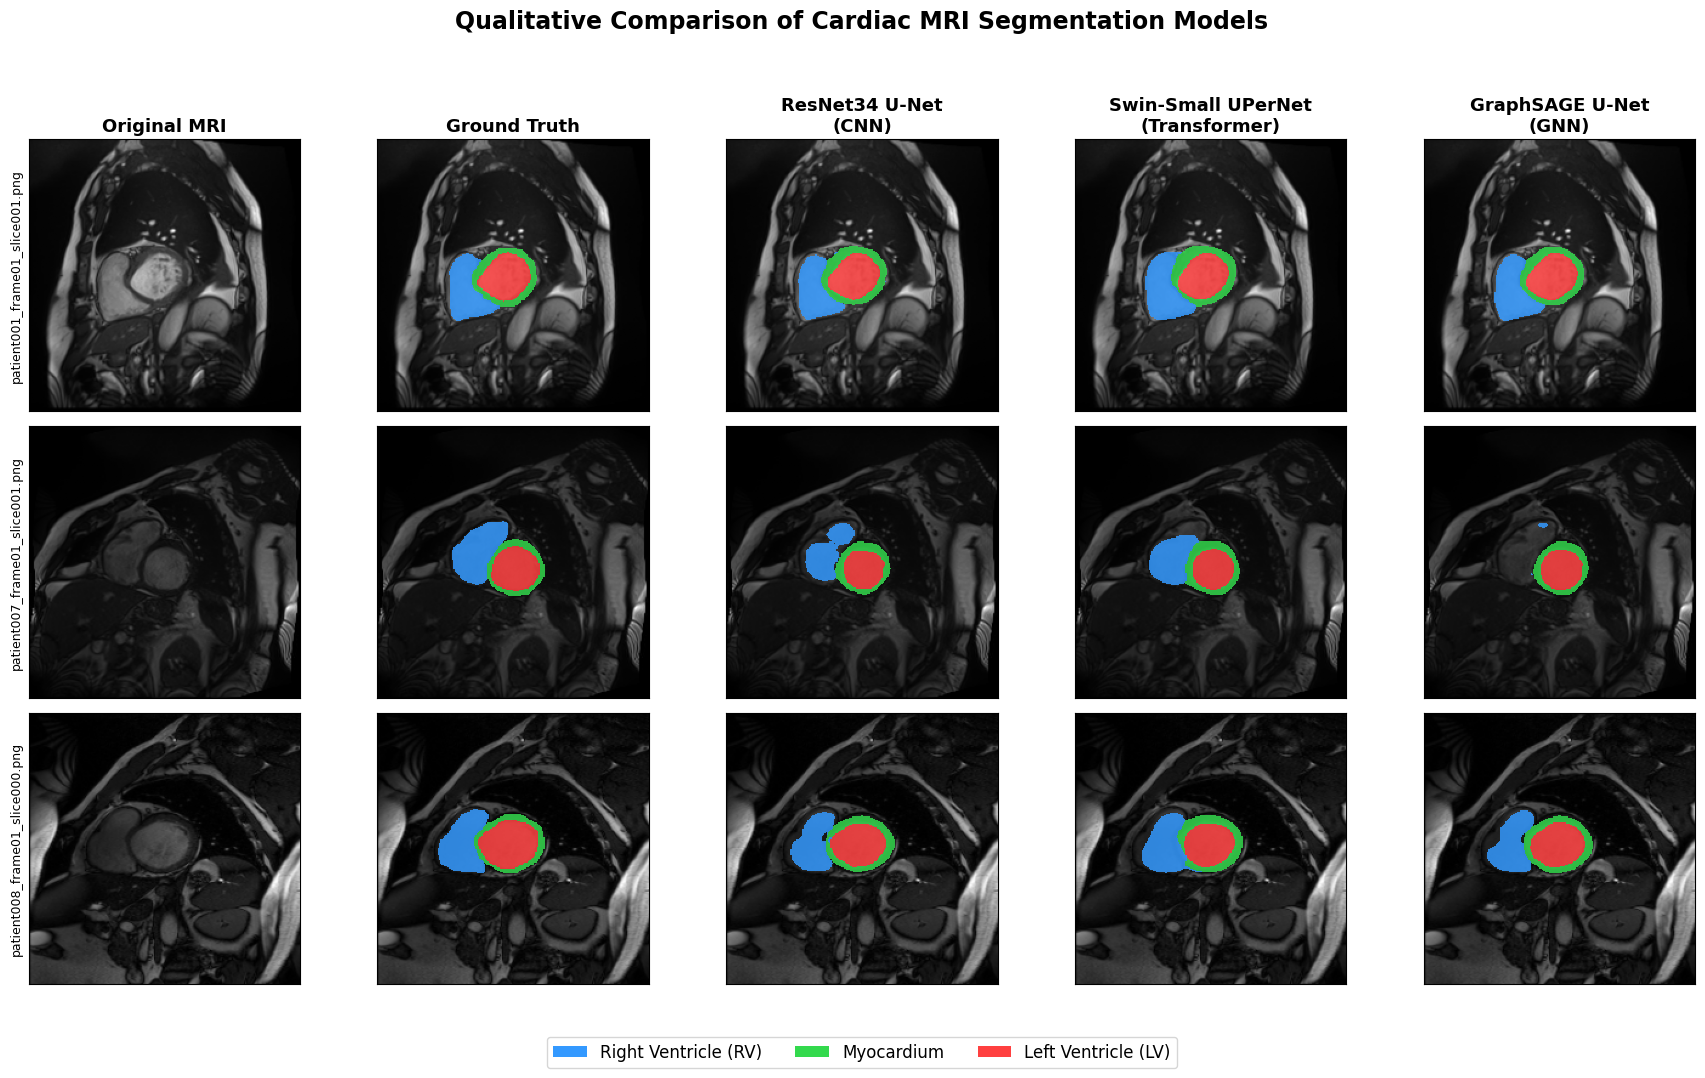

In [ ]:
# Segmentation colors:
# 0 = transparent background
# 1 = RV
# 2 = Myocardium
# 3 = LV

seg_cmap = ListedColormap([
    (0, 0, 0, 0),
    (0.20, 0.60, 1.00, 0.85),
    (0.20, 0.85, 0.30, 0.85),
    (1.00, 0.25, 0.25, 0.85)
])


fig, axes = plt.subplots(
    len(selected_indices),
    5,
    figsize=(18, 11)
)


column_titles = [
    "Original MRI",
    "Ground Truth",
    "ResNet34 U-Net\n(CNN)",
    "Swin-Small UPerNet\n(Transformer)",
    "GraphSAGE U-Net\n(GNN)"
]


for col, title in enumerate(column_titles):

    axes[0, col].set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )


for row, idx in enumerate(selected_indices):

    image, true_mask = test_dataset[idx]

    filename = test_dataset.images[idx]

    # Predictions

    resnet_pred = predict_mask(
        resnet_model,
        image
    )

    swin_pred = predict_mask(
        swin_model,
        image
    )

    graphsage_pred = predict_mask(
        graphsage_model,
        image
    )


    true_mask_np = (
        true_mask.cpu().numpy()
    )

    # Original MRI

    display_image = denormalize_image(
        image
    )

    display_image = (
        display_image[0]
        .numpy()
    )


    axes[row, 0].imshow(
        display_image,
        cmap="gray"
    )

    axes[row, 0].set_ylabel(
        filename,
        fontsize=9
    )


    # Ground truth

    axes[row, 1].imshow(
        display_image,
        cmap="gray"
    )

    axes[row, 1].imshow(
        true_mask_np,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )


    # ResNet

    axes[row, 2].imshow(
        display_image,
        cmap="gray"
    )

    axes[row, 2].imshow(
        resnet_pred,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    # Swin

    axes[row, 3].imshow(
        display_image,
        cmap="gray"
    )

    axes[row, 3].imshow(
        swin_pred,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )


    # GraphSAGE

    axes[row, 4].imshow(
        display_image,
        cmap="gray"
    )

    axes[row, 4].imshow(
        graphsage_pred,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )


    for col in range(5):

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])


plt.suptitle(
    "Qualitative Comparison of Cardiac MRI Segmentation Models",
    fontsize=17,
    fontweight="bold"
)


plt.tight_layout(
    rect=[0, 0.03, 1, 0.95]
)

# SEGMENTATION LEGEND

legend_elements = [

    Patch(
        facecolor=(0.20, 0.60, 1.00),
        label="Right Ventricle (RV)"
    ),

    Patch(
        facecolor=(0.20, 0.85, 0.30),
        label="Myocardium"
    ),

    Patch(
        facecolor=(1.00, 0.25, 0.25),
        label="Left Ventricle (LV)"
    )
]


fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, 0.01)
)


plt.tight_layout(
    rect=[0, 0.08, 1, 0.95]
)


plt.savefig(
    "/content/CNN_Transformer_GraphSAGE_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

# ***M&Ms Dataset***


In [ ]:
!pip install -q datasets nibabel

In [ ]:
from datasets import load_dataset

print("M&Ms setup ready.")

M&Ms setup ready.


Inspect the Dataset

In [ ]:
from datasets import load_dataset

DATASET_NAME = "viennh2012/cardiac_cine_mnms"

mnms = load_dataset(DATASET_NAME)

print("\nDataset loaded successfully!\n")
print(mnms)

train.csv:   0%|          | 0.00/43.5k [00:00<?, ?B/s]

val.csv:   0%|          | 0.00/9.99k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/40.1k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/150 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/34 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/136 [00:00<?, ? examples/s]


Dataset loaded successfully!

DatasetDict({
    train: Dataset({
        features: ['pid', 'sax_ed', 'sax_ed_gt', 'sax_es', 'sax_es_gt', 'sax_t', 'vendor_name', 'vendor', 'center', 'ed_index', 'es_index', 'age', 'pathology', 'gender', 'height', 'weight', 'orig_sax_spacing_x', 'orig_sax_spacing_y', 'orig_sax_spacing_z', 'n_slices', 'lv_edv', 'lv_esv', 'lv_ef', 'rv_edv', 'rv_esv', 'rv_ef'],
        num_rows: 150
    })
    val: Dataset({
        features: ['pid', 'sax_ed', 'sax_ed_gt', 'sax_es', 'sax_es_gt', 'sax_t', 'vendor_name', 'vendor', 'center', 'ed_index', 'es_index', 'age', 'pathology', 'gender', 'height', 'weight', 'orig_sax_spacing_x', 'orig_sax_spacing_y', 'orig_sax_spacing_z', 'n_slices', 'lv_edv', 'lv_esv', 'lv_ef', 'rv_edv', 'rv_esv', 'rv_ef'],
        num_rows: 34
    })
    test: Dataset({
        features: ['pid', 'sax_ed', 'sax_ed_gt', 'sax_es', 'sax_es_gt', 'sax_t', 'vendor_name', 'vendor', 'center', 'ed_index', 'es_index', 'age', 'pathology', 'gender', 'height', 'wei

In [ ]:
# STEP M2 — INSPECT M&Ms DATASET STRUCTURE

print("Available splits:")
print(mnms.keys())

print("\n" + "=" * 60)

for split in mnms.keys():
    print(f"\nSplit: {split}")
    print(f"Number of samples: {len(mnms[split])}")
    print("Features:")
    print(mnms[split].features)

print("\n" + "=" * 60)

# Look at one training sample
sample = mnms["train"][0]

print("\nKeys in one training sample:")
print(sample.keys())

print("\nSample field types:")
for key, value in sample.items():
    print(f"{key:25s}: {type(value)}")

Available splits:
dict_keys(['train', 'val', 'test'])


Split: train
Number of samples: 150
Features:
{'pid': Value('string'), 'sax_ed': Value('string'), 'sax_ed_gt': Value('string'), 'sax_es': Value('string'), 'sax_es_gt': Value('string'), 'sax_t': Value('float64'), 'vendor_name': Value('string'), 'vendor': Value('string'), 'center': Value('int64'), 'ed_index': Value('int64'), 'es_index': Value('int64'), 'age': Value('int64'), 'pathology': Value('string'), 'gender': Value('string'), 'height': Value('float64'), 'weight': Value('float64'), 'orig_sax_spacing_x': Value('float64'), 'orig_sax_spacing_y': Value('float64'), 'orig_sax_spacing_z': Value('float64'), 'n_slices': Value('int64'), 'lv_edv': Value('float64'), 'lv_esv': Value('float64'), 'lv_ef': Value('float64'), 'rv_edv': Value('float64'), 'rv_esv': Value('float64'), 'rv_ef': Value('float64')}

Split: val
Number of samples: 34
Features:
{'pid': Value('string'), 'sax_ed': Value('string'), 'sax_ed_gt': Value('string'), 'sax_es': Value

In [ ]:
# STEP M3A — INSPECT ONE M&Ms PATIENT

sample = mnms["train"][0]

print("Patient ID:", sample["pid"])
print("Vendor:", sample["vendor_name"])
print("Center:", sample["center"])
print("Pathology:", sample["pathology"])
print("Number of slices:", sample["n_slices"])

print("\n--- MRI / MASK PATHS ---")
print("ED MRI:")
print(sample["sax_ed"])

print("\nED Ground Truth:")
print(sample["sax_ed_gt"])

print("\nES MRI:")
print(sample["sax_es"])

print("\nES Ground Truth:")
print(sample["sax_es_gt"])

Patient ID: A0S9V9
Vendor: Siemens
Center: 1
Pathology: DCM
Number of slices: 12

--- MRI / MASK PATHS ---
ED MRI:
train/A0S9V9/A0S9V9_sax_ed.nii.gz

ED Ground Truth:
train/A0S9V9/A0S9V9_sax_ed_gt.nii.gz

ES MRI:
train/A0S9V9/A0S9V9_sax_es.nii.gz

ES Ground Truth:
train/A0S9V9/A0S9V9_sax_es_gt.nii.gz


In [ ]:
import os

for key in ["sax_ed", "sax_ed_gt", "sax_es", "sax_es_gt"]:

    path = sample[key]

    print(
        f"{key:12s} | "
        f"exists = {os.path.exists(path)} | "
        f"{path}"
    )

sax_ed       | exists = False | train/A0S9V9/A0S9V9_sax_ed.nii.gz
sax_ed_gt    | exists = False | train/A0S9V9/A0S9V9_sax_ed_gt.nii.gz
sax_es       | exists = False | train/A0S9V9/A0S9V9_sax_es.nii.gz
sax_es_gt    | exists = False | train/A0S9V9/A0S9V9_sax_es_gt.nii.gz


In [ ]:
from huggingface_hub import list_repo_files

repo_id = "viennh2012/cardiac_cine_mnms"

files = list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Total repository files:", len(files))

print("\nFirst 50 files:")
for f in files[:50]:
    print(f)

print("\nNIfTI files:")
nii_files = [
    f for f in files
    if f.endswith(".nii") or f.endswith(".nii.gz")
]

print("Number of NIfTI files:", len(nii_files))

for f in nii_files[:20]:
    print(f)

Total repository files: 1291

First 50 files:
.gitattributes
README.md
data/test-00000-of-00001.parquet
data/train-00000-of-00001.parquet
data/val-00000-of-00001.parquet
test.csv
test/A1K2P5/A1K2P5_sax_ed.nii.gz
test/A1K2P5/A1K2P5_sax_ed_gt.nii.gz
test/A1K2P5/A1K2P5_sax_es.nii.gz
test/A1K2P5/A1K2P5_sax_es_gt.nii.gz
test/A2H5K9/A2H5K9_sax_ed.nii.gz
test/A2H5K9/A2H5K9_sax_ed_gt.nii.gz
test/A2H5K9/A2H5K9_sax_es.nii.gz
test/A2H5K9/A2H5K9_sax_es_gt.nii.gz
test/A2L1N6/A2L1N6_sax_ed.nii.gz
test/A2L1N6/A2L1N6_sax_ed_gt.nii.gz
test/A2L1N6/A2L1N6_sax_es.nii.gz
test/A2L1N6/A2L1N6_sax_es_gt.nii.gz
test/A3H5R1/A3H5R1_sax_ed.nii.gz
test/A3H5R1/A3H5R1_sax_ed_gt.nii.gz
test/A3H5R1/A3H5R1_sax_es.nii.gz
test/A3H5R1/A3H5R1_sax_es_gt.nii.gz
test/A3P9V7/A3P9V7_sax_ed.nii.gz
test/A3P9V7/A3P9V7_sax_ed_gt.nii.gz
test/A3P9V7/A3P9V7_sax_es.nii.gz
test/A3P9V7/A3P9V7_sax_es_gt.nii.gz
test/A4A8V9/A4A8V9_sax_ed.nii.gz
test/A4A8V9/A4A8V9_sax_ed_gt.nii.gz
test/A4A8V9/A4A8V9_sax_es.nii.gz
test/A4A8V9/A4A8V9_sax_es_gt.

Download M&Ms NIfTI files

In [ ]:
from huggingface_hub import snapshot_download

MNMS_ROOT = "/content/MNMS"

snapshot_download(
    repo_id="viennh2012/cardiac_cine_mnms",
    repo_type="dataset",
    local_dir=MNMS_ROOT,
    allow_patterns=[
        "train/**",
        "val/**",
        "test/**",
        "train.csv",
        "val.csv",
        "test.csv"
    ]
)

print("M&Ms NIfTI files downloaded!")
print("Dataset root:", MNMS_ROOT)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1283 files:   0%|          | 0/1283 [00:00<?, ?it/s]

M&Ms NIfTI files downloaded!
Dataset root: /content/MNMS


Verify 1 Patient

In [ ]:
import os

sample = mnms["train"][0]

print("Patient:", sample["pid"])
print()

for key in ["sax_ed", "sax_ed_gt", "sax_es", "sax_es_gt"]:

    full_path = os.path.join(
        MNMS_ROOT,
        sample[key]
    )

    print(
        f"{key:12s} | "
        f"exists = {os.path.exists(full_path)} | "
        f"{full_path}"
    )

Patient: A0S9V9

sax_ed       | exists = True | /content/MNMS/train/A0S9V9/A0S9V9_sax_ed.nii.gz
sax_ed_gt    | exists = True | /content/MNMS/train/A0S9V9/A0S9V9_sax_ed_gt.nii.gz
sax_es       | exists = True | /content/MNMS/train/A0S9V9/A0S9V9_sax_es.nii.gz
sax_es_gt    | exists = True | /content/MNMS/train/A0S9V9/A0S9V9_sax_es_gt.nii.gz


In [ ]:
import nibabel as nib
import numpy as np

ed_path = os.path.join(
    MNMS_ROOT,
    sample["sax_ed"]
)

ed_gt_path = os.path.join(
    MNMS_ROOT,
    sample["sax_ed_gt"]
)

# Load MRI
ed_nii = nib.load(ed_path)
ed_image = ed_nii.get_fdata()

# Load segmentation
ed_gt_nii = nib.load(ed_gt_path)
ed_mask = ed_gt_nii.get_fdata()

print("=" * 60)
print("M&Ms PATIENT INSPECTION")
print("=" * 60)

print("Patient:", sample["pid"])

print("\nMRI")
print("Shape:", ed_image.shape)
print("Data type:", ed_image.dtype)
print("Min intensity:", ed_image.min())
print("Max intensity:", ed_image.max())

print("\nGROUND TRUTH")
print("Shape:", ed_mask.shape)
print("Data type:", ed_mask.dtype)
print("Unique labels:", np.unique(ed_mask))

print("\nVOXEL SPACING")
print(ed_nii.header.get_zooms())

print("\nMetadata n_slices:")
print(sample["n_slices"])

M&Ms PATIENT INSPECTION
Patient: A0S9V9

MRI
Shape: (192, 192, 12)
Data type: float64
Min intensity: 0.0
Max intensity: 255.0

GROUND TRUTH
Shape: (192, 192, 12)
Data type: float64
Unique labels: [0. 1. 2. 3.]

VOXEL SPACING
(np.float32(1.0), np.float32(1.0), np.float32(10.0))

Metadata n_slices:
12


Visualize 5 M&Ms Patients

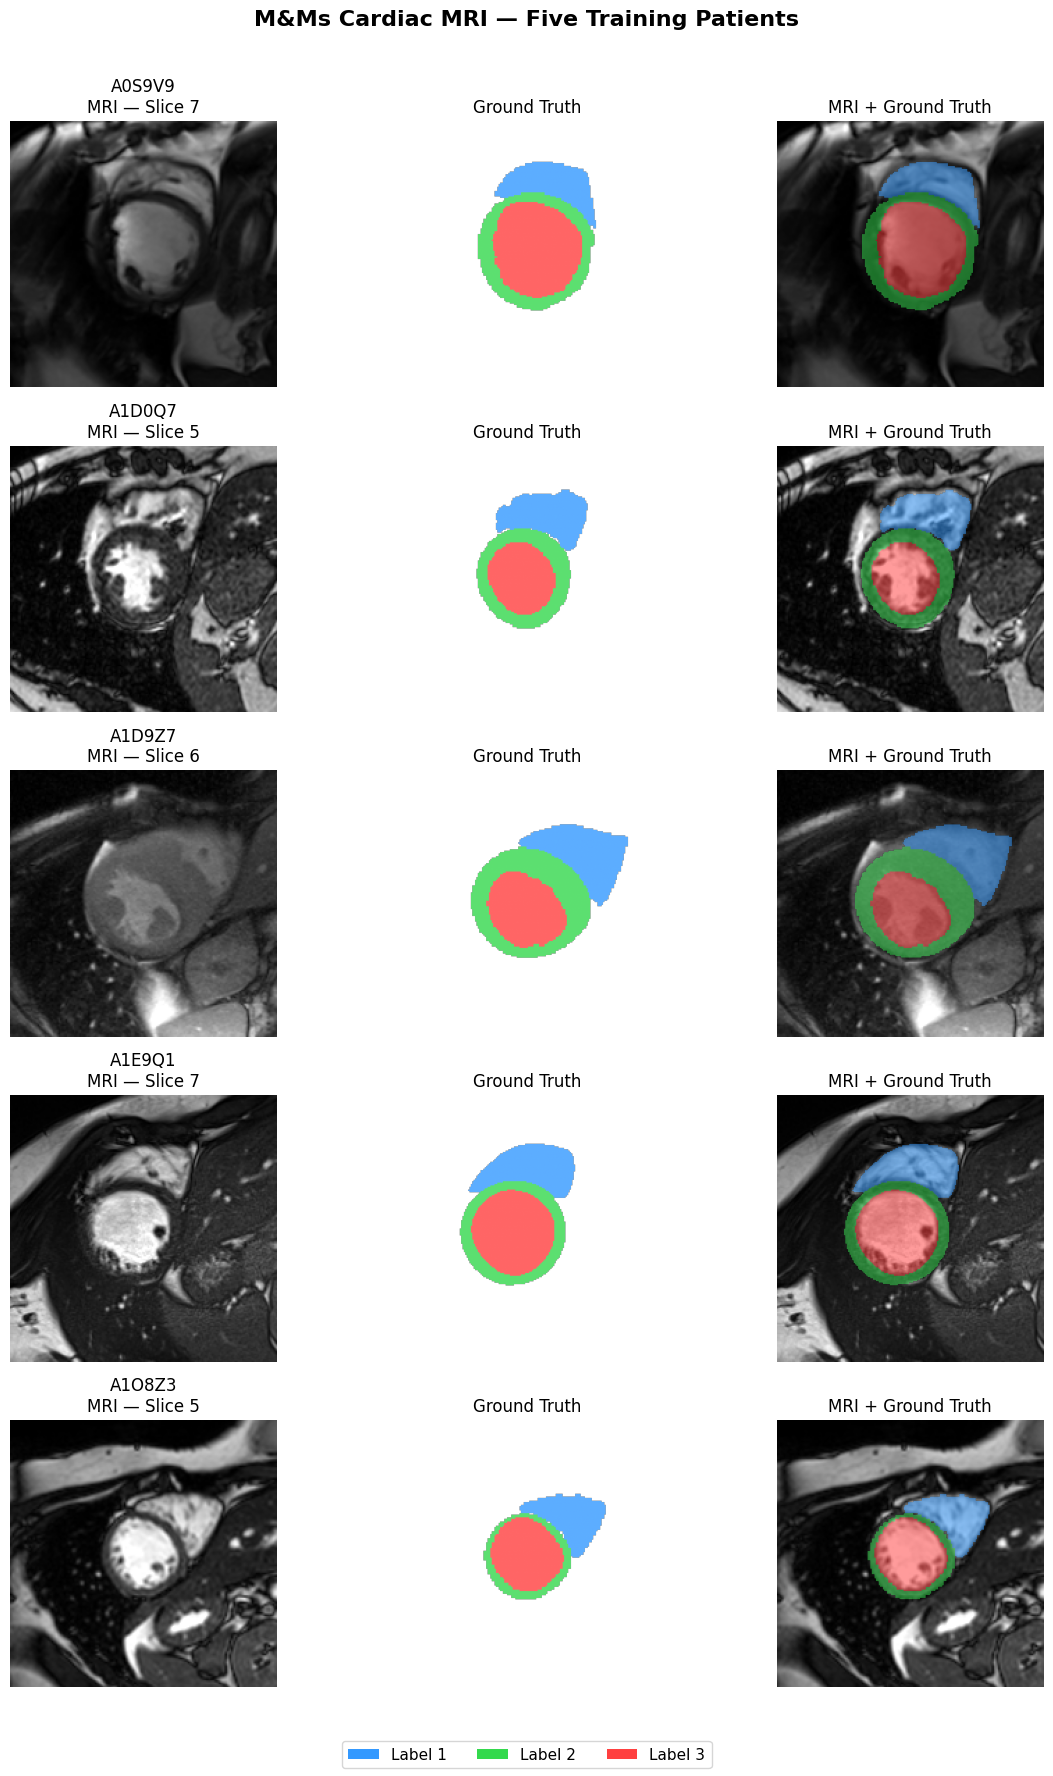

In [ ]:
# STEP M6 — VISUALIZE 5 M&Ms PATIENTS
# MRI | GROUND TRUTH | OVERLAY

import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# Segmentation colors

# 0 = Background
# 1, 2, 3 will be verified before we assign anatomical names

seg_cmap = ListedColormap([
    (0.0, 0.0, 0.0, 0.0),   # Background - transparent
    (0.2, 0.6, 1.0, 0.8),   # Label 1 - blue
    (0.2, 0.85, 0.3, 0.8),  # Label 2 - green
    (1.0, 0.25, 0.25, 0.8)  # Label 3 - red
])


# Choose 5 different training patients

num_patients = 5

fig, axes = plt.subplots(
    num_patients,
    3,
    figsize=(12, 18)
)


for row in range(num_patients):

    sample = mnms["train"][row]

    patient_id = sample["pid"]

    image_path = os.path.join(
        MNMS_ROOT,
        sample["sax_ed"]
    )

    mask_path = os.path.join(
        MNMS_ROOT,
        sample["sax_ed_gt"]
    )

    # Load MRI and mask

    image_volume = nib.load(
        image_path
    ).get_fdata()

    mask_volume = nib.load(
        mask_path
    ).get_fdata()

    # Find slices containing segmentation

    valid_slices = []

    for z in range(mask_volume.shape[2]):

        if np.any(mask_volume[:, :, z] > 0):
            valid_slices.append(z)


    # Pick middle annotated slice
    if len(valid_slices) > 0:

        slice_idx = valid_slices[
            len(valid_slices) // 2
        ]

    else:

        slice_idx = (
            mask_volume.shape[2] // 2
        )


    image_slice = image_volume[
        :, :, slice_idx
    ]

    mask_slice = mask_volume[
        :, :, slice_idx
    ]


    # Original MRI

    axes[row, 0].imshow(
        image_slice,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"{patient_id}\nMRI — Slice {slice_idx}"
    )

    axes[row, 0].axis("off")


    # Ground-truth segmentation

    axes[row, 1].imshow(
        mask_slice,
        cmap=seg_cmap,
        vmin=0,
        vmax=3
    )

    axes[row, 1].set_title(
        "Ground Truth"
    )

    axes[row, 1].axis("off")

    # MRI + segmentation overlay

    axes[row, 2].imshow(
        image_slice,
        cmap="gray"
    )

    masked_segmentation = np.ma.masked_where(
        mask_slice == 0,
        mask_slice
    )

    axes[row, 2].imshow(
        masked_segmentation,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        alpha=0.65
    )

    axes[row, 2].set_title(
        "MRI + Ground Truth"
    )

    axes[row, 2].axis("off")


plt.suptitle(
    "M&Ms Cardiac MRI — Five Training Patients",
    fontsize=16,
    fontweight="bold"
)

# Temporary label

legend_elements = [

    Patch(
        facecolor=(0.2, 0.6, 1.0),
        label="Label 1"
    ),

    Patch(
        facecolor=(0.2, 0.85, 0.3),
        label="Label 2"
    ),

    Patch(
        facecolor=(1.0, 0.25, 0.25),
        label="Label 3"
    )
]


fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=11
)


plt.tight_layout(
    rect=[0, 0.04, 1, 0.97]
)

plt.show()

Build 2-D Slice Index

In [ ]:
# STEP M7 — BUILD M&Ms 2D SLICE INDEX


import os
import nibabel as nib
import numpy as np


def build_mnms_slice_index(hf_split, mnms_root):

    slice_index = []

    for patient_idx in range(len(hf_split)):

        sample = hf_split[patient_idx]

        patient_id = sample["pid"]

        # Use both cardiac phases
        phases = [
            ("ED", sample["sax_ed"], sample["sax_ed_gt"]),
            ("ES", sample["sax_es"], sample["sax_es_gt"])
        ]

        for phase, image_rel_path, mask_rel_path in phases:

            image_path = os.path.join(
                mnms_root,
                image_rel_path
            )

            mask_path = os.path.join(
                mnms_root,
                mask_rel_path
            )

            # Load mask only to determine valid slices
            mask_volume = nib.load(
                mask_path
            ).get_fdata()

            num_slices = mask_volume.shape[2]

            for slice_idx in range(num_slices):

                mask_slice = mask_volume[:, :, slice_idx]

                # Keep slices containing at least one
                # foreground cardiac structure
                if np.any(mask_slice > 0):

                    slice_index.append({
                        "patient_id": patient_id,
                        "phase": phase,
                        "slice_idx": slice_idx,
                        "image_path": image_path,
                        "mask_path": mask_path
                    })

    return slice_index

In [ ]:
train_slice_index = build_mnms_slice_index(
    mnms["train"],
    MNMS_ROOT
)

val_slice_index = build_mnms_slice_index(
    mnms["val"],
    MNMS_ROOT
)

test_slice_index = build_mnms_slice_index(
    mnms["test"],
    MNMS_ROOT
)


print("=" * 60)
print("M&Ms 2D SEGMENTATION DATASET")
print("=" * 60)

print(
    f"Train: {len(train_slice_index)} annotated slices"
)

print(
    f"Validation: {len(val_slice_index)} annotated slices"
)

print(
    f"Test: {len(test_slice_index)} annotated slices"
)

M&Ms 2D SEGMENTATION DATASET
Train: 2373 annotated slices
Validation: 573 annotated slices
Test: 2201 annotated slices


In [ ]:
train_patients = set(
    item["patient_id"]
    for item in train_slice_index
)

val_patients = set(
    item["patient_id"]
    for item in val_slice_index
)

test_patients = set(
    item["patient_id"]
    for item in test_slice_index
)


print("\nPatient counts:")
print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))


print("\nPatient overlap:")

print(
    "Train ∩ Validation:",
    len(train_patients & val_patients)
)

print(
    "Train ∩ Test:",
    len(train_patients & test_patients)
)

print(
    "Validation ∩ Test:",
    len(val_patients & test_patients)
)


Patient counts:
Train: 150
Validation: 34
Test: 136

Patient overlap:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


# M&Ms Pytorch Dataset

In [ ]:
# STEP M8 — M&Ms PYTORCH DATASET

import torch
from torch.utils.data import Dataset
import numpy as np bn
import nibabel as nib


class MNMSDataset(Dataset):

    def __init__(self, slice_index, transform=None):

        self.slice_index = slice_index
        self.transform = transform

        # Cache volumes so we don't repeatedly read the same
        # NIfTI files from disk for every slice
        self.volume_cache = {}

    def __len__(self):

        return len(self.slice_index)


    def _load_volume(self, path):

        if path not in self.volume_cache:

            self.volume_cache[path] = nib.load(
                path
            ).get_fdata()

        return self.volume_cache[path]


    def __getitem__(self, idx):

        item = self.slice_index[idx]


        # Load MRI and mask volumes


        image_volume = self._load_volume(
            item["image_path"]
        )

        mask_volume = self._load_volume(
            item["mask_path"]
        )


        # Extract requested 2D slice


        z = item["slice_idx"]

        image = image_volume[
            :, :, z
        ].astype(np.float32)

        mask = mask_volume[
            :, :, z
        ].astype(np.int64)

        # MRI intensity normalization to [0,1]


        image_min = image.min()
        image_max = image.max()

        if image_max > image_min:

            image = (
                image - image_min
            ) / (
                image_max - image_min
            )

        else:

            image = np.zeros_like(
                image,
                dtype=np.float32
            )


        # REMAP M&Ms LABELS
        #
        # Original:
        # 0 = Background
        # 1 = LV
        # 2 = Myocardium
        # 3 = RV
        #
        # Standard:
        # 0 = Background
        # 1 = RV
        # 2 = Myocardium
        # 3 = LV


        remapped_mask = np.zeros_like(
            mask,
            dtype=np.int64
        )

        remapped_mask[mask == 1] = 3   # LV
        remapped_mask[mask == 2] = 2   # Myocardium
        remapped_mask[mask == 3] = 1   # RV

        mask = remapped_mask


        # Convert grayscale MRI → RGB


        image = np.stack(
            [image, image, image],
            axis=-1
        )


        # Albumentations


        if self.transform:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]


        mask = mask.long()

        return image, mask

# **M**&Ms Transformer

In [ ]:
# STEP M9 — M&Ms TRANSFORMS


import albumentations as A
from albumentations.pytorch import ToTensorV2


mnms_train_transform = A.Compose([

    A.Resize(
        height=224,
        width=224
    ),

    A.HorizontalFlip(
        p=0.5
    ),

    A.Affine(
        scale=(0.90, 1.10),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.3
    ),

    A.GaussNoise(
        std_range=(0.01, 0.03),
        p=0.2
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])


mnms_eval_transform = A.Compose([

    A.Resize(
        height=224,
        width=224
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

In [ ]:
# STEP M10 — CREATE M&Ms DATASETS

mnms_train_dataset = MNMSDataset(
    train_slice_index,
    transform=mnms_train_transform
)

mnms_val_dataset = MNMSDataset(
    val_slice_index,
    transform=mnms_eval_transform
)

mnms_test_dataset = MNMSDataset(
    test_slice_index,
    transform=mnms_eval_transform
)


print("M&Ms datasets created successfully.")

print(
    "Train:",
    len(mnms_train_dataset)
)

print(
    "Validation:",
    len(mnms_val_dataset)
)

print(
    "Test:",
    len(mnms_test_dataset)
)

M&Ms datasets created successfully.
Train: 2373
Validation: 573
Test: 2201


In [ ]:
# STEP M11 — DATASET CHECK

image, mask = mnms_train_dataset[0]

print("=" * 60)
print("M&Ms DATASET CHECK")
print("=" * 60)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print()

print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)

print()

print(
    "Image range:",
    image.min().item(),
    "to",
    image.max().item()
)

print(
    "Mask labels:",
    torch.unique(mask).tolist()
)

M&Ms DATASET CHECK
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([224, 224])

Image dtype: torch.float32
Mask dtype: torch.int64

Image range: -2.1179039478302 to -1.7876580953598022
Mask labels: [0, 1, 2]


# Visualize M&M After Labeling

Selected samples: [1, 2, 3, 4, 5]


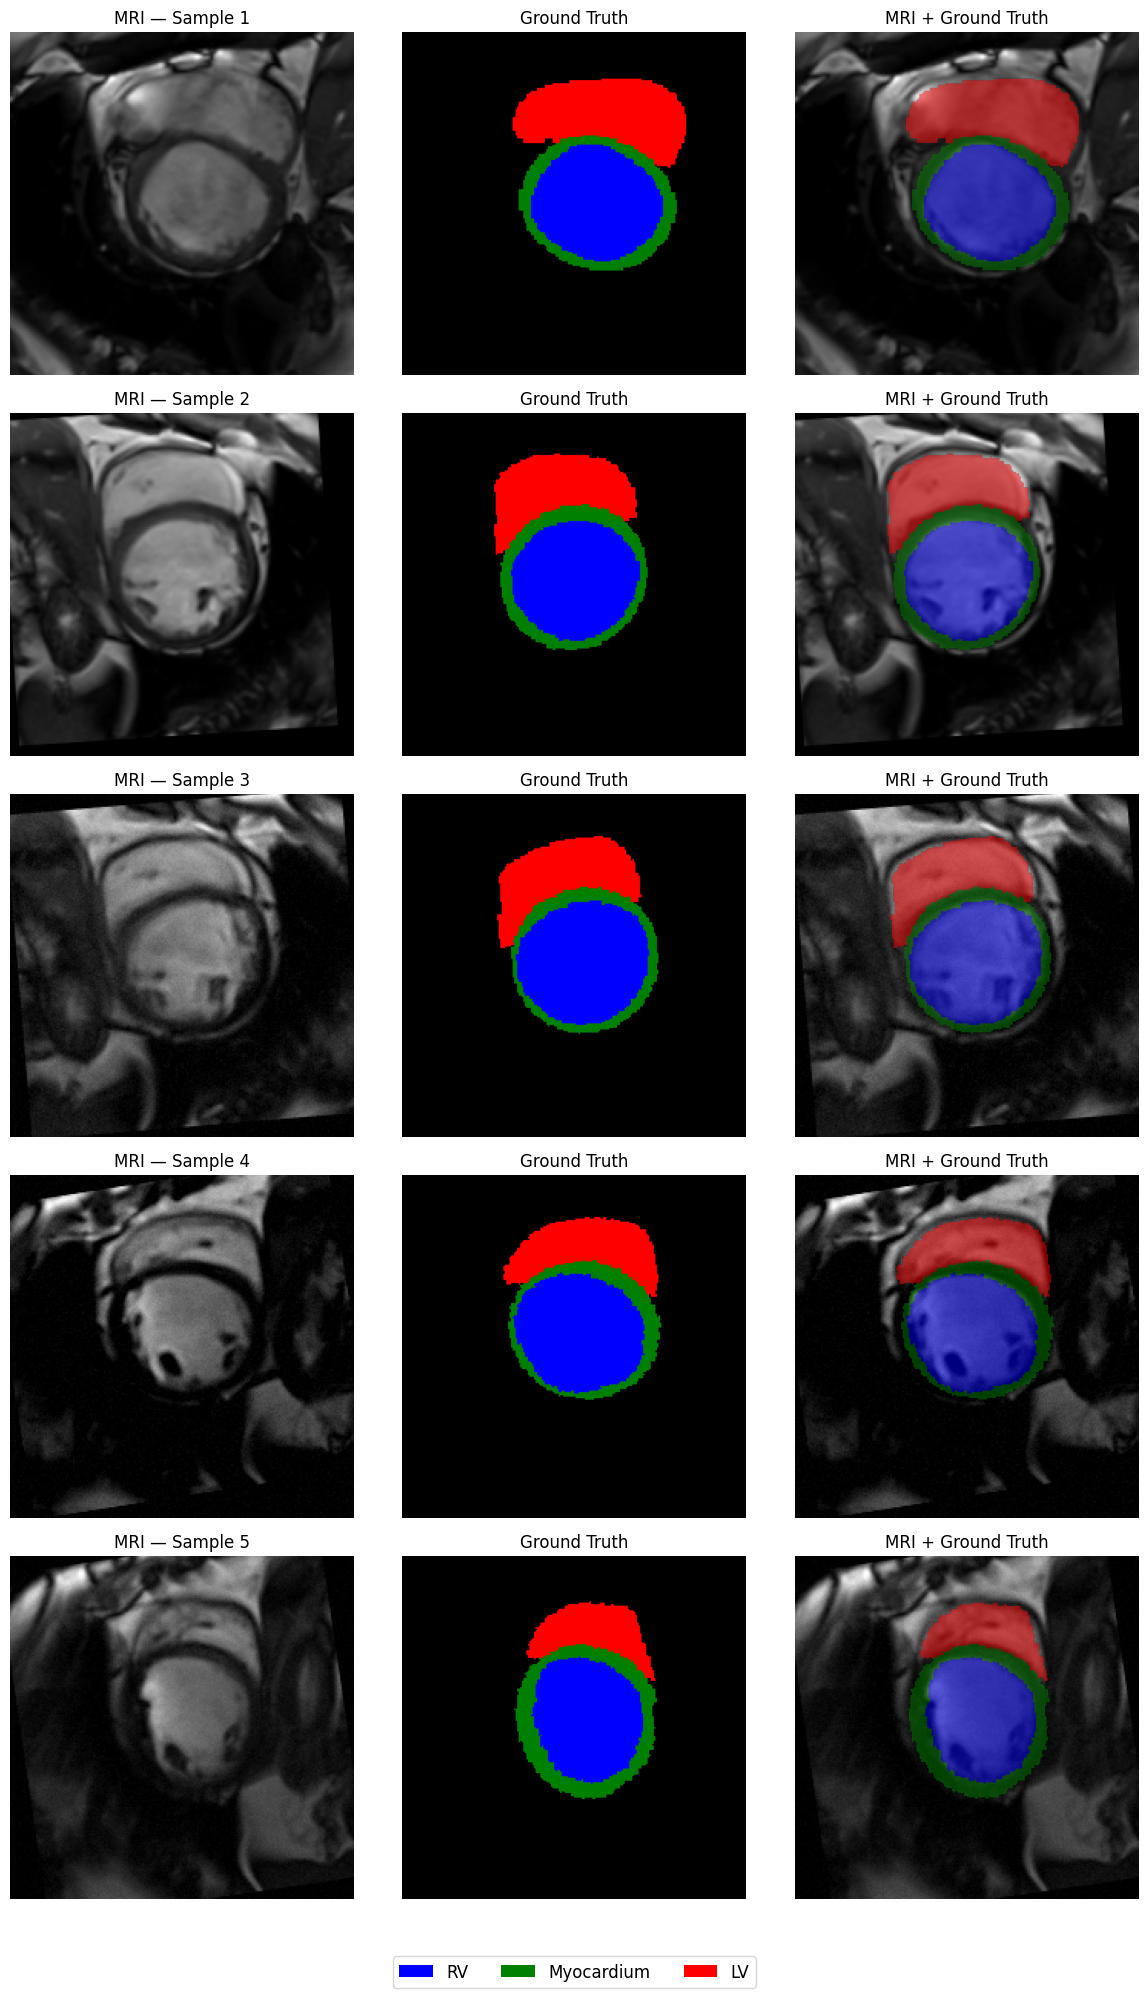

In [ ]:
# STEP M12 — VISUALIZE REMAPPED M&Ms DATA

import matplotlib.pyplot as plt
import numpy as np
import torch

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ImageNet normalization values
# Used to convert images back to a viewable range

mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])


def denormalize_image(image):

    image = image.permute(1, 2, 0).cpu().numpy()

    image = image * std + mean

    image = np.clip(image, 0, 1)

    return image

# Find 5 samples containing ALL cardiac structures
#
# Standardized labels:
# 0 = Background
# 1 = RV
# 2 = Myocardium
# 3 = LV

selected_indices = []

for i in range(len(mnms_train_dataset)):

    _, mask = mnms_train_dataset[i]

    labels = set(torch.unique(mask).tolist())

    if {1, 2, 3}.issubset(labels):

        selected_indices.append(i)

    if len(selected_indices) == 5:
        break


print("Selected samples:", selected_indices)

# Colormap

mask_cmap = ListedColormap([
    "black",   # 0 Background
    "blue",    # 1 RV
    "green",   # 2 Myocardium
    "red"      # 3 LV
])

# Create visualization

fig, axes = plt.subplots(
    5,
    3,
    figsize=(12, 20)
)


for row, idx in enumerate(selected_indices):

    image, mask = mnms_train_dataset[idx]

    image_np = denormalize_image(image)

    mask_np = mask.cpu().numpy()

    # MRI is grayscale, so one channel is enough
    gray_image = image_np[:, :, 0]


    # Original MRI

    axes[row, 0].imshow(
        gray_image,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"MRI — Sample {idx}"
    )

    # Ground Truth

    axes[row, 1].imshow(
        mask_np,
        cmap=mask_cmap,
        vmin=0,
        vmax=3
    )

    axes[row, 1].set_title(
        "Ground Truth"
    )

    # MRI + Ground Truth

    axes[row, 2].imshow(
        gray_image,
        cmap="gray"
    )

    masked_overlay = np.ma.masked_where(
        mask_np == 0,
        mask_np
    )

    axes[row, 2].imshow(
        masked_overlay,
        cmap=mask_cmap,
        vmin=0,
        vmax=3,
        alpha=0.50
    )

    axes[row, 2].set_title(
        "MRI + Ground Truth"
    )


    for col in range(3):
        axes[row, col].axis("off")


# Legend

legend_elements = [

    Patch(
        facecolor="blue",
        label="RV"
    ),

    Patch(
        facecolor="green",
        label="Myocardium"
    ),

    Patch(
        facecolor="red",
        label="LV"
    )
]


fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=12
)


plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.show()

# Create DataLoaders

In [ ]:
# STEP M13 — CREATE M&Ms DATALOADERS

from torch.utils.data import DataLoader


BATCH_SIZE = 8


mnms_train_loader = DataLoader(
    mnms_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)


mnms_val_loader = DataLoader(
    mnms_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


mnms_test_loader = DataLoader(
    mnms_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("=" * 60)
print("M&Ms DATALOADERS")
print("=" * 60)

print("Train batches:", len(mnms_train_loader))
print("Validation batches:", len(mnms_val_loader))
print("Test batches:", len(mnms_test_loader))

M&Ms DATALOADERS
Train batches: 297
Validation batches: 72
Test batches: 276


In [ ]:
# STEP M13B — CHECK ONE BATCH

images, masks = next(iter(mnms_train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)

print()

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print()

print(
    "Mask labels in batch:",
    torch.unique(masks).tolist()
)

Images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])

Image dtype: torch.float32
Mask dtype: torch.int64

Mask labels in batch: [0, 1, 2, 3]


# Pretrained CNN

In [ ]:
import segmentation_models_pytorch as smp

In [ ]:
# STEP M14B — PRETRAINED RESNET34 U-NET

mnms_resnet_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4
)

mnms_resnet_model = mnms_resnet_model.to(device)


total_params = sum(
    p.numel()
    for p in mnms_resnet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in mnms_resnet_model.parameters()
    if p.requires_grad
)


print("=" * 60)
print("M&Ms EXPERIMENT 1 — RESNET34 U-NET")
print("=" * 60)

print("Encoder: ResNet34")
print("Pretraining: ImageNet")
print("Output classes: 4")

print()

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print()

print("Device:", device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

M&Ms EXPERIMENT 1 — RESNET34 U-NET
Encoder: ResNet34
Pretraining: ImageNet
Output classes: 4

Total parameters: 24,436,804
Trainable parameters: 24,436,804

Device: cuda


In [ ]:
# STEP M14C — MODEL OUTPUT CHECK

images, masks = next(iter(mnms_train_loader))

images = images.to(device)

mnms_resnet_model.eval()

with torch.no_grad():

    outputs = mnms_resnet_model(images)


print("Input shape: ", images.shape)
print("Output shape:", outputs.shape)
print("Mask shape:  ", masks.shape)

Input shape:  torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 4, 224, 224])
Mask shape:   torch.Size([8, 224, 224])


# ResNet34 U-Net for M&Ms


In [ ]:
# STEP M24 — FRESH M&Ms RESNET34 U-NET

import torch
import segmentation_models_pytorch as smp

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# Create a COMPLETELY NEW model

mnms_resnet_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4
).to(device)


print("\nFresh pretrained ResNet34 U-Net created.")

print(
    "Parameters:",
    f"{sum(p.numel() for p in mnms_resnet_model.parameters()):,}"
)

Device: cuda
GPU: Tesla T4

Fresh pretrained ResNet34 U-Net created.
Parameters: 24,436,804


# Optimizer + Scheduler

In [ ]:
# STEP M25 — FRESH OPTIMIZER + SCHEDULER

optimizer = torch.optim.AdamW(
    [
        {
            "params": mnms_resnet_model.encoder.parameters(),
            "lr": 1e-4
        },
        {
            "params": mnms_resnet_model.decoder.parameters(),
            "lr": 5e-4
        },
        {
            "params": mnms_resnet_model.segmentation_head.parameters(),
            "lr": 5e-4
        }
    ],
    weight_decay=1e-4
)


scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)


print("Optimizer: AdamW")
print("Encoder LR: 1e-4")
print("Decoder/head LR: 5e-4")
print("Scheduler: ReduceLROnPlateau")

Optimizer: AdamW
Encoder LR: 1e-4
Decoder/head LR: 5e-4
Scheduler: ReduceLROnPlateau


# Mount Google Drive

In [ ]:
# CHECKPOINT DIRECTORY — PERSONAL GOOGLE DRIVE

from google.colab import drive
import os

drive.mount("/content/drive")

CHECKPOINT_DIR = "/content/drive/MyDrive/Thesis_Checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Checkpoint directory:")
print(CHECKPOINT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint directory:
/content/drive/MyDrive/Thesis_Checkpoints


In [ ]:
# M26 — PERMANENT CHECKPOINT PATHS

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_resnet34_unet_mnms.pth"
)

LATEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "latest_resnet34_unet_mnms.pth"
)

print("BEST checkpoint:")
print(BEST_MODEL_PATH)

print("\nLATEST checkpoint:")
print(LATEST_MODEL_PATH)

BEST checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_resnet34_unet_mnms.pth

LATEST checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/latest_resnet34_unet_mnms.pth


# Traning Epoch

In [ ]:
# M27 — SAFE M&Ms DATALOADERS

from torch.utils.data import DataLoader
import torch

BATCH_SIZE = 8

mnms_train_loader = DataLoader(
    mnms_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

mnms_val_loader = DataLoader(
    mnms_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

mnms_test_loader = DataLoader(
    mnms_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("SAFE DATALOADERS READY")
print("----------------------")
print("Train workers:", mnms_train_loader.num_workers)
print("Val workers:  ", mnms_val_loader.num_workers)
print("Test workers: ", mnms_test_loader.num_workers)

print()
print("Train batches:", len(mnms_train_loader))
print("Val batches:  ", len(mnms_val_loader))
print("Test batches: ", len(mnms_test_loader))

SAFE DATALOADERS READY
----------------------
Train workers: 0
Val workers:   0
Test workers:  0

Train batches: 297
Val batches:   72
Test batches:  276


In [ ]:
# M28 — FRESH RESNET34 U-NET

import segmentation_models_pytorch as smp
import torch
import os

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# Fresh ImageNet-pretrained ResNet34 U-Net
mnms_resnet_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4
).to(device)


# Optimizer
optimizer = torch.optim.AdamW(
    [
        {
            "params": mnms_resnet_model.encoder.parameters(),
            "lr": 1e-4
        },
        {
            "params": mnms_resnet_model.decoder.parameters(),
            "lr": 5e-4
        },
        {
            "params": mnms_resnet_model.segmentation_head.parameters(),
            "lr": 5e-4
        }
    ],
    weight_decay=1e-4
)


# Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)


# Permanent Drive checkpoints
BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_resnet34_unet_mnms.pth"
)

LATEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "latest_resnet34_unet_mnms.pth"
)


print("\nFresh ResNet34 U-Net created.")
print(
    "Parameters:",
    f"{sum(p.numel() for p in mnms_resnet_model.parameters()):,}"
)

print("\nBest checkpoint:")
print(BEST_MODEL_PATH)

print("\nLatest checkpoint:")
print(LATEST_MODEL_PATH)

Device: cuda
GPU: Tesla T4

Fresh ResNet34 U-Net created.
Parameters: 24,436,804

Best checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_resnet34_unet_mnms.pth

Latest checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/latest_resnet34_unet_mnms.pth


In [ ]:
# M28B — DICE SCORE FUNCTION

import numpy as np
import torch


def calculate_dice_scores(logits, masks, num_classes=4, smooth=1e-6):

    # Convert model logits to predicted class labels
    preds = torch.argmax(logits, dim=1)

    dice_scores = []

    # Foreground classes only:
    # 1 = RV
    # 2 = Myocardium
    # 3 = LV
    for class_id in range(1, num_classes):

        pred_class = (preds == class_id).float()
        true_class = (masks == class_id).float()

        intersection = (
            pred_class * true_class
        ).sum()

        denominator = (
            pred_class.sum() +
            true_class.sum()
        )

        # If class is absent from both prediction and GT,
        # ignore it rather than artificially giving Dice = 1
        if denominator.item() == 0:
            dice = np.nan

        else:
            dice = (
                (2.0 * intersection + smooth) /
                (denominator + smooth)
            ).item()

        dice_scores.append(dice)

    return dice_scores


print("Dice function ready.")
print("Class order: RV | Myocardium | LV")

Dice function ready.
Class order: RV | Myocardium | LV


In [ ]:
# M29 — M&Ms CNN TRAINING

import numpy as np
import torch

NUM_EPOCHS = 20

best_val_dice = -1.0
best_epoch = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],
    "mean_dice": []
}

print("=" * 80)
print("TRAINING M&Ms — PRETRAINED RESNET34 U-NET")
print("=" * 80)


for epoch in range(1, NUM_EPOCHS + 1):

    # TRAIN

    mnms_resnet_model.train()

    train_loss_sum = 0.0
    train_samples = 0

    for images, masks in mnms_train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        logits = mnms_resnet_model(images)

        loss = combined_loss(
            logits,
            masks
        )

        loss.backward()

        optimizer.step()

        batch_size = images.size(0)

        train_loss_sum += (
            loss.item() * batch_size
        )

        train_samples += batch_size


    train_loss = (
        train_loss_sum /
        train_samples
    )


    # VALIDATION

    mnms_resnet_model.eval()

    val_loss_sum = 0.0
    val_samples = 0

    rv_scores = []
    myo_scores = []
    lv_scores = []


    with torch.no_grad():

        for images, masks in mnms_val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            logits = mnms_resnet_model(images)

            loss = combined_loss(
                logits,
                masks
            )

            batch_size = images.size(0)

            val_loss_sum += (
                loss.item() * batch_size
            )

            val_samples += batch_size


            dice_scores = calculate_dice_scores(
                logits,
                masks
            )

            rv_scores.append(
                dice_scores[0]
            )

            myo_scores.append(
                dice_scores[1]
            )

            lv_scores.append(
                dice_scores[2]
            )


    val_loss = (
        val_loss_sum /
        val_samples
    )


    rv_dice = float(
        np.nanmean(rv_scores)
    )

    myo_dice = float(
        np.nanmean(myo_scores)
    )

    lv_dice = float(
        np.nanmean(lv_scores)
    )


    mean_dice = (
        rv_dice +
        myo_dice +
        lv_dice
    ) / 3.0


    # UPDATE SCHEDULER

    scheduler.step(mean_dice)


    # STORE HISTORY

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["rv_dice"].append(
        rv_dice
    )

    history["myo_dice"].append(
        myo_dice
    )

    history["lv_dice"].append(
        lv_dice
    )

    history["mean_dice"].append(
        mean_dice
    )


    # CHECK IF THIS IS THE BEST MODEL

    improved = (
        mean_dice > best_val_dice
    )

    if improved:

        best_val_dice = mean_dice
        best_epoch = epoch


        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    mnms_resnet_model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "best_epoch":
                    best_epoch,

                "history":
                    history
            },

            BEST_MODEL_PATH
        )


    # SAVE LATEST MODEL

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                mnms_resnet_model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "best_val_dice":
                best_val_dice,

            "best_epoch":
                best_epoch,

            "history":
                history
        },

        LATEST_MODEL_PATH
    )


    # PRINT ONE CLEAN LINE

    lr = optimizer.param_groups[0]["lr"]

    marker = "  ← BEST" if improved else ""

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"RV: {rv_dice:.4f} | "
        f"Myo: {myo_dice:.4f} | "
        f"LV: {lv_dice:.4f} | "
        f"Mean Dice: {mean_dice:.4f} | "
        f"LR: {lr:.1e}"
        f"{marker}"
    )


print("\n" + "=" * 80)
print("TRAINING COMPLETE")
print("=" * 80)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best validation Dice: "
    f"{best_val_dice:.4f}"
)

print("\nBest model saved to:")
print(BEST_MODEL_PATH)

print("\nLatest model saved to:")
print(LATEST_MODEL_PATH)

In [ ]:
# M30 — LOAD BEST M&Ms RESNET34 U-NET

import torch
import os

print("=" * 70)
print("LOADING BEST M&Ms RESNET34 U-NET")
print("=" * 70)

print("Checkpoint exists:", os.path.exists(BEST_MODEL_PATH))

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

mnms_resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

mnms_resnet_model = mnms_resnet_model.to(device)
mnms_resnet_model.eval()

print("\nBest epoch:", checkpoint["epoch"])
print(
    "Best validation Dice:",
    f"{checkpoint['best_val_dice']:.4f}"
)

print("\nBest model loaded successfully.")

LOADING BEST M&Ms RESNET34 U-NET
Checkpoint exists: True

Best epoch: 18
Best validation Dice: 0.8805

Best model loaded successfully.


# Test Dice + IoU

In [ ]:
# M31 — M&Ms TEST EVALUATION
# Dice + IoU

import numpy as np
import torch

NUM_CLASSES = 4

# Class mapping after our M&Ms remapping:
# 0 = Background
# 1 = RV
# 2 = Myocardium
# 3 = LV

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

# Accumulators

intersection = np.zeros(NUM_CLASSES, dtype=np.float64)
predicted_pixels = np.zeros(NUM_CLASSES, dtype=np.float64)
target_pixels = np.zeros(NUM_CLASSES, dtype=np.float64)

mnms_resnet_model.eval()

print("=" * 70)
print("M&Ms TEST SET — RESNET34 U-NET")
print("=" * 70)

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        mnms_test_loader
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits = mnms_resnet_model(images)

        predictions = torch.argmax(
            logits,
            dim=1
        )

        # Pixel counts for each class

        for cls in range(NUM_CLASSES):

            pred_cls = predictions == cls
            target_cls = masks == cls

            intersection[cls] += (
                pred_cls & target_cls
            ).sum().item()

            predicted_pixels[cls] += (
                pred_cls.sum().item()
            )

            target_pixels[cls] += (
                target_cls.sum().item()
            )


# CALCULATE METRICS

dice_results = {}
iou_results = {}

for cls in range(1, NUM_CLASSES):

    inter = intersection[cls]

    pred = predicted_pixels[cls]

    target = target_pixels[cls]


    # Dice
    dice = (
        (2.0 * inter) /
        (pred + target)
        if (pred + target) > 0
        else np.nan
    )


    # IoU
    union = (
        pred +
        target -
        inter
    )

    iou = (
        inter / union
        if union > 0
        else np.nan
    )


    dice_results[cls] = dice
    iou_results[cls] = iou

# MACRO AVERAGES

macro_dice = np.nanmean(
    list(dice_results.values())
)

macro_iou = np.nanmean(
    list(iou_results.values())
)


# PRINT RESULTS

print("\nPER-CLASS RESULTS")
print("-" * 70)

for cls in range(1, NUM_CLASSES):

    print(
        f"{class_names[cls]:12s} | "
        f"Dice: {dice_results[cls]:.4f} | "
        f"IoU: {iou_results[cls]:.4f}"
    )


print("-" * 70)

print(
    f"{'MACRO AVG':12s} | "
    f"Dice: {macro_dice:.4f} | "
    f"IoU: {macro_iou:.4f}"
)

print("=" * 70)

M&Ms TEST SET — RESNET34 U-NET

PER-CLASS RESULTS
----------------------------------------------------------------------
RV           | Dice: 0.9329 | IoU: 0.8742
Myocardium   | Dice: 0.8337 | IoU: 0.7148
LV           | Dice: 0.8753 | IoU: 0.7782
----------------------------------------------------------------------
MACRO AVG    | Dice: 0.8806 | IoU: 0.7891


M&Ms RESNET34 U-NET — ROC-AUC

Processing RV...
RV ROC-AUC: 0.9994

Processing Myocardium...
Myocardium ROC-AUC: 0.9962

Processing LV...
LV ROC-AUC: 0.9947

----------------------------------------------------------------------
RV          : 0.9994
Myocardium  : 0.9962
LV          : 0.9947
----------------------------------------------------------------------
MACRO AVG   : 0.9967


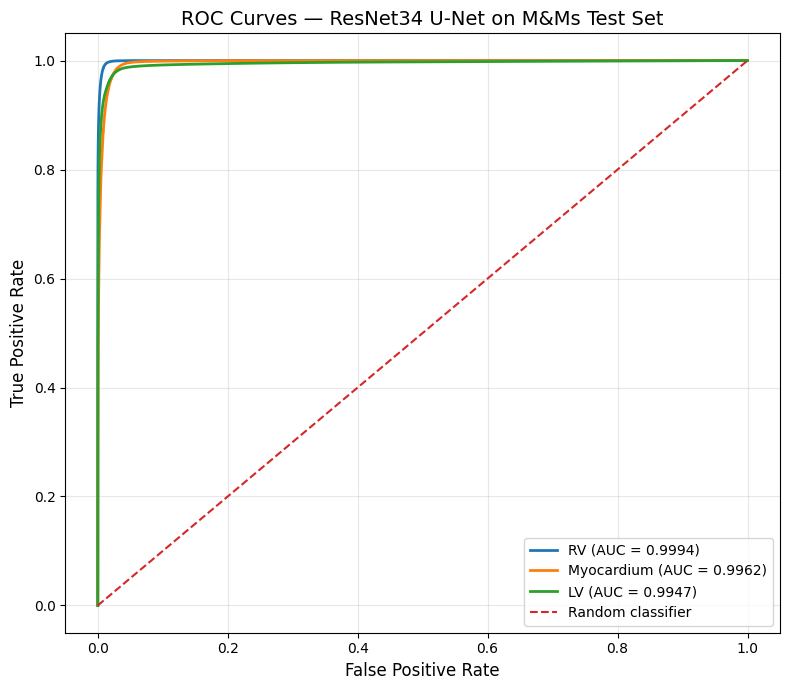

In [ ]:
# M32 — M&Ms RESNET34 U-NET
# PIXEL-LEVEL ROC-AUC + ROC CURVES

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc


class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


roc_results = {}
auc_results = {}


print("=" * 70)
print("M&Ms RESNET34 U-NET — ROC-AUC")
print("=" * 70)


mnms_resnet_model.eval()


# PROCESS ONE CLASS AT A TIME

for cls in [1, 2, 3]:

    print(
        f"\nProcessing {class_names[cls]}..."
    )

    class_probabilities = []
    class_targets = []


    with torch.no_grad():

        for images, masks in mnms_test_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            # Forward pass
            logits = mnms_resnet_model(images)

            # Convert logits to probabilities
            probabilities = F.softmax(
                logits,
                dim=1
            )

            # Probability for THIS class only
            cls_probs = probabilities[
                :, cls, :, :
            ]

            # Binary target:
            # 1 = current class
            # 0 = everything else
            cls_target = (
                masks == cls
            )


            # Flatten
            cls_probs = (
                cls_probs
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
                .astype(np.float32)
            )

            cls_target = (
                cls_target
                .numpy()
                .reshape(-1)
                .astype(np.uint8)
            )


            class_probabilities.append(
                cls_probs
            )

            class_targets.append(
                cls_target
            )


    # Combine batches
    y_score = np.concatenate(
        class_probabilities
    )

    y_true = np.concatenate(
        class_targets
    )


    # ROC CURVE

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_score
    )

    roc_auc = auc(
        fpr,
        tpr
    )


    roc_results[cls] = {
        "fpr": fpr,
        "tpr": tpr
    }

    auc_results[cls] = roc_auc


    print(
        f"{class_names[cls]} ROC-AUC: "
        f"{roc_auc:.4f}"
    )


    # Free large arrays before next class
    del y_score
    del y_true
    del class_probabilities
    del class_targets

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# MACRO AVERAGE AUC

macro_auc = np.mean(
    list(auc_results.values())
)


print("\n" + "-" * 70)

for cls in [1, 2, 3]:

    print(
        f"{class_names[cls]:12s}: "
        f"{auc_results[cls]:.4f}"
    )


print("-" * 70)

print(
    f"{'MACRO AVG':12s}: "
    f"{macro_auc:.4f}"
)


# ROC VISUALIZATION

plt.figure(figsize=(8, 7))


for cls in [1, 2, 3]:

    plt.plot(
        roc_results[cls]["fpr"],
        roc_results[cls]["tpr"],
        linewidth=2,
        label=(
            f"{class_names[cls]} "
            f"(AUC = {auc_results[cls]:.4f})"
        )
    )


# Random-classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curves — ResNet34 U-Net on M&Ms Test Set",
    fontsize=14
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

# SSIM + Hausdorff + HD95

In [ ]:
# M&Ms RESNET34 U-NET
# SSIM + HAUSDORFF DISTANCE + HD95

import numpy as np
import torch

from skimage.metrics import structural_similarity as ssim
from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import binary_erosion, distance_transform_edt


CLASS_NAMES = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

# Hausdorff Distance

def hausdorff_distance(pred_mask, true_mask):

    pred_points = np.argwhere(pred_mask)
    true_points = np.argwhere(true_mask)

    # Cannot calculate boundary distance if either mask is empty
    if len(pred_points) == 0 or len(true_points) == 0:
        return np.nan

    hd_forward = directed_hausdorff(
        pred_points,
        true_points
    )[0]

    hd_backward = directed_hausdorff(
        true_points,
        pred_points
    )[0]

    return max(hd_forward, hd_backward)


# HD95

def hd95_distance(pred_mask, true_mask):

    pred_mask = pred_mask.astype(bool)
    true_mask = true_mask.astype(bool)

    if not pred_mask.any() or not true_mask.any():
        return np.nan

    # Extract boundaries
    pred_boundary = pred_mask ^ binary_erosion(pred_mask)
    true_boundary = true_mask ^ binary_erosion(true_mask)

    if not pred_boundary.any() or not true_boundary.any():
        return np.nan

    # Distance to nearest boundary pixel
    dist_to_true = distance_transform_edt(~true_boundary)
    dist_to_pred = distance_transform_edt(~pred_boundary)

    distances_pred_to_true = dist_to_true[pred_boundary]
    distances_true_to_pred = dist_to_pred[true_boundary]

    all_distances = np.concatenate([
        distances_pred_to_true,
        distances_true_to_pred
    ])

    return np.percentile(all_distances, 95)


# STORAGE

results = {
    class_id: {
        "ssim": [],
        "hd": [],
        "hd95": []
    }
    for class_id in CLASS_NAMES
}


# EVALUATION

mnms_resnet_model.eval()

print("=" * 70)
print("M&Ms RESNET34 U-NET — SSIM / HAUSDORFF / HD95")
print("=" * 70)


with torch.no_grad():

    for images, masks in mnms_test_loader:

        images = images.to(device)

        logits = mnms_resnet_model(images)

        preds = torch.argmax(
            logits,
            dim=1
        )

        preds = preds.cpu().numpy()
        masks_np = masks.cpu().numpy()


        for b in range(preds.shape[0]):

            for class_id in CLASS_NAMES:

                pred_binary = (
                    preds[b] == class_id
                ).astype(np.uint8)

                true_binary = (
                    masks_np[b] == class_id
                ).astype(np.uint8)


                # SSIM

                class_ssim = ssim(
                    true_binary,
                    pred_binary,
                    data_range=1
                )

                results[class_id]["ssim"].append(
                    class_ssim
                )

                # HD + HD95
                # Only when class exists in BOTH masks

                if pred_binary.any() and true_binary.any():

                    hd = hausdorff_distance(
                        pred_binary,
                        true_binary
                    )

                    hd95 = hd95_distance(
                        pred_binary,
                        true_binary
                    )

                    results[class_id]["hd"].append(
                        hd
                    )

                    results[class_id]["hd95"].append(
                        hd95
                    )


# PRINT RESULTS

print("\nFINAL RESULTS")
print("-" * 70)

macro_ssim = []
macro_hd = []
macro_hd95 = []


for class_id, class_name in CLASS_NAMES.items():

    mean_ssim = np.nanmean(
        results[class_id]["ssim"]
    )

    mean_hd = np.nanmean(
        results[class_id]["hd"]
    )

    mean_hd95 = np.nanmean(
        results[class_id]["hd95"]
    )


    macro_ssim.append(mean_ssim)
    macro_hd.append(mean_hd)
    macro_hd95.append(mean_hd95)


    print(
        f"{class_name:<12} | "
        f"SSIM: {mean_ssim:.4f} | "
        f"Hausdorff: {mean_hd:.4f} | "
        f"HD95: {mean_hd95:.4f}"
    )


print("-" * 70)

print(
    f"{'MACRO AVG':<12} | "
    f"SSIM: {np.mean(macro_ssim):.4f} | "
    f"Hausdorff: {np.mean(macro_hd):.4f} | "
    f"HD95: {np.mean(macro_hd95):.4f}"
)

print("-" * 70)

print("\nNOTE:")
print("Hausdorff and HD95 are measured in pixels on the resized 224×224 masks.")

M&Ms RESNET34 U-NET — SSIM / HAUSDORFF / HD95

FINAL RESULTS
----------------------------------------------------------------------
RV           | SSIM: 0.9798 | Hausdorff: 5.0669 | HD95: 4.1917
Myocardium   | SSIM: 0.9536 | Hausdorff: 6.8422 | HD95: 4.7360
LV           | SSIM: 0.9757 | Hausdorff: 8.3499 | HD95: 6.2686
----------------------------------------------------------------------
MACRO AVG    | SSIM: 0.9697 | Hausdorff: 6.7530 | HD95: 5.0654
----------------------------------------------------------------------

NOTE:
Hausdorff and HD95 are measured in pixels on the resized 224×224 masks.


# Calculate Dice + IoU

In [ ]:
# M&Ms RESNET34 U-NET — TEST DICE + IoU
# CURRENT EPOCH-18 CHECKPOINT

import numpy as np
import torch

CLASS_NAMES = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

dice_results = {
    class_id: []
    for class_id in CLASS_NAMES
}

iou_results = {
    class_id: []
    for class_id in CLASS_NAMES
}


mnms_resnet_model.eval()

print("=" * 70)
print("M&Ms RESNET34 U-NET — TEST DICE + IoU")
print("=" * 70)


with torch.no_grad():

    for images, masks in mnms_test_loader:

        images = images.to(device)

        logits = mnms_resnet_model(images)

        preds = torch.argmax(
            logits,
            dim=1
        ).cpu().numpy()

        masks_np = masks.numpy()


        for b in range(preds.shape[0]):

            for class_id in CLASS_NAMES:

                pred_binary = (
                    preds[b] == class_id
                )

                true_binary = (
                    masks_np[b] == class_id
                )


                # Ignore slices where class is absent
                # from BOTH prediction and ground truth
                if not pred_binary.any() and not true_binary.any():
                    continue


                intersection = np.logical_and(
                    pred_binary,
                    true_binary
                ).sum()

                pred_sum = pred_binary.sum()
                true_sum = true_binary.sum()

                union = np.logical_or(
                    pred_binary,
                    true_binary
                ).sum()


                # Dice
                dice = (
                    2.0 * intersection /
                    (pred_sum + true_sum)
                )

                # IoU
                iou = (
                    intersection / union
                    if union > 0
                    else np.nan
                )


                dice_results[class_id].append(
                    dice
                )

                iou_results[class_id].append(
                    iou
                )


print("\nFINAL TEST RESULTS")
print("-" * 70)

macro_dice = []
macro_iou = []


for class_id, class_name in CLASS_NAMES.items():

    mean_dice = np.nanmean(
        dice_results[class_id]
    )

    mean_iou = np.nanmean(
        iou_results[class_id]
    )

    macro_dice.append(mean_dice)
    macro_iou.append(mean_iou)

    print(
        f"{class_name:<12} | "
        f"Dice: {mean_dice:.4f} | "
        f"IoU: {mean_iou:.4f}"
    )


print("-" * 70)

print(
    f"{'MACRO AVG':<12} | "
    f"Dice: {np.mean(macro_dice):.4f} | "
    f"IoU: {np.mean(macro_iou):.4f}"
)

print("-" * 70)

M&Ms RESNET34 U-NET — TEST DICE + IoU

FINAL TEST RESULTS
----------------------------------------------------------------------
RV           | Dice: 0.8863 | IoU: 0.8182
Myocardium   | Dice: 0.8022 | IoU: 0.6851
LV           | Dice: 0.7604 | IoU: 0.6880
----------------------------------------------------------------------
MACRO AVG    | Dice: 0.8163 | IoU: 0.7304
----------------------------------------------------------------------


# Quantitative Visualization

Selected 3 test slices containing RV, Myocardium and LV.


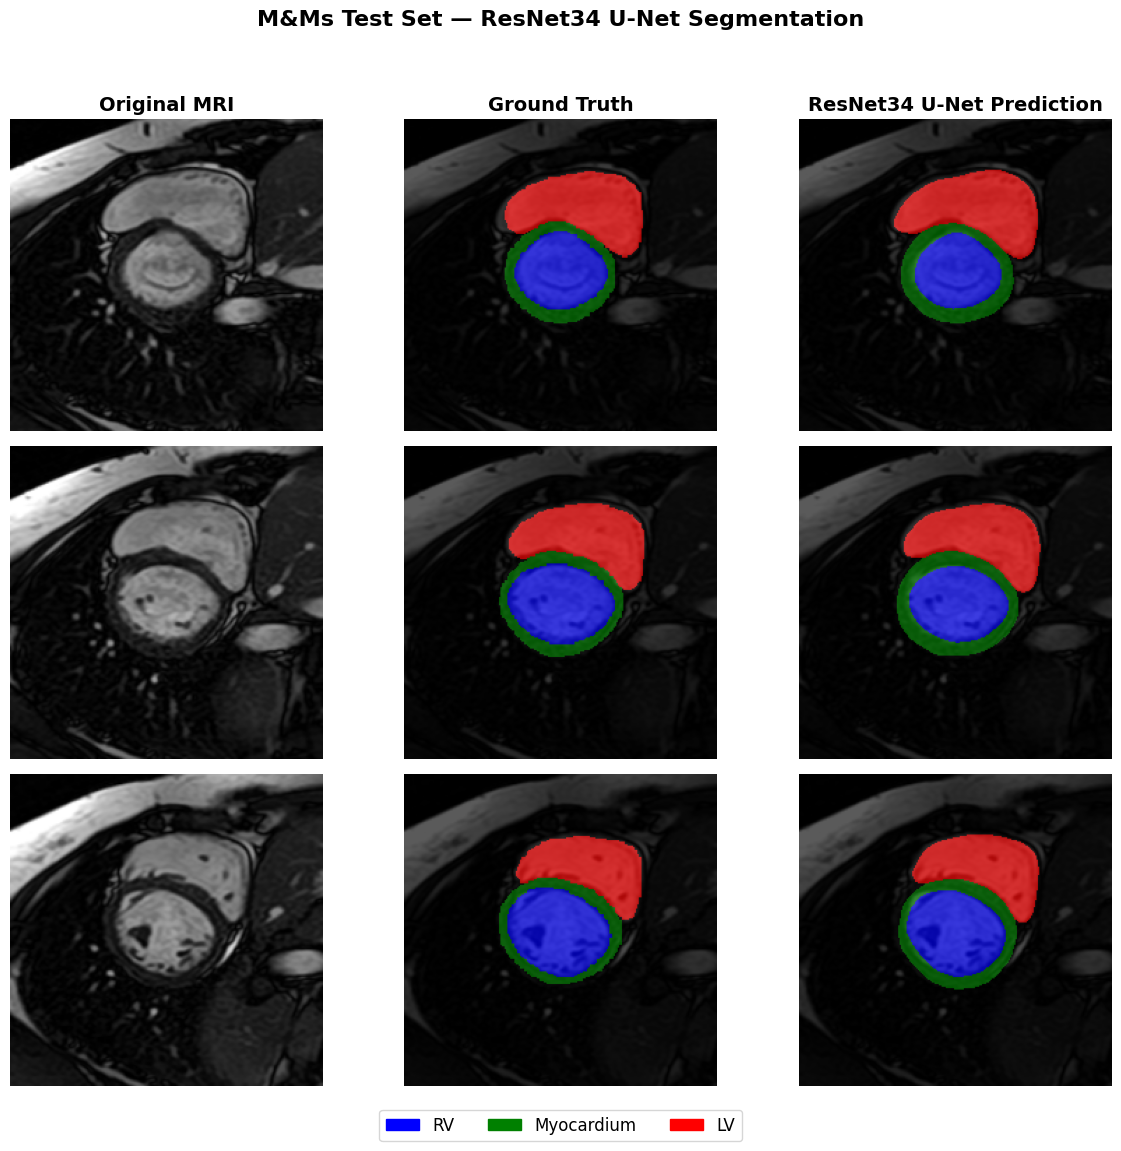

In [ ]:
# M&Ms RESNET34 U-NET — QUALITATIVE VISUALIZATION
# Original MRI | Ground Truth | Prediction

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch

# ImageNet normalization used during preprocessing
MEAN = np.array([0.485, 0.456, 0.406])
STD  = np.array([0.229, 0.224, 0.225])


def denormalize_image(image_tensor):
    """
    Convert normalized CHW tensor back to displayable grayscale image.
    """

    image = image_tensor.cpu().numpy()
    image = np.transpose(image, (1, 2, 0))

    image = image * STD + MEAN
    image = np.clip(image, 0, 1)

    # MRI was originally grayscale, so use first channel
    return image[:, :, 0]


# Find 3 useful test examples containing ALL foreground classes

selected_examples = []

mnms_resnet_model.eval()

with torch.no_grad():

    for images, masks in mnms_test_loader:

        images_gpu = images.to(device)

        logits = mnms_resnet_model(images_gpu)

        preds = torch.argmax(
            logits,
            dim=1
        ).cpu()


        for i in range(images.size(0)):

            unique_labels = set(
                torch.unique(masks[i]).tolist()
            )

            # Require RV, Myocardium and LV in ground truth
            if {1, 2, 3}.issubset(unique_labels):

                selected_examples.append(
                    (
                        images[i].cpu(),
                        masks[i].cpu(),
                        preds[i].cpu()
                    )
                )

            if len(selected_examples) == 3:
                break


        if len(selected_examples) == 3:
            break


print(
    f"Selected {len(selected_examples)} "
    "test slices containing RV, Myocardium and LV."
)


# Segmentation colors
#
# 0 = Background
# 1 = RV
# 2 = Myocardium
# 3 = LV

seg_cmap = plt.matplotlib.colors.ListedColormap(
    [
        "black",
        "blue",
        "green",
        "red"
    ]
)

seg_norm = plt.matplotlib.colors.BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    seg_cmap.N
)


# Create 3 × 3 figure

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)


column_titles = [
    "Original MRI",
    "Ground Truth",
    "ResNet34 U-Net Prediction"
]


for col, title in enumerate(column_titles):

    axes[0, col].set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )


for row, (image, mask, pred) in enumerate(selected_examples):

    mri = denormalize_image(image)


    # ORIGINAL MRI
    axes[row, 0].imshow(
        mri,
        cmap="gray"
    )

    axes[row, 0].axis("off")


    # GROUND TRUTH
    axes[row, 1].imshow(
        mri,
        cmap="gray"
    )

    axes[row, 1].imshow(
        mask.numpy(),
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.65
    )

    axes[row, 1].axis("off")


    # PREDICTION
    axes[row, 2].imshow(
        mri,
        cmap="gray"
    )

    axes[row, 2].imshow(
        pred.numpy(),
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.65
    )

    axes[row, 2].axis("off")


# Legend

legend_patches = [

    mpatches.Patch(
        color="blue",
        label="RV"
    ),

    mpatches.Patch(
        color="green",
        label="Myocardium"
    ),

    mpatches.Patch(
        color="red",
        label="LV"
    )
]


fig.legend(
    handles=legend_patches,
    loc="lower center",
    ncol=3,
    fontsize=12,
    bbox_to_anchor=(0.5, 0.02)
)


fig.suptitle(
    "M&Ms Test Set — ResNet34 U-Net Segmentation",
    fontsize=16,
    fontweight="bold",
    y=0.97
)


plt.tight_layout(
    rect=[0, 0.06, 1, 0.94]
)

plt.show()

# SWIN U-Net for M&Ms

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S1: CHECK TRANSFORMERS ENVIRONMENT

import torch
import transformers
import huggingface_hub

print("=" * 60)
print("SWIN UPERNET — ENVIRONMENT CHECK")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nTesting UPerNet import...")

from transformers import UperNetForSemanticSegmentation

print("✓ UPerNet import successful!")

SWIN UPERNET — ENVIRONMENT CHECK
PyTorch: 2.11.0+cu130
Transformers: 5.17.0
Hugging Face Hub: 1.31.0
CUDA available: True
GPU: Tesla T4

Testing UPerNet import...
✓ UPerNet import successful!


# Load Pretrained SWIN U-Net

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S2: LOAD PRETRAINED MODEL

import torch
from transformers import UperNetForSemanticSegmentation

NUM_CLASSES = 4

print("=" * 70)
print("LOADING PRETRAINED SWIN-SMALL UPERNET")
print("=" * 70)

swin_model = UperNetForSemanticSegmentation.from_pretrained(
    "openmmlab/upernet-swin-small",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)

swin_model = swin_model.to(device)

# Parameter information

total_params = sum(
    p.numel()
    for p in swin_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in swin_model.parameters()
    if p.requires_grad
)

print("\n✓ Pretrained Swin-Small UPerNet loaded.")

print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\nNumber of output classes:", swin_model.config.num_labels)

print("\nClass mapping:")
print("0 = Background")
print("1 = RV")
print("2 = Myocardium")
print("3 = LV")

LOADING PRETRAINED SWIN-SMALL UPERNET


config.json:   0%|          | 0.00/8.98k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  326MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

[transformers] UperNetForSemanticSegmentation LOAD REPORT from: openmmlab/upernet-swin-small
Key                              | Status   |                                                                                                     
---------------------------------+----------+-----------------------------------------------------------------------------------------------------
auxiliary_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([4, 256, 1, 1])
decode_head.classifier.bias      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
decode_head.classifier.weight    | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 512, 1, 1]) vs model:torch.Size([4, 512, 1, 1])
auxiliary_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      

Notes:
- MISMATCH:	ckpt 


✓ Pretrained Swin-Small UPerNet loaded.

Total parameters:     81,148,882
Trainable parameters: 81,148,882

Number of output classes: 4

Class mapping:
0 = Background
1 = RV
2 = Myocardium
3 = LV


# Test one M&Ms batch

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET


import torch
import torch.nn.functional as F

print("=" * 70)
print("SWIN-SMALL UPERNET — FORWARD PASS TEST")
print("=" * 70)

# Get one batch
images, masks = next(iter(mnms_train_loader))

print("\nInput images:", images.shape)
print("Masks:", masks.shape)
print("Mask labels:", torch.unique(masks).tolist())

images = images.to(device)
masks = masks.to(device)

swin_model.eval()

with torch.no_grad():

    outputs = swin_model(
        pixel_values=images
    )

    logits = outputs.logits

    print("\nRaw Swin output:")
    print(logits.shape)

    # UPerNet output may be lower resolution than the input.
    # Resize logits back to mask resolution.
    logits = F.interpolate(
        logits,
        size=masks.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

print("\nResized output:")
print(logits.shape)

print("\nExpected:")
print(
    f"[batch_size, 4, "
    f"{masks.shape[-2]}, {masks.shape[-1]}]"
)

print("\n✓ Forward pass successful.")

SWIN-SMALL UPERNET — FORWARD PASS TEST

Input images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])
Mask labels: [0, 1, 2, 3]

Raw Swin output:
torch.Size([8, 4, 224, 224])

Resized output:
torch.Size([8, 4, 224, 224])

Expected:
[batch_size, 4, 224, 224]

✓ Forward pass successful.


# Loss Function

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S4: LOSS FUNCTION

import torch
import torch.nn.functional as F


def multiclass_dice_loss(
    logits,
    targets,
    num_classes=4,
    smooth=1e-6
):

    probs = torch.softmax(
        logits,
        dim=1
    )

    targets_one_hot = F.one_hot(
        targets,
        num_classes=num_classes
    )

    targets_one_hot = (
        targets_one_hot
        .permute(0, 3, 1, 2)
        .float()
    )

    dice_losses = []

    # Foreground classes only
    # 1 = RV
    # 2 = Myocardium
    # 3 = LV
    for class_id in range(1, num_classes):

        pred = probs[:, class_id]
        true = targets_one_hot[:, class_id]

        intersection = (
            pred * true
        ).sum(dim=(1, 2))

        denominator = (
            pred.sum(dim=(1, 2)) +
            true.sum(dim=(1, 2))
        )

        dice = (
            (2.0 * intersection + smooth) /
            (denominator + smooth)
        )

        dice_losses.append(
            1.0 - dice.mean()
        )

    return torch.stack(
        dice_losses
    ).mean()


def swin_combined_loss(
    logits,
    targets
):

    ce_loss = F.cross_entropy(
        logits,
        targets
    )

    dice_loss = multiclass_dice_loss(
        logits,
        targets
    )

    return (
        0.5 * ce_loss +
        0.5 * dice_loss
    )


print("✓ Swin loss function ready.")
print("Loss = 0.5 × Cross-Entropy + 0.5 × Foreground Dice")

✓ Swin loss function ready.
Loss = 0.5 × Cross-Entropy + 0.5 × Foreground Dice


# Optimizer + Scheduler

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S5: OPTIMIZER + LEARNING-RATE SCHEDULER

import torch

SWIN_LR = 5e-5

swin_optimizer = torch.optim.AdamW(
    swin_model.parameters(),
    lr=SWIN_LR,
    weight_decay=1e-4
)

swin_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    swin_optimizer,
    mode="max",       # We want validation Dice to increase
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

print("✓ Swin optimizer ready.")
print("✓ Swin scheduler ready.")

print(f"\nInitial learning rate: {SWIN_LR:.1e}")
print("Optimizer: AdamW")
print("Weight decay: 1e-4")
print("Scheduler: ReduceLROnPlateau")
print("Scheduler monitors: Validation Mean Dice")

✓ Swin optimizer ready.
✓ Swin scheduler ready.

Initial learning rate: 5.0e-05
Optimizer: AdamW
Weight decay: 1e-4
Scheduler: ReduceLROnPlateau
Scheduler monitors: Validation Mean Dice


# SWIN Checkpoint Path

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S6: PERMANENT GOOGLE DRIVE CHECKPOINT PATHS

import os

# We already mounted Google Drive earlier
CHECKPOINT_DIR = "/content/drive/MyDrive/Thesis_Checkpoints"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

SWIN_BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_swin_upernet_mnms.pth"
)

SWIN_LATEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "latest_swin_upernet_mnms.pth"
)


print("=" * 70)
print("SWIN CHECKPOINT PATHS")
print("=" * 70)

print("\nBEST Swin checkpoint:")
print(SWIN_BEST_MODEL_PATH)

print("\nLATEST Swin checkpoint:")
print(SWIN_LATEST_MODEL_PATH)

print("\nCheckpoint directory exists:")
print(os.path.exists(CHECKPOINT_DIR))

print("\n✓ Swin checkpoints will be saved permanently to Google Drive.")

SWIN CHECKPOINT PATHS

BEST Swin checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_swin_upernet_mnms.pth

LATEST Swin checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/latest_swin_upernet_mnms.pth

Checkpoint directory exists:
True

✓ Swin checkpoints will be saved permanently to Google Drive.


# Train Swin UPerNet

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S7: TRAINING + VALIDATION

import os
import torch
import torch.nn.functional as F

NUM_EPOCHS = 20
NUM_CLASSES = 4


# Dice calculation for validation

def calculate_dice_per_class(
    predictions,
    targets,
    num_classes=4,
    smooth=1e-6
):
    dice_scores = []

    # Foreground only:
    # 1 = RV
    # 2 = Myocardium
    # 3 = LV
    for class_id in range(1, num_classes):

        pred_class = (predictions == class_id).float()
        true_class = (targets == class_id).float()

        intersection = (
            pred_class * true_class
        ).sum(dim=(1, 2))

        denominator = (
            pred_class.sum(dim=(1, 2)) +
            true_class.sum(dim=(1, 2))
        )

        dice = (
            (2.0 * intersection + smooth) /
            (denominator + smooth)
        )

        dice_scores.append(
            dice.mean().item()
        )

    return dice_scores


# Training history
swin_history = {
    "train_loss": [],
    "val_loss": [],
    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],
    "mean_dice": [],
    "lr": []
}


best_val_dice = -1.0
best_epoch = 0


print("=" * 75)
print("TRAINING SWIN-SMALL UPERNET — M&Ms")
print("=" * 75)

print(f"Epochs: {NUM_EPOCHS}")
print(f"Training batches: {len(mnms_train_loader)}")
print(f"Validation batches: {len(mnms_val_loader)}")
print(f"Initial LR: {swin_optimizer.param_groups[0]['lr']:.1e}")
print(f"Device: {device}")

print("=" * 75)


# TRAINING LOOP

for epoch in range(NUM_EPOCHS):

    # TRAIN

    swin_model.train()

    train_loss_total = 0.0


    for batch_idx, (images, masks) in enumerate(mnms_train_loader):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        swin_optimizer.zero_grad(
            set_to_none=True
        )


        outputs = swin_model(
            pixel_values=images
        )

        logits = outputs.logits


        # Safety check in case output resolution differs
        if logits.shape[-2:] != masks.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )


        loss = swin_combined_loss(
            logits,
            masks
        )


        loss.backward()

        swin_optimizer.step()


        train_loss_total += loss.item()


    avg_train_loss = (
        train_loss_total /
        len(mnms_train_loader)
    )


    # VALIDATION

    swin_model.eval()

    val_loss_total = 0.0

    rv_scores = []
    myo_scores = []
    lv_scores = []


    with torch.no_grad():

        for images, masks in mnms_val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            outputs = swin_model(
                pixel_values=images
            )

            logits = outputs.logits


            if logits.shape[-2:] != masks.shape[-2:]:

                logits = F.interpolate(
                    logits,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )


            loss = swin_combined_loss(
                logits,
                masks
            )

            val_loss_total += loss.item()


            predictions = torch.argmax(
                logits,
                dim=1
            )


            batch_dice = calculate_dice_per_class(
                predictions,
                masks,
                num_classes=NUM_CLASSES
            )


            rv_scores.append(batch_dice[0])
            myo_scores.append(batch_dice[1])
            lv_scores.append(batch_dice[2])


    avg_val_loss = (
        val_loss_total /
        len(mnms_val_loader)
    )


    rv_dice = sum(rv_scores) / len(rv_scores)
    myo_dice = sum(myo_scores) / len(myo_scores)
    lv_dice = sum(lv_scores) / len(lv_scores)

    mean_dice = (
        rv_dice +
        myo_dice +
        lv_dice
    ) / 3.0

    # LEARNING RATE SCHEDULER

    swin_scheduler.step(
        mean_dice
    )

    current_lr = (
        swin_optimizer
        .param_groups[0]["lr"]
    )


    # HISTORY

    swin_history["train_loss"].append(
        avg_train_loss
    )

    swin_history["val_loss"].append(
        avg_val_loss
    )

    swin_history["rv_dice"].append(
        rv_dice
    )

    swin_history["myo_dice"].append(
        myo_dice
    )

    swin_history["lv_dice"].append(
        lv_dice
    )

    swin_history["mean_dice"].append(
        mean_dice
    )

    swin_history["lr"].append(
        current_lr
    )


    # SAVE LATEST CHECKPOINT

    latest_checkpoint = {

        "epoch": epoch + 1,

        "model_state_dict":
            swin_model.state_dict(),

        "optimizer_state_dict":
            swin_optimizer.state_dict(),

        "scheduler_state_dict":
            swin_scheduler.state_dict(),

        "best_val_dice":
            best_val_dice,

        "best_epoch":
            best_epoch,

        "history":
            swin_history
    }


    torch.save(
        latest_checkpoint,
        SWIN_LATEST_MODEL_PATH
    )


    # SAVE BEST CHECKPOINT

    is_best = False


    if mean_dice > best_val_dice:

        best_val_dice = mean_dice
        best_epoch = epoch + 1
        is_best = True


        best_checkpoint = {

            "epoch":
                epoch + 1,

            "model_state_dict":
                swin_model.state_dict(),

            "optimizer_state_dict":
                swin_optimizer.state_dict(),

            "scheduler_state_dict":
                swin_scheduler.state_dict(),

            "best_val_dice":
                best_val_dice,

            "best_epoch":
                best_epoch,

            "history":
                swin_history
        }


        torch.save(
            best_checkpoint,
            SWIN_BEST_MODEL_PATH
        )


    # PRINT EPOCH RESULTS

    best_marker = (
        "  ← BEST"
        if is_best
        else ""
    )


    print(
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
        f"Train {avg_train_loss:.4f} | "
        f"Val {avg_val_loss:.4f} | "
        f"RV {rv_dice:.4f} | "
        f"Myo {myo_dice:.4f} | "
        f"LV {lv_dice:.4f} | "
        f"Mean {mean_dice:.4f} | "
        f"LR {current_lr:.1e}"
        f"{best_marker}"
    )


# TRAINING COMPLETE

print("\n" + "=" * 75)
print("SWIN TRAINING COMPLETE")
print("=" * 75)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best validation mean Dice: "
    f"{best_val_dice:.4f}"
)

print(
    "\nBest checkpoint:"
)

print(
    SWIN_BEST_MODEL_PATH
)

print(
    "\nLatest checkpoint:"
)

print(
    SWIN_LATEST_MODEL_PATH
)

TRAINING SWIN-SMALL UPERNET — M&Ms
Epochs: 20
Training batches: 297
Validation batches: 72
Initial LR: 5.0e-05
Device: cuda
Epoch 01/20 | Train 0.3953 | Val 0.2490 | RV 0.7787 | Myo 0.5717 | LV 0.6561 | Mean 0.6688 | LR 5.0e-05  ← BEST
Epoch 02/20 | Train 0.1882 | Val 0.2529 | RV 0.7588 | Myo 0.4693 | LV 0.7202 | Mean 0.6495 | LR 5.0e-05
Epoch 03/20 | Train 0.1564 | Val 0.2681 | RV 0.7264 | Myo 0.5093 | LV 0.6736 | Mean 0.6364 | LR 5.0e-05
Epoch 04/20 | Train 0.1468 | Val 0.1528 | RV 0.8780 | Myo 0.7998 | LV 0.7791 | Mean 0.8189 | LR 5.0e-05  ← BEST
Epoch 05/20 | Train 0.1360 | Val 0.1827 | RV 0.8248 | Myo 0.7083 | LV 0.7695 | Mean 0.7676 | LR 5.0e-05
Epoch 06/20 | Train 0.1336 | Val 0.1652 | RV 0.8511 | Myo 0.7659 | LV 0.7704 | Mean 0.7958 | LR 5.0e-05
Epoch 07/20 | Train 0.1319 | Val 0.1445 | RV 0.8785 | Myo 0.8084 | LV 0.7992 | Mean 0.8287 | LR 5.0e-05  ← BEST
Epoch 08/20 | Train 0.1249 | Val 0.1372 | RV 0.8910 | Myo 0.8205 | LV 0.8094 | Mean 0.8403 | LR 5.0e-05  ← BEST
Epoch 09/20 

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S8: RESTORE BEST CHECKPOINT

import torch

print("=" * 70)
print("RESTORING BEST SWIN-SMALL UPERNET")
print("=" * 70)

checkpoint = torch.load(
    SWIN_BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

swin_model.load_state_dict(
    checkpoint["model_state_dict"]
)

swin_model = swin_model.to(device)
swin_model.eval()

print("\n✓ Best Swin checkpoint restored.")

print(
    "Saved epoch:",
    checkpoint["epoch"]
)

print(
    "Best epoch:",
    checkpoint["best_epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)

print(
    "\nModel mode:",
    "EVALUATION" if not swin_model.training else "TRAINING"
)

print("\nCheckpoint:")
print(SWIN_BEST_MODEL_PATH)

RESTORING BEST SWIN-SMALL UPERNET

✓ Best Swin checkpoint restored.
Saved epoch: 19
Best epoch: 19
Best validation Dice: 0.852576905378589

Model mode: EVALUATION

Checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_swin_upernet_mnms.pth


# Test Dice + IoU

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S9: FINAL TEST DICE + IoU

import torch
import torch.nn.functional as F
import numpy as np

print("=" * 70)
print("SWIN-SMALL UPERNET — FINAL TEST DICE + IoU")
print("=" * 70)

swin_model.eval()

# Store per-slice scores
dice_scores = {
    1: [],   # RV
    2: [],   # Myocardium
    3: []    # LV
}

iou_scores = {
    1: [],
    2: [],
    3: []
}

smooth = 1e-6


with torch.no_grad():

    for images, masks in mnms_test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        # Forward pass
        outputs = swin_model(
            pixel_values=images
        )

        logits = outputs.logits

        # Safety check
        if logits.shape[-2:] != masks.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        predictions = torch.argmax(
            logits,
            dim=1
        )


        # Calculate per-slice Dice and IoU
        batch_size = masks.shape[0]

        for i in range(batch_size):

            pred_slice = predictions[i]
            true_slice = masks[i]

            for class_id in [1, 2, 3]:

                pred_class = (
                    pred_slice == class_id
                )

                true_class = (
                    true_slice == class_id
                )

                intersection = (
                    pred_class & true_class
                ).sum().item()

                pred_sum = (
                    pred_class.sum().item()
                )

                true_sum = (
                    true_class.sum().item()
                )

                union = (
                    pred_class | true_class
                ).sum().item()


                # Dice
                dice = (
                    (2.0 * intersection + smooth) /
                    (pred_sum + true_sum + smooth)
                )


                # IoU
                iou = (
                    (intersection + smooth) /
                    (union + smooth)
                )


                dice_scores[class_id].append(
                    dice
                )

                iou_scores[class_id].append(
                    iou
                )


# FINAL RESULTS

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

final_dice = {}
final_iou = {}


print("\nPER-CLASS RESULTS")
print("-" * 70)


for class_id in [1, 2, 3]:

    final_dice[class_id] = float(
        np.mean(
            dice_scores[class_id]
        )
    )

    final_iou[class_id] = float(
        np.mean(
            iou_scores[class_id]
        )
    )

    print(
        f"{class_names[class_id]:12s} | "
        f"Dice: {final_dice[class_id]:.4f} | "
        f"IoU: {final_iou[class_id]:.4f}"
    )


# Macro average across foreground classes
macro_dice = float(
    np.mean(
        list(final_dice.values())
    )
)

macro_iou = float(
    np.mean(
        list(final_iou.values())
    )
)


print("-" * 70)

print(
    f"{'MACRO AVG':12s} | "
    f"Dice: {macro_dice:.4f} | "
    f"IoU: {macro_iou:.4f}"
)

print("=" * 70)

print(
    f"\nNumber of evaluated test slices: "
    f"{len(dice_scores[1])}"
)

print("\n✓ Swin Dice + IoU evaluation complete.")

SWIN-SMALL UPERNET — FINAL TEST DICE + IoU

PER-CLASS RESULTS
----------------------------------------------------------------------
RV           | Dice: 0.8896 | IoU: 0.8211
Myocardium   | Dice: 0.8139 | IoU: 0.6972
LV           | Dice: 0.8010 | IoU: 0.7356
----------------------------------------------------------------------
MACRO AVG    | Dice: 0.8348 | IoU: 0.7513

Number of evaluated test slices: 2201

✓ Swin Dice + IoU evaluation complete.


# Save Best Epoch

In [ ]:
import os

print("=" * 70)
print("VERIFYING SAVED SWIN CHECKPOINT")
print("=" * 70)

print("Checkpoint:")
print(SWIN_BEST_MODEL_PATH)

print("\nExists:", os.path.exists(SWIN_BEST_MODEL_PATH))

if os.path.exists(SWIN_BEST_MODEL_PATH):

    size_mb = os.path.getsize(
        SWIN_BEST_MODEL_PATH
    ) / (1024 ** 2)

    print(f"Size: {size_mb:.2f} MB")

    checkpoint = torch.load(
        SWIN_BEST_MODEL_PATH,
        map_location="cpu",
        weights_only=False
    )

    print("\nSaved epoch:", checkpoint["epoch"])
    print("Best epoch:", checkpoint["best_epoch"])
    print(
        "Best validation Dice:",
        checkpoint["best_val_dice"]
    )

    print("\n✓ BEST SWIN MODEL IS SAFE IN GOOGLE DRIVE.")

VERIFYING SAVED SWIN CHECKPOINT
Checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_swin_upernet_mnms.pth

Exists: True
Size: 922.56 MB

Saved epoch: 19
Best epoch: 19
Best validation Dice: 0.852576905378589

✓ BEST SWIN MODEL IS SAFE IN GOOGLE DRIVE.


# Visualize ROC-AUC + ROC Curve

SWIN-SMALL UPERNET — ROC-AUC EVALUATION


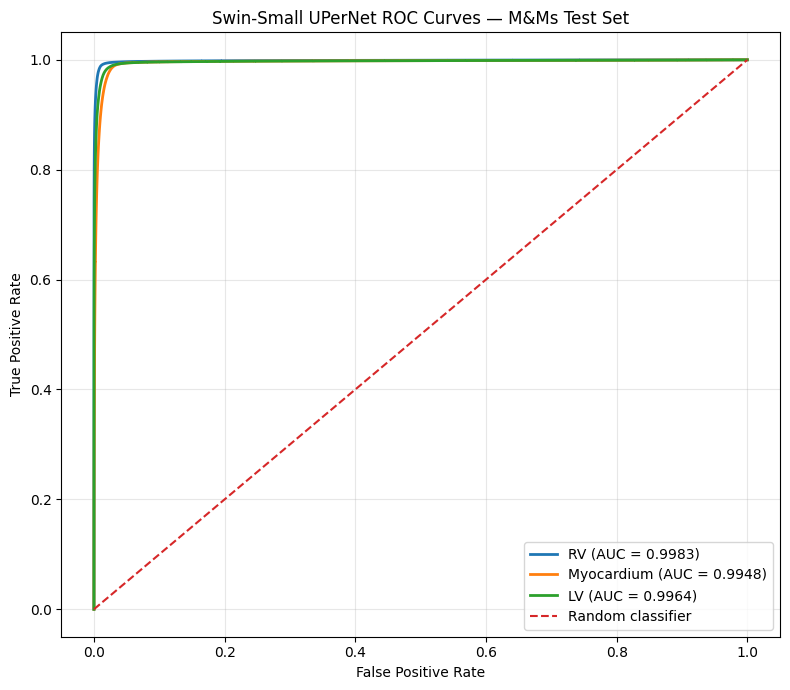


PER-CLASS ROC-AUC
--------------------------------------------------
RV          : 0.9983
Myocardium  : 0.9948
LV          : 0.9964
--------------------------------------------------
MACRO AVG   : 0.9965

Total sampled pixels per class: 5520000

✓ Swin ROC-AUC evaluation complete.


In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S10: ROC-AUC + ROC CURVES

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc

print("=" * 70)
print("SWIN-SMALL UPERNET — ROC-AUC EVALUATION")
print("=" * 70)

swin_model.eval()

# Reproducibility
rng = np.random.default_rng(42)

# Number of pixels sampled from each batch
PIXELS_PER_BATCH = 20000

all_probs = {
    1: [],
    2: [],
    3: []
}

all_targets = {
    1: [],
    2: [],
    3: []
}


with torch.no_grad():

    for images, masks in mnms_test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        # Forward pass
        outputs = swin_model(
            pixel_values=images
        )

        logits = outputs.logits

        if logits.shape[-2:] != masks.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )


        # Move to CPU
        probs_cpu = (
            probabilities
            .detach()
            .cpu()
            .numpy()
        )

        masks_cpu = (
            masks
            .detach()
            .cpu()
            .numpy()
        )


        # Flatten pixels
        masks_flat = masks_cpu.reshape(-1)

        total_pixels = masks_flat.shape[0]

        sample_size = min(
            PIXELS_PER_BATCH,
            total_pixels
        )

        sampled_indices = rng.choice(
            total_pixels,
            size=sample_size,
            replace=False
        )


        # One-vs-rest data for each foreground class
        for class_id in [1, 2, 3]:

            class_probs = (
                probs_cpu[:, class_id, :, :]
                .reshape(-1)
            )

            sampled_probs = class_probs[
                sampled_indices
            ]

            sampled_targets = (
                masks_flat[sampled_indices]
                == class_id
            ).astype(np.uint8)

            all_probs[class_id].append(
                sampled_probs
            )

            all_targets[class_id].append(
                sampled_targets
            )

# CONCATENATE

for class_id in [1, 2, 3]:

    all_probs[class_id] = np.concatenate(
        all_probs[class_id]
    )

    all_targets[class_id] = np.concatenate(
        all_targets[class_id]
    )


# ROC CURVES + AUC

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

roc_results = {}

plt.figure(
    figsize=(8, 7)
)


for class_id in [1, 2, 3]:

    fpr, tpr, thresholds = roc_curve(
        all_targets[class_id],
        all_probs[class_id]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    roc_results[class_id] = class_auc

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{class_names[class_id]} "
            f"(AUC = {class_auc:.4f})"
        )
    )


# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Swin-Small UPerNet ROC Curves — M&Ms Test Set"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


# PRINT RESULTS

macro_auc = float(
    np.mean(
        list(
            roc_results.values()
        )
    )
)


print("\nPER-CLASS ROC-AUC")
print("-" * 50)

for class_id in [1, 2, 3]:

    print(
        f"{class_names[class_id]:12s}: "
        f"{roc_results[class_id]:.4f}"
    )

print("-" * 50)

print(
    f"{'MACRO AVG':12s}: "
    f"{macro_auc:.4f}"
)

print(
    "\nTotal sampled pixels per class:",
    len(all_probs[1])
)

print(
    "\n✓ Swin ROC-AUC evaluation complete."
)

# SSIM + Hausdorff + HD95

In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S11: SSIM + HAUSDORFF + HD95

import torch
import torch.nn.functional as F
import numpy as np

from skimage.metrics import structural_similarity as ssim
from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import distance_transform_edt

print("=" * 70)
print("SWIN-SMALL UPERNET — SSIM + HAUSDORFF + HD95")
print("=" * 70)

swin_model.eval()

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

ssim_scores = {
    1: [],
    2: [],
    3: []
}

hausdorff_scores = {
    1: [],
    2: [],
    3: []
}

hd95_scores = {
    1: [],
    2: [],
    3: []
}


# Hausdorff distance
def calculate_hausdorff(pred_mask, true_mask):

    pred_points = np.argwhere(pred_mask)
    true_points = np.argwhere(true_mask)

    # Skip undefined cases
    if len(pred_points) == 0 or len(true_points) == 0:
        return np.nan

    forward = directed_hausdorff(
        pred_points,
        true_points
    )[0]

    backward = directed_hausdorff(
        true_points,
        pred_points
    )[0]

    return max(forward, backward)

# HD95
def calculate_hd95(pred_mask, true_mask):

    pred_mask = pred_mask.astype(bool)
    true_mask = true_mask.astype(bool)

    if not pred_mask.any() or not true_mask.any():
        return np.nan

    # Distance to nearest foreground pixel
    distance_to_true = distance_transform_edt(
        ~true_mask
    )

    distance_to_pred = distance_transform_edt(
        ~pred_mask
    )

    pred_to_true = distance_to_true[
        pred_mask
    ]

    true_to_pred = distance_to_pred[
        true_mask
    ]

    all_distances = np.concatenate([
        pred_to_true,
        true_to_pred
    ])

    return np.percentile(
        all_distances,
        95
    )


# TEST LOOP

with torch.no_grad():

    for images, masks in mnms_test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        outputs = swin_model(
            pixel_values=images
        )

        logits = outputs.logits

        if logits.shape[-2:] != masks.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        predictions = (
            predictions
            .cpu()
            .numpy()
        )

        masks_np = (
            masks
            .cpu()
            .numpy()
        )


        # Per slice
        for i in range(
            predictions.shape[0]
        ):

            pred_slice = predictions[i]
            true_slice = masks_np[i]

            for class_id in [1, 2, 3]:

                pred_binary = (
                    pred_slice == class_id
                ).astype(np.uint8)

                true_binary = (
                    true_slice == class_id
                ).astype(np.uint8)


                # SSIM
                class_ssim = ssim(
                    true_binary,
                    pred_binary,
                    data_range=1
                )

                ssim_scores[class_id].append(
                    class_ssim
                )


                # Hausdorff
                hd = calculate_hausdorff(
                    pred_binary,
                    true_binary
                )

                if not np.isnan(hd):

                    hausdorff_scores[
                        class_id
                    ].append(hd)


                # HD95
                hd95 = calculate_hd95(
                    pred_binary,
                    true_binary
                )

                if not np.isnan(hd95):

                    hd95_scores[
                        class_id
                    ].append(hd95)


# RESULTS

final_ssim = {}
final_hd = {}
final_hd95 = {}


print("\nPER-CLASS RESULTS")
print("-" * 70)


for class_id in [1, 2, 3]:

    final_ssim[class_id] = float(
        np.mean(
            ssim_scores[class_id]
        )
    )

    final_hd[class_id] = float(
        np.mean(
            hausdorff_scores[class_id]
        )
    )

    final_hd95[class_id] = float(
        np.mean(
            hd95_scores[class_id]
        )
    )

    print(
        f"{class_names[class_id]:12s} | "
        f"SSIM: {final_ssim[class_id]:.4f} | "
        f"Hausdorff: {final_hd[class_id]:.4f} | "
        f"HD95: {final_hd95[class_id]:.4f}"
    )


macro_ssim = float(
    np.mean(
        list(final_ssim.values())
    )
)

macro_hd = float(
    np.mean(
        list(final_hd.values())
    )
)

macro_hd95 = float(
    np.mean(
        list(final_hd95.values())
    )
)


print("-" * 70)

print(
    f"{'MACRO AVG':12s} | "
    f"SSIM: {macro_ssim:.4f} | "
    f"Hausdorff: {macro_hd:.4f} | "
    f"HD95: {macro_hd95:.4f}"
)

print("=" * 70)

print(
    "\nNOTE: Hausdorff and HD95 are measured in pixels "
    "on the resized 224×224 masks."
)

print(
    "\n✓ Swin spatial-metric evaluation complete."
)

SWIN-SMALL UPERNET — SSIM + HAUSDORFF + HD95

PER-CLASS RESULTS
----------------------------------------------------------------------
RV           | SSIM: 0.9797 | Hausdorff: 4.7636 | HD95: 1.4317
Myocardium   | SSIM: 0.9550 | Hausdorff: 5.6975 | HD95: 2.2680
LV           | SSIM: 0.9759 | Hausdorff: 7.7264 | HD95: 2.9975
----------------------------------------------------------------------
MACRO AVG    | SSIM: 0.9702 | Hausdorff: 6.0625 | HD95: 2.2324

NOTE: Hausdorff and HD95 are measured in pixels on the resized 224×224 masks.

✓ Swin spatial-metric evaluation complete.


# Swin Qualitative Visualization

SWIN-SMALL UPERNET — QUALITATIVE VISUALIZATION

Selected slices: 3


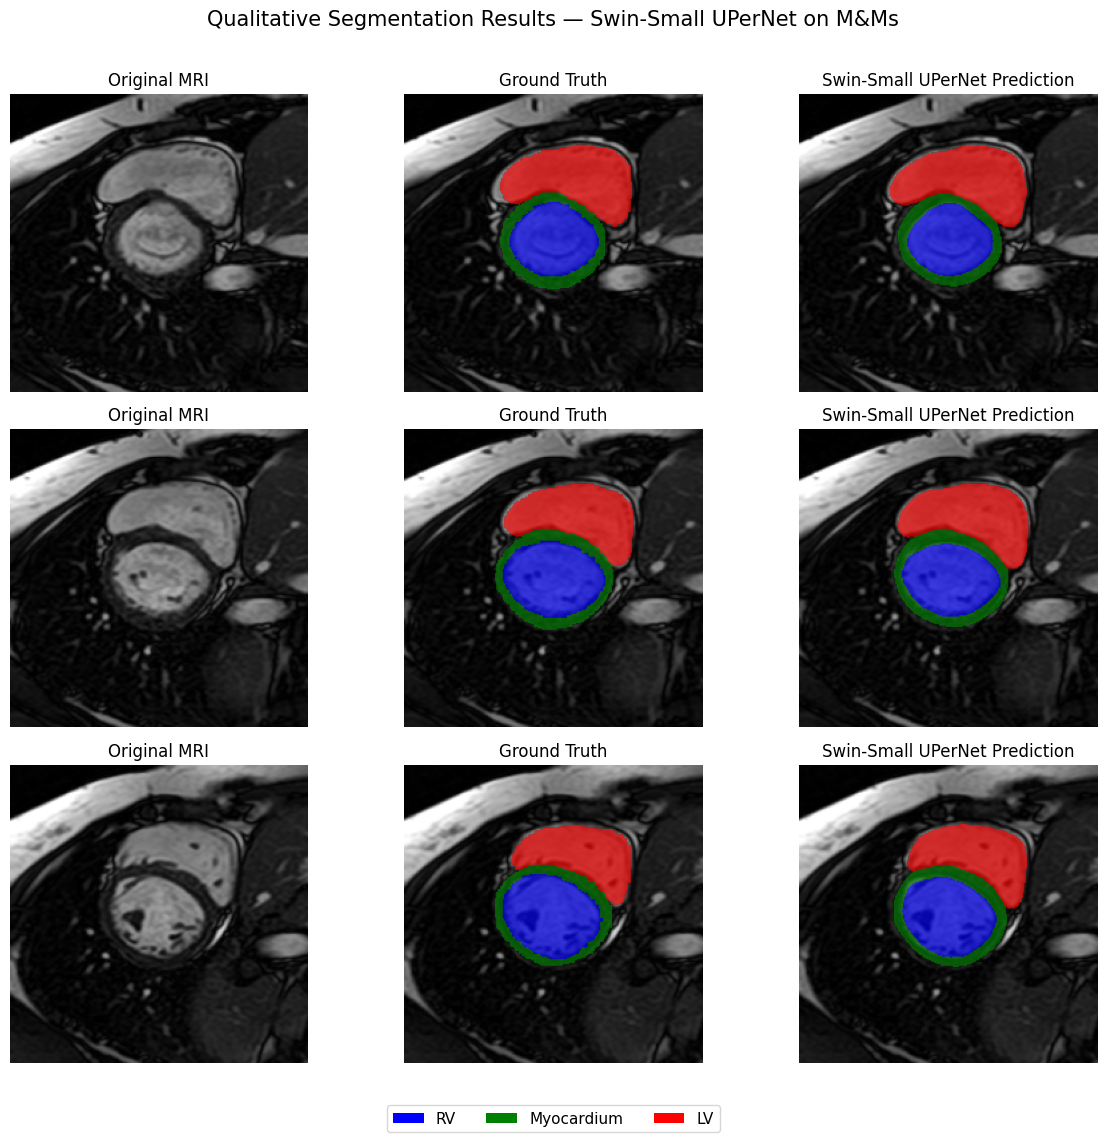


✓ Swin qualitative visualization complete.


In [ ]:
# M&Ms EXPERIMENT 2 — SWIN-SMALL UPERNET
# STEP S12: QUALITATIVE VISUALIZATION

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

print("=" * 70)
print("SWIN-SMALL UPERNET — QUALITATIVE VISUALIZATION")
print("=" * 70)

swin_model.eval()


# Colors
# 0 = Background
# 1 = RV
# 2 = Myocardium
# 3 = LV

seg_cmap = ListedColormap([
    "black",
    "blue",
    "green",
    "red"
])

legend_elements = [
    Patch(facecolor="blue", label="RV"),
    Patch(facecolor="green", label="Myocardium"),
    Patch(facecolor="red", label="LV")
]


# ImageNet normalization values
# Used to convert images back for visualization

mean = np.array([
    0.485,
    0.456,
    0.406
])

std = np.array([
    0.229,
    0.224,
    0.225
])


selected_images = []
selected_masks = []
selected_predictions = []


# FIND 3 SLICES CONTAINING ALL FOREGROUND CLASSES

with torch.no_grad():

    for images, masks in mnms_test_loader:

        images_gpu = images.to(
            device,
            non_blocking=True
        )

        masks_gpu = masks.to(
            device,
            non_blocking=True
        )

        outputs = swin_model(
            pixel_values=images_gpu
        )

        logits = outputs.logits

        if logits.shape[-2:] != masks_gpu.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=masks_gpu.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        # Check each slice

        for i in range(images.shape[0]):

            unique_labels = torch.unique(
                masks[i]
            ).tolist()

            # Must contain:
            # 1 = RV
            # 2 = Myocardium
            # 3 = LV
            if all(
                class_id in unique_labels
                for class_id in [1, 2, 3]
            ):

                selected_images.append(
                    images[i].cpu()
                )

                selected_masks.append(
                    masks[i].cpu().numpy()
                )

                selected_predictions.append(
                    predictions[i]
                    .cpu()
                    .numpy()
                )


            if len(selected_images) == 3:
                break


        if len(selected_images) == 3:
            break


print(
    f"\nSelected slices: "
    f"{len(selected_images)}"
)


# PLOT

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)


for row in range(3):


    # Restore MRI from ImageNet normalization

    image = (
        selected_images[row]
        .permute(1, 2, 0)
        .numpy()
    )

    image = (
        image * std + mean
    )

    image = np.clip(
        image,
        0,
        1
    )

    # MRI is grayscale repeated across 3 channels
    image_gray = image[:, :, 0]


    gt = selected_masks[row]

    pred = selected_predictions[row]


    # Original MRI

    axes[row, 0].imshow(
        image_gray,
        cmap="gray"
    )

    axes[row, 0].set_title(
        "Original MRI"
    )

    axes[row, 0].axis("off")


    # Ground Truth

    axes[row, 1].imshow(
        image_gray,
        cmap="gray"
    )

    gt_overlay = np.ma.masked_where(
        gt == 0,
        gt
    )

    axes[row, 1].imshow(
        gt_overlay,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        alpha=0.65
    )

    axes[row, 1].set_title(
        "Ground Truth"
    )

    axes[row, 1].axis("off")


    # Swin Prediction

    axes[row, 2].imshow(
        image_gray,
        cmap="gray"
    )

    pred_overlay = np.ma.masked_where(
        pred == 0,
        pred
    )

    axes[row, 2].imshow(
        pred_overlay,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        alpha=0.65
    )

    axes[row, 2].set_title(
        "Swin-Small UPerNet Prediction"
    )

    axes[row, 2].axis("off")


# Legend

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=11
)

plt.suptitle(
    "Qualitative Segmentation Results — "
    "Swin-Small UPerNet on M&Ms",
    fontsize=15,
    y=0.94
)

plt.tight_layout(
    rect=[0, 0.05, 1, 0.93]
)

plt.show()

print(
    "\n✓ Swin qualitative visualization complete."
)

# Check the GraphSAGE Environment

In [ ]:

# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G1: ENVIRONMENT CHECK

import torch
import torchvision

print("=" * 70)
print("GRAPHSAGE U-NET — ENVIRONMENT CHECK")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nTesting PyTorch Geometric...")

try:
    import torch_geometric

    from torch_geometric.nn import SAGEConv

    print("PyTorch Geometric:", torch_geometric.__version__)
    print("✓ SAGEConv import successful!")

except Exception as e:

    print("✗ PyTorch Geometric import failed.")
    print("\nError:")
    print(e)

GRAPHSAGE U-NET — ENVIRONMENT CHECK
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4

Testing PyTorch Geometric...
✗ PyTorch Geometric import failed.

Error:
No module named 'torch_geometric'


In [ ]:
# M&Ms EXPERIMENT 3 — GRAPHSAGE
# STEP G1.1: INSTALL PYTORCH GEOMETRIC

!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.4 MB/s eta 0:00:00


In [ ]:
# STEP G1.2: VERIFY PYTORCH GEOMETRIC

import torch_geometric
from torch_geometric.nn import SAGEConv

print("=" * 60)
print("PYTORCH GEOMETRIC CHECK")
print("=" * 60)

print("PyTorch Geometric:", torch_geometric.__version__)
print("✓ SAGEConv import successful!")

# Tiny GPU test
conv = SAGEConv(16, 32).to(device)

x = torch.randn(
    10, 16,
    device=device
)

edge_index = torch.tensor(
    [
        [0,1,2,3,4,5,6,7,8],
        [1,2,3,4,5,6,7,8,9]
    ],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    y = conv(x, edge_index)

print("GraphSAGE GPU output:", y.shape)
print("Device:", y.device)

print("\n✓ GraphSAGE is working on the GPU.")

PYTORCH GEOMETRIC CHECK
PyTorch Geometric: 2.8.0.post1
✓ SAGEConv import successful!
GraphSAGE GPU output: torch.Size([10, 32])
Device: cuda:0

✓ GraphSAGE is working on the GPU.


# Build ResNet34 + GraphSAGE U-Net

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G2: BUILD MODEL

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import (
    resnet34,
    ResNet34_Weights
)

from torch_geometric.nn import SAGEConv


# DECODER BLOCK

class DecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels + skip_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(
            out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(
            out_channels
        )

        self.relu = nn.ReLU(
            inplace=True
        )


    def forward(
        self,
        x,
        skip
    ):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat(
            [x, skip],
            dim=1
        )

        x = self.relu(
            self.bn1(
                self.conv1(x)
            )
        )

        x = self.relu(
            self.bn2(
                self.conv2(x)
            )
        )

        return x

# RESNET34 + GRAPHSAGE U-NET

class ResNet34GraphSAGEUNet(nn.Module):

    def __init__(
        self,
        num_classes=4,
        num_gnn_layers=4
    ):
        super().__init__()

        # PRETRAINED RESNET34

        backbone = resnet34(
            weights=ResNet34_Weights.DEFAULT
        )

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu
        )

        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1   # 64
        self.layer2 = backbone.layer2   # 128
        self.layer3 = backbone.layer3   # 256
        self.layer4 = backbone.layer4   # 512


        # CNN BOTTLENECK

        self.bottleneck = nn.Sequential(

            nn.Conv2d(
                512,
                512,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(512),

            nn.ReLU(inplace=True)
        )


        # GRAPHSAGE

        self.gnn_layers = nn.ModuleList([
            SAGEConv(
                512,
                512
            )
            for _ in range(num_gnn_layers)
        ])

        self.gnn_norms = nn.ModuleList([
            nn.LayerNorm(512)
            for _ in range(num_gnn_layers)
        ])


        # GRAPH REFINEMENT

        self.graph_refine = nn.Sequential(

            nn.Conv2d(
                512,
                512,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(512),

            nn.ReLU(inplace=True)
        )


        # U-NET DECODER

        self.decoder4 = DecoderBlock(
            512,
            256,
            256
        )

        self.decoder3 = DecoderBlock(
            256,
            128,
            128
        )

        self.decoder2 = DecoderBlock(
            128,
            64,
            64
        )

        self.decoder1 = DecoderBlock(
            64,
            64,
            64
        )


        # SEGMENTATION HEAD

        self.segmentation_head = nn.Conv2d(
            64,
            num_classes,
            kernel_size=1
        )


    # BUILD 4-NEIGHBOR GRID GRAPH

    def build_grid_edge_index(
        self,
        height,
        width,
        device
    ):

        edges = []

        for r in range(height):

            for c in range(width):

                node = (
                    r * width + c
                )

                # Right
                if c + 1 < width:

                    right = (
                        r * width + (c + 1)
                    )

                    edges.append(
                        [node, right]
                    )

                    edges.append(
                        [right, node]
                    )

                # Down
                if r + 1 < height:

                    down = (
                        (r + 1) * width + c
                    )

                    edges.append(
                        [node, down]
                    )

                    edges.append(
                        [down, node]
                    )


        edge_index = torch.tensor(
            edges,
            dtype=torch.long,
            device=device
        ).t().contiguous()

        return edge_index


    # FORWARD

    def forward(self, x):

        input_size = x.shape[-2:]

        # RESNET ENCODER

        x0 = self.stem(x)          # 112 × 112

        x1 = self.maxpool(x0)
        x1 = self.layer1(x1)       # 56 × 56

        x2 = self.layer2(x1)       # 28 × 28
        x3 = self.layer3(x2)       # 14 × 14
        x4 = self.layer4(x3)       # 7 × 7


        # CNN BOTTLENECK

        x4 = self.bottleneck(x4)

        batch_size, channels, height, width = (
            x4.shape
        )

        # 7×7 FEATURE MAP -> GRAPH
        #
        # Each spatial location becomes one node.
        # 49 nodes per MRI slice.

        edge_index = self.build_grid_edge_index(
            height,
            width,
            x4.device
        )


        graph_outputs = []


        # Process each image independently
        for b in range(batch_size):

            nodes = (
                x4[b]
                .permute(1, 2, 0)
                .reshape(
                    height * width,
                    channels
                )
            )


            # GRAPH SAGE + RESIDUAL CONNECTIONS

            for gnn, norm in zip(
                self.gnn_layers,
                self.gnn_norms
            ):

                residual = nodes

                nodes = gnn(
                    nodes,
                    edge_index
                )

                nodes = norm(
                    nodes
                )

                nodes = F.gelu(
                    nodes
                )

                nodes = (
                    nodes +
                    residual
                )


            graph_map = (
                nodes
                .reshape(
                    height,
                    width,
                    channels
                )
                .permute(
                    2,
                    0,
                    1
                )
            )

            graph_outputs.append(
                graph_map
            )


        graph_features = torch.stack(
            graph_outputs,
            dim=0
        )


        # GRAPH REFINEMENT

        graph_features = (
            self.graph_refine(
                graph_features
            )
        )


        # DECODER

        d4 = self.decoder4(
            graph_features,
            x3
        )

        d3 = self.decoder3(
            d4,
            x2
        )

        d2 = self.decoder2(
            d3,
            x1
        )

        d1 = self.decoder1(
            d2,
            x0
        )


        # SEGMENTATION HEAD

        logits = self.segmentation_head(
            d1
        )

        logits = F.interpolate(
            logits,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return logits


# CREATE FRESH M&Ms MODEL

graphsage_model = ResNet34GraphSAGEUNet(
    num_classes=4,
    num_gnn_layers=4
).to(device)


# PARAMETER COUNT

total_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
    if p.requires_grad
)


print("=" * 70)
print("RESNET34 + GRAPHSAGE U-NET CREATED")
print("=" * 70)

print(
    f"Total parameters:     "
    f"{total_params:,}"
)

print(
    f"Trainable parameters: "
    f"{trainable_params:,}"
)

print("\nPretrained component:")
print("✓ ResNet34 ImageNet encoder")

print("\nNewly initialized components:")
print("✓ GraphSAGE layers")
print("✓ Graph refinement")
print("✓ U-Net decoder")
print("✓ 4-class segmentation head")

print("\nClass mapping:")
print("0 = Background")
print("1 = RV")
print("2 = Myocardium")
print("3 = LV")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 220MB/s]


RESNET34 + GRAPHSAGE U-NET CREATED
Total parameters:     31,318,084
Trainable parameters: 31,318,084

Pretrained component:
✓ ResNet34 ImageNet encoder

Newly initialized components:
✓ GraphSAGE layers
✓ Graph refinement
✓ U-Net decoder
✓ 4-class segmentation head

Class mapping:
0 = Background
1 = RV
2 = Myocardium
3 = LV


In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G3: ONE-BATCH FORWARD PASS

import torch

print("=" * 70)
print("GRAPHSAGE U-NET — FORWARD PASS TEST")
print("=" * 70)

# Get one training batch
images, masks = next(iter(mnms_train_loader))

print("\nInput images:", images.shape)
print("Masks:", masks.shape)
print("Mask labels:", torch.unique(masks).tolist())

images = images.to(
    device,
    non_blocking=True
)

masks = masks.to(
    device,
    non_blocking=True
)

graphsage_model.eval()

with torch.no_grad():

    logits = graphsage_model(
        images
    )

print("\nModel output:")
print(logits.shape)

predictions = torch.argmax(
    logits,
    dim=1
)

print("\nPrediction shape:")
print(predictions.shape)

print(
    "Predicted labels:",
    torch.unique(predictions).tolist()
)

print("\nExpected model output:")
print(
    f"[{images.shape[0]}, 4, "
    f"{masks.shape[-2]}, {masks.shape[-1]}]"
)

print("\n✓ GraphSAGE forward pass successful.")

GRAPHSAGE U-NET — FORWARD PASS TEST

Input images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])
Mask labels: [0, 1, 2, 3]

Model output:
torch.Size([8, 4, 224, 224])

Prediction shape:
torch.Size([8, 224, 224])
Predicted labels: [1]

Expected model output:
[8, 4, 224, 224]

✓ GraphSAGE forward pass successful.


# GraphSAGE Loss Function

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G4: LOSS FUNCTION

import torch
import torch.nn.functional as F


def graphsage_dice_loss(
    logits,
    targets,
    num_classes=4,
    smooth=1e-6
):

    probabilities = torch.softmax(
        logits,
        dim=1
    )

    targets_one_hot = F.one_hot(
        targets,
        num_classes=num_classes
    )

    targets_one_hot = (
        targets_one_hot
        .permute(0, 3, 1, 2)
        .float()
    )

    dice_losses = []

    # Foreground classes only:
    # 1 = RV
    # 2 = Myocardium
    # 3 = LV
    for class_id in range(1, num_classes):

        pred = probabilities[:, class_id]
        true = targets_one_hot[:, class_id]

        intersection = (
            pred * true
        ).sum(dim=(1, 2))

        denominator = (
            pred.sum(dim=(1, 2)) +
            true.sum(dim=(1, 2))
        )

        dice = (
            (2.0 * intersection + smooth) /
            (denominator + smooth)
        )

        dice_losses.append(
            1.0 - dice.mean()
        )

    return torch.stack(
        dice_losses
    ).mean()


def graphsage_combined_loss(
    logits,
    targets
):

    ce_loss = F.cross_entropy(
        logits,
        targets
    )

    dice_loss = graphsage_dice_loss(
        logits,
        targets
    )

    total_loss = (
        0.5 * ce_loss +
        0.5 * dice_loss
    )

    return total_loss


print("✓ GraphSAGE loss function ready.")
print(
    "Loss = 0.5 × Cross-Entropy "
    "+ 0.5 × Foreground Dice"
)

✓ GraphSAGE loss function ready.
Loss = 0.5 × Cross-Entropy + 0.5 × Foreground Dice


# Optimizer + LR Scheduler

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G5: OPTIMIZER + LR SCHEDULER

import torch


# 1. PRETRAINED RESNET34 PARAMETERS

encoder_params = (
    list(graphsage_model.stem.parameters()) +
    list(graphsage_model.layer1.parameters()) +
    list(graphsage_model.layer2.parameters()) +
    list(graphsage_model.layer3.parameters()) +
    list(graphsage_model.layer4.parameters())
)


# 2. NEWLY INITIALIZED PARAMETERS

new_params = (
    list(graphsage_model.bottleneck.parameters()) +
    list(graphsage_model.gnn_layers.parameters()) +
    list(graphsage_model.gnn_norms.parameters()) +
    list(graphsage_model.graph_refine.parameters()) +
    list(graphsage_model.decoder4.parameters()) +
    list(graphsage_model.decoder3.parameters()) +
    list(graphsage_model.decoder2.parameters()) +
    list(graphsage_model.decoder1.parameters()) +
    list(graphsage_model.segmentation_head.parameters())
)


# 3. VERIFY PARAMETER GROUPS

encoder_param_count = sum(
    p.numel() for p in encoder_params
)

new_param_count = sum(
    p.numel() for p in new_params
)

total_grouped_params = (
    encoder_param_count +
    new_param_count
)

model_param_count = sum(
    p.numel()
    for p in graphsage_model.parameters()
)


print("=" * 70)
print("PARAMETER GROUP CHECK")
print("=" * 70)

print(
    f"Pretrained encoder parameters: "
    f"{encoder_param_count:,}"
)

print(
    f"New component parameters:      "
    f"{new_param_count:,}"
)

print(
    f"Total grouped parameters:      "
    f"{total_grouped_params:,}"
)

print(
    f"Total model parameters:        "
    f"{model_param_count:,}"
)


if total_grouped_params == model_param_count:
    print("\n✓ Every model parameter is included in the optimizer.")
else:
    print("\n⚠ WARNING: Parameter counts do not match!")


# 4. OPTIMIZER

optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": 2e-5
        },
        {
            "params": new_params,
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


# 5. LEARNING-RATE SCHEDULER

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=8,
    min_lr=1e-6
)


print("\n" + "=" * 70)
print("OPTIMIZER + SCHEDULER READY")
print("=" * 70)

print(
    f"Encoder LR: "
    f"{optimizer.param_groups[0]['lr']:.1e}"
)

print(
    f"GraphSAGE/Decoder LR: "
    f"{optimizer.param_groups[1]['lr']:.1e}"
)

print("Weight decay: 1e-4")
print("Scheduler: ReduceLROnPlateau")
print("Scheduler patience: 8 epochs")
print("Scheduler factor: 0.5")
print("Minimum LR: 1e-6")

PARAMETER GROUP CHECK
Pretrained encoder parameters: 21,284,672
New component parameters:      10,033,412
Total grouped parameters:      31,318,084
Total model parameters:        31,318,084

✓ Every model parameter is included in the optimizer.

OPTIMIZER + SCHEDULER READY
Encoder LR: 2.0e-05
GraphSAGE/Decoder LR: 1.0e-04
Weight decay: 1e-4
Scheduler: ReduceLROnPlateau
Scheduler patience: 8 epochs
Scheduler factor: 0.5
Minimum LR: 1e-6


# Google Drive Checkpoints

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G6: GOOGLE DRIVE CHECKPOINT SETUP

import os

from google.colab import drive


# 1. MOUNT GOOGLE DRIVE

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")
else:
    print("✓ Google Drive already mounted.")


# 2. CHECKPOINT DIRECTORY

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/Thesis_Checkpoints"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)


# 3. GRAPHSAGE-SPECIFIC PATHS

GRAPH_BEST_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_graphsage_unet_mnms.pth"
)

GRAPH_LATEST_PATH = os.path.join(
    CHECKPOINT_DIR,
    "latest_graphsage_unet_mnms.pth"
)


# 4. DISPLAY PATHS

print("=" * 70)
print("GRAPHSAGE CHECKPOINT SETUP")
print("=" * 70)

print("\nCheckpoint directory:")
print(CHECKPOINT_DIR)

print("\nBest GraphSAGE checkpoint:")
print(GRAPH_BEST_PATH)

print("\nLatest GraphSAGE checkpoint:")
print(GRAPH_LATEST_PATH)


# 5. PROTECT PREVIOUS EXPERIMENTS

RESNET_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_resnet34_unet_mnms.pth"
)

SWIN_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_swin_upernet_mnms.pth"
)

print("\n" + "=" * 70)
print("PREVIOUS MODEL CHECK")
print("=" * 70)

print(
    "ResNet34 checkpoint:",
    "✓ SAFE" if os.path.exists(RESNET_PATH)
    else "⚠ NOT FOUND"
)

print(
    "Swin checkpoint:",
    "✓ SAFE" if os.path.exists(SWIN_PATH)
    else "⚠ NOT FOUND"
)

print("\n✓ GraphSAGE will use separate checkpoint files.")

✓ Google Drive already mounted.
GRAPHSAGE CHECKPOINT SETUP

Checkpoint directory:
/content/drive/MyDrive/Thesis_Checkpoints

Best GraphSAGE checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_graphsage_unet_mnms.pth

Latest GraphSAGE checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/latest_graphsage_unet_mnms.pth

PREVIOUS MODEL CHECK
ResNet34 checkpoint: ✓ SAFE
Swin checkpoint: ✓ SAFE

✓ GraphSAGE will use separate checkpoint files.


# One-Batch Training

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G7: ONE-BATCH TRAINING SANITY CHECK

import torch

print("=" * 70)
print("GRAPHSAGE — ONE-BATCH TRAINING TEST")
print("=" * 70)

# GET ONE TRAINING BATCH

images, masks = next(iter(mnms_train_loader))

images = images.to(
    device,
    non_blocking=True
)

masks = masks.to(
    device,
    non_blocking=True
)

print("\nImages:", images.shape)
print("Masks: ", masks.shape)


# TRAIN MODE

graphsage_model.train()

optimizer.zero_grad(
    set_to_none=True
)


# FORWARD PASS

logits = graphsage_model(
    images
)

loss = graphsage_combined_loss(
    logits,
    masks
)

print(
    f"\nLoss before backward: "
    f"{loss.item():.6f}"
)


# BACKWARD PASS

loss.backward()

print("✓ Backward pass successful.")


# CHECK GRADIENTS

gradient_count = 0

for parameter in graphsage_model.parameters():

    if parameter.grad is not None:

        if torch.isfinite(
            parameter.grad
        ).all():

            gradient_count += 1


print(
    f"Parameters with finite gradients: "
    f"{gradient_count}"
)

if gradient_count > 0:
    print("✓ Finite gradients detected.")
else:
    print("⚠ No valid gradients detected.")


# OPTIMIZER STEP

optimizer.step()

print("✓ Optimizer step successful.")


# GPU MEMORY

if torch.cuda.is_available():

    allocated = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    reserved = (
        torch.cuda.memory_reserved()
        / 1024**3
    )

    print(
        f"\nGPU memory allocated: "
        f"{allocated:.2f} GB"
    )

    print(
        f"GPU memory reserved:  "
        f"{reserved:.2f} GB"
    )


print("\n" + "=" * 70)
print("✓ ONE-BATCH TRAINING TEST COMPLETE")
print("=" * 70)

GRAPHSAGE — ONE-BATCH TRAINING TEST

Images: torch.Size([8, 3, 224, 224])
Masks:  torch.Size([8, 224, 224])

Loss before backward: 1.191825
✓ Backward pass successful.
Parameters with finite gradients: 160
✓ Finite gradients detected.
✓ Optimizer step successful.

GPU memory allocated: 1.83 GB
GPU memory reserved:  5.83 GB

✓ ONE-BATCH TRAINING TEST COMPLETE


In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G8: CLEAN RESET BEFORE REAL TRAINING

import gc
import torch


# 1. DELETE DEBUG MODEL / OPTIMIZER

del graphsage_model
del optimizer
del scheduler

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print("✓ Debug model cleared.")


# 2. CREATE A FRESH MODEL

graphsage_model = ResNet34GraphSAGEUNet(
    num_classes=4,
    num_gnn_layers=4
).to(device)

print("✓ Fresh GraphSAGE model created.")

# 3. REBUILD PARAMETER GROUPS

encoder_params = (
    list(graphsage_model.stem.parameters()) +
    list(graphsage_model.layer1.parameters()) +
    list(graphsage_model.layer2.parameters()) +
    list(graphsage_model.layer3.parameters()) +
    list(graphsage_model.layer4.parameters())
)


new_params = (
    list(graphsage_model.bottleneck.parameters()) +
    list(graphsage_model.gnn_layers.parameters()) +
    list(graphsage_model.gnn_norms.parameters()) +
    list(graphsage_model.graph_refine.parameters()) +
    list(graphsage_model.decoder4.parameters()) +
    list(graphsage_model.decoder3.parameters()) +
    list(graphsage_model.decoder2.parameters()) +
    list(graphsage_model.decoder1.parameters()) +
    list(graphsage_model.segmentation_head.parameters())
)


# 4. FRESH OPTIMIZER

optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": 2e-5
        },
        {
            "params": new_params,
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


# 5. FRESH SCHEDULER

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=8,
    min_lr=1e-6
)


# 6. TRAINING CONFIGURATION

MAX_EPOCHS = 150
EARLY_STOPPING_PATIENCE = 15

best_val_dice = -1.0
best_epoch = 0
epochs_without_improvement = 0


# 7. FINAL CHECK

total_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
)

print("\n" + "=" * 70)
print("CLEAN GRAPHSAGE EXPERIMENT READY")
print("=" * 70)

print(
    f"Total parameters: "
    f"{total_params:,}"
)

print(
    f"Encoder LR: "
    f"{optimizer.param_groups[0]['lr']:.1e}"
)

print(
    f"GraphSAGE/Decoder LR: "
    f"{optimizer.param_groups[1]['lr']:.1e}"
)

print(
    f"Maximum epochs: "
    f"{MAX_EPOCHS}"
)

print(
    f"Early stopping patience: "
    f"{EARLY_STOPPING_PATIENCE}"
)

print(
    f"Best validation Dice: "
    f"{best_val_dice}"
)

print("\nBest checkpoint:")
print(GRAPH_BEST_PATH)

print("\nLatest checkpoint:")
print(GRAPH_LATEST_PATH)

print("\n✓ Ready for real training.")

✓ Debug model cleared.
✓ Fresh GraphSAGE model created.

CLEAN GRAPHSAGE EXPERIMENT READY
Total parameters: 31,318,084
Encoder LR: 2.0e-05
GraphSAGE/Decoder LR: 1.0e-04
Maximum epochs: 150
Early stopping patience: 15
Best validation Dice: -1.0

Best checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_graphsage_unet_mnms.pth

Latest checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/latest_graphsage_unet_mnms.pth

✓ Ready for real training.


# GraphSAGE Training + Validation

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G9: FULL TRAINING + VALIDATION

import os
import time
import torch
import numpy as np


# DICE METRIC

def calculate_class_dice(
    predictions,
    targets,
    class_id,
    smooth=1e-6
):

    pred_class = (
        predictions == class_id
    ).float()

    true_class = (
        targets == class_id
    ).float()

    intersection = (
        pred_class * true_class
    ).sum(dim=(1, 2))

    denominator = (
        pred_class.sum(dim=(1, 2)) +
        true_class.sum(dim=(1, 2))
    )

    dice = (
        (2.0 * intersection + smooth) /
        (denominator + smooth)
    )

    return dice


# VALIDATION FUNCTION

@torch.no_grad()
def validate_graphsage(
    model,
    loader,
    device
):

    model.eval()

    total_loss = 0.0

    rv_scores = []
    myo_scores = []
    lv_scores = []

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits = model(images)

        loss = graphsage_combined_loss(
            logits,
            masks
        )

        total_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        # 1 = RV
        # 2 = Myocardium
        # 3 = LV

        rv = calculate_class_dice(
            predictions,
            masks,
            1
        )

        myo = calculate_class_dice(
            predictions,
            masks,
            2
        )

        lv = calculate_class_dice(
            predictions,
            masks,
            3
        )

        rv_scores.extend(
            rv.cpu().numpy().tolist()
        )

        myo_scores.extend(
            myo.cpu().numpy().tolist()
        )

        lv_scores.extend(
            lv.cpu().numpy().tolist()
        )


    avg_loss = (
        total_loss /
        len(loader.dataset)
    )

    rv_dice = float(
        np.mean(rv_scores)
    )

    myo_dice = float(
        np.mean(myo_scores)
    )

    lv_dice = float(
        np.mean(lv_scores)
    )

    mean_dice = (
        rv_dice +
        myo_dice +
        lv_dice
    ) / 3.0


    return (
        avg_loss,
        rv_dice,
        myo_dice,
        lv_dice,
        mean_dice
    )


# TRAINING HISTORY

history = {
    "train_loss": [],
    "val_loss": [],
    "rv_dice": [],
    "myo_dice": [],
    "lv_dice": [],
    "mean_dice": [],
    "encoder_lr": [],
    "new_lr": []
}


# START TRAINING

print("=" * 78)
print("M&Ms — RESNET34 + GRAPHSAGE U-NET TRAINING")
print("=" * 78)

print(f"Training batches:   {len(mnms_train_loader)}")
print(f"Validation batches: {len(mnms_val_loader)}")

print(f"\nMaximum epochs: {MAX_EPOCHS}")
print(
    f"Early stopping patience: "
    f"{EARLY_STOPPING_PATIENCE}"
)

print("\nTraining started...\n")


for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    # TRAIN

    graphsage_model.train()

    running_train_loss = 0.0


    for images, masks in mnms_train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = graphsage_model(
            images
        )


        loss = graphsage_combined_loss(
            logits,
            masks
        )


        loss.backward()


        # Mild gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(
            graphsage_model.parameters(),
            max_norm=1.0
        )


        optimizer.step()


        running_train_loss += (
            loss.item() *
            images.size(0)
        )


    train_loss = (
        running_train_loss /
        len(mnms_train_loader.dataset)
    )


    # VALIDATE

    (
        val_loss,
        rv_dice,
        myo_dice,
        lv_dice,
        mean_dice

    ) = validate_graphsage(
        graphsage_model,
        mnms_val_loader,
        device
    )


    # LEARNING RATE SCHEDULER

    scheduler.step(
        mean_dice
    )


    encoder_lr = (
        optimizer.param_groups[0]["lr"]
    )

    new_lr = (
        optimizer.param_groups[1]["lr"]
    )

    # SAVE HISTORY

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["rv_dice"].append(
        rv_dice
    )

    history["myo_dice"].append(
        myo_dice
    )

    history["lv_dice"].append(
        lv_dice
    )

    history["mean_dice"].append(
        mean_dice
    )

    history["encoder_lr"].append(
        encoder_lr
    )

    history["new_lr"].append(
        new_lr
    )


    # CHECK FOR IMPROVEMENT

    improved = (
        mean_dice >
        best_val_dice
    )


    if improved:

        best_val_dice = mean_dice
        best_epoch = epoch

        epochs_without_improvement = 0


        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    graphsage_model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "history":
                    history,

                "architecture":
                    "ResNet34 + 4-layer GraphSAGE U-Net",

                "num_classes":
                    4,

                "class_mapping": {
                    0: "Background",
                    1: "RV",
                    2: "Myocardium",
                    3: "LV"
                }
            },

            GRAPH_BEST_PATH
        )

    else:

        epochs_without_improvement += 1


    # SAVE LATEST CHECKPOINT EVERY EPOCH

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                graphsage_model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "best_val_dice":
                best_val_dice,

            "best_epoch":
                best_epoch,

            "epochs_without_improvement":
                epochs_without_improvement,

            "history":
                history
        },

        GRAPH_LATEST_PATH
    )


    # PRINT RESULTS

    epoch_time = (
        time.time() -
        epoch_start
    )


    best_marker = (
        "  ← BEST"
        if improved
        else ""
    )


    print(
        f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
        f"Train {train_loss:.4f} | "
        f"Val {val_loss:.4f} | "
        f"RV {rv_dice:.4f} | "
        f"Myo {myo_dice:.4f} | "
        f"LV {lv_dice:.4f} | "
        f"Mean {mean_dice:.4f} | "
        f"LR {new_lr:.1e} | "
        f"{epoch_time:.1f}s"
        f"{best_marker}"
    )


    # EARLY STOPPING

    if (
        epochs_without_improvement >=
        EARLY_STOPPING_PATIENCE
    ):

        print("\n" + "=" * 78)

        print(
            f"EARLY STOPPING at epoch "
            f"{epoch}"
        )

        print(
            f"Best epoch: "
            f"{best_epoch}"
        )

        print(
            f"Best validation mean Dice: "
            f"{best_val_dice:.4f}"
        )

        print("=" * 78)

        break


# TRAINING COMPLETE

print("\n" + "=" * 78)
print("GRAPHSAGE TRAINING COMPLETE")
print("=" * 78)

print(
    f"Best epoch: "
    f"{best_epoch}"
)

print(
    f"Best validation mean Dice: "
    f"{best_val_dice:.6f}"
)

print("\nBest model saved to:")
print(GRAPH_BEST_PATH)

print("\nLatest model saved to:")
print(GRAPH_LATEST_PATH)

M&Ms — RESNET34 + GRAPHSAGE U-NET TRAINING
Training batches:   297
Validation batches: 72

Maximum epochs: 150
Early stopping patience: 15

Training started...

Epoch 001/150 | Train 0.5598 | Val 0.5368 | RV 0.7522 | Myo 0.5215 | LV 0.1416 | Mean 0.4718 | LR 1.0e-04 | 62.0s  ← BEST
Epoch 002/150 | Train 0.2830 | Val 0.2970 | RV 0.8429 | Myo 0.7380 | LV 0.5838 | Mean 0.7216 | LR 1.0e-04 | 60.0s  ← BEST
Epoch 003/150 | Train 0.1960 | Val 0.3702 | RV 0.6721 | Myo 0.6561 | LV 0.2989 | Mean 0.5423 | LR 1.0e-04 | 58.1s
Epoch 004/150 | Train 0.1635 | Val 0.1656 | RV 0.8918 | Myo 0.8161 | LV 0.7677 | Mean 0.8252 | LR 1.0e-04 | 58.9s  ← BEST
Epoch 005/150 | Train 0.1467 | Val 0.1620 | RV 0.8937 | Myo 0.7963 | LV 0.7753 | Mean 0.8218 | LR 1.0e-04 | 58.4s
Epoch 006/150 | Train 0.1375 | Val 0.1910 | RV 0.8666 | Myo 0.7547 | LV 0.7526 | Mean 0.7913 | LR 1.0e-04 | 58.1s
Epoch 007/150 | Train 0.1301 | Val 0.5445 | RV 0.5248 | Myo 0.3833 | LV 0.2361 | Mean 0.3814 | LR 1.0e-04 | 58.1s
Epoch 008/150 | T

# Load Best GraphSAGE Checkpoint

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G10: LOAD BEST CHECKPOINT

import os
import torch


print("=" * 72)
print("LOADING BEST M&Ms GRAPHSAGE MODEL")
print("=" * 72)

print("\nCheckpoint:")
print(GRAPH_BEST_PATH)


# CHECK FILE EXISTS

assert os.path.exists(
    GRAPH_BEST_PATH
), f"Checkpoint not found: {GRAPH_BEST_PATH}"


# LOAD CHECKPOINT

checkpoint = torch.load(
    GRAPH_BEST_PATH,
    map_location=device,
    weights_only=False
)


# LOAD BEST MODEL WEIGHTS

graphsage_model.load_state_dict(
    checkpoint["model_state_dict"]
)

graphsage_model = graphsage_model.to(
    device
)

graphsage_model.eval()


# DISPLAY INFORMATION

print(
    "\nSaved epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)

print(
    "Architecture:",
    checkpoint.get(
        "architecture",
        "Not stored"
    )
)

print(
    "Number of classes:",
    checkpoint.get(
        "num_classes",
        4
    )
)

print("\nModel mode:")
print(
    "Evaluation"
    if not graphsage_model.training
    else "Training"
)

print("\n✓ Best GraphSAGE checkpoint restored successfully.")

LOADING BEST M&Ms GRAPHSAGE MODEL

Checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_graphsage_unet_mnms.pth

Saved epoch: 69
Best validation Dice: 0.8607986579068081
Architecture: ResNet34 + 4-layer GraphSAGE U-Net
Number of classes: 4

Model mode:
Evaluation

✓ Best GraphSAGE checkpoint restored successfully.


# Test Dice + IoU

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G11: TEST DICE + IoU

import torch
import numpy as np


# PER-CLASS DICE + IoU

def calculate_dice_iou_per_slice(
    predictions,
    targets,
    class_id,
    smooth=1e-6
):

    pred = (
        predictions == class_id
    ).float()

    true = (
        targets == class_id
    ).float()


    # Intersection
    intersection = (
        pred * true
    ).sum(dim=(1, 2))


    # Dice
    pred_sum = pred.sum(
        dim=(1, 2)
    )

    true_sum = true.sum(
        dim=(1, 2)
    )

    dice = (
        2.0 * intersection + smooth
    ) / (
        pred_sum +
        true_sum +
        smooth
    )


    # IoU
    union = (
        pred_sum +
        true_sum -
        intersection
    )

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )


    return dice, iou


# STORAGE

dice_scores = {
    1: [],
    2: [],
    3: []
}

iou_scores = {
    1: [],
    2: [],
    3: []
}


# TEST

graphsage_model.eval()

print("=" * 72)
print("M&Ms GRAPHSAGE — TEST DICE + IoU")
print("=" * 72)

print(
    f"Test slices: "
    f"{len(mnms_test_loader.dataset)}"
)

print(
    f"Test batches: "
    f"{len(mnms_test_loader)}"
)

print("\nEvaluating...")


with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        mnms_test_loader,
        start=1
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        logits = graphsage_model(
            images
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )


        # Foreground classes only
        for class_id in [1, 2, 3]:

            dice, iou = (
                calculate_dice_iou_per_slice(
                    predictions,
                    masks,
                    class_id
                )
            )

            dice_scores[
                class_id
            ].extend(
                dice.cpu().numpy().tolist()
            )

            iou_scores[
                class_id
            ].extend(
                iou.cpu().numpy().tolist()
            )


        if (
            batch_idx % 50 == 0
            or
            batch_idx == len(mnms_test_loader)
        ):

            print(
                f"Processed "
                f"{batch_idx}/"
                f"{len(mnms_test_loader)} "
                f"batches"
            )

# FINAL RESULTS

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


final_dice = {}
final_iou = {}


print("\n" + "=" * 72)
print("FINAL TEST RESULTS")
print("=" * 72)


for class_id in [1, 2, 3]:

    final_dice[class_id] = float(
        np.mean(
            dice_scores[class_id]
        )
    )

    final_iou[class_id] = float(
        np.mean(
            iou_scores[class_id]
        )
    )


    print(
        f"{class_names[class_id]:12s} | "
        f"Dice: "
        f"{final_dice[class_id]:.4f} | "
        f"IoU: "
        f"{final_iou[class_id]:.4f}"
    )


macro_dice = float(
    np.mean(
        list(final_dice.values())
    )
)

macro_iou = float(
    np.mean(
        list(final_iou.values())
    )
)


print("-" * 72)

print(
    f"{'Macro Average':12s} | "
    f"Dice: {macro_dice:.4f} | "
    f"IoU: {macro_iou:.4f}"
)

print("=" * 72)

M&Ms GRAPHSAGE — TEST DICE + IoU
Test slices: 2201
Test batches: 276

Evaluating...
Processed 50/276 batches
Processed 100/276 batches
Processed 150/276 batches
Processed 200/276 batches
Processed 250/276 batches
Processed 276/276 batches

FINAL TEST RESULTS
RV           | Dice: 0.8924 | IoU: 0.8251
Myocardium   | Dice: 0.8182 | IoU: 0.7032
LV           | Dice: 0.7994 | IoU: 0.7336
------------------------------------------------------------------------
Macro Average | Dice: 0.8367 | IoU: 0.7540


# Mount Best Epoch

In [ ]:
# M&Ms GRAPHSAGE
# SAVE / VERIFY FINAL BEST EPOCH IN GOOGLE DRIVE

import os
import shutil
import torch


# PATHS

BEST_PATH = (
    "/content/drive/MyDrive/Thesis_Checkpoints/"
    "best_graphsage_unet_mnms.pth"
)

ARCHIVE_PATH = (
    "/content/drive/MyDrive/Thesis_Checkpoints/"
    "graphsage_unet_mnms_best_epoch69.pth"
)


# VERIFY EXISTING BEST CHECKPOINT

assert os.path.exists(BEST_PATH), (
    f"Best checkpoint not found:\n{BEST_PATH}"
)

checkpoint = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=False
)


print("=" * 72)
print("VERIFYING BEST GRAPHSAGE CHECKPOINT")
print("=" * 72)

print(
    "Saved epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)


# SAFETY CHECK

assert checkpoint["epoch"] == 69, (
    "STOP: The checkpoint is not epoch 69."
)

print("\n✓ Confirmed: this checkpoint contains epoch 69.")


# CREATE PERMANENT ARCHIVAL COPY

shutil.copy2(
    BEST_PATH,
    ARCHIVE_PATH
)


# VERIFY ARCHIVAL COPY

assert os.path.exists(ARCHIVE_PATH)

archive = torch.load(
    ARCHIVE_PATH,
    map_location="cpu",
    weights_only=False
)


file_size_mb = (
    os.path.getsize(ARCHIVE_PATH)
    / (1024 ** 2)
)


print("\n" + "=" * 72)
print("BEST MODEL ARCHIVED TO GOOGLE DRIVE")
print("=" * 72)

print(
    "Epoch:",
    archive["epoch"]
)

print(
    "Validation Dice:",
    archive["best_val_dice"]
)

print(
    f"File size: {file_size_mb:.2f} MB"
)

print("\nPermanent archive:")
print(ARCHIVE_PATH)

print(
    "\n✓ Epoch 69 is safely stored "
    "in Google Drive."
)

VERIFYING BEST GRAPHSAGE CHECKPOINT
Saved epoch: 69
Best validation Dice: 0.8607986579068081

✓ Confirmed: this checkpoint contains epoch 69.

BEST MODEL ARCHIVED TO GOOGLE DRIVE
Epoch: 69
Validation Dice: 0.8607986579068081
File size: 358.73 MB

Permanent archive:
/content/drive/MyDrive/Thesis_Checkpoints/graphsage_unet_mnms_best_epoch69.pth

✓ Epoch 69 is safely stored in Google Drive.


# ROC Curves + ROC-AUC

M&Ms GRAPHSAGE — ROC-AUC
Pixels sampled per batch: 20,000
Random seed: 42

Processed 50/276 batches
Processed 100/276 batches
Processed 150/276 batches
Processed 200/276 batches
Processed 250/276 batches
Processed 276/276 batches

Sampled pixels per class:
RV: 5,520,000
Myocardium: 5,520,000
LV: 5,520,000


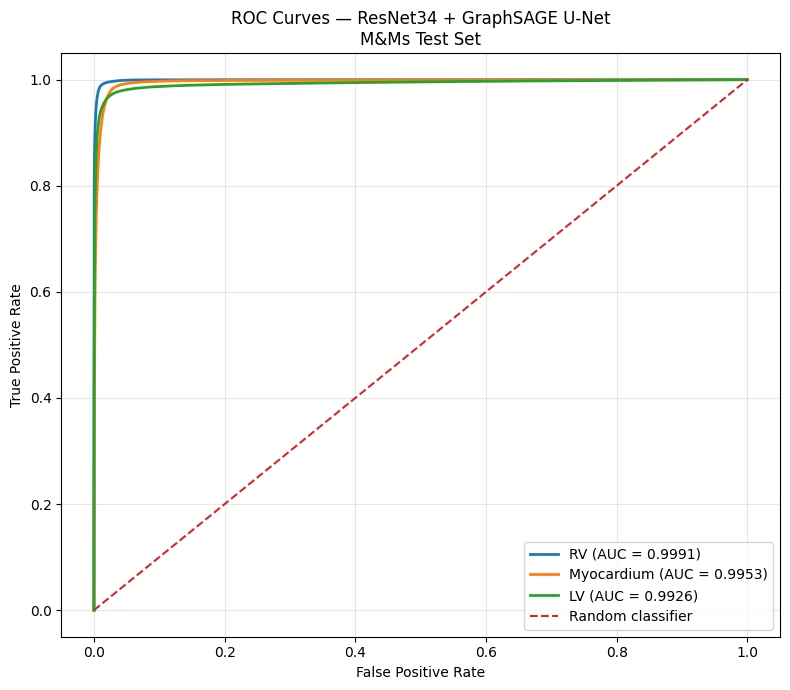


ROC-AUC RESULTS
RV           | AUC: 0.9991
Myocardium   | AUC: 0.9953
LV           | AUC: 0.9926
------------------------------------------------------------------------
Macro Average | AUC: 0.9957


In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G12: ROC CURVES + ROC-AUC

import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc
)


# SETTINGS

PIXELS_PER_BATCH = 20000

rng = np.random.default_rng(
    42
)

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


# STORAGE

y_true = {
    1: [],
    2: [],
    3: []
}

y_score = {
    1: [],
    2: [],
    3: []
}


# COLLECT PROBABILITIES

graphsage_model.eval()

print("=" * 72)
print("M&Ms GRAPHSAGE — ROC-AUC")
print("=" * 72)

print(
    f"Pixels sampled per batch: "
    f"{PIXELS_PER_BATCH:,}"
)

print(
    "Random seed: 42"
)

print("\nCollecting probabilities...")


with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        mnms_test_loader,
        start=1
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        logits = graphsage_model(
            images
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )


        # Move to CPU
        probabilities = (
            probabilities
            .cpu()
            .numpy()
        )

        masks_np = (
            masks
            .cpu()
            .numpy()
        )


        # FLATTEN PIXELS

        batch_size = (
            masks_np.shape[0]
        )

        total_pixels = (
            batch_size *
            masks_np.shape[1] *
            masks_np.shape[2]
        )


        flat_masks = (
            masks_np
            .reshape(-1)
        )


        flat_probs = (
            probabilities
            .transpose(0, 2, 3, 1)
            .reshape(-1, 4)
        )


        # RANDOM PIXEL SAMPLE

        sample_size = min(
            PIXELS_PER_BATCH,
            total_pixels
        )

        indices = rng.choice(
            total_pixels,
            size=sample_size,
            replace=False
        )


        sampled_masks = (
            flat_masks[indices]
        )

        sampled_probs = (
            flat_probs[indices]
        )


        # ONE-VS-REST DATA

        for class_id in [1, 2, 3]:

            class_truth = (
                sampled_masks ==
                class_id
            ).astype(
                np.uint8
            )

            class_scores = (
                sampled_probs[
                    :, class_id
                ]
            )


            y_true[
                class_id
            ].append(
                class_truth
            )

            y_score[
                class_id
            ].append(
                class_scores
            )


        if (
            batch_idx % 50 == 0
            or
            batch_idx ==
            len(mnms_test_loader)
        ):

            print(
                f"Processed "
                f"{batch_idx}/"
                f"{len(mnms_test_loader)} "
                f"batches"
            )


# CONCATENATE

for class_id in [1, 2, 3]:

    y_true[class_id] = np.concatenate(
        y_true[class_id]
    )

    y_score[class_id] = np.concatenate(
        y_score[class_id]
    )


print("\nSampled pixels per class:")

for class_id in [1, 2, 3]:

    print(
        f"{class_names[class_id]}: "
        f"{len(y_true[class_id]):,}"
    )

# ROC CURVES + AUC

roc_results = {}

plt.figure(
    figsize=(8, 7)
)


for class_id in [1, 2, 3]:

    fpr, tpr, _ = roc_curve(
        y_true[class_id],
        y_score[class_id]
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    roc_results[class_id] = (
        roc_auc
    )


    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{class_names[class_id]} "
            f"(AUC = {roc_auc:.4f})"
        )
    )


# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curves — ResNet34 + GraphSAGE U-Net\n"
    "M&Ms Test Set"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# PRINT AUC RESULTS

macro_auc = float(
    np.mean(
        list(
            roc_results.values()
        )
    )
)


print("\n" + "=" * 72)
print("ROC-AUC RESULTS")
print("=" * 72)

for class_id in [1, 2, 3]:

    print(
        f"{class_names[class_id]:12s} | "
        f"AUC: "
        f"{roc_results[class_id]:.4f}"
    )


print("-" * 72)

print(
    f"{'Macro Average':12s} | "
    f"AUC: {macro_auc:.4f}"
)

print("=" * 72)

# SSIM + Hausdorff Distance + HD95.

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G13: SSIM + HAUSDORFF DISTANCE + HD95

import torch
import numpy as np

from skimage.metrics import structural_similarity as ssim
from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import distance_transform_edt


# SETTINGS

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

ssim_scores = {
    1: [],
    2: [],
    3: []
}

hausdorff_scores = {
    1: [],
    2: [],
    3: []
}

hd95_scores = {
    1: [],
    2: [],
    3: []
}


# HAUSDORFF DISTANCE

def calculate_hausdorff(pred_mask, true_mask):

    pred_points = np.argwhere(pred_mask)
    true_points = np.argwhere(true_mask)

    # Ignore cases where one or both masks are empty.
    if (
        len(pred_points) == 0
        or
        len(true_points) == 0
    ):
        return np.nan

    forward = directed_hausdorff(
        pred_points,
        true_points
    )[0]

    backward = directed_hausdorff(
        true_points,
        pred_points
    )[0]

    return max(
        forward,
        backward
    )


# HD95

def calculate_hd95(pred_mask, true_mask):

    pred_mask = pred_mask.astype(bool)
    true_mask = true_mask.astype(bool)

    if (
        pred_mask.sum() == 0
        or
        true_mask.sum() == 0
    ):
        return np.nan


    # Distance to nearest foreground pixel
    distance_to_true = distance_transform_edt(
        ~true_mask
    )

    distance_to_pred = distance_transform_edt(
        ~pred_mask
    )


    # Distances from predicted foreground → true foreground
    pred_to_true = distance_to_true[
        pred_mask
    ]

    # Distances from true foreground → predicted foreground
    true_to_pred = distance_to_pred[
        true_mask
    ]


    all_distances = np.concatenate([
        pred_to_true,
        true_to_pred
    ])


    return np.percentile(
        all_distances,
        95
    )


# EVALUATION

graphsage_model.eval()

print("=" * 72)
print("M&Ms GRAPHSAGE — SSIM + HAUSDORFF + HD95")
print("=" * 72)

print(
    f"Test slices: "
    f"{len(mnms_test_loader.dataset)}"
)

print("\nEvaluating...")


with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        mnms_test_loader,
        start=1
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        logits = graphsage_model(
            images
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )


        predictions_np = (
            predictions
            .cpu()
            .numpy()
        )

        masks_np = (
            masks
            .cpu()
            .numpy()
        )


        # EACH IMAGE IN BATCH

        for sample_idx in range(
            predictions_np.shape[0]
        ):

            pred_sample = predictions_np[
                sample_idx
            ]

            true_sample = masks_np[
                sample_idx
            ]


            # EACH FOREGROUND CLASS

            for class_id in [1, 2, 3]:

                pred_binary = (
                    pred_sample == class_id
                ).astype(
                    np.uint8
                )

                true_binary = (
                    true_sample == class_id
                ).astype(
                    np.uint8
                )


                # SSIM

                class_ssim = ssim(
                    true_binary,
                    pred_binary,
                    data_range=1
                )

                ssim_scores[
                    class_id
                ].append(
                    class_ssim
                )


                # HAUSDORFF

                hd = calculate_hausdorff(
                    pred_binary,
                    true_binary
                )

                if not np.isnan(hd):

                    hausdorff_scores[
                        class_id
                    ].append(
                        hd
                    )

                # HD95

                hd95 = calculate_hd95(
                    pred_binary,
                    true_binary
                )

                if not np.isnan(hd95):

                    hd95_scores[
                        class_id
                    ].append(
                        hd95
                    )


        if (
            batch_idx % 50 == 0
            or
            batch_idx ==
            len(mnms_test_loader)
        ):

            print(
                f"Processed "
                f"{batch_idx}/"
                f"{len(mnms_test_loader)} "
                f"batches"
            )

# FINAL RESULTS

final_ssim = {}
final_hd = {}
final_hd95 = {}


print("\n" + "=" * 72)
print("FINAL TEST RESULTS")
print("=" * 72)


for class_id in [1, 2, 3]:

    final_ssim[class_id] = float(
        np.mean(
            ssim_scores[class_id]
        )
    )

    final_hd[class_id] = float(
        np.mean(
            hausdorff_scores[class_id]
        )
    )

    final_hd95[class_id] = float(
        np.mean(
            hd95_scores[class_id]
        )
    )


    print(
        f"{class_names[class_id]:12s} | "
        f"SSIM: {final_ssim[class_id]:.4f} | "
        f"Hausdorff: {final_hd[class_id]:.4f} | "
        f"HD95: {final_hd95[class_id]:.4f}"
    )


# MACRO AVERAGES

macro_ssim = float(
    np.mean(
        list(final_ssim.values())
    )
)

macro_hd = float(
    np.mean(
        list(final_hd.values())
    )
)

macro_hd95 = float(
    np.mean(
        list(final_hd95.values())
    )
)


print("-" * 72)

print(
    f"{'Macro Average':12s} | "
    f"SSIM: {macro_ssim:.4f} | "
    f"Hausdorff: {macro_hd:.4f} | "
    f"HD95: {macro_hd95:.4f}"
)

print("=" * 72)

M&Ms GRAPHSAGE — SSIM + HAUSDORFF + HD95
Test slices: 2201

Evaluating...
Processed 50/276 batches
Processed 100/276 batches
Processed 150/276 batches
Processed 200/276 batches
Processed 250/276 batches
Processed 276/276 batches

FINAL TEST RESULTS
RV           | SSIM: 0.9800 | Hausdorff: 4.7810 | HD95: 1.4725
Myocardium   | SSIM: 0.9550 | Hausdorff: 5.7527 | HD95: 2.2511
LV           | SSIM: 0.9755 | Hausdorff: 8.4673 | HD95: 3.5221
------------------------------------------------------------------------
Macro Average | SSIM: 0.9701 | Hausdorff: 6.3336 | HD95: 2.4152


# GraphSAGE Qualitative Visualization.

Selected 3 test slices containing RV, Myocardium, and LV.


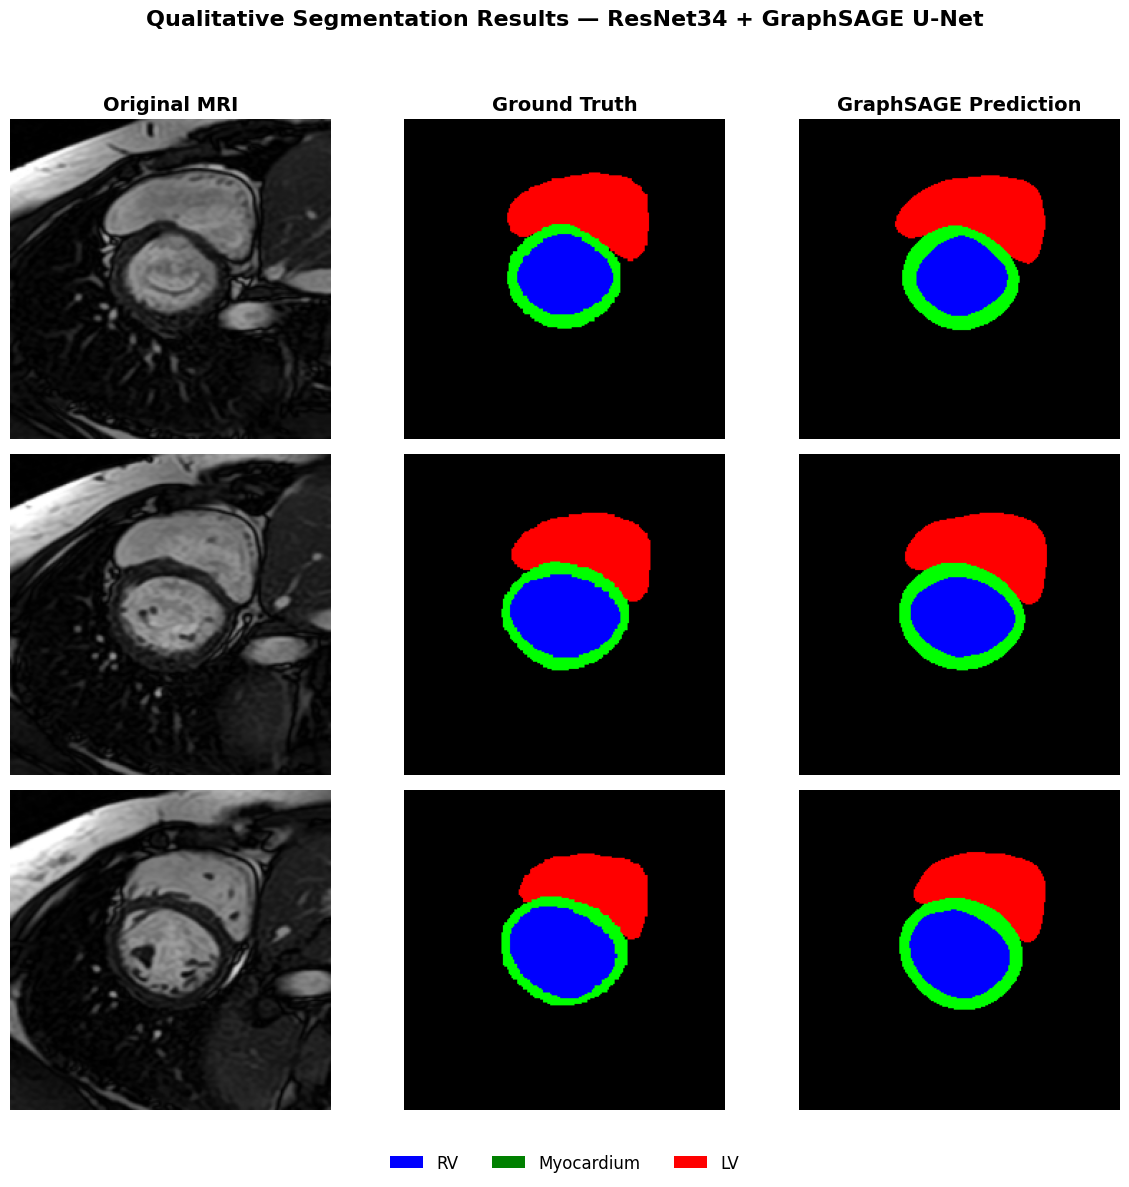

In [ ]:
# M&Ms EXPERIMENT 3 — RESNET34 + GRAPHSAGE U-NET
# STEP G14: QUALITATIVE SEGMENTATION VISUALIZATION

import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# IMAGENET NORMALIZATION
# Used to convert the displayed MRI back to a viewable image

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


# EXPLICIT RGB LABEL MAPPING
#
# 0 = Background = Black
# 1 = RV         = Blue
# 2 = Myocardium = Green
# 3 = LV         = Red

LABEL_COLORS = {
    0: np.array([0.0, 0.0, 0.0]),
    1: np.array([0.0, 0.0, 1.0]),  # Blue
    2: np.array([0.0, 1.0, 0.0]),  # Green
    3: np.array([1.0, 0.0, 0.0])   # Red
}


def mask_to_rgb(mask):

    rgb = np.zeros(
        (
            mask.shape[0],
            mask.shape[1],
            3
        ),
        dtype=np.float32
    )

    for class_id, color in LABEL_COLORS.items():

        rgb[
            mask == class_id
        ] = color

    return rgb


# RESTORE MRI FOR DISPLAY

def denormalize_image(image_tensor):

    image = (
        image_tensor
        .detach()
        .cpu()
        .numpy()
        .transpose(1, 2, 0)
    )

    image = (
        image * IMAGENET_STD
        + IMAGENET_MEAN
    )

    image = np.clip(
        image,
        0,
        1
    )

    # Dataset is grayscale repeated across RGB channels.
    return image[:, :, 0]


# FIND 3 TEST SLICES CONTAINING ALL FOREGROUND CLASSES

selected_samples = []

graphsage_model.eval()


with torch.no_grad():

    for images, masks in mnms_test_loader:

        # Search individual samples
        for i in range(
            images.shape[0]
        ):

            unique_labels = set(
                torch.unique(
                    masks[i]
                )
                .cpu()
                .numpy()
                .tolist()
            )

            # Require RV + Myocardium + LV
            if {
                1,
                2,
                3
            }.issubset(
                unique_labels
            ):

                image_single = (
                    images[i:i+1]
                    .to(device)
                )

                logits = graphsage_model(
                    image_single
                )

                prediction = torch.argmax(
                    logits,
                    dim=1
                )[0]


                selected_samples.append({
                    "image": images[i].cpu(),
                    "mask": masks[i].cpu(),
                    "prediction": prediction.cpu()
                })


                if len(
                    selected_samples
                ) == 3:

                    break


        if len(
            selected_samples
        ) == 3:

            break


print(
    f"Selected "
    f"{len(selected_samples)} "
    f"test slices containing "
    f"RV, Myocardium, and LV."
)


# SAFETY CHECK

assert len(selected_samples) == 3, (
    "Could not find three test slices "
    "containing all foreground classes."
)

# CREATE FIGURE

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)


column_titles = [
    "Original MRI",
    "Ground Truth",
    "GraphSAGE Prediction"
]


for col in range(3):

    axes[0, col].set_title(
        column_titles[col],
        fontsize=14,
        fontweight="bold"
    )


# DISPLAY EACH SAMPLE

for row, sample in enumerate(
    selected_samples
):

    image = denormalize_image(
        sample["image"]
    )

    ground_truth = (
        sample["mask"]
        .numpy()
    )

    prediction = (
        sample["prediction"]
        .numpy()
    )


    ground_truth_rgb = mask_to_rgb(
        ground_truth
    )

    prediction_rgb = mask_to_rgb(
        prediction
    )


    # Original MRI
    axes[row, 0].imshow(
        image,
        cmap="gray"
    )

    # Ground truth
    axes[row, 1].imshow(
        ground_truth_rgb
    )

    # Prediction
    axes[row, 2].imshow(
        prediction_rgb
    )


    for col in range(3):

        axes[row, col].axis(
            "off"
        )

# LEGEND

legend_elements = [

    Patch(
        facecolor="blue",
        label="RV"
    ),

    Patch(
        facecolor="green",
        label="Myocardium"
    ),

    Patch(
        facecolor="red",
        label="LV"
    )
]


fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=12,
    frameon=False
)


# TITLE

fig.suptitle(
    "Qualitative Segmentation Results — "
    "ResNet34 + GraphSAGE U-Net",
    fontsize=16,
    fontweight="bold",
    y=0.98
)


plt.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95
    ]
)

plt.show()

# Verify all Three Best Checkpoints

In [ ]:
# M&Ms — UNIFIED FINAL EVALUATION

import os
import torch


checkpoint_paths = {
    "ResNet34 U-Net":
        "/content/drive/MyDrive/Thesis_Checkpoints/"
        "best_resnet34_unet_mnms.pth",

    "Swin-Small UPerNet":
        "/content/drive/MyDrive/Thesis_Checkpoints/"
        "best_swin_upernet_mnms.pth",

    "ResNet34 + GraphSAGE U-Net":
        "/content/drive/MyDrive/Thesis_Checkpoints/"
        "best_graphsage_unet_mnms.pth"
}


print("=" * 78)
print("M&Ms — VERIFYING FINAL MODEL CHECKPOINTS")
print("=" * 78)


for model_name, path in checkpoint_paths.items():

    print(f"\n{model_name}")
    print("-" * 78)

    if not os.path.exists(path):
        print("❌ CHECKPOINT NOT FOUND")
        print(path)
        continue

    # File size
    size_mb = os.path.getsize(path) / (1024 ** 2)

    # Read checkpoint on CPU only
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("✓ Checkpoint found")
    print(f"File size: {size_mb:.2f} MB")

    # Epoch
    if "epoch" in checkpoint:
        print(
            f"Saved epoch: "
            f"{checkpoint['epoch']}"
        )
    else:
        print(
            "Saved epoch: "
            "not stored in checkpoint"
        )

    # Best validation Dice
    if "best_val_dice" in checkpoint:
        print(
            f"Best validation Dice: "
            f"{checkpoint['best_val_dice']:.6f}"
        )
    else:
        print(
            "Best validation Dice: "
            "not stored in checkpoint"
        )

    # State dictionary
    if "model_state_dict" in checkpoint:
        num_tensors = len(
            checkpoint["model_state_dict"]
        )

        print(
            f"Model state tensors: "
            f"{num_tensors}"
        )

        print(
            "✓ model_state_dict present"
        )
    else:
        print(
            "❌ model_state_dict missing"
        )

    # Architecture metadata if available
    if "architecture" in checkpoint:
        print(
            f"Architecture: "
            f"{checkpoint['architecture']}"
        )


print("\n" + "=" * 78)
print("CHECKPOINT VERIFICATION COMPLETE")
print("=" * 78)

M&Ms — VERIFYING FINAL MODEL CHECKPOINTS

ResNet34 U-Net
------------------------------------------------------------------------------
✓ Checkpoint found
File size: 279.95 MB
Saved epoch: 18
Best validation Dice: 0.880522
Model state tensors: 278
✓ model_state_dict present

Swin-Small UPerNet
------------------------------------------------------------------------------
✓ Checkpoint found
File size: 922.56 MB
Saved epoch: 19
Best validation Dice: 0.852577
Model state tensors: 513
✓ model_state_dict present

ResNet34 + GraphSAGE U-Net
------------------------------------------------------------------------------
✓ Checkpoint found
File size: 358.73 MB
Saved epoch: 69
Best validation Dice: 0.860799
Model state tensors: 298
✓ model_state_dict present
Architecture: ResNet34 + 4-layer GraphSAGE U-Net

CHECKPOINT VERIFICATION COMPLETE


# Define Unified Metric Functions

In [ ]:
# M&Ms — UNIFIED FINAL EVALUATION

import numpy as np
import torch

from skimage.metrics import structural_similarity as ssim
from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import distance_transform_edt


# CLASS INFORMATION

CLASS_IDS = [1, 2, 3]

CLASS_NAMES = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


# 1. DICE + IoU

def unified_dice_iou(
    predictions,
    targets,
    class_id,
    smooth=1e-6
):
    """
    Per-slice Dice and IoU.

    predictions: [B, H, W]
    targets:     [B, H, W]
    """

    pred = (
        predictions == class_id
    ).float()

    true = (
        targets == class_id
    ).float()


    intersection = (
        pred * true
    ).sum(dim=(1, 2))

    pred_sum = pred.sum(
        dim=(1, 2)
    )

    true_sum = true.sum(
        dim=(1, 2)
    )


    dice = (
        2.0 * intersection + smooth
    ) / (
        pred_sum +
        true_sum +
        smooth
    )


    union = (
        pred_sum +
        true_sum -
        intersection
    )


    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )


    return dice, iou


# 2. SSIM

def unified_ssim(
    pred_mask,
    true_mask
):
    """
    Binary-mask SSIM.
    """

    pred_mask = pred_mask.astype(
        np.uint8
    )

    true_mask = true_mask.astype(
        np.uint8
    )


    return ssim(
        true_mask,
        pred_mask,
        data_range=1
    )


# 3. HAUSDORFF DISTANCE

def unified_hausdorff(
    pred_mask,
    true_mask
):
    """
    Symmetric Hausdorff distance.

    Units:
    pixels at the resized 224x224 resolution.
    """

    pred_points = np.argwhere(
        pred_mask
    )

    true_points = np.argwhere(
        true_mask
    )


    # One or both masks empty:
    # do not invent a finite boundary distance.
    if (
        len(pred_points) == 0
        or
        len(true_points) == 0
    ):
        return np.nan


    pred_to_true = directed_hausdorff(
        pred_points,
        true_points
    )[0]


    true_to_pred = directed_hausdorff(
        true_points,
        pred_points
    )[0]


    return max(
        pred_to_true,
        true_to_pred
    )

# 4. HD95

def unified_hd95(
    pred_mask,
    true_mask
):
    """
    Symmetric 95th-percentile foreground distance.

    Units:
    pixels at the resized 224x224 resolution.
    """

    pred_mask = pred_mask.astype(
        bool
    )

    true_mask = true_mask.astype(
        bool
    )


    if (
        pred_mask.sum() == 0
        or
        true_mask.sum() == 0
    ):
        return np.nan


    # Distance to nearest true foreground pixel
    distance_to_true = (
        distance_transform_edt(
            ~true_mask
        )
    )

    # Distance to nearest predicted foreground pixel
    distance_to_pred = (
        distance_transform_edt(
            ~pred_mask
        )
    )


    pred_to_true = (
        distance_to_true[
            pred_mask
        ]
    )

    true_to_pred = (
        distance_to_pred[
            true_mask
        ]
    )


    distances = np.concatenate([
        pred_to_true,
        true_to_pred
    ])


    return float(
        np.percentile(
            distances,
            95
        )
    )


# QUICK VERIFICATION

print("=" * 72)
print("M&Ms UNIFIED METRIC FRAMEWORK")
print("=" * 72)

print("Classes:")
for class_id in CLASS_IDS:
    print(
        f"  {class_id} = "
        f"{CLASS_NAMES[class_id]}"
    )

print("\nMetrics defined:")
print("✓ Dice")
print("✓ IoU")
print("✓ SSIM")
print("✓ Hausdorff Distance")
print("✓ HD95")

print("\nBoundary distance units:")
print("Pixels at resized 224 × 224 resolution")

print("\nROC-AUC:")
print(
    "Will use one-vs-rest softmax probabilities, "
    "seed=42, 20,000 sampled pixels per batch."
)

print("\n✓ Unified metric framework ready.")

M&Ms UNIFIED METRIC FRAMEWORK
Classes:
  1 = RV
  2 = Myocardium
  3 = LV

Metrics defined:
✓ Dice
✓ IoU
✓ SSIM
✓ Hausdorff Distance
✓ HD95

Boundary distance units:
Pixels at resized 224 × 224 resolution

ROC-AUC:
Will use one-vs-rest softmax probabilities, seed=42, 20,000 sampled pixels per batch.

✓ Unified metric framework ready.


# Build Unified Evaluator

In [ ]:
# M&Ms — UNIFIED FINAL EVALUATION

import numpy as np
import torch


def evaluate_mnms_model(
    model,
    test_loader,
    model_name="Model"
):

    # STORAGE

    dice_scores = {
        class_id: []
        for class_id in CLASS_IDS
    }

    iou_scores = {
        class_id: []
        for class_id in CLASS_IDS
    }

    ssim_scores = {
        class_id: []
        for class_id in CLASS_IDS
    }

    hd_scores = {
        class_id: []
        for class_id in CLASS_IDS
    }

    hd95_scores = {
        class_id: []
        for class_id in CLASS_IDS
    }

    # EVALUATION MODE

    model.eval()

    print("=" * 78)
    print(f"UNIFIED M&Ms EVALUATION — {model_name}")
    print("=" * 78)

    print(
        f"Test slices: "
        f"{len(test_loader.dataset)}"
    )

    print(
        f"Test batches: "
        f"{len(test_loader)}"
    )

    print("\nEvaluating...")

    # TEST LOOP

    with torch.no_grad():

        for batch_idx, (images, masks) in enumerate(
            test_loader,
            start=1
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            # FORWARD PASS

            outputs = model(
                images
            )

            # Handle Hugging Face segmentation models
            if hasattr(outputs, "logits"):
                logits = outputs.logits
            else:
                logits = outputs


            # Some segmentation models may return logits
            # at a different spatial resolution.
            if logits.shape[-2:] != masks.shape[-2:]:

                logits = torch.nn.functional.interpolate(
                    logits,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            # DICE + IoU

            for class_id in CLASS_IDS:

                dice, iou = unified_dice_iou(
                    predictions,
                    masks,
                    class_id
                )

                dice_scores[class_id].extend(
                    dice.detach()
                    .cpu()
                    .numpy()
                    .tolist()
                )

                iou_scores[class_id].extend(
                    iou.detach()
                    .cpu()
                    .numpy()
                    .tolist()
                )


            # CPU ARRAYS FOR SSIM / HD / HD95

            predictions_np = (
                predictions
                .detach()
                .cpu()
                .numpy()
            )

            masks_np = (
                masks
                .detach()
                .cpu()
                .numpy()
            )


            for sample_idx in range(
                predictions_np.shape[0]
            ):

                pred_sample = (
                    predictions_np[
                        sample_idx
                    ]
                )

                true_sample = (
                    masks_np[
                        sample_idx
                    ]
                )


                for class_id in CLASS_IDS:

                    pred_binary = (
                        pred_sample == class_id
                    ).astype(
                        np.uint8
                    )

                    true_binary = (
                        true_sample == class_id
                    ).astype(
                        np.uint8
                    )


                    # SSIM

                    class_ssim = unified_ssim(
                        pred_binary,
                        true_binary
                    )

                    ssim_scores[
                        class_id
                    ].append(
                        class_ssim
                    )


                    # HAUSDORFF

                    hd = unified_hausdorff(
                        pred_binary,
                        true_binary
                    )

                    if not np.isnan(hd):

                        hd_scores[
                            class_id
                        ].append(
                            hd
                        )


                    # HD95

                    hd95 = unified_hd95(
                        pred_binary,
                        true_binary
                    )

                    if not np.isnan(hd95):

                        hd95_scores[
                            class_id
                        ].append(
                            hd95
                        )

            # PROGRESS

            if (
                batch_idx % 50 == 0
                or
                batch_idx == len(test_loader)
            ):

                print(
                    f"Processed "
                    f"{batch_idx}/"
                    f"{len(test_loader)} "
                    f"batches"
                )


    # SUMMARIZE RESULTS

    results = {}


    for class_id in CLASS_IDS:

        results[class_id] = {

            "Dice":
                float(
                    np.mean(
                        dice_scores[class_id]
                    )
                ),

            "IoU":
                float(
                    np.mean(
                        iou_scores[class_id]
                    )
                ),

            "SSIM":
                float(
                    np.mean(
                        ssim_scores[class_id]
                    )
                ),

            "Hausdorff":
                float(
                    np.mean(
                        hd_scores[class_id]
                    )
                ),

            "HD95":
                float(
                    np.mean(
                        hd95_scores[class_id]
                    )
                ),

            "HD_valid_slices":
                len(
                    hd_scores[class_id]
                ),

            "HD95_valid_slices":
                len(
                    hd95_scores[class_id]
                )
        }

    # MACRO AVERAGES

    macro = {}

    for metric in [
        "Dice",
        "IoU",
        "SSIM",
        "Hausdorff",
        "HD95"
    ]:

        macro[metric] = float(
            np.mean([
                results[class_id][metric]
                for class_id in CLASS_IDS
            ])
        )


    results["Macro"] = macro


    # PRINT RESULTS

    print("\n" + "=" * 78)
    print("UNIFIED TEST RESULTS")
    print("=" * 78)


    for class_id in CLASS_IDS:

        r = results[class_id]

        print(
            f"{CLASS_NAMES[class_id]:12s} | "
            f"Dice {r['Dice']:.4f} | "
            f"IoU {r['IoU']:.4f} | "
            f"SSIM {r['SSIM']:.4f} | "
            f"HD {r['Hausdorff']:.4f} | "
            f"HD95 {r['HD95']:.4f}"
        )


    print("-" * 78)

    m = results["Macro"]

    print(
        f"{'Macro Average':12s} | "
        f"Dice {m['Dice']:.4f} | "
        f"IoU {m['IoU']:.4f} | "
        f"SSIM {m['SSIM']:.4f} | "
        f"HD {m['Hausdorff']:.4f} | "
        f"HD95 {m['HD95']:.4f}"
    )


    print("\nValid boundary slices:")

    for class_id in CLASS_IDS:

        print(
            f"{CLASS_NAMES[class_id]:12s} | "
            f"HD: "
            f"{results[class_id]['HD_valid_slices']} | "
            f"HD95: "
            f"{results[class_id]['HD95_valid_slices']}"
        )


    print("=" * 78)

    return results


print("=" * 78)
print("UNIFIED M&Ms MODEL EVALUATOR")
print("=" * 78)

print("✓ One evaluation function created.")
print("✓ Dice / IoU use per-slice averaging.")
print("✓ SSIM uses binary class masks.")
print("✓ HD and HD95 use the same boundary rules.")
print("✓ Hugging Face logits are handled automatically.")
print("✓ Output resizing is handled automatically.")
print("✓ Valid boundary-slice counts will be reported.")

print("\nReady to evaluate all three models.")

UNIFIED M&Ms MODEL EVALUATOR
✓ One evaluation function created.
✓ Dice / IoU use per-slice averaging.
✓ SSIM uses binary class masks.
✓ HD and HD95 use the same boundary rules.
✓ Hugging Face logits are handled automatically.
✓ Output resizing is handled automatically.
✓ Valid boundary-slice counts will be reported.

Ready to evaluate all three models.


# Unified GraphSAGE Evaluation

In [ ]:
# M&Ms — UNIFIED FINAL EVALUATION

print("=" * 78)
print("U4 — EVALUATING GRAPHSAGE BEST CHECKPOINT")
print("=" * 78)

print("Expected checkpoint epoch: 69")
print("Expected best validation Dice: 0.860799")
print()


# SAFETY CHECK

graphsage_model.eval()

print(
    "Model mode:",
    "Evaluation"
    if not graphsage_model.training
    else "Training"
)


# RUN UNIFIED EVALUATION

graphsage_unified_results = evaluate_mnms_model(
    model=graphsage_model,
    test_loader=mnms_test_loader,
    model_name="ResNet34 + GraphSAGE U-Net"
)


# SAVE RESULTS IN MEMORY

print("\n✓ GraphSAGE unified evaluation complete.")
print("✓ Results stored in: graphsage_unified_results")

U4 — EVALUATING GRAPHSAGE BEST CHECKPOINT
Expected checkpoint epoch: 69
Expected best validation Dice: 0.860799

Model mode: Evaluation
UNIFIED M&Ms EVALUATION — ResNet34 + GraphSAGE U-Net
Test slices: 2201
Test batches: 276

Evaluating...
Processed 50/276 batches
Processed 100/276 batches
Processed 150/276 batches
Processed 200/276 batches
Processed 250/276 batches
Processed 276/276 batches

UNIFIED TEST RESULTS
RV           | Dice 0.8924 | IoU 0.8251 | SSIM 0.9800 | HD 4.7810 | HD95 1.4725
Myocardium   | Dice 0.8182 | IoU 0.7032 | SSIM 0.9550 | HD 5.7527 | HD95 2.2511
LV           | Dice 0.7994 | IoU 0.7336 | SSIM 0.9755 | HD 8.4673 | HD95 3.5221
------------------------------------------------------------------------------
Macro Average | Dice 0.8367 | IoU 0.7540 | SSIM 0.9701 | HD 6.3336 | HD95 2.4152

Valid boundary slices:
RV           | HD: 2163 | HD95: 2163
Myocardium   | HD: 2192 | HD95: 2192
LV           | HD: 1752 | HD95: 1752

✓ GraphSAGE unified evaluation complete.
✓ Resu

# Unified Swin-Small UPerNet Evaluation

In [ ]:
# M&Ms — UNIFIED FINAL EVALUATION

import gc
import torch
from transformers import UperNetForSemanticSegmentation


# 1. FREE GRAPHSAGE GPU MEMORY

graphsage_model.to("cpu")

gc.collect()
torch.cuda.empty_cache()

print("✓ GraphSAGE moved to CPU.")
print(
    f"GPU allocated memory: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)


# 2. RECONSTRUCT SWIN ARCHITECTURE

print("\nReconstructing Swin-Small UPerNet...")

swin_model = (
    UperNetForSemanticSegmentation
    .from_pretrained(
        "openmmlab/upernet-swin-small",
        num_labels=4,
        ignore_mismatched_sizes=True
    )
)

# 3. LOAD OUR BEST M&Ms CHECKPOINT

SWIN_PATH = (
    "/content/drive/MyDrive/Thesis_Checkpoints/"
    "best_swin_upernet_mnms.pth"
)

checkpoint = torch.load(
    SWIN_PATH,
    map_location="cpu",
    weights_only=False
)

swin_model.load_state_dict(
    checkpoint["model_state_dict"]
)


print("✓ Best Swin checkpoint loaded.")
print(
    "Saved epoch:",
    checkpoint.get("epoch", "Unknown")
)

print(
    "Best validation Dice:",
    checkpoint.get(
        "best_val_dice",
        "Unknown"
    )
)


# 4. MOVE SWIN TO GPU

swin_model = swin_model.to(device)
swin_model.eval()

print(
    "Model mode:",
    "Evaluation"
    if not swin_model.training
    else "Training"
)


# 5. RUN THE EXACT SAME UNIFIED EVALUATOR

swin_unified_results = evaluate_mnms_model(
    model=swin_model,
    test_loader=mnms_test_loader,
    model_name="Swin-Small UPerNet"
)


print("\n✓ Swin unified evaluation complete.")
print("✓ Results stored in: swin_unified_results")

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `150`.


✓ GraphSAGE moved to CPU.
GPU allocated memory: 1.58 GB

Reconstructing Swin-Small UPerNet...


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

[transformers] UperNetForSemanticSegmentation LOAD REPORT from: openmmlab/upernet-swin-small
Key                              | Status   |                                                                                                     
---------------------------------+----------+-----------------------------------------------------------------------------------------------------
auxiliary_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([4, 256, 1, 1])
decode_head.classifier.bias      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
decode_head.classifier.weight    | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 512, 1, 1]) vs model:torch.Size([4, 512, 1, 1])
auxiliary_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      

Notes:
- MISMATCH:	ckpt 

✓ Best Swin checkpoint loaded.
Saved epoch: 19
Best validation Dice: 0.852576905378589
Model mode: Evaluation
UNIFIED M&Ms EVALUATION — Swin-Small UPerNet
Test slices: 2201
Test batches: 276

Evaluating...
Processed 50/276 batches
Processed 100/276 batches
Processed 150/276 batches
Processed 200/276 batches
Processed 250/276 batches
Processed 276/276 batches

UNIFIED TEST RESULTS
RV           | Dice 0.8896 | IoU 0.8211 | SSIM 0.9797 | HD 4.7636 | HD95 1.4317
Myocardium   | Dice 0.8139 | IoU 0.6972 | SSIM 0.9550 | HD 5.6975 | HD95 2.2680
LV           | Dice 0.8010 | IoU 0.7356 | SSIM 0.9759 | HD 7.7264 | HD95 2.9975
------------------------------------------------------------------------------
Macro Average | Dice 0.8348 | IoU 0.7513 | SSIM 0.9702 | HD 6.0625 | HD95 2.2324

Valid boundary slices:
RV           | HD: 2164 | HD95: 2164
Myocardium   | HD: 2194 | HD95: 2194
LV           | HD: 1761 | HD95: 1761

✓ Swin unified evaluation complete.
✓ Results stored in: swin_unified_results


# Unified ResNet34 U-Net Evaluation

In [ ]:
# M&Ms — UNIFIED FINAL EVALUATION
# STEP U6: RESNET34 U-NET

import gc
import torch
import segmentation_models_pytorch as smp


# 1. FREE SWIN GPU MEMORY

swin_model.to("cpu")

gc.collect()
torch.cuda.empty_cache()

print("✓ Swin moved to CPU.")

print(
    f"GPU allocated memory: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)


# 2. RECONSTRUCT RESNET34 U-NET

print("\nReconstructing ResNet34 U-Net...")

# No need to download ImageNet weights again.
# The complete trained weights will come from our checkpoint.

resnet_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=4
)


# 3. LOAD BEST M&Ms CHECKPOINT

RESNET_PATH = (
    "/content/drive/MyDrive/Thesis_Checkpoints/"
    "best_resnet34_unet_mnms.pth"
)

checkpoint = torch.load(
    RESNET_PATH,
    map_location="cpu",
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("✓ Best ResNet34 U-Net checkpoint loaded.")

print(
    "Saved epoch:",
    checkpoint.get("epoch", "Unknown")
)

print(
    "Best validation Dice:",
    checkpoint.get(
        "best_val_dice",
        "Unknown"
    )
)


# 4. MOVE TO GPU

resnet_model = resnet_model.to(device)
resnet_model.eval()

print(
    "Model mode:",
    "Evaluation"
    if not resnet_model.training
    else "Training"
)


# 5. RUN EXACT SAME UNIFIED EVALUATOR

resnet_unified_results = evaluate_mnms_model(
    model=resnet_model,
    test_loader=mnms_test_loader,
    model_name="ResNet34 U-Net"
)


print("\n✓ ResNet unified evaluation complete.")
print("✓ Results stored in: resnet_unified_results")

✓ Swin moved to CPU.
GPU allocated memory: 1.58 GB

Reconstructing ResNet34 U-Net...
✓ Best ResNet34 U-Net checkpoint loaded.
Saved epoch: 18
Best validation Dice: 0.8805220543786331
Model mode: Evaluation
UNIFIED M&Ms EVALUATION — ResNet34 U-Net
Test slices: 2201
Test batches: 276

Evaluating...
Processed 50/276 batches
Processed 100/276 batches
Processed 150/276 batches
Processed 200/276 batches
Processed 250/276 batches
Processed 276/276 batches

UNIFIED TEST RESULTS
RV           | Dice 0.8871 | IoU 0.8194 | SSIM 0.9798 | HD 5.0669 | HD95 1.7039
Myocardium   | Dice 0.8023 | IoU 0.6852 | SSIM 0.9536 | HD 6.8422 | HD95 2.8504
LV           | Dice 0.7962 | IoU 0.7346 | SSIM 0.9757 | HD 8.3499 | HD95 3.3257
------------------------------------------------------------------------------
Macro Average | Dice 0.8285 | IoU 0.7464 | SSIM 0.9697 | HD 6.7530 | HD95 2.6267

Valid boundary slices:
RV           | HD: 2155 | HD95: 2155
Myocardium   | HD: 2189 | HD95: 2189
LV           | HD: 1665 | H

# Unified ROC-AUC

In [ ]:
# M&Ms — UNIFIED FINAL EVALUATION

import numpy as np
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)


def evaluate_unified_roc(
    model,
    test_loader,
    model_name,
    pixels_per_batch=20000,
    seed=42
):

    model.eval()

    # IMPORTANT:
    # Reset RNG separately for every model.
    #
    # Because the test loader is not shuffled and every model
    # uses the same seed, the SAME pixel positions will be
    # sampled for all three models.

    rng = np.random.default_rng(seed)


    true_storage = {
        class_id: []
        for class_id in CLASS_IDS
    }

    prob_storage = {
        class_id: []
        for class_id in CLASS_IDS
    }


    print("=" * 78)
    print(f"UNIFIED ROC-AUC — {model_name}")
    print("=" * 78)

    print(f"Seed: {seed}")
    print(
        f"Maximum sampled pixels per batch: "
        f"{pixels_per_batch:,}"
    )


    with torch.no_grad():

        for batch_idx, (images, masks) in enumerate(
            test_loader,
            start=1
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            # FORWARD PASS

            outputs = model(images)

            if hasattr(outputs, "logits"):
                logits = outputs.logits
            else:
                logits = outputs


            if logits.shape[-2:] != masks.shape[-2:]:

                logits = F.interpolate(
                    logits,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )


            probabilities = torch.softmax(
                logits,
                dim=1
            )

            # FLATTEN PIXELS

            masks_flat = (
                masks
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )

            probs_flat = (
                probabilities
                .permute(0, 2, 3, 1)
                .detach()
                .cpu()
                .numpy()
                .reshape(-1, 4)
            )


            total_pixels = len(masks_flat)

            sample_size = min(
                pixels_per_batch,
                total_pixels
            )


            sampled_indices = rng.choice(
                total_pixels,
                size=sample_size,
                replace=False
            )


            sampled_targets = (
                masks_flat[
                    sampled_indices
                ]
            )

            sampled_probs = (
                probs_flat[
                    sampled_indices
                ]
            )

            # STORE SAME SAMPLED PIXELS FOR EACH CLASS

            for class_id in CLASS_IDS:

                binary_targets = (
                    sampled_targets == class_id
                ).astype(
                    np.uint8
                )

                true_storage[
                    class_id
                ].append(
                    binary_targets
                )

                prob_storage[
                    class_id
                ].append(
                    sampled_probs[
                        :,
                        class_id
                    ]
                )


            if (
                batch_idx % 50 == 0
                or
                batch_idx == len(test_loader)
            ):

                print(
                    f"Processed "
                    f"{batch_idx}/"
                    f"{len(test_loader)} batches"
                )


    # CALCULATE ROC CURVES + AUC

    roc_results = {}


    print("\n" + "-" * 78)


    for class_id in CLASS_IDS:

        y_true = np.concatenate(
            true_storage[class_id]
        )

        y_prob = np.concatenate(
            prob_storage[class_id]
        )


        fpr, tpr, thresholds = roc_curve(
            y_true,
            y_prob
        )


        auc_value = roc_auc_score(
            y_true,
            y_prob
        )


        roc_results[class_id] = {
            "AUC": float(auc_value),
            "FPR": fpr,
            "TPR": tpr,
            "Thresholds": thresholds,
            "Sampled_pixels": len(y_true)
        }


        print(
            f"{CLASS_NAMES[class_id]:12s} | "
            f"AUC {auc_value:.4f} | "
            f"Pixels {len(y_true):,}"
        )


    macro_auc = float(
        np.mean([
            roc_results[class_id]["AUC"]
            for class_id in CLASS_IDS
        ])
    )


    roc_results["Macro_AUC"] = macro_auc


    print("-" * 78)

    print(
        f"Macro AUC: {macro_auc:.4f}"
    )

    print("=" * 78)


    return roc_results


print("=" * 78)
print("UNIFIED ROC-AUC EVALUATOR READY")
print("=" * 78)

print("✓ Pixel-level one-vs-rest ROC-AUC")
print("✓ Uses softmax probabilities")
print("✓ Seed = 42")
print("✓ Maximum 20,000 sampled pixels per batch")
print("✓ RNG resets separately for every model")
print("✓ Same test-loader order required")
print("✓ Same sampled pixel positions across models")

print("\nReady for unified ROC evaluation.")

UNIFIED ROC-AUC EVALUATOR READY
✓ Pixel-level one-vs-rest ROC-AUC
✓ Uses softmax probabilities
✓ Seed = 42
✓ Maximum 20,000 sampled pixels per batch
✓ RNG resets separately for every model
✓ Same test-loader order required
✓ Same sampled pixel positions across models

Ready for unified ROC evaluation.


# Generate the Final Three-Model Comparison

✓ Selected 3 test slices containing all 3 foreground classes.
✓ ResNet34 U-Net predictions generated.
✓ Swin-Small UPerNet predictions generated.
✓ ResNet34 + GraphSAGE U-Net predictions generated.


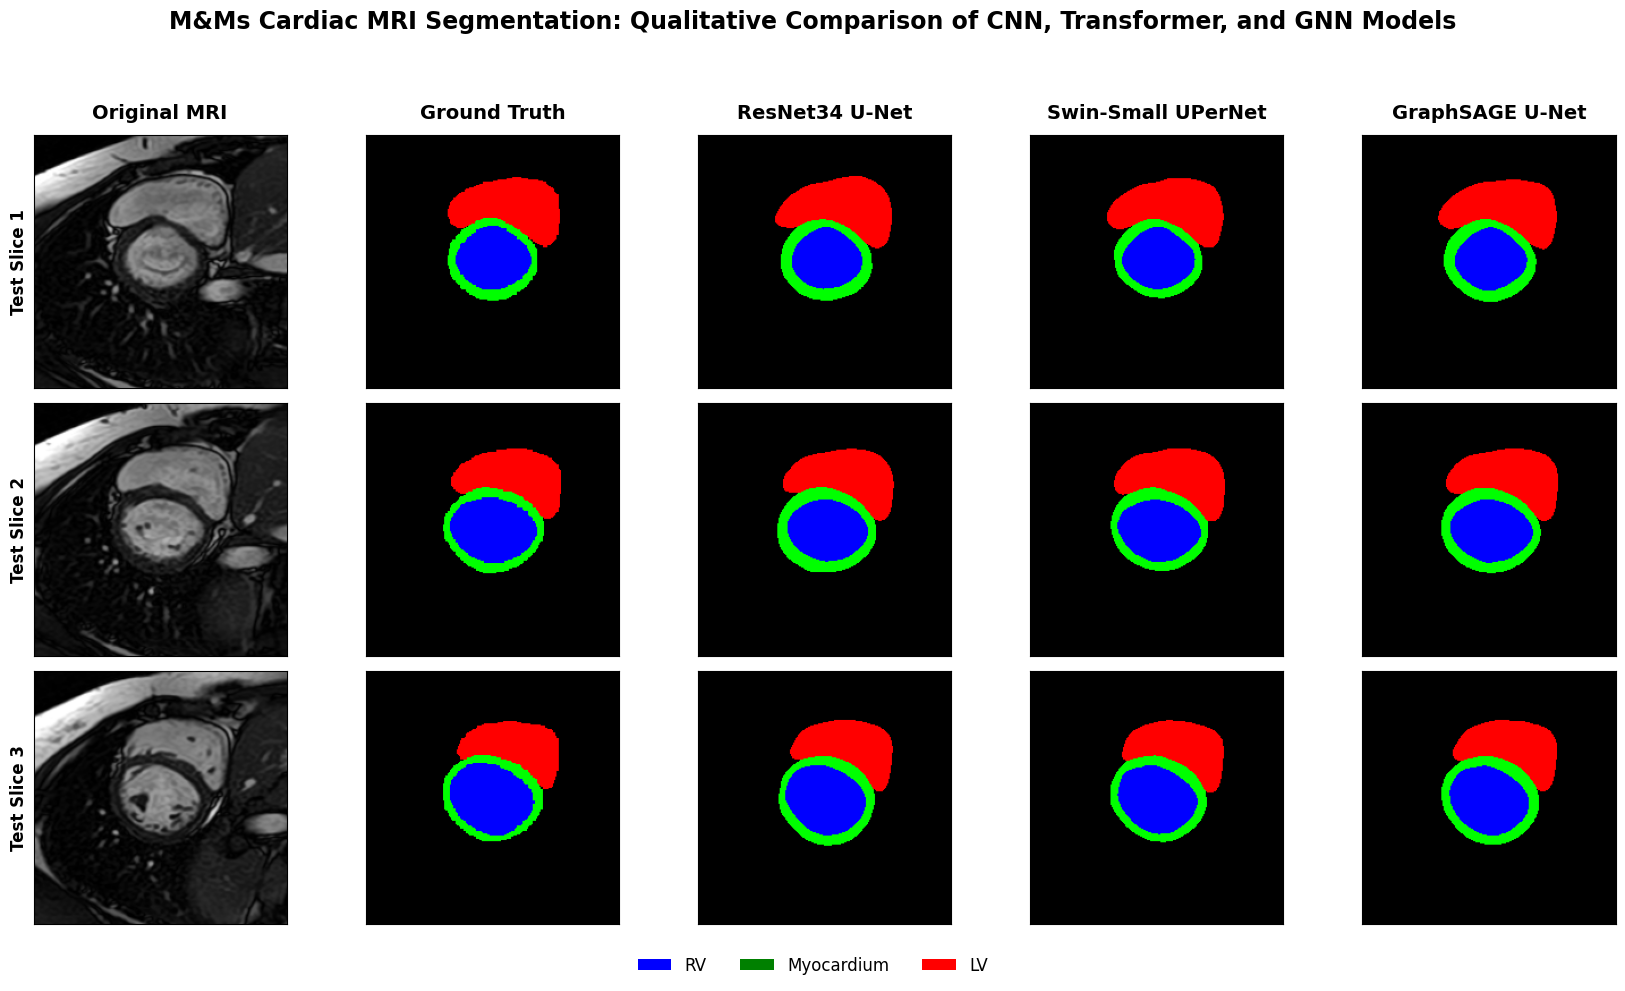


FINAL M&Ms VISUALIZATION COMPLETE
✓ Figure saved to:
/content/drive/MyDrive/Thesis_Figures/MNMS_Final_Model_Comparison.png

Color mapping:
Blue  = RV
Green = Myocardium
Red   = LV


In [ ]:
# M&Ms — FINAL QUALITATIVE MODEL COMPARISON
# MRI | GT | RESNET | SWIN | GRAPHSAGE

import os
import gc
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# 1. HELPER: CONVERT NORMALIZED MRI BACK FOR DISPLAY

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


def prepare_mri_for_display(image_tensor):

    image = (
        image_tensor
        .detach()
        .cpu()
        .numpy()
        .transpose(1, 2, 0)
    )

    image = (
        image * IMAGENET_STD
        + IMAGENET_MEAN
    )

    image = np.clip(
        image,
        0,
        1
    )

    # Dataset is grayscale repeated across 3 channels
    return image[:, :, 0]


# 2. EXPLICIT RGB MASK
#
# 0 = Background = black
# 1 = RV         = blue
# 2 = Myocardium = green
# 3 = LV         = red

def mask_to_rgb(mask):

    rgb = np.zeros(
        (*mask.shape, 3),
        dtype=np.float32
    )

    rgb[mask == 1] = [0, 0, 1]   # RV
    rgb[mask == 2] = [0, 1, 0]   # Myocardium
    rgb[mask == 3] = [1, 0, 0]   # LV

    return rgb


# 3. FIND THREE TEST SLICES CONTAINING ALL THREE CLASSES

selected_images = []
selected_masks = []

for images, masks in mnms_test_loader:

    for i in range(images.shape[0]):

        unique_labels = set(
            torch.unique(
                masks[i]
            ).cpu().numpy().tolist()
        )

        # Require RV, Myocardium and LV
        if {1, 2, 3}.issubset(unique_labels):

            selected_images.append(
                images[i].clone()
            )

            selected_masks.append(
                masks[i].clone()
            )

        if len(selected_images) == 3:
            break

    if len(selected_images) == 3:
        break


if len(selected_images) < 3:
    raise RuntimeError(
        "Could not find three test slices "
        "containing RV, myocardium and LV."
    )


selected_images = torch.stack(
    selected_images
)

selected_masks = torch.stack(
    selected_masks
)


print(
    f"✓ Selected {len(selected_images)} "
    f"test slices containing all 3 foreground classes."
)


# 4. COMMON PREDICTION FUNCTION

def predict_selected_slices(
    model,
    images,
    model_name
):

    model = model.to(device)
    model.eval()

    with torch.no_grad():

        inputs = images.to(device)

        outputs = model(inputs)

        if hasattr(outputs, "logits"):
            logits = outputs.logits
        else:
            logits = outputs

        if logits.shape[-2:] != images.shape[-2:]:

            logits = F.interpolate(
                logits,
                size=images.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        predictions = torch.argmax(
            logits,
            dim=1
        )

    predictions = (
        predictions
        .cpu()
        .numpy()
    )

    print(
        f"✓ {model_name} predictions generated."
    )

    return predictions


# 5. RESNET PREDICTIONS

resnet_predictions = predict_selected_slices(
    resnet_model,
    selected_images,
    "ResNet34 U-Net"
)

# Move off GPU
resnet_model.to("cpu")

gc.collect()
torch.cuda.empty_cache()


# 6. SWIN PREDICTIONS

swin_predictions = predict_selected_slices(
    swin_model,
    selected_images,
    "Swin-Small UPerNet"
)

swin_model.to("cpu")

gc.collect()
torch.cuda.empty_cache()


# 7. GRAPHSAGE PREDICTIONS

graphsage_predictions = predict_selected_slices(
    graphsage_model,
    selected_images,
    "ResNet34 + GraphSAGE U-Net"
)

graphsage_model.to("cpu")

gc.collect()
torch.cuda.empty_cache()


# 8. CREATE 3 × 5 THESIS FIGURE

fig, axes = plt.subplots(
    3,
    5,
    figsize=(17, 10)
)


column_titles = [
    "Original MRI",
    "Ground Truth",
    "ResNet34 U-Net",
    "Swin-Small UPerNet",
    "GraphSAGE U-Net"
]


for col, title in enumerate(column_titles):

    axes[0, col].set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12
    )


for row in range(3):

    # MRI

    mri = prepare_mri_for_display(
        selected_images[row]
    )

    axes[row, 0].imshow(
        mri,
        cmap="gray"
    )


    # GROUND TRUTH

    gt = (
        selected_masks[row]
        .cpu()
        .numpy()
    )

    axes[row, 1].imshow(
        mask_to_rgb(gt)
    )


    # RESNET

    axes[row, 2].imshow(
        mask_to_rgb(
            resnet_predictions[row]
        )
    )


    # SWIN

    axes[row, 3].imshow(
        mask_to_rgb(
            swin_predictions[row]
        )
    )


    # GRAPHSAGE

    axes[row, 4].imshow(
        mask_to_rgb(
            graphsage_predictions[row]
        )
    )


    # Row labels
    axes[row, 0].set_ylabel(
        f"Test Slice {row + 1}",
        fontsize=12,
        fontweight="bold"
    )


    for col in range(5):

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])


# 9. LEGEND

legend_elements = [

    Patch(
        facecolor="blue",
        label="RV"
    ),

    Patch(
        facecolor="green",
        label="Myocardium"
    ),

    Patch(
        facecolor="red",
        label="LV"
    )
]


fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=12,
    frameon=False,
    bbox_to_anchor=(0.5, 0.01)
)


# 10. TITLE + LAYOUT

fig.suptitle(
    "M&Ms Cardiac MRI Segmentation: "
    "Qualitative Comparison of CNN, Transformer, and GNN Models",
    fontsize=17,
    fontweight="bold",
    y=0.99
)


plt.tight_layout(
    rect=[0, 0.06, 1, 0.95]
)


# 11. SAVE HIGH-RESOLUTION FIGURE TO DRIVE

FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "Thesis_Figures"
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)

FIGURE_PATH = os.path.join(
    FIGURE_DIR,
    "MNMS_Final_Model_Comparison.png"
)


plt.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print("\n" + "=" * 72)
print("FINAL M&Ms VISUALIZATION COMPLETE")
print("=" * 72)

print(
    f"✓ Figure saved to:\n{FIGURE_PATH}"
)

print("\nColor mapping:")
print("Blue  = RV")
print("Green = Myocardium")
print("Red   = LV")

# CMI-MULTI

In [ ]:
!pip install -q --force-reinstall "huggingface_hub>=1.5.0,<2.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.7/111.7 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 126.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 57.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
!pip install -q --force-reinstall "huggingface_hub>=1.5.0,<2.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


In [ ]:
!pip install -q "fsspec[http]==2025.12.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.4/201.4 kB 8.8 MB/s eta 0:00:00


In [ ]:
import huggingface_hub
import fsspec
import datasets
import transformers
import torch
import nibabel

print("===== ENVIRONMENT CHECK =====")
print("huggingface_hub:", huggingface_hub.__version__)
print("fsspec:", fsspec.__version__)
print("datasets:", datasets.__version__)
print("transformers:", transformers.__version__)
print("torch:", torch.__version__)
print("nibabel:", nibabel.__version__)

print("\nAll imports successful.")

===== ENVIRONMENT CHECK =====
huggingface_hub: 1.33.0
fsspec: 2025.12.0
datasets: 4.8.5
transformers: 5.17.0
torch: 2.11.0+cu130
nibabel: 5.4.2

All imports successful.


# Download CMR-MULTI SAX Data

In [ ]:
# CMR-MULTI — CELL 3
# Download Short-Axis (SAX) Cine MRI Data

from huggingface_hub import snapshot_download
import os

CMR_ROOT = "/content/CMR_MULTI"

print("Starting CMR-MULTI SAX download...")

snapshot_download(
    repo_id="Jackloveaa/CMR-MULTI",
    repo_type="dataset",
    local_dir=CMR_ROOT,
    allow_patterns=[
        "CINE_MULTI/SAX_TR/*",
        "CINE_MULTI/SAX_TR/**/*"
    ]
)

print("\n===== DOWNLOAD CHECK =====")
print("Download finished.")
print("CMR_ROOT exists:", os.path.exists(CMR_ROOT))
print("Location:", CMR_ROOT)

Starting CMR-MULTI SAX download...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 210 files:   0%|          | 0/210 [00:00<?, ?it/s]


===== DOWNLOAD CHECK =====
Download finished.
CMR_ROOT exists: True
Location: /content/CMR_MULTI


# Inspect the SAX Directory

In [ ]:
# CMR-MULTI — CELL 4
# Inspect SAX Files and Folder Structure

import os

SAX_ROOT = os.path.join(
    CMR_ROOT,
    "CINE_MULTI",
    "SAX_TR"
)

print("===== SAX DIRECTORY CHECK =====")
print("SAX path:", SAX_ROOT)
print("Exists:", os.path.exists(SAX_ROOT))


if os.path.exists(SAX_ROOT):

    all_files = sorted(
        os.listdir(SAX_ROOT)
    )

    print("\nTotal entries:", len(all_files))

    print("\n===== FIRST 30 ENTRIES =====")

    for name in all_files[:30]:
        print(name)

else:

    print("\nSAX_TR was not found.")

    print("\nAvailable directories:")

    for root, dirs, files in os.walk(CMR_ROOT):

        level = root.replace(
            CMR_ROOT,
            ""
        ).count(os.sep)

        if level <= 3:

            indent = "  " * level

            print(
                f"{indent}"
                f"{os.path.basename(root)}/ "
                f"({len(files)} files)"
            )

===== SAX DIRECTORY CHECK =====
SAX path: /content/CMR_MULTI/CINE_MULTI/SAX_TR
Exists: True

Total entries: 2

===== FIRST 30 ENTRIES =====
anno
image


# Inspect Image and Annotation Files

In [ ]:
# CMR-MULTI — CELL 5
# Inspect MRI Images and Annotation Files

import os

IMAGE_DIR = os.path.join(SAX_ROOT, "image")
ANNO_DIR  = os.path.join(SAX_ROOT, "anno")

image_files = sorted(os.listdir(IMAGE_DIR))
anno_files  = sorted(os.listdir(ANNO_DIR))

print("===== CMR-MULTI SAX FILE CHECK =====")

print("\nIMAGE directory:")
print("Path:", IMAGE_DIR)
print("Number of files:", len(image_files))

print("\nANNOTATION directory:")
print("Path:", ANNO_DIR)
print("Number of files:", len(anno_files))


print("\n===== FIRST 15 IMAGE FILES =====")
for f in image_files[:15]:
    print(f)


print("\n===== FIRST 15 ANNOTATION FILES =====")
for f in anno_files[:15]:
    print(f)


print("\n===== FILE EXTENSIONS =====")

image_extensions = sorted(
    set(
        ".nii.gz" if f.endswith(".nii.gz")
        else os.path.splitext(f)[1]
        for f in image_files
    )
)

anno_extensions = sorted(
    set(
        ".nii.gz" if f.endswith(".nii.gz")
        else os.path.splitext(f)[1]
        for f in anno_files
    )
)

print("Image extensions:", image_extensions)
print("Annotation extensions:", anno_extensions)

===== CMR-MULTI SAX FILE CHECK =====

IMAGE directory:
Path: /content/CMR_MULTI/CINE_MULTI/SAX_TR/image
Number of files: 105

ANNOTATION directory:
Path: /content/CMR_MULTI/CINE_MULTI/SAX_TR/anno
Number of files: 105

===== FIRST 15 IMAGE FILES =====
CINE_SAX_001.nii.gz
CINE_SAX_002.nii.gz
CINE_SAX_003.nii.gz
CINE_SAX_004.nii.gz
CINE_SAX_005.nii.gz
CINE_SAX_006.nii.gz
CINE_SAX_007.nii.gz
CINE_SAX_008.nii.gz
CINE_SAX_009.nii.gz
CINE_SAX_010.nii.gz
CINE_SAX_011.nii.gz
CINE_SAX_012.nii.gz
CINE_SAX_013.nii.gz
CINE_SAX_014.nii.gz
CINE_SAX_015.nii.gz

===== FIRST 15 ANNOTATION FILES =====
CINE_SAX_001.nii.gz
CINE_SAX_002.nii.gz
CINE_SAX_003.nii.gz
CINE_SAX_004.nii.gz
CINE_SAX_005.nii.gz
CINE_SAX_006.nii.gz
CINE_SAX_007.nii.gz
CINE_SAX_008.nii.gz
CINE_SAX_009.nii.gz
CINE_SAX_010.nii.gz
CINE_SAX_011.nii.gz
CINE_SAX_012.nii.gz
CINE_SAX_013.nii.gz
CINE_SAX_014.nii.gz
CINE_SAX_015.nii.gz

===== FILE EXTENSIONS =====
Image extensions: ['.nii.gz']
Annotation extensions: ['.nii.gz']


# Inspect ONE MRI/Mask Pair

In [ ]:
# CMR-MULTI — CELL 6
# Inspect One MRI + Annotation Pair

import os
import nibabel as nib
import numpy as np

# Use the first case
sample_name = image_files[0]

image_path = os.path.join(IMAGE_DIR, sample_name)
anno_path  = os.path.join(ANNO_DIR, sample_name)

# Load NIfTI files
image_nii = nib.load(image_path)
anno_nii  = nib.load(anno_path)

# Convert to NumPy arrays
image_data = image_nii.get_fdata()
anno_data  = anno_nii.get_fdata()

print("===== SAMPLE CASE =====")
print("Filename:", sample_name)

print("\n===== MRI =====")
print("Shape:", image_data.shape)
print("Data type:", image_data.dtype)
print("Voxel spacing:", image_nii.header.get_zooms())
print("Minimum intensity:", image_data.min())
print("Maximum intensity:", image_data.max())

print("\n===== ANNOTATION =====")
print("Shape:", anno_data.shape)
print("Data type:", anno_data.dtype)
print("Voxel spacing:", anno_nii.header.get_zooms())

unique_labels, counts = np.unique(
    anno_data.astype(np.int64),
    return_counts=True
)

print("\nUnique mask labels:", unique_labels)

print("\nLabel pixel/voxel counts:")
for label, count in zip(unique_labels, counts):
    print(f"Label {label}: {count:,}")

print("\n===== IMAGE / MASK CHECK =====")
print("Shapes match:", image_data.shape == anno_data.shape)
print(
    "Spatial dimensions match:",
    image_data.shape[:3] == anno_data.shape[:3]
)

===== SAMPLE CASE =====
Filename: CINE_SAX_001.nii.gz

===== MRI =====
Shape: (149, 144, 275)
Data type: float64
Voxel spacing: (np.float32(1.25), np.float32(1.2847222), np.float32(0.32846397))
Minimum intensity: 0.0
Maximum intensity: 3264.291748046875

===== ANNOTATION =====
Shape: (149, 144, 275)
Data type: float64
Voxel spacing: (np.float32(1.25), np.float32(1.2847222), np.float32(0.32846397))

Unique mask labels: [0 1 2 3]

Label pixel/voxel counts:
Label 0: 5,393,376
Label 1: 241,318
Label 2: 141,775
Label 3: 123,931

===== IMAGE / MASK CHECK =====
Shapes match: True
Spatial dimensions match: True


# Check all 105 Cases

In [ ]:
# CMR-MULTI — CELL 7
# Verify All 105 MRI / Annotation Pairs

import os
import nibabel as nib
import numpy as np

shape_matches = 0
shape_mismatches = []

all_labels = set()
case_shapes = {}
case_spacings = {}

cases_with_label = {
    0: 0,
    1: 0,
    2: 0,
    3: 0
}

print("Checking all CMR-MULTI SAX cases...\n")

for i, filename in enumerate(image_files):

    image_path = os.path.join(IMAGE_DIR, filename)
    anno_path  = os.path.join(ANNO_DIR, filename)

    image_nii = nib.load(image_path)
    anno_nii  = nib.load(anno_path)

    image_shape = image_nii.shape
    anno_shape  = anno_nii.shape

    # Check MRI/mask dimensions
    if image_shape == anno_shape:
        shape_matches += 1
    else:
        shape_mismatches.append(
            (filename, image_shape, anno_shape)
        )

    # Record shapes and spacing
    case_shapes[filename] = image_shape
    case_spacings[filename] = image_nii.header.get_zooms()

    # Read mask only
    mask = np.asarray(anno_nii.dataobj)

    labels = np.unique(mask).astype(int)

    all_labels.update(labels.tolist())

    for label in cases_with_label:
        if label in labels:
            cases_with_label[label] += 1

    if (i + 1) % 20 == 0:
        print(f"Checked {i + 1}/{len(image_files)} cases")


print("\n===== DATASET CHECK =====")

print("Total MRI files:", len(image_files))
print("Total annotation files:", len(anno_files))

print("\nMRI/mask shape matches:", shape_matches)
print("Shape mismatches:", len(shape_mismatches))

if shape_mismatches:
    print("\nMismatched cases:")
    for item in shape_mismatches:
        print(item)

print("\nAll mask labels found:", sorted(all_labels))

print("\n===== LABEL PRESENCE BY CASE =====")

for label, count in cases_with_label.items():
    print(
        f"Label {label}: "
        f"{count}/{len(image_files)} cases"
    )

print("\n===== VOLUME SHAPES =====")

unique_shapes = sorted(set(case_shapes.values()))

print("Number of unique shapes:", len(unique_shapes))

for shape in unique_shapes[:20]:
    count = list(case_shapes.values()).count(shape)
    print(shape, "->", count, "case(s)")

if len(unique_shapes) > 20:
    print("... additional shapes not displayed")

print("\n===== FIRST 10 CASE SPACINGS =====")

for filename in image_files[:10]:
    print(
        filename,
        "->",
        case_spacings[filename]
    )

Checking all CMR-MULTI SAX cases...

Checked 20/105 cases
Checked 40/105 cases
Checked 60/105 cases
Checked 80/105 cases
Checked 100/105 cases

===== DATASET CHECK =====
Total MRI files: 105
Total annotation files: 105

MRI/mask shape matches: 105
Shape mismatches: 0

All mask labels found: [0, 1, 2, 3]

===== LABEL PRESENCE BY CASE =====
Label 0: 105/105 cases
Label 1: 105/105 cases
Label 2: 105/105 cases
Label 3: 105/105 cases

===== VOLUME SHAPES =====
Number of unique shapes: 15
(149, 144, 225) -> 2 case(s)
(149, 144, 230) -> 1 case(s)
(149, 144, 240) -> 1 case(s)
(149, 144, 250) -> 38 case(s)
(149, 144, 270) -> 1 case(s)
(149, 144, 275) -> 24 case(s)
(149, 144, 280) -> 1 case(s)
(149, 144, 285) -> 1 case(s)
(149, 144, 290) -> 1 case(s)
(149, 144, 300) -> 17 case(s)
(149, 144, 325) -> 2 case(s)
(149, 144, 330) -> 9 case(s)
(149, 144, 360) -> 5 case(s)
(149, 144, 390) -> 1 case(s)
(149, 144, 550) -> 1 case(s)

===== FIRST 10 CASE SPACINGS =====
CINE_SAX_001.nii.gz -> (np.float32(1.2

In [ ]:
# CMR-MULTI — CELL 8
# Locate Metadata / Documentation Files

import os

print("===== CMR-MULTI METADATA SEARCH =====")

metadata_files = []

for root, dirs, files in os.walk(CMR_ROOT):
    for filename in files:

        if filename.lower().endswith(
            (".xlsx", ".xls", ".csv", ".json", ".txt", ".md")
        ):
            full_path = os.path.join(root, filename)
            metadata_files.append(full_path)

for path in metadata_files:
    print(path)

print("\nTotal metadata/document files:", len(metadata_files))

===== CMR-MULTI METADATA SEARCH =====
/content/CMR_MULTI/.cache/huggingface/trees/f655876a673948e1624771096c004201799f5edc.json

Total metadata/document files: 1


In [ ]:
# CMR-MULTI — CELL 9
# Inspect NIfTI Geometry / Orientation

import os
import nibabel as nib
import numpy as np

print("===== NIFTI GEOMETRY CHECK =====")

# Inspect first 5 cases
for filename in image_files[:5]:

    path = os.path.join(IMAGE_DIR, filename)
    nii = nib.load(path)

    print("\n" + "=" * 60)
    print("CASE:", filename)

    print("Shape:")
    print(nii.shape)

    print("\nHeader zooms:")
    print(nii.header.get_zooms())

    print("\nDimension field:")
    print(nii.header["dim"])

    print("\nPixel dimensions:")
    print(nii.header["pixdim"])

    print("\nUnits:")
    print(nii.header.get_xyzt_units())

    print("\nOrientation:")
    print(nib.aff2axcodes(nii.affine))

    print("\nAffine matrix:")
    print(nii.affine)

===== NIFTI GEOMETRY CHECK =====

CASE: CINE_SAX_001.nii.gz
Shape:
(149, 144, 275)

Header zooms:
(np.float32(1.25), np.float32(1.2847222), np.float32(0.32846397))

Dimension field:
[  3 149 144 275   1   1   1   1]

Pixel dimensions:
[1.         1.25       1.2847222  0.32846397 1.         1.
 1.         1.        ]

Units:
('unknown', 'unknown')

Orientation:
('P', 'I', 'R')

Affine matrix:
[[-7.75800645e-01  4.87238854e-01  2.25415826e-01 -5.82595711e+01]
 [-9.77962077e-01 -4.59376872e-01 -1.67497963e-01  1.36680527e+02]
 [ 6.49883971e-02 -1.09639513e+00  1.70354679e-01  2.25918655e+01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]

CASE: CINE_SAX_002.nii.gz
Shape:
(149, 144, 360)

Header zooms:
(np.float32(1.1010907), np.float32(1.1067708), np.float32(0.24512535))

Dimension field:
[  3 149 144 360   1   1   1   1]

Pixel dimensions:
[1.         1.1010907  1.1067708  0.24512535 1.         1.
 1.         1.        ]

Units:
('unknown', 'unknown')

Orientation:
(

# Visualization

Case: CINE_SAX_001.nii.gz
MRI shape: (149, 144, 275)
Mask shape: (149, 144, 275)
Displayed indices: [  0  30  60  91 121 152 182 213 243 274]


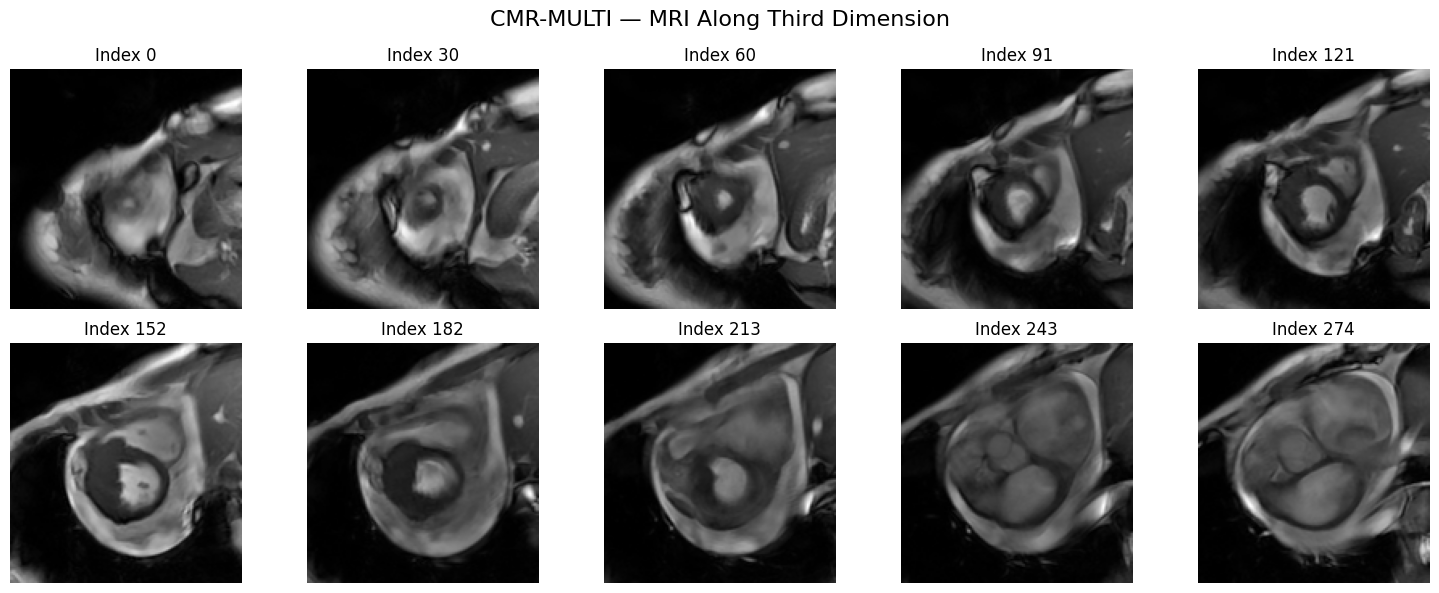

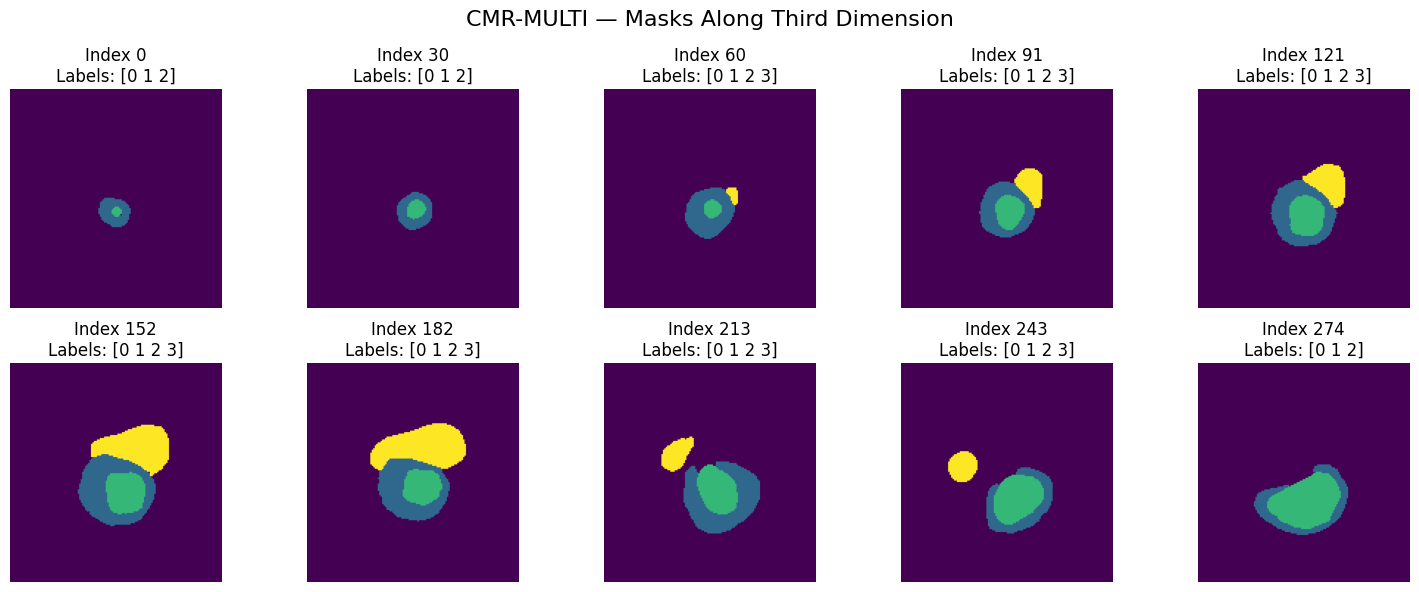

In [ ]:
# CMR-MULTI — CELL 10
# Visualize Positions Along the Third Dimension

import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# Load Case 001

filename = "CINE_SAX_001.nii.gz"

image_path = os.path.join(IMAGE_DIR, filename)
anno_path  = os.path.join(ANNO_DIR, filename)

image = nib.load(image_path).get_fdata()
mask  = nib.load(anno_path).get_fdata().astype(np.int64)

print("Case:", filename)
print("MRI shape:", image.shape)
print("Mask shape:", mask.shape)


# Select positions across third dimension

depth = image.shape[2]

indices = np.linspace(
    0,
    depth - 1,
    10,
    dtype=int
)

print("Displayed indices:", indices)


# MRI figure

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, z in zip(axes.flat, indices):

    ax.imshow(
        image[:, :, z],
        cmap="gray"
    )

    ax.set_title(f"Index {z}")
    ax.axis("off")

plt.suptitle(
    "CMR-MULTI — MRI Along Third Dimension",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Annotation figure

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, z in zip(axes.flat, indices):

    ax.imshow(
        mask[:, :, z],
        cmap="viridis",
        vmin=0,
        vmax=3
    )

    labels = np.unique(mask[:, :, z])

    ax.set_title(
        f"Index {z}\nLabels: {labels}"
    )

    ax.axis("off")

plt.suptitle(
    "CMR-MULTI — Masks Along Third Dimension",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Dataset Slice Distribution Analysis

In [ ]:
# CMR-MULTI — CELL 11
# Count 2D Annotated Planes Across All 105 Cases

import os
import nibabel as nib
import numpy as np

total_planes = 0
foreground_planes = 0
background_only_planes = 0

rv_planes = 0
myo_planes = 0
lv_planes = 0

all_three_planes = 0

planes_per_case = {}

print("Scanning all 105 CMR-MULTI cases...\n")

for i, filename in enumerate(image_files):

    anno_path = os.path.join(ANNO_DIR, filename)

    mask_nii = nib.load(anno_path)
    mask = np.asarray(mask_nii.dataobj).astype(np.int16)

    depth = mask.shape[2]

    case_foreground = 0

    for z in range(depth):

        slice_mask = mask[:, :, z]

        labels = np.unique(slice_mask)

        total_planes += 1

        # Any cardiac foreground?
        if np.any(slice_mask > 0):

            foreground_planes += 1
            case_foreground += 1

        else:

            background_only_planes += 1

        # Original CMR-MULTI labels
        if 1 in labels:
            myo_planes += 1

        if 2 in labels:
            lv_planes += 1

        if 3 in labels:
            rv_planes += 1

        if all(label in labels for label in [1, 2, 3]):
            all_three_planes += 1

    planes_per_case[filename] = {
        "total": depth,
        "foreground": case_foreground
    }

    if (i + 1) % 20 == 0:
        print(f"Processed {i + 1}/105 cases")


print("\n===== CMR-MULTI 2D PLANE SUMMARY =====")

print("Total planes:", total_planes)

print(
    "Foreground planes:",
    foreground_planes
)

print(
    "Background-only planes:",
    background_only_planes
)

print("\n===== STRUCTURE PRESENCE =====")

print(
    "Myocardium planes (original label 1):",
    myo_planes
)

print(
    "LV planes (original label 2):",
    lv_planes
)

print(
    "RV planes (original label 3):",
    rv_planes
)

print(
    "Planes containing all 3 structures:",
    all_three_planes
)


print("\n===== FOREGROUND PLANES PER CASE =====")

foreground_counts = [
    x["foreground"]
    for x in planes_per_case.values()
]

print(
    "Minimum:",
    min(foreground_counts)
)

print(
    "Maximum:",
    max(foreground_counts)
)

print(
    "Mean:",
    np.mean(foreground_counts)
)

print(
    "Median:",
    np.median(foreground_counts)
)


print("\n===== FIRST 10 CASES =====")

for filename in image_files[:10]:

    info = planes_per_case[filename]

    print(
        filename,
        "Total:",
        info["total"],
        "| Foreground:",
        info["foreground"]
    )

Scanning all 105 CMR-MULTI cases...

Processed 20/105 cases
Processed 40/105 cases
Processed 60/105 cases
Processed 80/105 cases
Processed 100/105 cases

===== CMR-MULTI 2D PLANE SUMMARY =====
Total planes: 29605
Foreground planes: 28430
Background-only planes: 1175

===== STRUCTURE PRESENCE =====
Myocardium planes (original label 1): 28430
LV planes (original label 2): 28175
RV planes (original label 3): 22025
Planes containing all 3 structures: 21996

===== FOREGROUND PLANES PER CASE =====
Minimum: 200
Maximum: 550
Mean: 270.76190476190476
Median: 250.0

===== FIRST 10 CASES =====
CINE_SAX_001.nii.gz Total: 275 | Foreground: 275
CINE_SAX_002.nii.gz Total: 360 | Foreground: 330
CINE_SAX_003.nii.gz Total: 330 | Foreground: 330
CINE_SAX_004.nii.gz Total: 250 | Foreground: 226
CINE_SAX_005.nii.gz Total: 225 | Foreground: 225
CINE_SAX_006.nii.gz Total: 275 | Foreground: 275
CINE_SAX_007.nii.gz Total: 360 | Foreground: 334
CINE_SAX_008.nii.gz Total: 330 | Foreground: 330
CINE_SAX_009.nii.g

# Case-Level Train/Validation/Test Split

In [ ]:
# CELL 12 — CASE-LEVEL TRAIN / VALIDATION / TEST SPLIT
# CMR-MULTI: Split Cases Before Extracting 2D Planes

import random
import os
import numpy as np

# REPRODUCIBILITY

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# GET ALL CASE NAMES

all_cases = sorted(image_files)

print("===== ORIGINAL DATASET =====")
print("Total cases:", len(all_cases))


# SHUFFLE CASES

shuffled_cases = all_cases.copy()

random.Random(SEED).shuffle(shuffled_cases)


# 70 / 15 / 15 CASE-LEVEL SPLIT

n_total = len(shuffled_cases)

n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)

train_cases = shuffled_cases[:n_train]

val_cases = shuffled_cases[
    n_train:n_train + n_val
]

test_cases = shuffled_cases[
    n_train + n_val:
]


# PRINT SPLIT SIZE

print("\n===== CASE-LEVEL SPLIT =====")

print("Train cases:", len(train_cases))
print("Validation cases:", len(val_cases))
print("Test cases:", len(test_cases))

print(
    "Total:",
    len(train_cases)
    + len(val_cases)
    + len(test_cases)
)


# CHECK FOR LEAKAGE

train_set = set(train_cases)
val_set   = set(val_cases)
test_set  = set(test_cases)

train_val_overlap = train_set & val_set
train_test_overlap = train_set & test_set
val_test_overlap = val_set & test_set

print("\n===== LEAKAGE CHECK =====")

print(
    "Train ∩ Validation:",
    len(train_val_overlap)
)

print(
    "Train ∩ Test:",
    len(train_test_overlap)
)

print(
    "Validation ∩ Test:",
    len(val_test_overlap)
)

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\n✓ No case overlap between splits.")


# SHOW FIRST FEW CASES

print("\n===== SAMPLE TRAIN CASES =====")

for case in train_cases[:10]:
    print(case)


print("\n===== SAMPLE VALIDATION CASES =====")

for case in val_cases[:5]:
    print(case)


print("\n===== SAMPLE TEST CASES =====")

for case in test_cases[:5]:
    print(case)

===== ORIGINAL DATASET =====
Total cases: 105

===== CASE-LEVEL SPLIT =====
Train cases: 73
Validation cases: 15
Test cases: 17
Total: 105

===== LEAKAGE CHECK =====
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

✓ No case overlap between splits.

===== SAMPLE TRAIN CASES =====
CINE_SAX_066.nii.gz
CINE_SAX_043.nii.gz
CINE_SAX_016.nii.gz
CINE_SAX_010.nii.gz
CINE_SAX_100.nii.gz
CINE_SAX_059.nii.gz
CINE_SAX_002.nii.gz
CINE_SAX_074.nii.gz
CINE_SAX_077.nii.gz
CINE_SAX_083.nii.gz

===== SAMPLE VALIDATION CASES =====
CINE_SAX_001.nii.gz
CINE_SAX_101.nii.gz
CINE_SAX_092.nii.gz
CINE_SAX_058.nii.gz
CINE_SAX_099.nii.gz

===== SAMPLE TEST CASES =====
CINE_SAX_103.nii.gz
CINE_SAX_005.nii.gz
CINE_SAX_055.nii.gz
CINE_SAX_076.nii.gz
CINE_SAX_012.nii.gz


# Build 2D Foreground Slice Indices

In [ ]:
# CELL 13 — BUILD 2D FOREGROUND SLICE INDICES
# CMR-MULTI: Create Leakage-Safe Train / Val / Test Samples

import os
import nibabel as nib
import numpy as np


# FUNCTION: BUILD SLICE INDEX FOR ONE SPLIT

def build_slice_index(case_list, split_name):

    slice_index = []

    # Structure counters using ORIGINAL CMR-MULTI labels
    myo_count = 0       # Label 1
    lv_count = 0        # Label 2
    rv_count = 0        # Label 3
    all_three_count = 0

    print(f"\nBuilding {split_name} slice index...")

    for i, filename in enumerate(case_list):

        anno_path = os.path.join(
            ANNO_DIR,
            filename
        )

        mask_nii = nib.load(anno_path)

        mask = np.asarray(
            mask_nii.dataobj
        ).astype(np.int16)

        depth = mask.shape[2]

        for z in range(depth):

            slice_mask = mask[:, :, z]

            # Keep only slices containing foreground

            if not np.any(slice_mask > 0):
                continue

            labels = np.unique(slice_mask)

            # Save case + slice position
            slice_index.append(
                (filename, z)
            )

            # Count structure presence

            if 1 in labels:
                myo_count += 1

            if 2 in labels:
                lv_count += 1

            if 3 in labels:
                rv_count += 1

            if (
                1 in labels
                and 2 in labels
                and 3 in labels
            ):
                all_three_count += 1


    # SUMMARY

    print(f"\n===== {split_name.upper()} =====")

    print(
        "Cases:",
        len(case_list)
    )

    print(
        "Foreground 2D slices:",
        len(slice_index)
    )

    print(
        "Myocardium slices (original label 1):",
        myo_count
    )

    print(
        "LV slices (original label 2):",
        lv_count
    )

    print(
        "RV slices (original label 3):",
        rv_count
    )

    print(
        "Slices containing RV + Myocardium + LV:",
        all_three_count
    )

    return slice_index


# BUILD ALL THREE SPLITS

train_index = build_slice_index(
    train_cases,
    "Train"
)

val_index = build_slice_index(
    val_cases,
    "Validation"
)

test_index = build_slice_index(
    test_cases,
    "Test"
)


# FINAL SUMMARY

print("\n" + "=" * 60)
print("FINAL CMR-MULTI 2D DATASET")
print("=" * 60)

print(
    "Train:",
    len(train_index),
    "foreground slices"
)

print(
    "Validation:",
    len(val_index),
    "foreground slices"
)

print(
    "Test:",
    len(test_index),
    "foreground slices"
)

print(
    "\nTotal usable foreground slices:",
    len(train_index)
    + len(val_index)
    + len(test_index)
)


# LEAKAGE SANITY CHECK

train_index_cases = {
    item[0] for item in train_index
}

val_index_cases = {
    item[0] for item in val_index
}

test_index_cases = {
    item[0] for item in test_index
}

assert train_index_cases.isdisjoint(val_index_cases)
assert train_index_cases.isdisjoint(test_index_cases)
assert val_index_cases.isdisjoint(test_index_cases)

print("\n✓ 2D slice indices remain case-level leakage-free.")


# SHOW SAMPLE INDEX ENTRIES

print("\nSample training entries:")

for item in train_index[:10]:
    print(item)


Building Train slice index...

===== TRAIN =====
Cases: 73
Foreground 2D slices: 20052
Myocardium slices (original label 1): 20052
LV slices (original label 2): 19871
RV slices (original label 3): 15397
Slices containing RV + Myocardium + LV: 15372

Building Validation slice index...

===== VALIDATION =====
Cases: 15
Foreground 2D slices: 3954
Myocardium slices (original label 1): 3954
LV slices (original label 2): 3896
RV slices (original label 3): 3115
Slices containing RV + Myocardium + LV: 3115

Building Test slice index...

===== TEST =====
Cases: 17
Foreground 2D slices: 4424
Myocardium slices (original label 1): 4424
LV slices (original label 2): 4408
RV slices (original label 3): 3513
Slices containing RV + Myocardium + LV: 3509

FINAL CMR-MULTI 2D DATASET
Train: 20052 foreground slices
Validation: 3954 foreground slices
Test: 4424 foreground slices

Total usable foreground slices: 28430

✓ 2D slice indices remain case-level leakage-free.

Sample training entries:
('CINE_SAX_0

# Label Remapping & Preprocessing

In [ ]:
# CELL 14 — LABEL REMAPPING & PREPROCESSING
# CMR-MULTI: Standardize Labels + Define Transforms

import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 1. LABEL REMAPPING
#
# Original CMR-MULTI:
#   0 = Background
#   1 = Myocardium
#   2 = LV
#   3 = RV
#
# Thesis standard:
#   0 = Background
#   1 = RV
#   2 = Myocardium
#   3 = LV
#
# Therefore:
#   0 -> 0
#   1 -> 2
#   2 -> 3
#   3 -> 1


def remap_cmr_mask(mask):

    mask = mask.astype(np.int64)

    remapped = np.zeros_like(
        mask,
        dtype=np.int64
    )

    remapped[mask == 0] = 0   # Background
    remapped[mask == 1] = 2   # Myocardium
    remapped[mask == 2] = 3   # LV
    remapped[mask == 3] = 1   # RV

    return remapped



# 2. TRAINING TRANSFORMS


train_transform = A.Compose([

    A.Resize(
        height=224,
        width=224
    ),

    A.HorizontalFlip(
        p=0.5
    ),

    A.Affine(
        scale=(0.90, 1.10),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.3
    ),

    A.GaussNoise(
        std_range=(0.01, 0.03),
        p=0.2
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=1.0
    ),

    ToTensorV2()
])


# 3. VALIDATION / TEST TRANSFORMS

eval_transform = A.Compose([

    A.Resize(
        height=224,
        width=224
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=1.0
    ),

    ToTensorV2()
])


# 4. VERIFY LABEL REMAPPING

test_original = np.array(
    [
        [0, 1],
        [2, 3]
    ],
    dtype=np.int64
)

test_remapped = remap_cmr_mask(
    test_original
)

print("===== LABEL REMAPPING CHECK =====")

print("\nOriginal CMR-MULTI:")
print(test_original)

print("\nRemapped thesis labels:")
print(test_remapped)

print("\nExpected:")
print(
    np.array([
        [0, 2],
        [3, 1]
    ])
)


# 5. FINAL LABEL DEFINITIONS

CLASS_NAMES = {
    0: "Background",
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

NUM_CLASSES = 4

print("\n===== FINAL THESIS LABELS =====")

for label, name in CLASS_NAMES.items():
    print(f"{label} = {name}")

print("\nNumber of classes:", NUM_CLASSES)

print("\n✓ CMR-MULTI preprocessing configuration ready.")

===== LABEL REMAPPING CHECK =====

Original CMR-MULTI:
[[0 1]
 [2 3]]

Remapped thesis labels:
[[0 2]
 [3 1]]

Expected:
[[0 2]
 [3 1]]

===== FINAL THESIS LABELS =====
0 = Background
1 = RV
2 = Myocardium
3 = LV

Number of classes: 4

✓ CMR-MULTI preprocessing configuration ready.


# CMR-MULTI PyTorch Dataset Class

In [ ]:
# CELL 15 — CMR-MULTI PYTORCH DATASET CLASS
# Load NIfTI → Extract 2D Slice → Normalize → Remap Labels

import os
import nibabel as nib
import numpy as np
import torch

from torch.utils.data import Dataset


class CMRMultiDataset(Dataset):

    def __init__(
        self,
        image_dir,
        anno_dir,
        slice_index,
        transform=None
    ):

        self.image_dir = image_dir
        self.anno_dir = anno_dir
        self.slice_index = slice_index
        self.transform = transform

        # Cache volumes after first access.
        # This avoids repeatedly loading the same NIfTI file.
        self.image_cache = {}
        self.mask_cache = {}


    def __len__(self):

        return len(self.slice_index)


    def _load_case(self, filename):


        # Load MRI if not already cached


        if filename not in self.image_cache:

            image_path = os.path.join(
                self.image_dir,
                filename
            )

            image_nii = nib.load(image_path)

            self.image_cache[filename] = np.asarray(
                image_nii.dataobj,
                dtype=np.float32
            )


        # Load mask if not already cached

        if filename not in self.mask_cache:

            mask_path = os.path.join(
                self.anno_dir,
                filename
            )

            mask_nii = nib.load(mask_path)

            self.mask_cache[filename] = np.asarray(
                mask_nii.dataobj,
                dtype=np.int16
            )


        return (
            self.image_cache[filename],
            self.mask_cache[filename]
        )


    def __getitem__(self, idx):


        # Get case name + 2D slice index

        filename, z = self.slice_index[idx]



        # Load full MRI + mask volume

        image_volume, mask_volume = self._load_case(
            filename
        )



        # Extract 2D slice

        image = image_volume[:, :, z].copy()

        mask = mask_volume[:, :, z].copy()


        # Per-slice min-max normalization
        # MRI → [0, 1]

        image_min = image.min()
        image_max = image.max()

        if image_max > image_min:

            image = (
                image - image_min
            ) / (
                image_max - image_min
            )

        else:

            image = np.zeros_like(
                image,
                dtype=np.float32
            )


        image = image.astype(
            np.float32
        )


        # Convert grayscale → 3 channels
        # Required for ImageNet-pretrained encoders

        image = np.stack(
            [image, image, image],
            axis=-1
        )


        # Remap CMR-MULTI labels
        #
        # Original:
        # 0 BG, 1 Myo, 2 LV, 3 RV
        #
        # Thesis:
        # 0 BG, 1 RV, 2 Myo, 3 LV


        mask = remap_cmr_mask(mask)


        # Apply augmentation / preprocessing

        if self.transform is not None:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]


        # Ensure correct tensor types

        if not torch.is_tensor(image):

            image = torch.from_numpy(
                image.transpose(2, 0, 1)
            ).float()

        else:

            image = image.float()


        if not torch.is_tensor(mask):

            mask = torch.from_numpy(
                mask
            ).long()

        else:

            mask = mask.long()


        return image, mask


print("✓ CMRMultiDataset class created successfully.")

✓ CMRMultiDataset class created successfully.


# Create Dataset Objects & Verify Real Samples

In [ ]:
# CELL 16 — CREATE DATASET OBJECTS & VERIFY REAL SAMPLES
# CMR-MULTI: Train / Validation / Test Dataset Check

import torch
import numpy as np


# 1. CREATE DATASET OBJECTS

train_dataset = CMRMultiDataset(
    image_dir=IMAGE_DIR,
    anno_dir=ANNO_DIR,
    slice_index=train_index,
    transform=train_transform
)

val_dataset = CMRMultiDataset(
    image_dir=IMAGE_DIR,
    anno_dir=ANNO_DIR,
    slice_index=val_index,
    transform=eval_transform
)

test_dataset = CMRMultiDataset(
    image_dir=IMAGE_DIR,
    anno_dir=ANNO_DIR,
    slice_index=test_index,
    transform=eval_transform
)


# 2. DATASET SIZES


print("===== DATASET SIZES =====")

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print(
    "Total:",
    len(train_dataset)
    + len(val_dataset)
    + len(test_dataset)
)


# 3. INSPECT ONE TRAINING SAMPLE

image, mask = train_dataset[0]

print("\n===== TRAIN SAMPLE =====")

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)

print(
    "Image min:",
    float(image.min())
)

print(
    "Image max:",
    float(image.max())
)

print(
    "Mask labels:",
    torch.unique(mask).tolist()
)


# 4. INSPECT MULTIPLE TRAINING SAMPLES

print("\n===== MULTIPLE SAMPLE CHECK =====")

sample_positions = [
    0,
    len(train_dataset) // 4,
    len(train_dataset) // 2,
    (3 * len(train_dataset)) // 4,
    len(train_dataset) - 1
]

for idx in sample_positions:

    img, msk = train_dataset[idx]

    filename, z = train_index[idx]

    print(
        f"Index {idx:5d}"
        f" | Case: {filename}"
        f" | Slice: {z:3d}"
        f" | Image: {tuple(img.shape)}"
        f" | Mask: {tuple(msk.shape)}"
        f" | Labels: {torch.unique(msk).tolist()}"
    )


# 5. FINAL SANITY CHECKS

assert image.shape == (3, 224, 224)
assert mask.shape == (224, 224)

assert image.dtype == torch.float32
assert mask.dtype == torch.int64

assert mask.min() >= 0
assert mask.max() <= 3

print("\n✓ Image dimensions are correct.")
print("✓ Mask dimensions are correct.")
print("✓ Tensor data types are correct.")
print("✓ Mask labels are within 0–3.")
print("✓ CMR-MULTI datasets are ready.")

===== DATASET SIZES =====
Train: 20052
Validation: 3954
Test: 4424
Total: 28430

===== TRAIN SAMPLE =====
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([224, 224])
Image dtype: torch.float32
Mask dtype: torch.int64
Image min: -2.1179039478302
Image max: 2.539809226989746
Mask labels: [0, 2, 3]

===== MULTIPLE SAMPLE CHECK =====
Index     0 | Case: CINE_SAX_066.nii.gz | Slice:   0 | Image: (3, 224, 224) | Mask: (224, 224) | Labels: [0, 2, 3]
Index  5013 | Case: CINE_SAX_034.nii.gz | Slice: 129 | Image: (3, 224, 224) | Mask: (224, 224) | Labels: [0, 1, 2, 3]
Index 10026 | Case: CINE_SAX_046.nii.gz | Slice: 207 | Image: (3, 224, 224) | Mask: (224, 224) | Labels: [0, 1, 2, 3]
Index 15039 | Case: CINE_SAX_003.nii.gz | Slice:  92 | Image: (3, 224, 224) | Mask: (224, 224) | Labels: [0, 1, 2, 3]
Index 20051 | Case: CINE_SAX_021.nii.gz | Slice: 224 | Image: (3, 224, 224) | Mask: (224, 224) | Labels: [0, 1, 2, 3]

✓ Image dimensions are correct.
✓ Mask dimensions are correct.
✓ T

# Visualize MRI & Remapped Ground-Truth Mask

===== VISUALIZATION SAMPLE =====
Dataset index: 37
Case: CINE_SAX_001.nii.gz
Slice: 37
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([224, 224])
Labels: [0, 1, 2, 3]


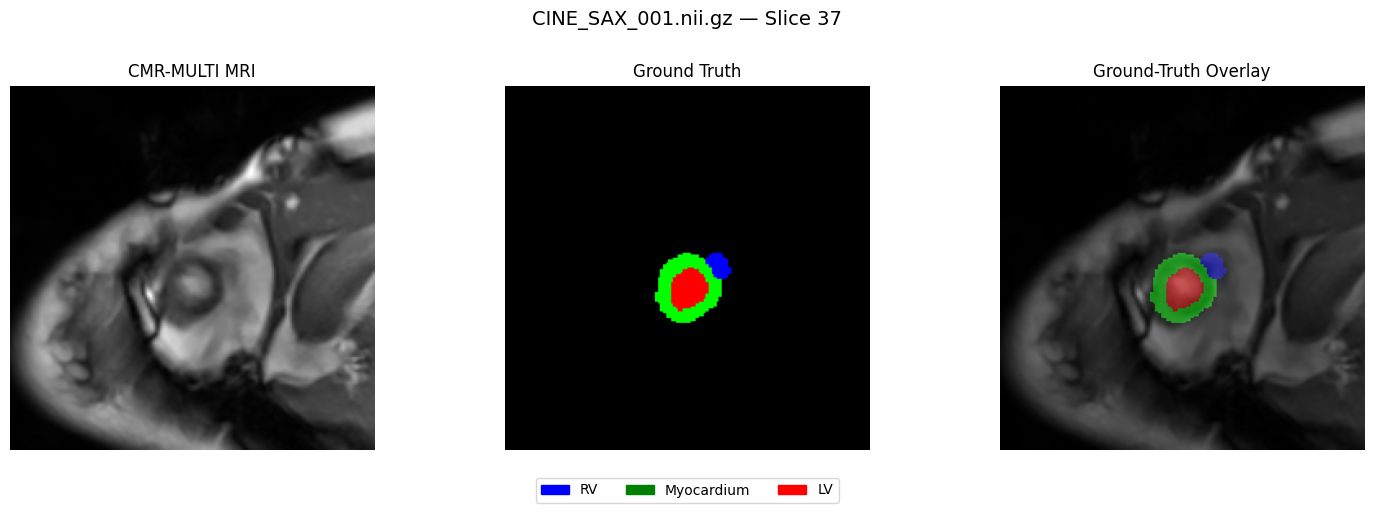

In [ ]:
# CELL 17 — VISUALIZE MRI & REMAPPED GROUND-TRUTH MASK
# CMR-MULTI: Verify RV / Myocardium / LV Segmentation

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import torch


# 1. FIND A VALIDATION SLICE CONTAINING ALL 3 STRUCTURES

sample_idx = None

for i in range(len(val_dataset)):

    _, temp_mask = val_dataset[i]

    labels = set(
        torch.unique(temp_mask).tolist()
    )

    if {1, 2, 3}.issubset(labels):
        sample_idx = i
        break


if sample_idx is None:
    raise RuntimeError(
        "No validation slice containing all three "
        "cardiac structures was found."
    )


# 2. LOAD SAMPLE

image, mask = val_dataset[sample_idx]

filename, z = val_index[sample_idx]

print("===== VISUALIZATION SAMPLE =====")
print("Dataset index:", sample_idx)
print("Case:", filename)
print("Slice:", z)
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Labels:", torch.unique(mask).tolist())


# 3. REVERSE IMAGENET NORMALIZATION
#    For visualization only

mean = np.array(
    [0.485, 0.456, 0.406]
).reshape(3, 1, 1)

std = np.array(
    [0.229, 0.224, 0.225]
).reshape(3, 1, 1)

image_np = image.cpu().numpy()

image_np = (
    image_np * std
) + mean

image_np = np.clip(
    image_np,
    0,
    1
)

# All 3 channels are copies of the grayscale MRI
image_gray = image_np[0]

mask_np = mask.cpu().numpy()


# 4. DEFINE THESIS CLASS COLORS
#
# 0 = Background
# 1 = RV           -> Blue
# 2 = Myocardium   -> Green
# 3 = LV           -> Red

color_mask = np.zeros(
    (224, 224, 3),
    dtype=np.float32
)

color_mask[mask_np == 1] = [0, 0, 1]  # RV
color_mask[mask_np == 2] = [0, 1, 0]  # Myocardium
color_mask[mask_np == 3] = [1, 0, 0]  # LV


# 5. DISPLAY MRI, MASK, AND OVERLAY

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


# Original MRI
axes[0].imshow(
    image_gray,
    cmap="gray"
)

axes[0].set_title(
    "CMR-MULTI MRI"
)

axes[0].axis("off")


# Ground-truth segmentation
axes[1].imshow(
    color_mask
)

axes[1].set_title(
    "Ground Truth"
)

axes[1].axis("off")


# MRI + segmentation overlay
axes[2].imshow(
    image_gray,
    cmap="gray"
)

axes[2].imshow(
    color_mask,
    alpha=0.45
)

axes[2].set_title(
    "Ground-Truth Overlay"
)

axes[2].axis("off")


# 6. LEGEND

legend_items = [

    mpatches.Patch(
        color="blue",
        label="RV"
    ),

    mpatches.Patch(
        color="green",
        label="Myocardium"
    ),

    mpatches.Patch(
        color="red",
        label="LV"
    )
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.02)
)


plt.suptitle(
    f"{filename} — Slice {z}",
    fontsize=14
)

plt.tight_layout(
    rect=[0, 0.07, 1, 0.93]
)

plt.show()

# Create DataLoaders & Verify Batch

In [ ]:
# CELL 18 — CREATE DATALOADERS & VERIFY BATCH
# CMR-MULTI: Train / Validation / Test DataLoaders

import torch
from torch.utils.data import DataLoader



# 1. SETTINGS


BATCH_SIZE = 8

print("===== DATALOADER SETTINGS =====")
print("Batch size:", BATCH_SIZE)
print("num_workers: 0")


# 2. CREATE DATALOADERS

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# 3. NUMBER OF BATCHES

print("\n===== NUMBER OF BATCHES =====")

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)


# 4. LOAD ONE TRAINING BATCH

images, masks = next(
    iter(train_loader)
)


print("\n===== TRAINING BATCH CHECK =====")

print(
    "Images shape:",
    images.shape
)

print(
    "Masks shape:",
    masks.shape
)

print(
    "Images dtype:",
    images.dtype
)

print(
    "Masks dtype:",
    masks.dtype
)

print(
    "Image min:",
    float(images.min())
)

print(
    "Image max:",
    float(images.max())
)

print(
    "Mask labels in batch:",
    torch.unique(masks).tolist()
)


# 5. SANITY CHECKS

assert images.ndim == 4
assert masks.ndim == 3

assert images.shape[1:] == (
    3,
    224,
    224
)

assert masks.shape[1:] == (
    224,
    224
)

assert images.dtype == torch.float32
assert masks.dtype == torch.int64

assert masks.min() >= 0
assert masks.max() <= 3


print("\n✓ Batch image dimensions correct.")
print("✓ Batch mask dimensions correct.")
print("✓ Tensor types correct.")
print("✓ Labels restricted to 0–3.")
print("✓ CMR-MULTI DataLoaders ready.")

===== DATALOADER SETTINGS =====
Batch size: 8
num_workers: 0

===== NUMBER OF BATCHES =====
Train batches: 2507
Validation batches: 495
Test batches: 553

===== TRAINING BATCH CHECK =====
Images shape: torch.Size([8, 3, 224, 224])
Masks shape: torch.Size([8, 224, 224])
Images dtype: torch.float32
Masks dtype: torch.int64
Image min: -2.1179039478302
Image max: 2.640000104904175
Mask labels in batch: [0, 1, 2, 3]

✓ Batch image dimensions correct.
✓ Batch mask dimensions correct.
✓ Tensor types correct.
✓ Labels restricted to 0–3.
✓ CMR-MULTI DataLoaders ready.


# Pretrained ResNet34 U-Net Setup

In [ ]:

# CELL 19 — MODEL 1: PRETRAINED RESNET34 U-NET
# CMR-MULTI: Model Setup + Forward-Pass Verification


import torch
import segmentation_models_pytorch as smp


# 1. DEVICE

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("===== DEVICE =====")
print("Using:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# 2. CREATE PRETRAINED RESNET34 U-NET

resnet_model = smp.Unet(
    encoder_name="resnet34",

    # ImageNet-pretrained encoder
    encoder_weights="imagenet",

    # MRI converted from grayscale → RGB
    in_channels=3,

    # BG + RV + Myocardium + LV
    classes=4
)

resnet_model = resnet_model.to(device)



# 3. PARAMETER COUNT

total_params = sum(
    p.numel()
    for p in resnet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet_model.parameters()
    if p.requires_grad
)

print("\n===== MODEL =====")

print(
    "Architecture:",
    "ResNet34 U-Net"
)

print(
    "Encoder:",
    "ImageNet-pretrained ResNet34"
)

print(
    "Output classes:",
    4
)

print(
    f"Total parameters: "
    f"{total_params:,}"
)

print(
    f"Trainable parameters: "
    f"{trainable_params:,}"
)


# 4. TEST ONE FORWARD PASS

resnet_model.eval()

sample_images, sample_masks = next(
    iter(train_loader)
)

sample_images = sample_images.to(device)

with torch.no_grad():

    sample_outputs = resnet_model(
        sample_images
    )


print("\n===== FORWARD PASS CHECK =====")

print(
    "Input:",
    sample_images.shape
)

print(
    "Output:",
    sample_outputs.shape
)

print(
    "Expected output:",
    (
        sample_images.shape[0],
        4,
        224,
        224
    )
)


# 5. VERIFY OUTPUT

assert sample_outputs.shape == (
    sample_images.shape[0],
    4,
    224,
    224
)

print(
    "\n✓ Forward pass successful."
)

print(
    "✓ Model produces 4-class "
    "segmentation logits."
)

print(
    "✓ Pretrained ResNet34 U-Net "
    "is ready for training setup."
)

===== DEVICE =====
Using: cuda
GPU: Tesla T4


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            


===== MODEL =====
Architecture: ResNet34 U-Net
Encoder: ImageNet-pretrained ResNet34
Output classes: 4
Total parameters: 24,436,804
Trainable parameters: 24,436,804

===== FORWARD PASS CHECK =====
Input: torch.Size([8, 3, 224, 224])
Output: torch.Size([8, 4, 224, 224])
Expected output: (8, 4, 224, 224)

✓ Forward pass successful.
✓ Model produces 4-class segmentation logits.
✓ Pretrained ResNet34 U-Net is ready for training setup.


In [ ]:
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.1 MB/s eta 0:00:00


In [ ]:
import segmentation_models_pytorch as smp

print(
    "segmentation_models_pytorch version:",
    smp.__version__
)

print(
    "✓ segmentation_models_pytorch imported successfully."
)

segmentation_models_pytorch version: 0.5.0
✓ segmentation_models_pytorch imported successfully.


# Loss Function, Optimizer & Training Configuration

In [ ]:
# CELL 20 — LOSS, OPTIMIZER & TRAINING CONFIGURATION
# Model 1: Pretrained ResNet34 U-Net on CMR-MULTI

import os
import torch
import torch.nn as nn


# 1. MULTICLASS DICE LOSS

class MulticlassDiceLoss(nn.Module):

    def __init__(
        self,
        num_classes=4,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(self, logits, targets):

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        targets_one_hot = torch.nn.functional.one_hot(
            targets,
            num_classes=self.num_classes
        )

        targets_one_hot = (
            targets_one_hot
            .permute(0, 3, 1, 2)
            .float()
        )

        dice_losses = []

        # Foreground classes only:
        # 1 = RV
        # 2 = Myocardium
        # 3 = LV
        for class_id in range(1, self.num_classes):

            pred = probabilities[:, class_id]

            true = targets_one_hot[:, class_id]

            intersection = (
                pred * true
            ).sum(dim=(1, 2))

            denominator = (
                pred.sum(dim=(1, 2))
                + true.sum(dim=(1, 2))
            )

            dice = (
                2.0 * intersection
                + self.smooth
            ) / (
                denominator
                + self.smooth
            )

            dice_losses.append(
                1.0 - dice.mean()
            )

        return torch.stack(
            dice_losses
        ).mean()



# 2. COMBINED CE + DICE LOSS

cross_entropy_loss = nn.CrossEntropyLoss()

dice_loss = MulticlassDiceLoss(
    num_classes=4
)


def loss_fn(logits, targets):

    ce = cross_entropy_loss(
        logits,
        targets
    )

    dice = dice_loss(
        logits,
        targets
    )

    return (
        0.5 * ce
        + 0.5 * dice
    )



# 3. OPTIMIZER
#
# Lower LR for pretrained encoder.
# Higher LR for newly initialized decoder/head.

encoder_params = list(
    resnet_model.encoder.parameters()
)

decoder_params = (
    list(resnet_model.decoder.parameters())
    + list(
        resnet_model.segmentation_head.parameters()
    )
)

optimizer = torch.optim.AdamW(

    [
        {
            "params": encoder_params,
            "lr": 1e-4
        },

        {
            "params": decoder_params,
            "lr": 5e-4
        }
    ],

    weight_decay=1e-4
)



# 4. LEARNING-RATE SCHEDULER

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)


# 5. TRAINING SETTINGS

MAX_EPOCHS = 30

EARLY_STOPPING_PATIENCE = 7



# 6. GOOGLE DRIVE CHECKPOINT PATH

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "Thesis_Checkpoints"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

RESNET_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "best_resnet34_unet_cmr_multi.pth"
)



# 7. PRINT CONFIGURATION

print("===== TRAINING CONFIGURATION =====")

print(
    "Loss:",
    "0.5 Cross-Entropy + 0.5 Foreground Dice"
)

print(
    "Encoder learning rate:",
    optimizer.param_groups[0]["lr"]
)

print(
    "Decoder learning rate:",
    optimizer.param_groups[1]["lr"]
)

print(
    "Weight decay:",
    1e-4
)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

print(
    "Scheduler:",
    "ReduceLROnPlateau"
)

print(
    "Checkpoint:",
    RESNET_CHECKPOINT
)


# 8. TEST LOSS ON ONE BATCH

resnet_model.train()

test_images, test_masks = next(
    iter(train_loader)
)

test_images = test_images.to(device)
test_masks = test_masks.to(device)

test_logits = resnet_model(
    test_images
)

test_loss = loss_fn(
    test_logits,
    test_masks
)

print(
    "\nTest combined loss:",
    float(test_loss.item())
)

print(
    "\n✓ Loss function works."
)

print(
    "✓ Optimizer configured."
)

print(
    "✓ Scheduler configured."
)

print(
    "✓ Checkpoint path ready."
)

===== TRAINING CONFIGURATION =====
Loss: 0.5 Cross-Entropy + 0.5 Foreground Dice
Encoder learning rate: 0.0001
Decoder learning rate: 0.0005
Weight decay: 0.0001
Maximum epochs: 30
Early stopping patience: 7
Scheduler: ReduceLROnPlateau
Checkpoint: /content/drive/MyDrive/Thesis_Checkpoints/best_resnet34_unet_cmr_multi.pth

Test combined loss: 1.0538923740386963

✓ Loss function works.
✓ Optimizer configured.
✓ Scheduler configured.
✓ Checkpoint path ready.


# Validation Dice Function + Drive Check

In [ ]:
# CELL 21 — VALIDATION DICE FUNCTION + DRIVE CHECK
# Model 1: ResNet34 U-Net on CMR-MULTI

import os
import torch
import numpy as np


# 1. VERIFY GOOGLE DRIVE

print("===== GOOGLE DRIVE CHECK =====")

drive_root = "/content/drive/MyDrive"

print(
    "Google Drive mounted:",
    os.path.exists(drive_root)
)

print(
    "Checkpoint directory exists:",
    os.path.exists(CHECKPOINT_DIR)
)

if not os.path.exists(drive_root):

    print(
        "\n⚠ Google Drive does not appear to be mounted."
    )

else:

    print(
        "✓ Google Drive is available."
    )



# 2. HARD-DICE FUNCTION

def calculate_dice_per_class(
    predictions,
    targets,
    num_classes=4,
    smooth=1e-6
):

    dice_scores = []

    # Foreground only:
    # 1 = RV
    # 2 = Myocardium
    # 3 = LV

    for class_id in range(1, num_classes):

        pred_class = (
            predictions == class_id
        ).float()

        true_class = (
            targets == class_id
        ).float()

        intersection = (
            pred_class * true_class
        ).sum(dim=(1, 2))

        denominator = (
            pred_class.sum(dim=(1, 2))
            + true_class.sum(dim=(1, 2))
        )

        dice = (
            2.0 * intersection
            + smooth
        ) / (
            denominator
            + smooth
        )

        dice_scores.append(
            dice
        )

    return dice_scores



# 3. VALIDATION FUNCTION


@torch.no_grad()
def validate_model(
    model,
    loader,
    device
):

    model.eval()

    total_loss = 0.0

    rv_scores = []
    myo_scores = []
    lv_scores = []

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits = model(images)

        loss = loss_fn(
            logits,
            masks
        )

        total_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        class_dice = calculate_dice_per_class(
            predictions,
            masks,
            num_classes=4
        )

        rv_scores.extend(
            class_dice[0].cpu().tolist()
        )

        myo_scores.extend(
            class_dice[1].cpu().tolist()
        )

        lv_scores.extend(
            class_dice[2].cpu().tolist()
        )

    # FINAL VALIDATION RESULTS


    avg_loss = (
        total_loss
        / len(loader.dataset)
    )

    rv_dice = float(
        np.mean(rv_scores)
    )

    myo_dice = float(
        np.mean(myo_scores)
    )

    lv_dice = float(
        np.mean(lv_scores)
    )

    mean_dice = float(
        np.mean([
            rv_dice,
            myo_dice,
            lv_dice
        ])
    )

    return {
        "loss": avg_loss,
        "rv": rv_dice,
        "myo": myo_dice,
        "lv": lv_dice,
        "mean": mean_dice
    }


print(
    "\n✓ Validation Dice function created."
)

print(
    "Classes evaluated:"
)

print(
    "1 = RV"
)

print(
    "2 = Myocardium"
)

print(
    "3 = LV"
)

===== GOOGLE DRIVE CHECK =====
Google Drive mounted: True
Checkpoint directory exists: True
✓ Google Drive is available.

✓ Validation Dice function created.
Classes evaluated:
1 = RV
2 = Myocardium
3 = LV


# Baseline Validation Before Training

In [ ]:
# CELL 22 — BASELINE VALIDATION BEFORE TRAINING
# Model 1: ResNet34 U-Net on CMR-MULTI

import time



# 1. RUN BASELINE VALIDATION

print("===== BASELINE VALIDATION =====")
print("Evaluating model before training...\n")

start_time = time.time()

baseline_results = validate_model(
    resnet_model,
    val_loader,
    device
)

elapsed_time = time.time() - start_time


# 2. DISPLAY RESULTS

print("===== UNTRAINED BASELINE RESULTS =====")

print(
    f"Validation Loss: "
    f"{baseline_results['loss']:.4f}"
)

print(
    f"RV Dice:         "
    f"{baseline_results['rv']:.4f}"
)

print(
    f"Myocardium Dice: "
    f"{baseline_results['myo']:.4f}"
)

print(
    f"LV Dice:         "
    f"{baseline_results['lv']:.4f}"
)

print(
    f"Mean Dice:       "
    f"{baseline_results['mean']:.4f}"
)

print(
    f"\nValidation time: "
    f"{elapsed_time / 60:.2f} minutes"
)

print(
    "\n✓ Baseline validation complete."
)

===== BASELINE VALIDATION =====
Evaluating model before training...

===== UNTRAINED BASELINE RESULTS =====
Validation Loss: 1.0809
RV Dice:         0.0242
Myocardium Dice: 0.0341
LV Dice:         0.0474
Mean Dice:       0.0352

Validation time: 0.49 minutes

✓ Baseline validation complete.


# ResNet34 U-Net Training Loop

In [ ]:
# CELL 23 — TRAIN RESNET34 U-NET
# CMR-MULTI

import time
import torch
import numpy as np


# 1. MIXED PRECISION SETUP

use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)


# 2. TRAINING HISTORY

history = {
    "train_loss": [],
    "val_loss": [],
    "rv": [],
    "myo": [],
    "lv": [],
    "mean": []
}


# 3. BEST-MODEL TRACKING

best_val_dice = -1.0
best_epoch = 0
epochs_without_improvement = 0


print("==============================================")
print("RESNET34 U-NET — CMR-MULTI TRAINING")
print("==============================================")

print(f"Training slices:   {len(train_dataset):,}")
print(f"Validation slices: {len(val_dataset):,}")
print(f"Training batches:  {len(train_loader):,}")
print(f"Validation batches:{len(val_loader):,}")

print(f"\nMaximum epochs: {MAX_EPOCHS}")
print(
    f"Early stopping patience: "
    f"{EARLY_STOPPING_PATIENCE}"
)

print(f"Mixed precision: {use_amp}")

print(
    f"\nCheckpoint:\n{RESNET_CHECKPOINT}"
)

print("==============================================\n")


# 4. TRAINING LOOP

training_start = time.time()


for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start = time.time()

    # TRAIN

    resnet_model.train()

    running_train_loss = 0.0


    for batch_idx, (images, masks) in enumerate(
        train_loader,
        start=1
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )


        # Forward pass with AMP

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            logits = resnet_model(
                images
            )

            loss = loss_fn(
                logits,
                masks
            )


        # Backpropagation

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()


        running_train_loss += (
            loss.item()
            * images.size(0)
        )


        # Progress report every 500 batches

        if (
            batch_idx % 500 == 0
            or batch_idx == len(train_loader)
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"Batch {batch_idx:04d}/"
                f"{len(train_loader):04d} | "
                f"Loss {loss.item():.4f}"
            )


    train_loss = (
        running_train_loss
        / len(train_loader.dataset)
    )


    # VALIDATION

    val_results = validate_model(
        resnet_model,
        val_loader,
        device
    )


    val_loss = val_results["loss"]
    rv_dice = val_results["rv"]
    myo_dice = val_results["myo"]
    lv_dice = val_results["lv"]
    mean_dice = val_results["mean"]


    # SCHEDULER

    scheduler.step(
        mean_dice
    )


    # SAVE HISTORY

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["rv"].append(
        rv_dice
    )

    history["myo"].append(
        myo_dice
    )

    history["lv"].append(
        lv_dice
    )

    history["mean"].append(
        mean_dice
    )


    # CHECK FOR NEW BEST MODEL

    improved = (
        mean_dice > best_val_dice
    )


    if improved:

        best_val_dice = mean_dice
        best_epoch = epoch

        epochs_without_improvement = 0


        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    resnet_model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "val_results":
                    val_results,

                "history":
                    history
            },

            RESNET_CHECKPOINT
        )


    else:

        epochs_without_improvement += 1


    # EPOCH SUMMARY

    epoch_time = (
        time.time()
        - epoch_start
    )


    encoder_lr = (
        optimizer.param_groups[0]["lr"]
    )

    decoder_lr = (
        optimizer.param_groups[1]["lr"]
    )


    print("\n----------------------------------------------")

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f}"
    )

    print(
        f"RV Dice:    {rv_dice:.4f}"
    )

    print(
        f"Myo Dice:   {myo_dice:.4f}"
    )

    print(
        f"LV Dice:    {lv_dice:.4f}"
    )

    print(
        f"Mean Dice:  {mean_dice:.4f}"
    )

    print(
        f"Encoder LR: {encoder_lr:.2e}"
    )

    print(
        f"Decoder LR: {decoder_lr:.2e}"
    )

    print(
        f"Epoch Time: {epoch_time / 60:.2f} min"
    )


    if improved:

        print(
            f"★ NEW BEST MODEL — "
            f"Mean Dice {best_val_dice:.4f}"
        )

        print(
            "✓ Checkpoint saved to Google Drive"
        )

    else:

        print(
            "No improvement: "
            f"{epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE}"
        )


    print("----------------------------------------------\n")


    # EARLY STOPPING

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "Early stopping triggered."
        )

        break


# 5. FINAL TRAINING SUMMARY

total_training_time = (
    time.time()
    - training_start
)


print("\n==============================================")
print("TRAINING COMPLETE")
print("==============================================")

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best validation mean Dice: "
    f"{best_val_dice:.4f}"
)

print(
    f"Total training time: "
    f"{total_training_time / 60:.2f} minutes"
)

print(
    f"\nBest checkpoint:\n"
    f"{RESNET_CHECKPOINT}"
)

print("==============================================")

RESNET34 U-NET — CMR-MULTI TRAINING
Training slices:   20,052
Validation slices: 3,954
Training batches:  2,507
Validation batches:495

Maximum epochs: 30
Early stopping patience: 7
Mixed precision: True

Checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_resnet34_unet_cmr_multi.pth

Epoch 01 | Batch 0500/2507 | Loss 0.1611
Epoch 01 | Batch 1000/2507 | Loss 0.1513
Epoch 01 | Batch 1500/2507 | Loss 0.1228
Epoch 01 | Batch 2000/2507 | Loss 0.0991
Epoch 01 | Batch 2500/2507 | Loss 0.0852
Epoch 01 | Batch 2507/2507 | Loss 0.2377

----------------------------------------------
Epoch 01/30
Train Loss: 0.1463
Val Loss:   0.1322
RV Dice:    0.7461
Myo Dice:   0.8663
LV Dice:    0.9107
Mean Dice:  0.8410
Encoder LR: 1.00e-04
Decoder LR: 5.00e-04
Epoch Time: 4.28 min
★ NEW BEST MODEL — Mean Dice 0.8410
✓ Checkpoint saved to Google Drive
----------------------------------------------

Epoch 02 | Batch 0500/2507 | Loss 0.1526
Epoch 02 | Batch 1000/2507 | Loss 0.1381
Epoch 02 | Batch 1500/2

# Reload Best ResNet34 U-Net Checkpoint

In [ ]:
# CELL 24 — RELOAD BEST RESNET34 U-NET CHECKPOINT
# CMR-MULTI

import os
import torch
import segmentation_models_pytorch as smp


# 1. CHECK CHECKPOINT

print("===== CHECKPOINT CHECK =====")

print(
    "Checkpoint exists:",
    os.path.exists(RESNET_CHECKPOINT)
)

print(
    "Checkpoint:",
    RESNET_CHECKPOINT
)

assert os.path.exists(
    RESNET_CHECKPOINT
), "Best ResNet checkpoint was not found."


# 2. RECREATE MODEL

best_resnet_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=4
).to(device)


# 3. LOAD CHECKPOINT

checkpoint = torch.load(
    RESNET_CHECKPOINT,
    map_location=device,
    weights_only=False
)

best_resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_resnet_model.eval()


# 4. CHECK SAVED INFORMATION

print("\n===== SAVED CHECKPOINT =====")

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)

print(
    "\nSaved validation results:"
)

print(
    checkpoint["val_results"]
)


# 5. VERIFY FORWARD PASS

test_images, test_masks = next(
    iter(test_loader)
)

test_images = test_images.to(device)

with torch.no_grad():

    test_logits = best_resnet_model(
        test_images
    )


print("\n===== TEST FORWARD PASS =====")

print(
    "Input:",
    test_images.shape
)

print(
    "Output:",
    test_logits.shape
)

assert test_logits.shape == (
    test_images.shape[0],
    4,
    224,
    224
)


print(
    "\n✓ Best checkpoint loaded successfully."
)

print(
    "✓ Model is in evaluation mode."
)

print(
    "✓ Ready for final test-set evaluation."
)

===== CHECKPOINT CHECK =====
Checkpoint exists: True
Checkpoint: /content/drive/MyDrive/Thesis_Checkpoints/best_resnet34_unet_cmr_multi.pth

===== SAVED CHECKPOINT =====
Best epoch: 17
Best validation Dice: 0.8573959260650912

Saved validation results:
{'loss': 0.13145571138726742, 'rv': 0.784960540964149, 'myo': 0.8734010811967072, 'lv': 0.9138261560344173, 'mean': 0.8573959260650912}

===== TEST FORWARD PASS =====
Input: torch.Size([8, 3, 224, 224])
Output: torch.Size([8, 4, 224, 224])

✓ Best checkpoint loaded successfully.
✓ Model is in evaluation mode.
✓ Ready for final test-set evaluation.


# Test Metric Functions

In [ ]:
# CELL 25 — FINAL TEST METRIC FUNCTIONS
# CMR-MULTI
#
# Metrics:
#   Dice
#   IoU
#   ROC-AUC
#   SSIM
#   Hausdorff Distance
#   HD95

import numpy as np
import torch

from sklearn.metrics import roc_auc_score
from skimage.metrics import structural_similarity as ssim
from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import distance_transform_edt


# 1. CLASS INFORMATION

CLASS_NAMES = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

FOREGROUND_CLASSES = [1, 2, 3]

SMOOTH = 1e-6


# 2. DICE

def binary_dice(
    pred,
    true,
    smooth=SMOOTH
):

    pred = pred.astype(bool)
    true = true.astype(bool)

    intersection = np.logical_and(
        pred,
        true
    ).sum()

    denominator = (
        pred.sum()
        + true.sum()
    )

    return (
        2.0 * intersection
        + smooth
    ) / (
        denominator
        + smooth
    )


# 3. IoU

def binary_iou(
    pred,
    true,
    smooth=SMOOTH
):

    pred = pred.astype(bool)
    true = true.astype(bool)

    intersection = np.logical_and(
        pred,
        true
    ).sum()

    union = np.logical_or(
        pred,
        true
    ).sum()

    return (
        intersection
        + smooth
    ) / (
        union
        + smooth
    )


# 4. SSIM

def binary_ssim(
    pred,
    true
):

    pred = pred.astype(
        np.float32
    )

    true = true.astype(
        np.float32
    )

    return ssim(
        true,
        pred,
        data_range=1.0
    )


# 5. HAUSDORFF DISTANCE

def hausdorff_distance(
    pred,
    true
):

    pred = pred.astype(bool)
    true = true.astype(bool)

    pred_points = np.argwhere(
        pred
    )

    true_points = np.argwhere(
        true
    )

    # Boundary metric is undefined if either
    # segmentation is empty.
    if (
        len(pred_points) == 0
        or len(true_points) == 0
    ):
        return np.nan

    forward = directed_hausdorff(
        pred_points,
        true_points
    )[0]

    backward = directed_hausdorff(
        true_points,
        pred_points
    )[0]

    return max(
        forward,
        backward
    )


# 6. HD95

def hd95_distance(
    pred,
    true
):

    pred = pred.astype(bool)
    true = true.astype(bool)

    if (
        pred.sum() == 0
        or true.sum() == 0
    ):
        return np.nan


    # Distance from every foreground pixel in
    # pred to nearest foreground pixel in true.

    distance_to_true = (
        distance_transform_edt(
            ~true
        )
    )

    distance_to_pred = (
        distance_transform_edt(
            ~pred
        )
    )


    pred_to_true = (
        distance_to_true[pred]
    )

    true_to_pred = (
        distance_to_pred[true]
    )


    all_distances = np.concatenate(
        [
            pred_to_true,
            true_to_pred
        ]
    )


    return float(
        np.percentile(
            all_distances,
            95
        )
    )


# 7. QUICK SANITY CHECK

dummy_true = np.zeros(
    (224, 224),
    dtype=np.uint8
)

dummy_pred = np.zeros(
    (224, 224),
    dtype=np.uint8
)

dummy_true[
    80:120,
    80:120
] = 1

dummy_pred[
    80:120,
    80:120
] = 1


print("===== METRIC FUNCTION CHECK =====")

print(
    "Dice:",
    binary_dice(
        dummy_pred,
        dummy_true
    )
)

print(
    "IoU:",
    binary_iou(
        dummy_pred,
        dummy_true
    )
)

print(
    "SSIM:",
    binary_ssim(
        dummy_pred,
        dummy_true
    )
)

print(
    "Hausdorff:",
    hausdorff_distance(
        dummy_pred,
        dummy_true
    )
)

print(
    "HD95:",
    hd95_distance(
        dummy_pred,
        dummy_true
    )
)


print(
    "\n✓ Final test metric functions created."
)

print(
    "✓ Classes: RV, Myocardium, LV."
)

print(
    "✓ Boundary distances will be reported in pixels at 224×224."
)

===== METRIC FUNCTION CHECK =====
Dice: 1.0
IoU: 1.0
SSIM: 1.0
Hausdorff: 0.0
HD95: 0.0

✓ Final test metric functions created.
✓ Classes: RV, Myocardium, LV.
✓ Boundary distances will be reported in pixels at 224×224.


# ResNet34 U-Net Test Evaluation

In [ ]:
# CELL 26 — FINAL RESNET34 U-NET TEST EVALUATION
# CMR-MULTI
#
# Computes:
#   Dice
#   IoU
#   SSIM
#   Hausdorff Distance
#   HD95
#
# Also collects reproducible probability samples
# for ROC-AUC + ROC curves in Cell 27.

import time
import numpy as np
import torch


# 1. STORAGE

metric_storage = {
    class_id: {
        "dice": [],
        "iou": [],
        "ssim": [],
        "hausdorff": [],
        "hd95": []
    }
    for class_id in FOREGROUND_CLASSES
}


# ROC storage
roc_true = {
    class_id: []
    for class_id in FOREGROUND_CLASSES
}

roc_prob = {
    class_id: []
    for class_id in FOREGROUND_CLASSES
}


# 2. REPRODUCIBLE ROC SAMPLING

ROC_PIXELS_PER_BATCH = 20000

rng = np.random.default_rng(
    42
)


# 3. MODEL EVALUATION MODE

best_resnet_model.eval()

print("==============================================")
print("RESNET34 U-NET — FINAL TEST EVALUATION")
print("==============================================")

print(
    f"Test slices: {len(test_dataset):,}"
)

print(
    f"Test batches: {len(test_loader):,}"
)

print(
    "ROC pixels sampled per batch:",
    f"{ROC_PIXELS_PER_BATCH:,}"
)

print(
    "\nRunning final test evaluation..."
)


start_time = time.time()


# 4. TEST LOOP

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        test_loader,
        start=1
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        # MODEL PREDICTION

        logits = best_resnet_model(
            images
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        # Move masks/predictions to CPU once
        masks_np = (
            masks
            .cpu()
            .numpy()
        )

        predictions_np = (
            predictions
            .cpu()
            .numpy()
        )

        probabilities_np = (
            probabilities
            .cpu()
            .numpy()
        )


        # 5. SEGMENTATION METRICS — PER SLICE

        batch_size_current = (
            masks_np.shape[0]
        )


        for sample_idx in range(
            batch_size_current
        ):

            true_mask = (
                masks_np[sample_idx]
            )

            pred_mask = (
                predictions_np[sample_idx]
            )


            for class_id in FOREGROUND_CLASSES:

                true_binary = (
                    true_mask == class_id
                ).astype(np.uint8)

                pred_binary = (
                    pred_mask == class_id
                ).astype(np.uint8)


                # Dice
                metric_storage[
                    class_id
                ]["dice"].append(

                    binary_dice(
                        pred_binary,
                        true_binary
                    )
                )


                # IoU
                metric_storage[
                    class_id
                ]["iou"].append(

                    binary_iou(
                        pred_binary,
                        true_binary
                    )
                )


                # SSIM
                metric_storage[
                    class_id
                ]["ssim"].append(

                    binary_ssim(
                        pred_binary,
                        true_binary
                    )
                )


                # Hausdorff
                metric_storage[
                    class_id
                ]["hausdorff"].append(

                    hausdorff_distance(
                        pred_binary,
                        true_binary
                    )
                )


                # HD95
                metric_storage[
                    class_id
                ]["hd95"].append(

                    hd95_distance(
                        pred_binary,
                        true_binary
                    )
                )


        # 6. ROC-AUC PIXEL SAMPLING

        flat_masks = (
            masks_np.reshape(-1)
        )

        total_pixels = (
            flat_masks.shape[0]
        )


        sample_count = min(
            ROC_PIXELS_PER_BATCH,
            total_pixels
        )


        sampled_indices = rng.choice(
            total_pixels,
            size=sample_count,
            replace=False
        )


        for class_id in FOREGROUND_CLASSES:

            # Ground-truth binary labels
            binary_truth = (
                flat_masks[
                    sampled_indices
                ] == class_id
            ).astype(np.uint8)


            # Probability for this class
            class_probabilities = (
                probabilities_np[
                    :,
                    class_id,
                    :,
                    :
                ]
                .reshape(-1)[
                    sampled_indices
                ]
            )


            roc_true[
                class_id
            ].append(
                binary_truth
            )

            roc_prob[
                class_id
            ].append(
                class_probabilities
            )


        # Progress

        if (
            batch_idx % 100 == 0
            or batch_idx == len(test_loader)
        ):

            print(
                f"Processed "
                f"{batch_idx:03d}/"
                f"{len(test_loader):03d} "
                f"test batches"
            )


# 7. COMBINE ROC ARRAYS

for class_id in FOREGROUND_CLASSES:

    roc_true[class_id] = np.concatenate(
        roc_true[class_id]
    )

    roc_prob[class_id] = np.concatenate(
        roc_prob[class_id]
    )


# 8. CALCULATE FINAL CLASS RESULTS

resnet_test_results = {}


for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    results = {}


    results["dice"] = float(
        np.mean(
            metric_storage[
                class_id
            ]["dice"]
        )
    )


    results["iou"] = float(
        np.mean(
            metric_storage[
                class_id
            ]["iou"]
        )
    )


    results["ssim"] = float(
        np.mean(
            metric_storage[
                class_id
            ]["ssim"]
        )
    )


    results["hausdorff"] = float(
        np.nanmean(
            metric_storage[
                class_id
            ]["hausdorff"]
        )
    )


    results["hd95"] = float(
        np.nanmean(
            metric_storage[
                class_id
            ]["hd95"]
        )
    )


    results["valid_boundary_slices"] = int(
        np.sum(
            ~np.isnan(
                metric_storage[
                    class_id
                ]["hausdorff"]
            )
        )
    )


    resnet_test_results[
        class_name
    ] = results


# 9. MACRO AVERAGES

resnet_macro = {}


for metric_name in [
    "dice",
    "iou",
    "ssim",
    "hausdorff",
    "hd95"
]:

    resnet_macro[
        metric_name
    ] = float(
        np.mean([
            resnet_test_results[
                CLASS_NAMES[class_id]
            ][metric_name]

            for class_id
            in FOREGROUND_CLASSES
        ])
    )


# 10. DISPLAY RESULTS

elapsed = (
    time.time()
    - start_time
)


print("\n==============================================")
print("FINAL RESNET34 U-NET TEST RESULTS")
print("==============================================")


for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    r = resnet_test_results[
        class_name
    ]

    print(
        f"\n{class_name}"
    )

    print(
        f"Dice:       {r['dice']:.4f}"
    )

    print(
        f"IoU:        {r['iou']:.4f}"
    )

    print(
        f"SSIM:       {r['ssim']:.4f}"
    )

    print(
        f"Hausdorff:  "
        f"{r['hausdorff']:.4f}"
    )

    print(
        f"HD95:       {r['hd95']:.4f}"
    )

    print(
        "Valid boundary slices:",
        r["valid_boundary_slices"]
    )


print(
    "\n----------------------------------------------"
)

print("MACRO AVERAGE")

print(
    f"Dice:       "
    f"{resnet_macro['dice']:.4f}"
)

print(
    f"IoU:        "
    f"{resnet_macro['iou']:.4f}"
)

print(
    f"SSIM:       "
    f"{resnet_macro['ssim']:.4f}"
)

print(
    f"Hausdorff:  "
    f"{resnet_macro['hausdorff']:.4f}"
)

print(
    f"HD95:       "
    f"{resnet_macro['hd95']:.4f}"
)

print(
    "----------------------------------------------"
)


print(
    f"\nEvaluation time: "
    f"{elapsed / 60:.2f} minutes"
)


print("\n===== ROC DATA =====")

for class_id in FOREGROUND_CLASSES:

    print(
        f"{CLASS_NAMES[class_id]}: "
        f"{len(roc_true[class_id]):,} "
        "sampled pixels"
    )


print(
    "\n✓ Final segmentation metrics calculated."
)

print(
    "✓ ROC probability data collected."
)

print(
    "✓ Ready for ROC-AUC calculation and visualization."
)

RESNET34 U-NET — FINAL TEST EVALUATION
Test slices: 4,424
Test batches: 553
ROC pixels sampled per batch: 20,000

Running final test evaluation...
Processed 100/553 test batches
Processed 200/553 test batches
Processed 300/553 test batches
Processed 400/553 test batches
Processed 500/553 test batches
Processed 553/553 test batches

FINAL RESNET34 U-NET TEST RESULTS

RV
Dice:       0.7516
IoU:        0.6820
SSIM:       0.9731
Hausdorff:  10.6201
HD95:       5.0405
Valid boundary slices: 3420

Myocardium
Dice:       0.8678
IoU:        0.7810
SSIM:       0.9615
Hausdorff:  6.1117
HD95:       2.1263
Valid boundary slices: 4424

LV
Dice:       0.9148
IoU:        0.8622
SSIM:       0.9844
Hausdorff:  4.4614
HD95:       1.2353
Valid boundary slices: 4396

----------------------------------------------
MACRO AVERAGE
Dice:       0.8447
IoU:        0.7751
SSIM:       0.9730
Hausdorff:  7.0644
HD95:       2.8007
----------------------------------------------

Evaluation time: 3.17 minutes

===== 

# ROC-AUC + ROC Curve Visualization

RESNET34 U-NET — CMR-MULTI ROC-AUC
RV          : 0.9967
Myocardium  : 0.9981
LV          : 0.9995
----------------------------------------------
Macro Average: 0.9981


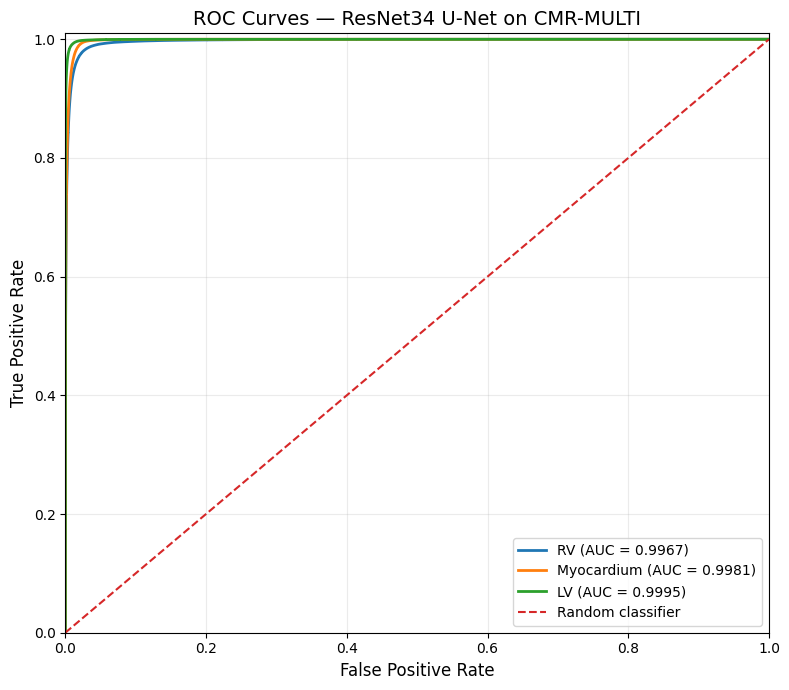


ROC figure saved to:
/content/drive/MyDrive/Thesis_Figures/CMR_MULTI_ResNet34_UNet_ROC.png

✓ ROC-AUC calculated.
✓ ROC curves visualized.
✓ Thesis-quality ROC figure saved to Google Drive.


In [ ]:
# CELL 27 — ROC-AUC + ROC CURVE VISUALIZATION
# Model 1: ResNet34 U-Net
# CMR-MULTI

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)


# 1. CALCULATE ROC CURVES + AUC

resnet_roc_results = {}


for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    y_true = roc_true[
        class_id
    ]

    y_prob = roc_prob[
        class_id
    ]


    # ROC-AUC
    auc_value = roc_auc_score(
        y_true,
        y_prob
    )


    # ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob
    )


    resnet_roc_results[
        class_name
    ] = {
        "auc": float(auc_value),
        "fpr": fpr,
        "tpr": tpr
    }


# 2. MACRO ROC-AUC
#
# Mean of the three one-vs-rest class AUC values.

resnet_macro_auc = float(
    np.mean([
        resnet_roc_results[
            CLASS_NAMES[class_id]
        ]["auc"]

        for class_id
        in FOREGROUND_CLASSES
    ])
)


# 3. PRINT ROC-AUC RESULTS

print(
    "=============================================="
)

print(
    "RESNET34 U-NET — CMR-MULTI ROC-AUC"
)

print(
    "=============================================="
)


for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    print(
        f"{class_name:<12}: "
        f"{resnet_roc_results[class_name]['auc']:.4f}"
    )


print(
    "----------------------------------------------"
)

print(
    f"Macro Average: "
    f"{resnet_macro_auc:.4f}"
)

print(
    "=============================================="
)


# 4. ROC CURVE VISUALIZATION

plt.figure(
    figsize=(8, 7)
)


for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    result = resnet_roc_results[
        class_name
    ]

    plt.plot(
        result["fpr"],
        result["tpr"],
        linewidth=2,
        label=(
            f"{class_name} "
            f"(AUC = {result['auc']:.4f})"
        )
    )


# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curves — ResNet34 U-Net on CMR-MULTI",
    fontsize=14
)

plt.xlim(
    [0.0, 1.0]
)

plt.ylim(
    [0.0, 1.01]
)

plt.grid(
    alpha=0.25
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()


# 5. SAVE THESIS FIGURE

FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "Thesis_Figures"
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)


RESNET_ROC_FIGURE = os.path.join(
    FIGURE_DIR,
    "CMR_MULTI_ResNet34_UNet_ROC.png"
)


plt.savefig(
    RESNET_ROC_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 6. CONFIRM

print(
    "\nROC figure saved to:"
)

print(
    RESNET_ROC_FIGURE
)

print(
    "\n✓ ROC-AUC calculated."
)

print(
    "✓ ROC curves visualized."
)

print(
    "✓ Thesis-quality ROC figure saved to Google Drive."
)

# Build Pretrained Swin-Small UPerNet

In [ ]:
# CELL 28 — PRETRAINED SWIN-SMALL UPERNET
# CMR-MULTI

import torch
from transformers import UperNetForSemanticSegmentation


# 1. DEVICE

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# 2. LOAD PRETRAINED SWIN-SMALL UPERNET

print(
    "\nLoading pretrained "
    "Swin-Small UPerNet..."
)


swin_model = (
    UperNetForSemanticSegmentation
    .from_pretrained(
        "openmmlab/upernet-swin-small",

        # CMR-MULTI:
        # 0 = Background
        # 1 = RV
        # 2 = Myocardium
        # 3 = LV
        num_labels=4,

        # Original checkpoint was trained
        # with a different number of classes.
        ignore_mismatched_sizes=True
    )
    .to(device)
)


# 3. PARAMETER COUNTS

total_params = sum(
    p.numel()
    for p in swin_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in swin_model.parameters()
    if p.requires_grad
)


print(
    "\n===== MODEL INFORMATION ====="
)

print(
    f"Total parameters: "
    f"{total_params:,}"
)

print(
    f"Trainable parameters: "
    f"{trainable_params:,}"
)

print(
    "Number of output classes:",
    swin_model.config.num_labels
)


# 4. VERIFY BACKBONE

print(
    "\nBackbone:"
)

print(
    type(
        swin_model.backbone
    ).__name__
)


# 5. TEST ONE BATCH

sample_images, sample_masks = next(
    iter(train_loader)
)

sample_images = sample_images.to(
    device
)


swin_model.eval()

with torch.no_grad():

    outputs = swin_model(
        pixel_values=sample_images
    )

    logits = outputs.logits


# 6. IMPORTANT:
# UPerNet output may not be exactly 224×224.
# Resize logits back to mask resolution.

if logits.shape[-2:] != sample_masks.shape[-2:]:

    logits_resized = torch.nn.functional.interpolate(
        logits,
        size=sample_masks.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

else:

    logits_resized = logits


# 7. DISPLAY SHAPES

print(
    "\n===== FORWARD PASS CHECK ====="
)

print(
    "Input images:",
    sample_images.shape
)

print(
    "Masks:",
    sample_masks.shape
)

print(
    "Raw logits:",
    logits.shape
)

print(
    "Resized logits:",
    logits_resized.shape
)


assert logits_resized.shape == (
    sample_images.shape[0],
    4,
    224,
    224
)


print(
    "\n✓ Pretrained Swin-Small backbone loaded."
)

print(
    "✓ Segmentation head configured for 4 classes."
)

print(
    "✓ Forward pass successful."
)

print(
    "✓ Output aligned with 224×224 masks."
)

Device: cuda
GPU: Tesla T4

Loading pretrained Swin-Small UPerNet...


config.json:   0%|          | 0.00/8.98k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  326MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

[transformers] UperNetForSemanticSegmentation LOAD REPORT from: openmmlab/upernet-swin-small
Key                              | Status   |                                                                                                     
---------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
decode_head.classifier.weight    | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 512, 1, 1]) vs model:torch.Size([4, 512, 1, 1])
auxiliary_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([4, 256, 1, 1])
auxiliary_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      

Notes:
- MISMATCH:	ckpt 


===== MODEL INFORMATION =====
Total parameters: 81,148,882
Trainable parameters: 81,148,882
Number of output classes: 4

Backbone:
SwinBackbone

===== FORWARD PASS CHECK =====
Input images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])
Raw logits: torch.Size([8, 4, 224, 224])
Resized logits: torch.Size([8, 4, 224, 224])

✓ Pretrained Swin-Small backbone loaded.
✓ Segmentation head configured for 4 classes.
✓ Forward pass successful.
✓ Output aligned with 224×224 masks.


# Swin Loss, Optimizer, Scheduler & Checkpoint

In [ ]:
# CELL 29 — SWIN-SMALL UPERNET TRAINING SETUP
# CMR-MULTI

import os
import torch
import torch.nn as nn


# 1. LOSS
# Reuse the MulticlassDiceLoss defined for ResNet.
# Foreground classes:
#   1 = RV
#   2 = Myocardium
#   3 = LV

swin_ce_loss = nn.CrossEntropyLoss()

swin_dice_loss = MulticlassDiceLoss(
    num_classes=4
)


def swin_loss_fn(
    logits,
    targets
):
    """
    50% Cross-Entropy
    50% foreground multiclass Dice
    """

    ce = swin_ce_loss(
        logits,
        targets
    )

    dice = swin_dice_loss(
        logits,
        targets
    )

    return (
        0.5 * ce
        + 0.5 * dice
    )


# 2. OPTIMIZER

SWIN_LR = 5e-5

swin_optimizer = torch.optim.AdamW(
    swin_model.parameters(),
    lr=SWIN_LR,
    weight_decay=1e-4
)


# 3. LEARNING-RATE SCHEDULER

swin_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        swin_optimizer,
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
)


# 4. TRAINING SETTINGS

SWIN_MAX_EPOCHS = 30

SWIN_EARLY_STOPPING_PATIENCE = 7


# 5. CHECKPOINT

SWIN_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "Thesis_Checkpoints/"
    "best_swin_upernet_cmr_multi.pth"
)


os.makedirs(
    os.path.dirname(
        SWIN_CHECKPOINT
    ),
    exist_ok=True
)


# 6. TEST LOSS ON ONE BATCH

sample_images, sample_masks = next(
    iter(train_loader)
)

sample_images = sample_images.to(
    device
)

sample_masks = sample_masks.to(
    device
)


swin_model.train()


with torch.no_grad():

    outputs = swin_model(
        pixel_values=sample_images
    )

    sample_logits = outputs.logits


    # Safety check in case output resolution
    # differs in another environment/version.
    if (
        sample_logits.shape[-2:]
        != sample_masks.shape[-2:]
    ):

        sample_logits = (
            torch.nn.functional.interpolate(
                sample_logits,
                size=sample_masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )
        )


    initial_loss = swin_loss_fn(
        sample_logits,
        sample_masks
    )


# 7. DISPLAY SETUP

print(
    "=============================================="
)

print(
    "SWIN-SMALL UPERNET — TRAINING SETUP"
)

print(
    "=============================================="
)

print(
    f"Training slices:   {len(train_dataset):,}"
)

print(
    f"Validation slices: {len(val_dataset):,}"
)

print(
    f"Training batches:  {len(train_loader):,}"
)

print(
    f"Validation batches:{len(val_loader):,}"
)

print()

print(
    "Maximum epochs:",
    SWIN_MAX_EPOCHS
)

print(
    "Early stopping patience:",
    SWIN_EARLY_STOPPING_PATIENCE
)

print(
    f"Learning rate: {SWIN_LR:.2e}"
)

print(
    "Weight decay: 1.00e-04"
)

print()

print(
    "Loss:"
)

print(
    "  0.5 × Cross-Entropy"
)

print(
    "  0.5 × Foreground Dice Loss"
)

print()

print(
    "Checkpoint:"
)

print(
    SWIN_CHECKPOINT
)

print()

print(
    "Initial one-batch loss:",
    float(initial_loss.item())
)

print(
    "\n✓ Swin loss configured."
)

print(
    "✓ AdamW optimizer configured."
)

print(
    "✓ ReduceLROnPlateau scheduler configured."
)

print(
    "✓ Google Drive checkpoint path ready."
)

SWIN-SMALL UPERNET — TRAINING SETUP
Training slices:   20,052
Validation slices: 3,954
Training batches:  2,507
Validation batches:495

Maximum epochs: 30
Early stopping patience: 7
Learning rate: 5.00e-05
Weight decay: 1.00e-04

Loss:
  0.5 × Cross-Entropy
  0.5 × Foreground Dice Loss

Checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_swin_upernet_cmr_multi.pth

Initial one-batch loss: 1.1080124378204346

✓ Swin loss configured.
✓ AdamW optimizer configured.
✓ ReduceLROnPlateau scheduler configured.
✓ Google Drive checkpoint path ready.


# Swin Validation Function

In [ ]:
# CELL 30 — SWIN-SMALL UPERNET VALIDATION FUNCTION
# CMR-MULTI

import numpy as np
import torch
import torch.nn.functional as F


def validate_swin(
    model,
    loader,
    loss_fn,
    device
):

    model.eval()

    total_loss = 0.0

    class_dice = {
        1: [],   # RV
        2: [],   # Myocardium
        3: []    # LV
    }


    with torch.no_grad():

        for images, masks in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            # Forward pass

            outputs = model(
                pixel_values=images
            )

            logits = outputs.logits

            # Ensure output resolution matches masks

            if (
                logits.shape[-2:]
                != masks.shape[-2:]
            ):

                logits = F.interpolate(
                    logits,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )


            # Loss

            loss = loss_fn(
                logits,
                masks
            )

            total_loss += (
                loss.item()
                * images.size(0)
            )


            # Predictions

            predictions = torch.argmax(
                logits,
                dim=1
            )


            # Per-slice foreground Dice

            batch_size_current = (
                masks.shape[0]
            )


            for sample_idx in range(
                batch_size_current
            ):

                true_mask = masks[
                    sample_idx
                ]

                pred_mask = predictions[
                    sample_idx
                ]


                for class_id in [1, 2, 3]:

                    true_binary = (
                        true_mask == class_id
                    ).float()

                    pred_binary = (
                        pred_mask == class_id
                    ).float()


                    intersection = (
                        pred_binary
                        * true_binary
                    ).sum()


                    denominator = (
                        pred_binary.sum()
                        + true_binary.sum()
                    )


                    dice = (
                        (2.0 * intersection + 1e-6)
                        /
                        (denominator + 1e-6)
                    )


                    class_dice[
                        class_id
                    ].append(
                        dice.item()
                    )


    # Average validation loss

    avg_loss = (
        total_loss
        / len(loader.dataset)
    )


    # Average class Dice

    rv_dice = float(
        np.mean(
            class_dice[1]
        )
    )

    myo_dice = float(
        np.mean(
            class_dice[2]
        )
    )

    lv_dice = float(
        np.mean(
            class_dice[3]
        )
    )


    mean_dice = float(
        np.mean([
            rv_dice,
            myo_dice,
            lv_dice
        ])
    )


    return {
        "loss": avg_loss,
        "rv": rv_dice,
        "myo": myo_dice,
        "lv": lv_dice,
        "mean": mean_dice
    }


print(
    "✓ Swin validation function created."
)

✓ Swin validation function created.


# Baseline Validation Before Training

In [ ]:

# CELL 31 — SWIN BASELINE VALIDATION
# BEFORE TRAINING

import time


print(
    "=============================================="
)

print(
    "SWIN-SMALL UPERNET — BASELINE VALIDATION"
)

print(
    "=============================================="
)

print(
    "Evaluating pretrained model before fine-tuning..."
)


start_time = time.time()


baseline_swin = validate_swin(
    model=swin_model,
    loader=val_loader,
    loss_fn=swin_loss_fn,
    device=device
)


elapsed = (
    time.time()
    - start_time
)


print(
    "\n----------------------------------------------"
)

print(
    f"Validation Loss: "
    f"{baseline_swin['loss']:.4f}"
)

print(
    f"RV Dice:         "
    f"{baseline_swin['rv']:.4f}"
)

print(
    f"Myocardium Dice: "
    f"{baseline_swin['myo']:.4f}"
)

print(
    f"LV Dice:         "
    f"{baseline_swin['lv']:.4f}"
)

print(
    f"Mean Dice:       "
    f"{baseline_swin['mean']:.4f}"
)

print(
    "----------------------------------------------"
)

print(
    f"Validation time: "
    f"{elapsed / 60:.2f} minutes"
)

print(
    "\n✓ Baseline validation complete."
)

SWIN-SMALL UPERNET — BASELINE VALIDATION
Evaluating pretrained model before fine-tuning...

----------------------------------------------
Validation Loss: 0.9580
RV Dice:         0.1441
Myocardium Dice: 0.0107
LV Dice:         0.0288
Mean Dice:       0.0612
----------------------------------------------
Validation time: 1.78 minutes

✓ Baseline validation complete.


# Train Swin-Small UPerNet

In [ ]:
# CELL 32 — TRAIN SWIN-SMALL UPERNET
# CMR-MULTI

import time
import torch
import torch.nn.functional as F


# 1. MIXED PRECISION

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)


# 2. TRAINING HISTORY

swin_history = {
    "train_loss": [],
    "val_loss": [],
    "rv": [],
    "myo": [],
    "lv": [],
    "mean": []
}


best_swin_val_dice = -1.0
best_swin_epoch = 0
epochs_without_improvement = 0


training_start = time.time()


print("=" * 54)
print("SWIN-SMALL UPERNET — CMR-MULTI TRAINING")
print("=" * 54)

print(f"Training slices:    {len(train_dataset):,}")
print(f"Validation slices:  {len(val_dataset):,}")
print(f"Training batches:   {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")

print(f"\nMaximum epochs: {SWIN_MAX_EPOCHS}")
print(
    "Early stopping patience:",
    SWIN_EARLY_STOPPING_PATIENCE
)
print(
    "Mixed precision:",
    torch.cuda.is_available()
)

print("\nCheckpoint:")
print(SWIN_CHECKPOINT)

print("=" * 54)


# 3. EPOCH LOOP

for epoch in range(
    1,
    SWIN_MAX_EPOCHS + 1
):

    epoch_start = time.time()

    swin_model.train()

    running_loss = 0.0
    samples_seen = 0


    # TRAINING

    for batch_idx, (images, masks) in enumerate(
        train_loader,
        start=1
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        swin_optimizer.zero_grad(
            set_to_none=True
        )


        # AMP forward pass

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = swin_model(
                pixel_values=images
            )

            logits = outputs.logits


            # Safety resize
            if (
                logits.shape[-2:]
                != masks.shape[-2:]
            ):

                logits = F.interpolate(
                    logits,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )


            loss = swin_loss_fn(
                logits,
                masks
            )


        # Backpropagation

        scaler.scale(
            loss
        ).backward()


        scaler.step(
            swin_optimizer
        )

        scaler.update()


        # Running loss

        current_batch_size = (
            images.size(0)
        )

        running_loss += (
            loss.item()
            * current_batch_size
        )

        samples_seen += (
            current_batch_size
        )


        # Progress

        if (
            batch_idx % 500 == 0
            or batch_idx == len(train_loader)
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"Batch "
                f"{batch_idx:04d}/"
                f"{len(train_loader):04d} | "
                f"Loss {loss.item():.4f}"
            )


    # Average training loss

    train_loss = (
        running_loss
        / samples_seen
    )


    # VALIDATION

    val_results = validate_swin(
        model=swin_model,
        loader=val_loader,
        loss_fn=swin_loss_fn,
        device=device
    )


    val_loss = val_results[
        "loss"
    ]

    rv_dice = val_results[
        "rv"
    ]

    myo_dice = val_results[
        "myo"
    ]

    lv_dice = val_results[
        "lv"
    ]

    mean_dice = val_results[
        "mean"
    ]


    # SAVE HISTORY

    swin_history[
        "train_loss"
    ].append(
        train_loss
    )

    swin_history[
        "val_loss"
    ].append(
        val_loss
    )

    swin_history[
        "rv"
    ].append(
        rv_dice
    )

    swin_history[
        "myo"
    ].append(
        myo_dice
    )

    swin_history[
        "lv"
    ].append(
        lv_dice
    )

    swin_history[
        "mean"
    ].append(
        mean_dice
    )


    # LR SCHEDULER

    swin_scheduler.step(
        mean_dice
    )


    current_lr = (
        swin_optimizer
        .param_groups[0]["lr"]
    )


    epoch_time = (
        time.time()
        - epoch_start
    )


    # PRINT EPOCH SUMMARY

    print(
        "\n----------------------------------------------"
    )

    print(
        f"Epoch {epoch:02d}/"
        f"{SWIN_MAX_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f}"
    )

    print(
        f"RV Dice:    {rv_dice:.4f}"
    )

    print(
        f"Myo Dice:   {myo_dice:.4f}"
    )

    print(
        f"LV Dice:    {lv_dice:.4f}"
    )

    print(
        f"Mean Dice:  {mean_dice:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.2e}"
    )

    print(
        f"Epoch Time: {epoch_time / 60:.2f} min"
    )


    # BEST CHECKPOINT

    if mean_dice > best_swin_val_dice:

        best_swin_val_dice = (
            mean_dice
        )

        best_swin_epoch = (
            epoch
        )

        epochs_without_improvement = 0


        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    swin_model.state_dict(),

                "optimizer_state_dict":
                    swin_optimizer.state_dict(),

                "best_val_dice":
                    best_swin_val_dice,

                "val_results":
                    val_results,

                "history":
                    swin_history
            },

            SWIN_CHECKPOINT
        )


        print(
            f"★ NEW BEST MODEL — "
            f"Mean Dice "
            f"{mean_dice:.4f}"
        )

        print(
            "✓ Checkpoint saved to Google Drive"
        )


    else:

        epochs_without_improvement += 1

        print(
            "No improvement: "
            f"{epochs_without_improvement}/"
            f"{SWIN_EARLY_STOPPING_PATIENCE}"
        )


    print(
        "----------------------------------------------\n"
    )


    # EARLY STOPPING

    if (
        epochs_without_improvement
        >= SWIN_EARLY_STOPPING_PATIENCE
    ):

        print(
            "Early stopping triggered."
        )

        break


# 4. TRAINING COMPLETE

total_training_time = (
    time.time()
    - training_start
)


print("\n" + "=" * 54)

print(
    "TRAINING COMPLETE"
)

print("=" * 54)

print(
    "Best epoch:",
    best_swin_epoch
)

print(
    "Best validation mean Dice:",
    f"{best_swin_val_dice:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time / 60:.2f} minutes"
)

print("\nBest checkpoint:")

print(
    SWIN_CHECKPOINT
)

print("=" * 54)

SWIN-SMALL UPERNET — CMR-MULTI TRAINING
Training slices:    20,052
Validation slices:  3,954
Training batches:   2,507
Validation batches: 495

Maximum epochs: 30
Early stopping patience: 7
Mixed precision: True

Checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/best_swin_upernet_cmr_multi.pth
Epoch 01 | Batch 0500/2507 | Loss 0.1090
Epoch 01 | Batch 1000/2507 | Loss 0.1297
Epoch 01 | Batch 1500/2507 | Loss 0.1301
Epoch 01 | Batch 2000/2507 | Loss 0.0638
Epoch 01 | Batch 2500/2507 | Loss 0.1414
Epoch 01 | Batch 2507/2507 | Loss 0.1090

----------------------------------------------
Epoch 01/30
Train Loss: 0.1453
Val Loss:   0.1347
RV Dice:    0.7446
Myo Dice:   0.8651
LV Dice:    0.9102
Mean Dice:  0.8399
Learning Rate: 5.00e-05
Epoch Time: 15.21 min
★ NEW BEST MODEL — Mean Dice 0.8399
✓ Checkpoint saved to Google Drive
----------------------------------------------

Epoch 02 | Batch 0500/2507 | Loss 0.0813
Epoch 02 | Batch 1000/2507 | Loss 0.1050
Epoch 02 | Batch 1500/2507 | Loss 

# Reload Best Swin Checkpoint

In [ ]:
# CELL 33 — RELOAD BEST SWIN-SMALL UPERNET CHECKPOINT
# CMR-MULTI

import os
import torch
from transformers import UperNetForSemanticSegmentation


# 1. CHECK CHECKPOINT

print("===== CHECKPOINT CHECK =====")

print(
    "Checkpoint exists:",
    os.path.exists(SWIN_CHECKPOINT)
)

print(
    "Checkpoint:",
    SWIN_CHECKPOINT
)

assert os.path.exists(
    SWIN_CHECKPOINT
), "Best Swin checkpoint was not found."


# 2. RECREATE MODEL ARCHITECTURE

best_swin_model = (
    UperNetForSemanticSegmentation
    .from_pretrained(
        "openmmlab/upernet-swin-small",
        num_labels=4,
        ignore_mismatched_sizes=True
    )
    .to(device)
)

# 3. LOAD BEST TRAINED WEIGHTS

checkpoint = torch.load(
    SWIN_CHECKPOINT,
    map_location=device,
    weights_only=False
)

best_swin_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_swin_model.eval()


# 4. CHECK SAVED INFORMATION

print("\n===== SAVED CHECKPOINT =====")

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)

print(
    "\nSaved validation results:"
)

print(
    checkpoint["val_results"]
)


# 5. VERIFY TEST FORWARD PASS

test_images, test_masks = next(
    iter(test_loader)
)

test_images = test_images.to(device)


with torch.no_grad():

    outputs = best_swin_model(
        pixel_values=test_images
    )

    test_logits = outputs.logits


# Safety resize
if (
    test_logits.shape[-2:]
    != test_masks.shape[-2:]
):

    test_logits = torch.nn.functional.interpolate(
        test_logits,
        size=test_masks.shape[-2:],
        mode="bilinear",
        align_corners=False
    )


print("\n===== TEST FORWARD PASS =====")

print(
    "Input:",
    test_images.shape
)

print(
    "Output:",
    test_logits.shape
)


assert test_logits.shape == (
    test_images.shape[0],
    4,
    224,
    224
)


print(
    "\n✓ Best Swin checkpoint loaded successfully."
)

print(
    "✓ Model is in evaluation mode."
)

print(
    "✓ Ready for final test-set evaluation."
)

===== CHECKPOINT CHECK =====
Checkpoint exists: True
Checkpoint: /content/drive/MyDrive/Thesis_Checkpoints/best_swin_upernet_cmr_multi.pth


[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

[transformers] UperNetForSemanticSegmentation LOAD REPORT from: openmmlab/upernet-swin-small
Key                              | Status   |                                                                                                     
---------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
decode_head.classifier.weight    | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 512, 1, 1]) vs model:torch.Size([4, 512, 1, 1])
auxiliary_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([4, 256, 1, 1])
auxiliary_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      

Notes:
- MISMATCH:	ckpt 


===== SAVED CHECKPOINT =====
Best epoch: 7
Best validation Dice: 0.8556707887667684

Saved validation results:
{'loss': 0.13808323685635687, 'rv': 0.7861292335649632, 'myo': 0.8696133972049747, 'lv': 0.9112697355303674, 'mean': 0.8556707887667684}

===== TEST FORWARD PASS =====
Input: torch.Size([8, 3, 224, 224])
Output: torch.Size([8, 4, 224, 224])

✓ Best Swin checkpoint loaded successfully.
✓ Model is in evaluation mode.
✓ Ready for final test-set evaluation.


# Final Swin Test Evaluation

In [ ]:
# CELL 34 — FINAL SWIN-SMALL UPERNET TEST EVALUATION
# CMR-MULTI

import time
import numpy as np
import torch
import torch.nn.functional as F

from sklearn.metrics import roc_auc_score


# CLASS INFORMATION

CLASS_NAMES = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


# STORAGE

metric_storage = {

    class_id: {
        "dice": [],
        "iou": [],
        "ssim": [],
        "hd": [],
        "hd95": []
    }

    for class_id in [1, 2, 3]
}


# ROC storage
roc_true = {
    1: [],
    2: [],
    3: []
}

roc_prob = {
    1: [],
    2: [],
    3: []
}


# Same random seed used for ResNet ROC sampling
rng = np.random.default_rng(42)

ROC_PIXELS_PER_BATCH = 20_000


# EVALUATION

best_swin_model.eval()

evaluation_start = time.time()


print("=" * 60)

print(
    "SWIN-SMALL UPERNET — FINAL CMR-MULTI TEST EVALUATION"
)

print("=" * 60)

print(
    f"Test slices:  {len(test_dataset):,}"
)

print(
    f"Test batches: {len(test_loader):,}"
)

print()


with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        test_loader,
        start=1
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        # FORWARD PASS

        outputs = best_swin_model(
            pixel_values=images
        )

        logits = outputs.logits


        if (
            logits.shape[-2:]
            != masks.shape[-2:]
        ):

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )


        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        # Move masks/predictions to CPU once
        masks_np = (
            masks
            .cpu()
            .numpy()
        )

        predictions_np = (
            predictions
            .cpu()
            .numpy()
        )

        probabilities_np = (
            probabilities
            .cpu()
            .numpy()
        )


        # SEGMENTATION METRICS

        for sample_idx in range(
            masks_np.shape[0]
        ):

            true_mask = masks_np[
                sample_idx
            ]

            pred_mask = predictions_np[
                sample_idx
            ]


            for class_id in [1, 2, 3]:

                true_binary = (
                    true_mask == class_id
                )

                pred_binary = (
                    pred_mask == class_id
                )

                # Dice

                dice_value = binary_dice(
                    true_binary,
                    pred_binary
                )


                # IoU

                iou_value = binary_iou(
                    true_binary,
                    pred_binary
                )


                # SSIM

                ssim_value = binary_ssim(
                    true_binary,
                    pred_binary
                )


                # Hausdorff

                hd_value = hausdorff_distance(
                    true_binary,
                    pred_binary
                )


                # HD95

                hd95_value = hd95_distance(
                    true_binary,
                    pred_binary
                )


                metric_storage[
                    class_id
                ]["dice"].append(
                    dice_value
                )

                metric_storage[
                    class_id
                ]["iou"].append(
                    iou_value
                )

                metric_storage[
                    class_id
                ]["ssim"].append(
                    ssim_value
                )

                metric_storage[
                    class_id
                ]["hd"].append(
                    hd_value
                )

                metric_storage[
                    class_id
                ]["hd95"].append(
                    hd95_value
                )


        # ROC-AUC PIXEL SAMPLING

        flat_masks = (
            masks_np.reshape(-1)
        )

        total_pixels = (
            flat_masks.shape[0]
        )


        sample_size = min(
            ROC_PIXELS_PER_BATCH,
            total_pixels
        )


        sampled_indices = rng.choice(
            total_pixels,
            size=sample_size,
            replace=False
        )


        for class_id in [1, 2, 3]:

            true_binary_flat = (
                flat_masks == class_id
            ).astype(
                np.uint8
            )


            class_prob_flat = (
                probabilities_np[
                    :,
                    class_id,
                    :,
                    :
                ]
                .reshape(-1)
            )


            roc_true[
                class_id
            ].append(
                true_binary_flat[
                    sampled_indices
                ]
            )


            roc_prob[
                class_id
            ].append(
                class_prob_flat[
                    sampled_indices
                ]
            )


        # PROGRESS

        if (
            batch_idx % 100 == 0
            or batch_idx == len(test_loader)
        ):

            print(
                f"Processed "
                f"{batch_idx:03d}/"
                f"{len(test_loader):03d} "
                f"test batches"
            )


# SUMMARIZE SEGMENTATION METRICS

swin_test_results = {}


print("\n" + "=" * 60)

print(
    "PER-CLASS TEST RESULTS"
)

print("=" * 60)


for class_id in [1, 2, 3]:

    class_name = CLASS_NAMES[
        class_id
    ]


    dice_mean = float(
        np.mean(
            metric_storage[
                class_id
            ]["dice"]
        )
    )


    iou_mean = float(
        np.mean(
            metric_storage[
                class_id
            ]["iou"]
        )
    )


    ssim_mean = float(
        np.mean(
            metric_storage[
                class_id
            ]["ssim"]
        )
    )


    hd_array = np.asarray(
        metric_storage[
            class_id
        ]["hd"],
        dtype=np.float64
    )


    hd95_array = np.asarray(
        metric_storage[
            class_id
        ]["hd95"],
        dtype=np.float64
    )


    hd_mean = float(
        np.nanmean(
            hd_array
        )
    )


    hd95_mean = float(
        np.nanmean(
            hd95_array
        )
    )


    valid_boundary_slices = int(
        np.sum(
            ~np.isnan(
                hd_array
            )
        )
    )


    # ROC-AUC

    y_true = np.concatenate(
        roc_true[
            class_id
        ]
    )

    y_prob = np.concatenate(
        roc_prob[
            class_id
        ]
    )


    auc_value = float(
        roc_auc_score(
            y_true,
            y_prob
        )
    )


    swin_test_results[
        class_id
    ] = {

        "dice": dice_mean,
        "iou": iou_mean,
        "auc": auc_value,
        "ssim": ssim_mean,
        "hd": hd_mean,
        "hd95": hd95_mean,
        "valid_boundary_slices":
            valid_boundary_slices,

        # Keep sampled ROC arrays for Cell 35
        "roc_true": y_true,
        "roc_prob": y_prob
    }


    print(
        f"\n{class_name}"
    )

    print(
        f"  Dice:       {dice_mean:.4f}"
    )

    print(
        f"  IoU:        {iou_mean:.4f}"
    )

    print(
        f"  ROC-AUC:    {auc_value:.4f}"
    )

    print(
        f"  SSIM:       {ssim_mean:.4f}"
    )

    print(
        f"  Hausdorff:  {hd_mean:.4f}"
    )

    print(
        f"  HD95:       {hd95_mean:.4f}"
    )

    print(
        "  Valid boundary slices:",
        valid_boundary_slices
    )


# MACRO AVERAGES

macro_dice = float(
    np.mean([
        swin_test_results[c]["dice"]
        for c in [1, 2, 3]
    ])
)

macro_iou = float(
    np.mean([
        swin_test_results[c]["iou"]
        for c in [1, 2, 3]
    ])
)

macro_auc = float(
    np.mean([
        swin_test_results[c]["auc"]
        for c in [1, 2, 3]
    ])
)

macro_ssim = float(
    np.mean([
        swin_test_results[c]["ssim"]
        for c in [1, 2, 3]
    ])
)

macro_hd = float(
    np.mean([
        swin_test_results[c]["hd"]
        for c in [1, 2, 3]
    ])
)

macro_hd95 = float(
    np.mean([
        swin_test_results[c]["hd95"]
        for c in [1, 2, 3]
    ])
)


evaluation_time = (
    time.time()
    - evaluation_start
)


print("\n" + "=" * 60)

print(
    "MACRO AVERAGE"
)

print("=" * 60)

print(
    f"Dice:       {macro_dice:.4f}"
)

print(
    f"IoU:        {macro_iou:.4f}"
)

print(
    f"ROC-AUC:    {macro_auc:.4f}"
)

print(
    f"SSIM:       {macro_ssim:.4f}"
)

print(
    f"Hausdorff:  {macro_hd:.4f}"
)

print(
    f"HD95:       {macro_hd95:.4f}"
)

print(
    f"\nEvaluation time: "
    f"{evaluation_time / 60:.2f} minutes"
)

print(
    "\n✓ Final Swin test evaluation complete."
)

SWIN-SMALL UPERNET — FINAL CMR-MULTI TEST EVALUATION
Test slices:  4,424
Test batches: 553

Processed 100/553 test batches
Processed 200/553 test batches
Processed 300/553 test batches
Processed 400/553 test batches
Processed 500/553 test batches
Processed 553/553 test batches

PER-CLASS TEST RESULTS

RV
  Dice:       0.7736
  IoU:        0.7072
  ROC-AUC:    0.9945
  SSIM:       0.9737
  Hausdorff:  10.4474
  HD95:       4.8964
  Valid boundary slices: 3325

Myocardium
  Dice:       0.8647
  IoU:        0.7765
  ROC-AUC:    0.9978
  SSIM:       0.9610
  Hausdorff:  5.8733
  HD95:       2.1730
  Valid boundary slices: 4424

LV
  Dice:       0.9159
  IoU:        0.8625
  ROC-AUC:    0.9989
  SSIM:       0.9842
  Hausdorff:  4.4503
  HD95:       1.2874
  Valid boundary slices: 4408

MACRO AVERAGE
Dice:       0.8514
IoU:        0.7821
ROC-AUC:    0.9971
SSIM:       0.9730
Hausdorff:  6.9237
HD95:       2.7856

Evaluation time: 4.48 minutes

✓ Final Swin test evaluation complete.


# Swin ROC-AUC Visualization

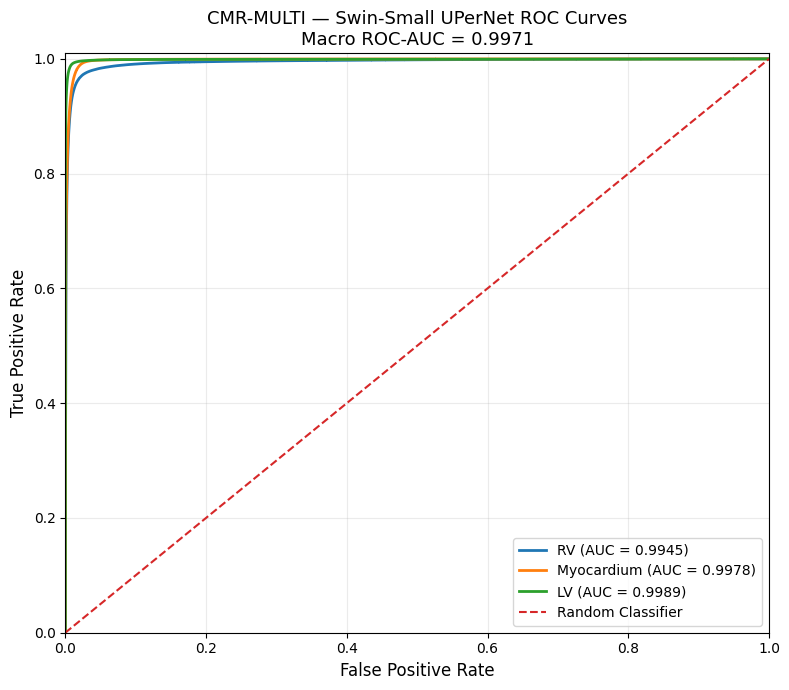

SWIN-SMALL UPERNET ROC-AUC
RV          : 0.9945
Myocardium  : 0.9978
LV          : 0.9989

Macro ROC-AUC: 0.9971

Figure saved to:
/content/drive/MyDrive/Thesis_Figures/CMR_MULTI_Swin_Small_UPerNet_ROC.png

✓ Swin ROC visualization complete.


In [ ]:
# CELL 35 — SWIN-SMALL UPERNET ROC CURVES
# CMR-MULTI

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc
)


# 1. OUTPUT DIRECTORY

FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "Thesis_Figures"
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)


SWIN_ROC_PATH = (
    f"{FIGURE_DIR}/"
    "CMR_MULTI_Swin_Small_UPerNet_ROC.png"
)


# 2. CLASS INFORMATION

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


# 3. CREATE ROC CURVES

plt.figure(
    figsize=(8, 7)
)


auc_values = []


for class_id in [1, 2, 3]:

    y_true = (
        swin_test_results[
            class_id
        ]["roc_true"]
    )

    y_prob = (
        swin_test_results[
            class_id
        ]["roc_prob"]
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )


    class_auc = auc(
        fpr,
        tpr
    )


    auc_values.append(
        class_auc
    )


    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{class_names[class_id]} "
            f"(AUC = {class_auc:.4f})"
        )
    )


# 4. RANDOM-CLASSIFIER REFERENCE

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)


# 5. MACRO AUC

macro_auc_plot = float(
    np.mean(
        auc_values
    )
)


# 6. FORMATTING

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "CMR-MULTI — Swin-Small UPerNet ROC Curves\n"
    f"Macro ROC-AUC = {macro_auc_plot:.4f}",
    fontsize=13
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.25
)

plt.xlim(
    [0.0, 1.0]
)

plt.ylim(
    [0.0, 1.01]
)

plt.tight_layout()


# 7. SAVE

plt.savefig(
    SWIN_ROC_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 8. RESULTS

print(
    "=============================================="
)

print(
    "SWIN-SMALL UPERNET ROC-AUC"
)

print(
    "=============================================="
)

for class_id, auc_value in zip(
    [1, 2, 3],
    auc_values
):

    print(
        f"{class_names[class_id]:12s}: "
        f"{auc_value:.4f}"
    )


print(
    f"\nMacro ROC-AUC: "
    f"{macro_auc_plot:.4f}"
)

print(
    "\nFigure saved to:"
)

print(
    SWIN_ROC_PATH
)

print(
    "\n✓ Swin ROC visualization complete."
)

# Build ResNet34 + GraphSAGE U-Net

In [ ]:
# CELL 36A — INSTALL PYTORCH GEOMETRIC

!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.4 MB/s eta 0:00:00


In [ ]:
# CELL 36B — VERIFY PYTORCH GEOMETRIC

import torch
import torch_geometric

from torch_geometric.nn import SAGEConv

print("PyTorch version:", torch.__version__)
print("PyG version:", torch_geometric.__version__)

print("\n✓ torch_geometric imported successfully.")
print("✓ SAGEConv imported successfully.")

PyTorch version: 2.11.0+cu130
PyG version: 2.8.0.post1

✓ torch_geometric imported successfully.
✓ SAGEConv imported successfully.


In [ ]:
# CELL R5 — RESTORE DEVICE AFTER COLAB RESTART

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠ GPU is not enabled.")

Device: cuda
GPU: Tesla T4


In [ ]:
# CELL R6 — CHECK CMR-MULTI DATASET AFTER RUNTIME RESTART

import os


CMR_ROOT = "/content/CMR_MULTI"

CMR_SAX_ROOT = os.path.join(
    CMR_ROOT,
    "CINE_MULTI",
    "SAX_TR"
)

CMR_IMAGE_DIR = os.path.join(
    CMR_SAX_ROOT,
    "image"
)

CMR_ANNO_DIR = os.path.join(
    CMR_SAX_ROOT,
    "anno"
)


print("=" * 60)
print("CMR-MULTI DATASET CHECK")
print("=" * 60)

print(
    "Dataset root exists:",
    os.path.exists(CMR_ROOT)
)

print(
    "Image directory exists:",
    os.path.exists(CMR_IMAGE_DIR)
)

print(
    "Annotation directory exists:",
    os.path.exists(CMR_ANNO_DIR)
)


if (
    os.path.exists(CMR_IMAGE_DIR)
    and os.path.exists(CMR_ANNO_DIR)
):

    image_files = [
        f for f in os.listdir(CMR_IMAGE_DIR)
        if f.endswith(".nii.gz")
    ]

    anno_files = [
        f for f in os.listdir(CMR_ANNO_DIR)
        if f.endswith(".nii.gz")
    ]


    print(
        "\nMRI files:",
        len(image_files)
    )

    print(
        "Annotation files:",
        len(anno_files)
    )


    if (
        len(image_files) == 105
        and len(anno_files) == 105
    ):

        print(
            "\n✓ Complete CMR-MULTI SAX dataset is still available."
        )

    else:

        print(
            "\n⚠ Dataset exists but file count is unexpected."
        )

else:

    print(
        "\n✗ CMR-MULTI is no longer in /content."
    )

CMR-MULTI DATASET CHECK
Dataset root exists: False
Image directory exists: False
Annotation directory exists: False

✗ CMR-MULTI is no longer in /content.


In [ ]:
# RECOVERY CELL 1 — REDOWNLOAD CMR-MULTI SAX DATA

from huggingface_hub import snapshot_download
import os


CMR_ROOT = "/content/CMR_MULTI"


print("=" * 65)
print("DOWNLOADING CMR-MULTI SAX TRAINING DATA")
print("=" * 65)


snapshot_download(
    repo_id="Jackloveaa/CMR-MULTI",
    repo_type="dataset",
    local_dir=CMR_ROOT,
    allow_patterns=[
        "CINE_MULTI/SAX_TR/*",
        "CINE_MULTI/SAX_TR/**/*"
    ]
)

# VERIFY DOWNLOAD

CMR_SAX_ROOT = os.path.join(
    CMR_ROOT,
    "CINE_MULTI",
    "SAX_TR"
)

CMR_IMAGE_DIR = os.path.join(
    CMR_SAX_ROOT,
    "image"
)

CMR_ANNO_DIR = os.path.join(
    CMR_SAX_ROOT,
    "anno"
)


image_files = sorted([
    f
    for f in os.listdir(CMR_IMAGE_DIR)
    if f.endswith(".nii.gz")
])

anno_files = sorted([
    f
    for f in os.listdir(CMR_ANNO_DIR)
    if f.endswith(".nii.gz")
])


print("\n" + "=" * 65)
print("DOWNLOAD VERIFICATION")
print("=" * 65)

print(
    "MRI files:",
    len(image_files)
)

print(
    "Annotation files:",
    len(anno_files)
)

print(
    "MRI/annotation filenames match:",
    image_files == anno_files
)


assert len(image_files) == 105
assert len(anno_files) == 105
assert image_files == anno_files


print(
    "\n✓ CMR-MULTI SAX dataset restored successfully."
)

DOWNLOADING CMR-MULTI SAX TRAINING DATA


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 210 files:   0%|          | 0/210 [00:00<?, ?it/s]


DOWNLOAD VERIFICATION
MRI files: 105
Annotation files: 105
MRI/annotation filenames match: True

✓ CMR-MULTI SAX dataset restored successfully.


In [ ]:
# RECOVERY CELL 2 — RECREATE ORIGINAL CASE-LEVEL SPLIT

import os
import random


# 1. FIX RANDOM SEED

SEED = 42

random.seed(SEED)


# 2. GET ALL CASE FILENAMES

all_cases = sorted([
    f
    for f in os.listdir(CMR_IMAGE_DIR)
    if f.endswith(".nii.gz")
])


print("=" * 65)
print("RECREATING ORIGINAL CMR-MULTI CASE SPLIT")
print("=" * 65)

print(
    "Total cases:",
    len(all_cases)
)


assert len(all_cases) == 105


# 3. SHUFFLE USING SAME ORIGINAL SEED

shuffled_cases = all_cases.copy()

rng = random.Random(SEED)

rng.shuffle(
    shuffled_cases
)


# 4. ORIGINAL SPLIT
#
# 73 train
# 15 validation
# 17 test

train_cases = shuffled_cases[:73]

val_cases = shuffled_cases[73:88]

test_cases = shuffled_cases[88:]


# 5. VERIFY COUNTS

print(
    "\nTrain cases:",
    len(train_cases)
)

print(
    "Validation cases:",
    len(val_cases)
)

print(
    "Test cases:",
    len(test_cases)
)


# 6. VERIFY NO PATIENT/CASE LEAKAGE

train_set = set(train_cases)
val_set = set(val_cases)
test_set = set(test_cases)


print(
    "\nTrain ∩ Val:",
    len(train_set & val_set)
)

print(
    "Train ∩ Test:",
    len(train_set & test_set)
)

print(
    "Val ∩ Test:",
    len(val_set & test_set)
)


assert len(train_set & val_set) == 0
assert len(train_set & test_set) == 0
assert len(val_set & test_set) == 0

assert (
    len(train_cases)
    + len(val_cases)
    + len(test_cases)
    == 105
)


# 7. SHOW FIRST CASES

print(
    "\nFirst 5 TRAIN cases:"
)

for case in train_cases[:5]:
    print(" ", case)


print(
    "\nFirst 5 VALIDATION cases:"
)

for case in val_cases[:5]:
    print(" ", case)


print(
    "\nFirst 5 TEST cases:"
)

for case in test_cases[:5]:
    print(" ", case)


print(
    "\n✓ Original 73/15/17 case-level split restored."
)

RECREATING ORIGINAL CMR-MULTI CASE SPLIT
Total cases: 105

Train cases: 73
Validation cases: 15
Test cases: 17

Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0

First 5 TRAIN cases:
  CINE_SAX_066.nii.gz
  CINE_SAX_043.nii.gz
  CINE_SAX_016.nii.gz
  CINE_SAX_010.nii.gz
  CINE_SAX_100.nii.gz

First 5 VALIDATION cases:
  CINE_SAX_001.nii.gz
  CINE_SAX_101.nii.gz
  CINE_SAX_092.nii.gz
  CINE_SAX_058.nii.gz
  CINE_SAX_099.nii.gz

First 5 TEST cases:
  CINE_SAX_103.nii.gz
  CINE_SAX_005.nii.gz
  CINE_SAX_055.nii.gz
  CINE_SAX_076.nii.gz
  CINE_SAX_012.nii.gz

✓ Original 73/15/17 case-level split restored.


In [ ]:
# RECOVERY CELL 3 — REBUILD FOREGROUND-ONLY SLICE INDICES

import os
import nibabel as nib
import numpy as np


# 1. FUNCTION TO BUILD SLICE INDEX

def build_foreground_slice_index(
    case_list,
    anno_dir
):

    slice_index = []

    # Structure counters
    myo_count = 0
    lv_count = 0
    rv_count = 0
    all_three_count = 0


    for case_name in case_list:

        mask_path = os.path.join(
            anno_dir,
            case_name
        )


        # Load annotation volume
        mask_nii = nib.load(
            mask_path
        )

        mask_volume = np.asarray(
            mask_nii.dataobj,
            dtype=np.int16
        )


        # Third dimension = indexed 2D planes
        num_slices = mask_volume.shape[2]


        for z in range(num_slices):

            mask_slice = mask_volume[:, :, z]


            # ORIGINAL CMR-MULTI LABELS
            #
            # 0 = Background
            # 1 = Myocardium
            # 2 = LV cavity
            # 3 = RV cavity

            has_myo = np.any(
                mask_slice == 1
            )

            has_lv = np.any(
                mask_slice == 2
            )

            has_rv = np.any(
                mask_slice == 3
            )


            # FOREGROUND-ONLY SELECTION

            has_foreground = (
                has_myo
                or has_lv
                or has_rv
            )


            if has_foreground:

                slice_index.append(
                    (
                        case_name,
                        z
                    )
                )


                if has_myo:
                    myo_count += 1

                if has_lv:
                    lv_count += 1

                if has_rv:
                    rv_count += 1

                if (
                    has_myo
                    and has_lv
                    and has_rv
                ):
                    all_three_count += 1


    return {
        "index": slice_index,
        "myo": myo_count,
        "lv": lv_count,
        "rv": rv_count,
        "all_three": all_three_count
    }


# 2. BUILD TRAIN / VAL / TEST INDICES

print("=" * 65)
print("BUILDING FOREGROUND-ONLY SLICE INDICES")
print("=" * 65)


train_info = build_foreground_slice_index(
    train_cases,
    CMR_ANNO_DIR
)

val_info = build_foreground_slice_index(
    val_cases,
    CMR_ANNO_DIR
)

test_info = build_foreground_slice_index(
    test_cases,
    CMR_ANNO_DIR
)


# 3. EXTRACT INDICES

train_slice_index = train_info["index"]

val_slice_index = val_info["index"]

test_slice_index = test_info["index"]


# 4. PRINT SUMMARY

def print_split_summary(
    name,
    cases,
    info
):

    print(
        f"\n{name}"
    )

    print(
        "-" * 45
    )

    print(
        "Cases:",
        len(cases)
    )

    print(
        "Foreground slices:",
        len(info["index"])
    )

    print(
        "Myocardium slices:",
        info["myo"]
    )

    print(
        "LV slices:",
        info["lv"]
    )

    print(
        "RV slices:",
        info["rv"]
    )

    print(
        "All 3 structures:",
        info["all_three"]
    )


print_split_summary(
    "TRAIN",
    train_cases,
    train_info
)

print_split_summary(
    "VALIDATION",
    val_cases,
    val_info
)

print_split_summary(
    "TEST",
    test_cases,
    test_info
)


# 5. VERIFY AGAINST ORIGINAL EXPERIMENT

assert len(train_slice_index) == 20052
assert len(val_slice_index) == 3954
assert len(test_slice_index) == 4424


print(
    "\n" + "=" * 65
)

print(
    "✓ Original foreground-only slice indices restored."
)

print(
    "✓ Train: 20,052"
)

print(
    "✓ Validation: 3,954"
)

print(
    "✓ Test: 4,424"
)

print(
    "=" * 65
)

BUILDING FOREGROUND-ONLY SLICE INDICES

TRAIN
---------------------------------------------
Cases: 73
Foreground slices: 20052
Myocardium slices: 20052
LV slices: 19871
RV slices: 15397
All 3 structures: 15372

VALIDATION
---------------------------------------------
Cases: 15
Foreground slices: 3954
Myocardium slices: 3954
LV slices: 3896
RV slices: 3115
All 3 structures: 3115

TEST
---------------------------------------------
Cases: 17
Foreground slices: 4424
Myocardium slices: 4424
LV slices: 4408
RV slices: 3513
All 3 structures: 3509

✓ Original foreground-only slice indices restored.
✓ Train: 20,052
✓ Validation: 3,954
✓ Test: 4,424


In [ ]:
# RECOVERY CELL 4 — TRANSFORMS + LABEL MAPPING + DATASET

import os
import numpy as np
import nibabel as nib
import torch

from torch.utils.data import Dataset

import albumentations as A
from albumentations.pytorch import ToTensorV2


# 1. LABEL REMAPPING
#
# Original CMR-MULTI:
# 0 = Background
# 1 = Myocardium
# 2 = LV cavity
# 3 = RV cavity
#
# Thesis standard:
# 0 = Background
# 1 = RV
# 2 = Myocardium
# 3 = LV

def remap_cmr_mask(mask):

    remapped = np.zeros_like(
        mask,
        dtype=np.int64
    )

    remapped[mask == 0] = 0
    remapped[mask == 1] = 2   # Myocardium
    remapped[mask == 2] = 3   # LV
    remapped[mask == 3] = 1   # RV

    return remapped


# 2. TRAINING TRANSFORMS

train_transform = A.Compose([

    A.Resize(
        height=224,
        width=224
    ),

    A.HorizontalFlip(
        p=0.5
    ),

    A.Affine(
        scale=(0.90, 1.10),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.3
    ),

    A.GaussNoise(
        std_range=(0.01, 0.03),
        p=0.2
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=1.0
    ),

    ToTensorV2()
])


# 3. VALIDATION / TEST TRANSFORMS

eval_transform = A.Compose([

    A.Resize(
        height=224,
        width=224
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=1.0
    ),

    ToTensorV2()
])


# 4. CMR-MULTI DATASET

class CMRMultiDataset(Dataset):

    def __init__(
        self,
        image_dir,
        anno_dir,
        slice_index,
        transform=None
    ):

        self.image_dir = image_dir
        self.anno_dir = anno_dir
        self.slice_index = slice_index
        self.transform = transform

        # Cache volumes after first load
        self.image_cache = {}
        self.mask_cache = {}


    def __len__(self):

        return len(
            self.slice_index
        )


    def _load_case(
        self,
        case_name
    ):

        if case_name not in self.image_cache:

            image_path = os.path.join(
                self.image_dir,
                case_name
            )

            mask_path = os.path.join(
                self.anno_dir,
                case_name
            )


            image_nii = nib.load(
                image_path
            )

            mask_nii = nib.load(
                mask_path
            )


            image_volume = np.asarray(
                image_nii.dataobj,
                dtype=np.float32
            )

            mask_volume = np.asarray(
                mask_nii.dataobj,
                dtype=np.int16
            )


            self.image_cache[
                case_name
            ] = image_volume

            self.mask_cache[
                case_name
            ] = mask_volume


        return (
            self.image_cache[case_name],
            self.mask_cache[case_name]
        )


    def __getitem__(
        self,
        index
    ):

        case_name, z = (
            self.slice_index[index]
        )


        image_volume, mask_volume = (
            self._load_case(
                case_name
            )
        )


        # Extract indexed 2D plane

        image = image_volume[
            :, :, z
        ].copy()

        mask = mask_volume[
            :, :, z
        ].copy()


        # Per-slice min-max normalization [0,1]

        image_min = image.min()
        image_max = image.max()


        if image_max > image_min:

            image = (
                image - image_min
            ) / (
                image_max - image_min
            )

        else:

            image = np.zeros_like(
                image,
                dtype=np.float32
            )


        image = image.astype(
            np.float32
        )

        # Grayscale -> 3 channels

        image = np.stack(
            [
                image,
                image,
                image
            ],
            axis=-1
        )


        # Standardize segmentation labels

        mask = remap_cmr_mask(
            mask
        )


        # Apply augmentation / preprocessing

        if self.transform is not None:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed[
                "image"
            ]

            mask = transformed[
                "mask"
            ]


        # Correct dtypes

        image = image.float()
        mask = mask.long()


        return image, mask


print(
    "✓ Label mapping restored."
)

print(
    "✓ Training transforms restored."
)

print(
    "✓ Evaluation transforms restored."
)

print(
    "✓ CMRMultiDataset class restored."
)

✓ Label mapping restored.
✓ Training transforms restored.
✓ Evaluation transforms restored.
✓ CMRMultiDataset class restored.


In [ ]:
# QUICK LABEL REMAPPING CHECK

test_mask = np.array([
    [0, 1],
    [2, 3]
])

test_remapped = remap_cmr_mask(
    test_mask
)

print(
    "\nOriginal:"
)

print(
    test_mask
)

print(
    "\nRemapped:"
)

print(
    test_remapped
)


Original:
[[0 1]
 [2 3]]

Remapped:
[[0 2]
 [3 1]]


In [ ]:
# RECOVERY CELL 5 — RECREATE DATASETS + DATALOADERS

import torch

from torch.utils.data import DataLoader


# 1. CREATE DATASETS

train_dataset = CMRMultiDataset(
    image_dir=CMR_IMAGE_DIR,
    anno_dir=CMR_ANNO_DIR,
    slice_index=train_slice_index,
    transform=train_transform
)


val_dataset = CMRMultiDataset(
    image_dir=CMR_IMAGE_DIR,
    anno_dir=CMR_ANNO_DIR,
    slice_index=val_slice_index,
    transform=eval_transform
)


test_dataset = CMRMultiDataset(
    image_dir=CMR_IMAGE_DIR,
    anno_dir=CMR_ANNO_DIR,
    slice_index=test_slice_index,
    transform=eval_transform
)


print("=" * 65)
print("CMR-MULTI DATASETS")
print("=" * 65)

print(
    "Train dataset:",
    len(train_dataset)
)

print(
    "Validation dataset:",
    len(val_dataset)
)

print(
    "Test dataset:",
    len(test_dataset)
)


# 2. CREATE DATALOADERS

BATCH_SIZE = 8


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


print("\n" + "=" * 65)
print("DATALOADERS")
print("=" * 65)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)


# 3. VERIFY ONE BATCH

images, masks = next(
    iter(train_loader)
)


print("\n" + "=" * 65)
print("BATCH CHECK")
print("=" * 65)

print(
    "Images:",
    images.shape
)

print(
    "Masks:",
    masks.shape
)

print(
    "Image dtype:",
    images.dtype
)

print(
    "Mask dtype:",
    masks.dtype
)

print(
    "Image range:",
    float(images.min()),
    "to",
    float(images.max())
)

print(
    "Mask labels:",
    torch.unique(masks).tolist()
)


# 4. FINAL ASSERTIONS

assert len(train_dataset) == 20052
assert len(val_dataset) == 3954
assert len(test_dataset) == 4424

assert images.shape[1:] == (
    3,
    224,
    224
)

assert masks.shape[1:] == (
    224,
    224
)

assert images.dtype == torch.float32
assert masks.dtype == torch.int64


print(
    "\n✓ CMR-MULTI datasets restored."
)

print(
    "✓ DataLoaders restored."
)

print(
    "✓ train_loader is ready for GraphSAGE."
)

CMR-MULTI DATASETS
Train dataset: 20052
Validation dataset: 3954
Test dataset: 4424

DATALOADERS
Train batches: 2507
Validation batches: 495
Test batches: 553

BATCH CHECK
Images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])
Image dtype: torch.float32
Mask dtype: torch.int64
Image range: -2.1179039478302 to 2.640000104904175
Mask labels: [0, 1, 2, 3]

✓ CMR-MULTI datasets restored.
✓ DataLoaders restored.
✓ train_loader is ready for GraphSAGE.


In [ ]:
# CELL 36 — BUILD RESNET34 + GRAPHSAGE U-NET
# CMR-MULTI

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import (
    resnet34,
    ResNet34_Weights
)

from torch_geometric.nn import SAGEConv

# 1. CREATE GRID GRAPH EDGES

def create_grid_edge_index(
    height,
    width,
    device
):
    """
    Create a bidirectional 4-neighbor grid graph.

    Each spatial location in the feature map becomes a node.

    Connections:
        up
        down
        left
        right
    """

    edges = []


    for row in range(height):

        for col in range(width):

            node = (
                row * width
                + col
            )

            # Right neighbor

            if col + 1 < width:

                right = (
                    row * width
                    + (col + 1)
                )

                edges.append(
                    [node, right]
                )

                edges.append(
                    [right, node]
                )


            # Bottom neighbor

            if row + 1 < height:

                bottom = (
                    (row + 1) * width
                    + col
                )

                edges.append(
                    [node, bottom]
                )

                edges.append(
                    [bottom, node]
                )


    edge_index = torch.tensor(
        edges,
        dtype=torch.long,
        device=device
    ).t().contiguous()


    return edge_index


# 2. DOUBLE CONVOLUTION BLOCK

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()


        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),


            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )


    def forward(
        self,
        x
    ):

        return self.block(x)


# 3. RESNET34 + GRAPHSAGE U-NET

class ResNet34GraphSAGEUNet(nn.Module):

    def __init__(
        self,
        num_classes=4
    ):

        super().__init__()


        # PRETRAINED RESNET34

        backbone = resnet34(
            weights=ResNet34_Weights.DEFAULT
        )


        # RESNET STEM
        # Input:
        # 224 × 224
        #
        # Output:
        # 56 × 56

        self.stem = nn.Sequential(

            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool
        )


        # RESNET ENCODER

        self.layer1 = backbone.layer1
        # 64 × 56 × 56

        self.layer2 = backbone.layer2
        # 128 × 28 × 28

        self.layer3 = backbone.layer3
        # 256 × 14 × 14

        self.layer4 = backbone.layer4
        # 512 × 7 × 7


        # GRAPHSAGE BOTTLENECK

        self.sage1 = SAGEConv(
            512,
            512
        )

        self.sage2 = SAGEConv(
            512,
            512
        )

        self.sage3 = SAGEConv(
            512,
            512
        )

        self.sage4 = SAGEConv(
            512,
            512
        )


        self.graph_norm1 = nn.LayerNorm(
            512
        )

        self.graph_norm2 = nn.LayerNorm(
            512
        )

        self.graph_norm3 = nn.LayerNorm(
            512
        )

        self.graph_norm4 = nn.LayerNorm(
            512
        )


        # CNN GRAPH REFINEMENT

        self.graph_refine = nn.Sequential(

            nn.Conv2d(
                512,
                512,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                512
            ),

            nn.ReLU(
                inplace=True
            )
        )

        # U-NET DECODER

        # 7 -> 14
        # Graph feature 512
        # + layer3 skip 256
        self.decoder3 = DoubleConv(
            512 + 256,
            256
        )


        # 14 -> 28
        # 256
        # + layer2 skip 128
        self.decoder2 = DoubleConv(
            256 + 128,
            128
        )


        # 28 -> 56
        # 128
        # + layer1 skip 64
        self.decoder1 = DoubleConv(
            128 + 64,
            64
        )


        # 56 -> 112
        self.decoder0 = DoubleConv(
            64,
            64
        )


        # 112 -> 224
        self.final_refine = DoubleConv(
            64,
            32
        )

        # FINAL SEGMENTATION HEAD

        self.classifier = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    # GRAPHSAGE FORWARD

    def graph_forward(
        self,
        x
    ):

        batch_size, channels, height, width = (
            x.shape
        )


        # Convert:
        #
        # B × C × H × W
        #
        # into:
        #
        # (B*H*W) × C

        nodes = (
            x
            .permute(
                0,
                2,
                3,
                1
            )
            .contiguous()
            .view(
                batch_size
                * height
                * width,
                channels
            )
        )


        # Base graph for one image

        base_edges = create_grid_edge_index(
            height,
            width,
            x.device
        )


        num_nodes_per_image = (
            height * width
        )

        # Build disconnected batched graph

        batch_edges = []


        for batch_index in range(
            batch_size
        ):

            offset = (
                batch_index
                * num_nodes_per_image
            )

            batch_edges.append(
                base_edges
                + offset
            )


        edge_index = torch.cat(
            batch_edges,
            dim=1
        )


        # GRAPHSAGE LAYER 1

        residual = nodes

        graph = self.sage1(
            nodes,
            edge_index
        )

        graph = self.graph_norm1(
            graph
        )

        graph = F.gelu(
            graph
        )

        graph = (
            graph
            + residual
        )


        # GRAPHSAGE LAYER 2

        residual = graph

        graph = self.sage2(
            graph,
            edge_index
        )

        graph = self.graph_norm2(
            graph
        )

        graph = F.gelu(
            graph
        )

        graph = (
            graph
            + residual
        )


        # GRAPHSAGE LAYER 3

        residual = graph

        graph = self.sage3(
            graph,
            edge_index
        )

        graph = self.graph_norm3(
            graph
        )

        graph = F.gelu(
            graph
        )

        graph = (
            graph
            + residual
        )


        # GRAPHSAGE LAYER 4

        residual = graph

        graph = self.sage4(
            graph,
            edge_index
        )

        graph = self.graph_norm4(
            graph
        )

        graph = F.gelu(
            graph
        )

        graph = (
            graph
            + residual
        )


        # Convert nodes back to feature map

        graph = (
            graph
            .view(
                batch_size,
                height,
                width,
                channels
            )
            .permute(
                0,
                3,
                1,
                2
            )
            .contiguous()
        )


        return graph


    # MODEL FORWARD

    def forward(
        self,
        x
    ):

        # RESNET ENCODER

        x0 = self.stem(x)
        # 64 × 56 × 56

        x1 = self.layer1(x0)
        # 64 × 56 × 56

        x2 = self.layer2(x1)
        # 128 × 28 × 28

        x3 = self.layer3(x2)
        # 256 × 14 × 14

        x4 = self.layer4(x3)
        # 512 × 7 × 7


        # GRAPHSAGE BOTTLENECK

        graph = self.graph_forward(
            x4
        )


        graph = self.graph_refine(
            graph
        )

        # DECODER

        # 7 -> 14
        d3 = F.interpolate(
            graph,
            size=x3.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        d3 = torch.cat(
            [d3, x3],
            dim=1
        )

        d3 = self.decoder3(
            d3
        )


        # 14 -> 28
        d2 = F.interpolate(
            d3,
            size=x2.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        d2 = torch.cat(
            [d2, x2],
            dim=1
        )

        d2 = self.decoder2(
            d2
        )


        # 28 -> 56
        d1 = F.interpolate(
            d2,
            size=x1.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        d1 = torch.cat(
            [d1, x1],
            dim=1
        )

        d1 = self.decoder1(
            d1
        )


        # 56 -> 112
        d0 = F.interpolate(
            d1,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        d0 = self.decoder0(
            d0
        )


        # 112 -> 224
        final = F.interpolate(
            d0,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        final = self.final_refine(
            final
        )


        logits = self.classifier(
            final
        )


        return logits


# 4. CREATE MODEL

graphsage_model = (
    ResNet34GraphSAGEUNet(
        num_classes=4
    )
    .to(device)
)


# 5. PARAMETER COUNTS

total_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
    if p.requires_grad
)


print(
    "=============================================="
)

print(
    "RESNET34 + GRAPHSAGE U-NET"
)

print(
    "=============================================="
)

print(
    f"Total parameters: "
    f"{total_params:,}"
)

print(
    f"Trainable parameters: "
    f"{trainable_params:,}"
)


# 6. VERIFY ONE FORWARD PASS

sample_images, sample_masks = next(
    iter(train_loader)
)

sample_images = sample_images.to(
    device
)


graphsage_model.eval()


with torch.no_grad():

    sample_logits = graphsage_model(
        sample_images
    )


print(
    "\n===== FORWARD PASS CHECK ====="
)

print(
    "Input images:",
    sample_images.shape
)

print(
    "Masks:",
    sample_masks.shape
)

print(
    "Output logits:",
    sample_logits.shape
)


assert sample_logits.shape == (
    sample_images.shape[0],
    4,
    224,
    224
)


print(
    "\n✓ ImageNet-pretrained ResNet34 encoder loaded."
)

print(
    "✓ GraphSAGE bottleneck created."
)

print(
    "✓ Four GraphSAGE layers operational."
)

print(
    "✓ U-Net decoder operational."
)

print(
    "✓ Output matches 4-class 224×224 segmentation masks."
)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 196MB/s]


RESNET34 + GRAPHSAGE U-NET
Total parameters: 28,948,548
Trainable parameters: 28,948,548

===== FORWARD PASS CHECK =====
Input images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])
Output logits: torch.Size([8, 4, 224, 224])

✓ ImageNet-pretrained ResNet34 encoder loaded.
✓ GraphSAGE bottleneck created.
✓ Four GraphSAGE layers operational.
✓ U-Net decoder operational.
✓ Output matches 4-class 224×224 segmentation masks.


# GraphSAGE Loss, Optimizer, Scheduler & Checkpoint

In [ ]:
# RECOVERY CELL 6 — GRAPHSAGE TRAINING SETUP
# CMR-MULTI

import os
import torch
import torch.nn as nn
import torch.optim as optim


# 1. FOREGROUND MULTICLASS DICE LOSS

class MulticlassDiceLoss(nn.Module):

    def __init__(
        self,
        num_classes=4,
        smooth=1e-6
    ):

        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = torch.softmax(
            logits,
            dim=1
        )


        total_dice_loss = 0.0


        # Foreground classes only:
        # 1 = RV
        # 2 = Myocardium
        # 3 = LV

        for class_id in range(
            1,
            self.num_classes
        ):

            pred = probs[
                :,
                class_id
            ]

            target = (
                targets == class_id
            ).float()


            intersection = (
                pred * target
            ).sum(
                dim=(1, 2)
            )


            denominator = (
                pred.sum(
                    dim=(1, 2)
                )
                +
                target.sum(
                    dim=(1, 2)
                )
            )


            dice = (
                2.0 * intersection
                + self.smooth
            ) / (
                denominator
                + self.smooth
            )


            total_dice_loss += (
                1.0 - dice.mean()
            )


        return (
            total_dice_loss
            / (self.num_classes - 1)
        )


# 2. COMBINED LOSS
#
# 50% Cross Entropy
# 50% Foreground Dice

graph_ce_loss = nn.CrossEntropyLoss()

graph_dice_loss = MulticlassDiceLoss(
    num_classes=4
)


def graph_loss_fn(
    logits,
    targets
):

    ce = graph_ce_loss(
        logits,
        targets
    )

    dice = graph_dice_loss(
        logits,
        targets
    )

    return (
        0.5 * ce
        + 0.5 * dice
    )


# 3. SEPARATE PRETRAINED ENCODER FROM NEW LAYERS

encoder_modules = [
    graphsage_model.stem,
    graphsage_model.layer1,
    graphsage_model.layer2,
    graphsage_model.layer3,
    graphsage_model.layer4
]


encoder_params = []

for module in encoder_modules:

    encoder_params.extend(
        list(
            module.parameters()
        )
    )


encoder_param_ids = {
    id(p)
    for p in encoder_params
}


new_params = [
    p
    for p in graphsage_model.parameters()
    if id(p) not in encoder_param_ids
]


# 4. OPTIMIZER
#
# Pretrained ResNet encoder = 2e-5
# New GraphSAGE + decoder = 1e-4

graph_optimizer = optim.AdamW(

    [
        {
            "params": encoder_params,
            "lr": 2e-5
        },

        {
            "params": new_params,
            "lr": 1e-4
        }
    ],

    weight_decay=1e-4
)


# 5. LR SCHEDULER

graph_scheduler = (
    optim.lr_scheduler.ReduceLROnPlateau(

        graph_optimizer,

        mode="max",

        factor=0.5,

        patience=3,

        min_lr=1e-6
    )
)

# 6. TRAINING SETTINGS

GRAPH_MAX_EPOCHS = 50

GRAPH_EARLY_STOPPING_PATIENCE = 10


# 7. SAFE GOOGLE DRIVE CHECKPOINT DIRECTORY

GRAPH_CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "Thesis_Checkpoints/"
    "CMR_MULTI"
)


os.makedirs(
    GRAPH_CHECKPOINT_DIR,
    exist_ok=True
)


GRAPH_BEST_CHECKPOINT = os.path.join(
    GRAPH_CHECKPOINT_DIR,
    "best_graphsage_unet_cmr_multi.pth"
)


GRAPH_LATEST_CHECKPOINT = os.path.join(
    GRAPH_CHECKPOINT_DIR,
    "latest_graphsage_unet_cmr_multi.pth"
)


# 8. PARAMETER VERIFICATION

encoder_count = sum(
    p.numel()
    for p in encoder_params
)


new_count = sum(
    p.numel()
    for p in new_params
)


total_count = (
    encoder_count
    + new_count
)


print("=" * 65)
print("GRAPHSAGE TRAINING SETUP")
print("=" * 65)

print(
    f"Pretrained encoder parameters: "
    f"{encoder_count:,}"
)

print(
    f"New GraphSAGE/decoder parameters: "
    f"{new_count:,}"
)

print(
    f"Total parameters: "
    f"{total_count:,}"
)


print(
    "\nEncoder learning rate:",
    graph_optimizer.param_groups[0]["lr"]
)

print(
    "New layers learning rate:",
    graph_optimizer.param_groups[1]["lr"]
)


print(
    "\nMax epochs:",
    GRAPH_MAX_EPOCHS
)

print(
    "Early stopping patience:",
    GRAPH_EARLY_STOPPING_PATIENCE
)


print(
    "\nBest checkpoint:"
)

print(
    GRAPH_BEST_CHECKPOINT
)


print(
    "\nLatest checkpoint:"
)

print(
    GRAPH_LATEST_CHECKPOINT
)


# 9. DRIVE WRITE TEST

write_test_path = os.path.join(
    GRAPH_CHECKPOINT_DIR,
    "checkpoint_write_test.txt"
)


with open(
    write_test_path,
    "w"
) as f:

    f.write(
        "CMR-MULTI GraphSAGE checkpoint test."
    )


assert os.path.exists(
    write_test_path
)


print(
    "\n✓ Google Drive directory writable."
)


# 10. TEST LOSS ON ONE BATCH

graphsage_model.train()


sample_images, sample_masks = next(
    iter(train_loader)
)


sample_images = sample_images.to(
    device
)

sample_masks = sample_masks.to(
    device
)


with torch.no_grad():

    sample_logits = graphsage_model(
        sample_images
    )

    initial_loss = graph_loss_fn(
        sample_logits,
        sample_masks
    )


print(
    f"Initial one-batch loss: "
    f"{initial_loss.item():.4f}"
)


print(
    "\n✓ GraphSAGE training configuration restored."
)

GRAPHSAGE TRAINING SETUP
Pretrained encoder parameters: 21,284,672
New GraphSAGE/decoder parameters: 7,663,876
Total parameters: 28,948,548

Encoder learning rate: 2e-05
New layers learning rate: 0.0001

Max epochs: 50
Early stopping patience: 10

Best checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/CMR_MULTI/best_graphsage_unet_cmr_multi.pth

Latest checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/CMR_MULTI/latest_graphsage_unet_cmr_multi.pth

✓ Google Drive directory writable.
Initial one-batch loss: 1.1316

✓ GraphSAGE training configuration restored.


# GraphSAGE Baseline Validation

In [ ]:
# CELL 38 — GRAPHSAGE VALIDATION FUNCTION
# CMR-MULTI

import numpy as np
import torch


# 1. HARD DICE FOR ONE CLASS

def graph_binary_dice(
    pred,
    target,
    smooth=1e-6
):

    pred = pred.float()
    target = target.float()

    intersection = (
        pred * target
    ).sum(
        dim=(1, 2)
    )

    denominator = (
        pred.sum(
            dim=(1, 2)
        )
        +
        target.sum(
            dim=(1, 2)
        )
    )

    dice = (
        2.0 * intersection
        + smooth
    ) / (
        denominator
        + smooth
    )

    return dice


# 2. VALIDATION FUNCTION

def validate_graphsage(
    model,
    loader,
    loss_function,
    device
):

    model.eval()

    running_loss = 0.0

    class_dice = {
        1: [],
        2: [],
        3: []
    }


    with torch.no_grad():

        for images, masks in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = loss_function(
                logits,
                masks
            )


            running_loss += (
                loss.item()
                * images.size(0)
            )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            # Foreground classes:
            #
            # 1 = RV
            # 2 = Myocardium
            # 3 = LV

            for class_id in [
                1,
                2,
                3
            ]:

                pred_binary = (
                    predictions
                    == class_id
                )

                target_binary = (
                    masks
                    == class_id
                )


                dice_values = (
                    graph_binary_dice(
                        pred_binary,
                        target_binary
                    )
                )


                class_dice[
                    class_id
                ].extend(
                    dice_values
                    .detach()
                    .cpu()
                    .numpy()
                    .tolist()
                )


    # 3. FINAL VALIDATION METRICS

    val_loss = (
        running_loss
        / len(loader.dataset)
    )


    rv_dice = float(
        np.mean(
            class_dice[1]
        )
    )


    myo_dice = float(
        np.mean(
            class_dice[2]
        )
    )


    lv_dice = float(
        np.mean(
            class_dice[3]
        )
    )


    mean_dice = float(
        np.mean([
            rv_dice,
            myo_dice,
            lv_dice
        ])
    )


    return {
        "loss": val_loss,
        "rv": rv_dice,
        "myo": myo_dice,
        "lv": lv_dice,
        "mean": mean_dice
    }


print(
    "✓ GraphSAGE validation function ready."
)

print(
    "Classes:"
)

print(
    "  1 = RV"
)

print(
    "  2 = Myocardium"
)

print(
    "  3 = LV"
)

✓ GraphSAGE validation function ready.
Classes:
  1 = RV
  2 = Myocardium
  3 = LV


# Train ResNet34 + GraphSAGE U-Net

In [ ]:
# CELL 39 — PROTECTED GRAPHSAGE TRAINING
# CMR-MULTI

import os
import time
import torch


# 1. AMP SETUP

use_amp = (
    device.type == "cuda"
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)


# 2. TRAINING STATE

best_val_dice = -1.0

best_epoch = 0

epochs_without_improvement = 0

training_history = []


print("=" * 70)
print("CMR-MULTI — RESNET34 + GRAPHSAGE U-NET")
print("=" * 70)

print(
    f"Training slices: {len(train_dataset):,}"
)

print(
    f"Validation slices: {len(val_dataset):,}"
)

print(
    f"Training batches: {len(train_loader):,}"
)

print(
    f"Validation batches: {len(val_loader):,}"
)

print(
    f"Maximum epochs: {GRAPH_MAX_EPOCHS}"
)

print(
    f"Early stopping patience: "
    f"{GRAPH_EARLY_STOPPING_PATIENCE}"
)

print(
    f"AMP enabled: {use_amp}"
)

print(
    "\nBest checkpoint:"
)

print(
    GRAPH_BEST_CHECKPOINT
)

print(
    "\nLatest checkpoint:"
)

print(
    GRAPH_LATEST_CHECKPOINT
)

print("=" * 70)


training_start_time = time.time()


# 3. TRAINING LOOP

for epoch in range(
    1,
    GRAPH_MAX_EPOCHS + 1
):

    epoch_start_time = time.time()

    graphsage_model.train()

    running_train_loss = 0.0


    # TRAIN ONE EPOCH

    for images, masks in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        graph_optimizer.zero_grad(
            set_to_none=True
        )


        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            logits = graphsage_model(
                images
            )

            loss = graph_loss_fn(
                logits,
                masks
            )


        scaler.scale(
            loss
        ).backward()


        # Gradient clipping

        scaler.unscale_(
            graph_optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            graphsage_model.parameters(),
            max_norm=1.0
        )


        scaler.step(
            graph_optimizer
        )

        scaler.update()


        running_train_loss += (
            loss.item()
            * images.size(0)
        )


    train_loss = (
        running_train_loss
        / len(train_loader.dataset)
    )

    # VALIDATION

    val_results = validate_graphsage(
        graphsage_model,
        val_loader,
        graph_loss_fn,
        device
    )


    val_loss = val_results["loss"]

    rv_dice = val_results["rv"]

    myo_dice = val_results["myo"]

    lv_dice = val_results["lv"]

    mean_dice = val_results["mean"]


    # SCHEDULER

    graph_scheduler.step(
        mean_dice
    )


    encoder_lr = (
        graph_optimizer
        .param_groups[0]["lr"]
    )

    new_layers_lr = (
        graph_optimizer
        .param_groups[1]["lr"]
    )

    # RECORD HISTORY


    epoch_record = {

        "epoch": epoch,

        "train_loss": train_loss,

        "val_loss": val_loss,

        "rv": rv_dice,

        "myo": myo_dice,

        "lv": lv_dice,

        "mean": mean_dice,

        "encoder_lr": encoder_lr,

        "new_layers_lr": new_layers_lr
    }


    training_history.append(
        epoch_record
    )


    # CHECK FOR NEW BEST

    is_best = (
        mean_dice
        > best_val_dice
    )


    if is_best:

        best_val_dice = mean_dice

        best_epoch = epoch

        epochs_without_improvement = 0


        best_checkpoint_data = {

            "epoch": epoch,

            "model_state_dict":
                graphsage_model.state_dict(),

            "optimizer_state_dict":
                graph_optimizer.state_dict(),

            "scheduler_state_dict":
                graph_scheduler.state_dict(),

            "best_val_dice":
                best_val_dice,

            "best_epoch":
                best_epoch,

            "val_results":
                val_results,

            "training_history":
                training_history
        }


        torch.save(
            best_checkpoint_data,
            GRAPH_BEST_CHECKPOINT
        )


        # VERIFY BEST CHECKPOINT

        if not os.path.exists(
            GRAPH_BEST_CHECKPOINT
        ):

            raise RuntimeError(
                "BEST checkpoint save failed."
            )


        best_size_mb = (
            os.path.getsize(
                GRAPH_BEST_CHECKPOINT
            )
            / (1024 ** 2)
        )


    else:

        epochs_without_improvement += 1

    # SAVE LATEST CHECKPOINT EVERY EPOCH

    latest_checkpoint_data = {

        "epoch": epoch,

        "model_state_dict":
            graphsage_model.state_dict(),

        "optimizer_state_dict":
            graph_optimizer.state_dict(),

        "scheduler_state_dict":
            graph_scheduler.state_dict(),

        "best_val_dice":
            best_val_dice,

        "best_epoch":
            best_epoch,

        "epochs_without_improvement":
            epochs_without_improvement,

        "val_results":
            val_results,

        "training_history":
            training_history
    }


    torch.save(
        latest_checkpoint_data,
        GRAPH_LATEST_CHECKPOINT
    )


    # VERIFY LATEST CHECKPOINT

    if not os.path.exists(
        GRAPH_LATEST_CHECKPOINT
    ):

        raise RuntimeError(
            "LATEST checkpoint save failed."
        )


    latest_size_mb = (
        os.path.getsize(
            GRAPH_LATEST_CHECKPOINT
        )
        / (1024 ** 2)
    )


    # PRINT EPOCH RESULTS

    epoch_minutes = (
        time.time()
        - epoch_start_time
    ) / 60


    print(
        f"\nEpoch "
        f"{epoch:02d}/"
        f"{GRAPH_MAX_EPOCHS}"
    )

    print(
        f"Train Loss: "
        f"{train_loss:.4f}"
    )

    print(
        f"Val Loss:   "
        f"{val_loss:.4f}"
    )

    print(
        f"RV Dice:    "
        f"{rv_dice:.4f}"
    )

    print(
        f"Myo Dice:   "
        f"{myo_dice:.4f}"
    )

    print(
        f"LV Dice:    "
        f"{lv_dice:.4f}"
    )

    print(
        f"Mean Dice:  "
        f"{mean_dice:.4f}"
    )

    print(
        f"Encoder LR: "
        f"{encoder_lr:.2e}"
    )

    print(
        f"New LR:     "
        f"{new_layers_lr:.2e}"
    )

    print(
        f"Epoch time: "
        f"{epoch_minutes:.2f} min"
    )


    if is_best:

        print(
            f"★ NEW BEST — "
            f"Epoch {epoch}"
        )

        print(
            f"✓ BEST checkpoint verified "
            f"({best_size_mb:.2f} MB)"
        )


    print(
        f"✓ LATEST checkpoint verified "
        f"({latest_size_mb:.2f} MB)"
    )

    print(
        f"No improvement: "
        f"{epochs_without_improvement}/"
        f"{GRAPH_EARLY_STOPPING_PATIENCE}"
    )


    # EARLY STOPPING

    if (
        epochs_without_improvement
        >= GRAPH_EARLY_STOPPING_PATIENCE
    ):

        print(
            "\n" + "=" * 70
        )

        print(
            "EARLY STOPPING TRIGGERED"
        )

        print(
            f"Best epoch: "
            f"{best_epoch}"
        )

        print(
            f"Best validation Dice: "
            f"{best_val_dice:.6f}"
        )

        print(
            "=" * 70
        )

        break


# 4. FINAL SUMMARY

total_training_minutes = (
    time.time()
    - training_start_time
) / 60


print(
    "\n" + "=" * 70
)

print(
    "GRAPHSAGE TRAINING COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Best epoch: "
    f"{best_epoch}"
)

print(
    f"Best validation Dice: "
    f"{best_val_dice:.10f}"
)

print(
    f"Total training time: "
    f"{total_training_minutes:.2f} min"
)

print(
    "\nBEST checkpoint exists:",
    os.path.exists(
        GRAPH_BEST_CHECKPOINT
    )
)

print(
    "LATEST checkpoint exists:",
    os.path.exists(
        GRAPH_LATEST_CHECKPOINT
    )
)

print(
    "\nBEST checkpoint:"
)

print(
    GRAPH_BEST_CHECKPOINT
)

print(
    "\nLATEST checkpoint:"
)

print(
    GRAPH_LATEST_CHECKPOINT
)

CMR-MULTI — RESNET34 + GRAPHSAGE U-NET
Training slices: 20,052
Validation slices: 3,954
Training batches: 2,507
Validation batches: 495
Maximum epochs: 50
Early stopping patience: 10
AMP enabled: True

Best checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/CMR_MULTI/best_graphsage_unet_cmr_multi.pth

Latest checkpoint:
/content/drive/MyDrive/Thesis_Checkpoints/CMR_MULTI/latest_graphsage_unet_cmr_multi.pth

Epoch 01/50
Train Loss: 0.2741
Val Loss:   0.1532
RV Dice:    0.7167
Myo Dice:   0.8651
LV Dice:    0.9099
Mean Dice:  0.8305
Encoder LR: 2.00e-05
New LR:     1.00e-04
Epoch time: 5.08 min
★ NEW BEST — Epoch 1
✓ BEST checkpoint verified (331.61 MB)
✓ LATEST checkpoint verified (331.61 MB)
No improvement: 0/10

Epoch 02/50
Train Loss: 0.1166
Val Loss:   0.1352
RV Dice:    0.7624
Myo Dice:   0.8662
LV Dice:    0.9097
Mean Dice:  0.8461
Encoder LR: 2.00e-05
New LR:     1.00e-04
Epoch time: 4.91 min
★ NEW BEST — Epoch 2
✓ BEST checkpoint verified (331.61 MB)
✓ LATEST checkpoint verif

# Reload the Best GraphSAGE Checkpoint

In [ ]:
# CELL 40 — RELOAD BEST GRAPHSAGE CHECKPOINT
# CMR-MULTI

import os
import torch


print("=" * 70)
print("RELOADING BEST GRAPHSAGE CHECKPOINT")
print("=" * 70)


# 1. VERIFY CHECKPOINT

print(
    "Checkpoint exists:",
    os.path.exists(
        GRAPH_BEST_CHECKPOINT
    )
)


assert os.path.exists(
    GRAPH_BEST_CHECKPOINT
), "Best GraphSAGE checkpoint not found."


checkpoint_size_mb = (
    os.path.getsize(
        GRAPH_BEST_CHECKPOINT
    )
    / (1024 ** 2)
)


print(
    f"Checkpoint size: "
    f"{checkpoint_size_mb:.2f} MB"
)


# 2. LOAD CHECKPOINT

checkpoint = torch.load(
    GRAPH_BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)


print(
    "\nSaved epoch:",
    checkpoint["epoch"]
)

print(
    "Best epoch:",
    checkpoint["best_epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)


# 3. LOAD BEST WEIGHTS INTO MODEL

graphsage_model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


graphsage_model = (
    graphsage_model.to(
        device
    )
)


graphsage_model.eval()


print(
    "\n✓ Best model weights loaded."
)

print(
    "✓ Model placed in evaluation mode."
)


# 4. SHOW SAVED VALIDATION RESULTS

best_val_results = checkpoint[
    "val_results"
]


print("\n" + "=" * 70)

print(
    "BEST VALIDATION RESULTS"
)

print(
    "=" * 70
)


print(
    f"Validation Loss: "
    f"{best_val_results['loss']:.6f}"
)

print(
    f"RV Dice:         "
    f"{best_val_results['rv']:.6f}"
)

print(
    f"Myocardium Dice: "
    f"{best_val_results['myo']:.6f}"
)

print(
    f"LV Dice:         "
    f"{best_val_results['lv']:.6f}"
)

print(
    f"Mean Dice:       "
    f"{best_val_results['mean']:.6f}"
)


# 5. VERIFY PARAMETER COUNT

total_params = sum(
    p.numel()
    for p in graphsage_model.parameters()
)


print(
    f"\nTotal parameters: "
    f"{total_params:,}"
)


assert total_params == 28_948_548

# 6. VERIFY TEST FORWARD PASS

test_images, test_masks = next(
    iter(test_loader)
)


test_images = test_images.to(
    device
)


with torch.no_grad():

    test_logits = graphsage_model(
        test_images
    )


print("\n" + "=" * 70)

print(
    "TEST FORWARD PASS"
)

print(
    "=" * 70
)

print(
    "Images:",
    test_images.shape
)

print(
    "Masks:",
    test_masks.shape
)

print(
    "Logits:",
    test_logits.shape
)


assert test_logits.shape == (
    test_images.shape[0],
    4,
    224,
    224
)


print(
    "\n✓ BEST Epoch 5 GraphSAGE model is ready for final testing."
)

RELOADING BEST GRAPHSAGE CHECKPOINT
Checkpoint exists: True
Checkpoint size: 331.61 MB

Saved epoch: 5
Best epoch: 5
Best validation Dice: 0.8529303174988178

✓ Best model weights loaded.
✓ Model placed in evaluation mode.

BEST VALIDATION RESULTS
Validation Loss: 0.131045
RV Dice:         0.775447
Myocardium Dice: 0.871861
LV Dice:         0.911483
Mean Dice:       0.852930

Total parameters: 28,948,548

TEST FORWARD PASS
Images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 224, 224])
Logits: torch.Size([8, 4, 224, 224])

✓ BEST Epoch 5 GraphSAGE model is ready for final testing.


#GraphSAGE Test Evaluation

In [ ]:
# CELL 41 — OFFICIAL GRAPHSAGE TEST EVALUATION
# CMR-MULTI

import numpy as np
import torch

from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import distance_transform_edt
from skimage.metrics import structural_similarity as ssim
from sklearn.metrics import roc_auc_score


# SETTINGS

CLASS_NAMES = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

EPS = 1e-6

ROC_PIXELS_PER_BATCH = 20_000

rng = np.random.default_rng(42)


# METRIC FUNCTIONS

def dice_score_binary(pred, gt):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    intersection = np.logical_and(
        pred,
        gt
    ).sum()

    denominator = (
        pred.sum()
        +
        gt.sum()
    )

    return (
        2.0 * intersection
        + EPS
    ) / (
        denominator
        + EPS
    )


def iou_score_binary(pred, gt):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    intersection = np.logical_and(
        pred,
        gt
    ).sum()

    union = np.logical_or(
        pred,
        gt
    ).sum()

    return (
        intersection
        + EPS
    ) / (
        union
        + EPS
    )


def symmetric_hausdorff(pred, gt):

    pred_points = np.argwhere(
        pred > 0
    )

    gt_points = np.argwhere(
        gt > 0
    )

    if (
        len(pred_points) == 0
        or
        len(gt_points) == 0
    ):

        return np.nan

    hd_pred_gt = directed_hausdorff(
        pred_points,
        gt_points
    )[0]

    hd_gt_pred = directed_hausdorff(
        gt_points,
        pred_points
    )[0]

    return max(
        hd_pred_gt,
        hd_gt_pred
    )


def hd95_score(pred, gt):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    if (
        pred.sum() == 0
        or
        gt.sum() == 0
    ):

        return np.nan


    # Distance from predicted foreground
    # pixels to nearest GT foreground pixel

    distance_to_gt = (
        distance_transform_edt(
            ~gt
        )
    )

    pred_to_gt = (
        distance_to_gt[
            pred
        ]
    )


    # Distance from GT foreground
    # pixels to nearest predicted foreground pixel

    distance_to_pred = (
        distance_transform_edt(
            ~pred
        )
    )

    gt_to_pred = (
        distance_to_pred[
            gt
        ]
    )


    all_distances = np.concatenate([
        pred_to_gt,
        gt_to_pred
    ])


    return float(
        np.percentile(
            all_distances,
            95
        )
    )


# STORAGE

metrics = {

    class_id: {

        "dice": [],

        "iou": [],

        "ssim": [],

        "hd": [],

        "hd95": []

    }

    for class_id in CLASS_NAMES
}


# ROC-AUC storage
# We sample pixels to avoid storing every pixel
# from all 4,424 slices.

roc_true = {

    class_id: []

    for class_id in CLASS_NAMES
}


roc_prob = {

    class_id: []

    for class_id in CLASS_NAMES
}


# MODEL

graphsage_model.eval()


print("=" * 70)

print(
    "OFFICIAL CMR-MULTI GRAPHSAGE TEST EVALUATION"
)

print("=" * 70)

print(
    f"Test slices: "
    f"{len(test_dataset):,}"
)

print(
    f"Test batches: "
    f"{len(test_loader):,}"
)

print(
    "Classes: "
    "RV | Myocardium | LV"
)

print("=" * 70)


# TEST LOOP

with torch.no_grad():

    for batch_idx, (
        images,
        masks
    ) in enumerate(
        test_loader
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )


        logits = graphsage_model(
            images
        )


        probabilities = torch.softmax(
            logits,
            dim=1
        )


        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        masks_np = (
            masks
            .cpu()
            .numpy()
        )


        preds_np = (
            predictions
            .cpu()
            .numpy()
        )


        probs_np = (
            probabilities
            .cpu()
            .numpy()
        )

        # SLICE METRICS

        batch_size = (
            masks_np.shape[0]
        )


        for b in range(
            batch_size
        ):

            gt_slice = (
                masks_np[b]
            )

            pred_slice = (
                preds_np[b]
            )


            for class_id in CLASS_NAMES:

                gt_binary = (
                    gt_slice
                    == class_id
                ).astype(
                    np.uint8
                )


                pred_binary = (
                    pred_slice
                    == class_id
                ).astype(
                    np.uint8
                )


                # ------------------------------
                # Dice
                # ------------------------------

                metrics[
                    class_id
                ]["dice"].append(

                    dice_score_binary(
                        pred_binary,
                        gt_binary
                    )

                )


                # IoU

                metrics[
                    class_id
                ]["iou"].append(

                    iou_score_binary(
                        pred_binary,
                        gt_binary
                    )

                )


                # SSIM

                metrics[
                    class_id
                ]["ssim"].append(

                    ssim(
                        gt_binary,
                        pred_binary,
                        data_range=1
                    )

                )


                # Hausdorff

                hd_value = (
                    symmetric_hausdorff(
                        pred_binary,
                        gt_binary
                    )
                )


                metrics[
                    class_id
                ]["hd"].append(
                    hd_value
                )

                # HD95

                hd95_value = (
                    hd95_score(
                        pred_binary,
                        gt_binary
                    )
                )


                metrics[
                    class_id
                ]["hd95"].append(
                    hd95_value
                )

        # ROC PIXEL SAMPLING

        total_pixels = (
            masks_np.size
        )


        sample_size = min(
            ROC_PIXELS_PER_BATCH,
            total_pixels
        )


        sampled_indices = rng.choice(
            total_pixels,
            size=sample_size,
            replace=False
        )


        flattened_masks = (
            masks_np.reshape(-1)
        )


        for class_id in CLASS_NAMES:

            flattened_probs = (
                probs_np[
                    :,
                    class_id,
                    :,
                    :
                ]
                .reshape(-1)
            )


            sampled_true = (
                flattened_masks[
                    sampled_indices
                ]
                == class_id
            ).astype(
                np.uint8
            )


            sampled_prob = (
                flattened_probs[
                    sampled_indices
                ]
            )


            roc_true[
                class_id
            ].append(
                sampled_true
            )


            roc_prob[
                class_id
            ].append(
                sampled_prob
            )


        # PROGRESS

        if (
            (batch_idx + 1) % 50 == 0
            or
            (batch_idx + 1)
            == len(test_loader)
        ):

            print(
                f"Processed "
                f"{batch_idx + 1:,}/"
                f"{len(test_loader):,} "
                f"batches"
            )


# ROC-AUC

auc_results = {}


for class_id in CLASS_NAMES:

    y_true = np.concatenate(
        roc_true[
            class_id
        ]
    )


    y_prob = np.concatenate(
        roc_prob[
            class_id
        ]
    )


    auc_results[
        class_id
    ] = roc_auc_score(
        y_true,
        y_prob
    )


# FINAL RESULTS

final_results = {}


print(
    "\n" + "=" * 95
)

print(
    "CMR-MULTI — GRAPHSAGE OFFICIAL TEST RESULTS"
)

print(
    "=" * 95
)


for class_id, class_name in (
    CLASS_NAMES.items()
):

    dice_mean = float(
        np.mean(
            metrics[
                class_id
            ]["dice"]
        )
    )


    iou_mean = float(
        np.mean(
            metrics[
                class_id
            ]["iou"]
        )
    )


    ssim_mean = float(
        np.mean(
            metrics[
                class_id
            ]["ssim"]
        )
    )


    hd_values = np.asarray(
        metrics[
            class_id
        ]["hd"],
        dtype=float
    )


    hd95_values = np.asarray(
        metrics[
            class_id
        ]["hd95"],
        dtype=float
    )


    hd_mean = float(
        np.nanmean(
            hd_values
        )
    )


    hd95_mean = float(
        np.nanmean(
            hd95_values
        )
    )


    auc_value = float(
        auc_results[
            class_id
        ]
    )


    valid_boundary_slices = int(
        np.sum(
            ~np.isnan(
                hd_values
            )
        )
    )


    final_results[
        class_name
    ] = {

        "Dice": dice_mean,

        "IoU": iou_mean,

        "ROC-AUC": auc_value,

        "SSIM": ssim_mean,

        "Hausdorff": hd_mean,

        "HD95": hd95_mean,

        "Valid Boundary Slices":
            valid_boundary_slices
    }


    print(
        f"\n{class_name}"
    )

    print(
        f"  Dice:       "
        f"{dice_mean:.4f}"
    )

    print(
        f"  IoU:        "
        f"{iou_mean:.4f}"
    )

    print(
        f"  ROC-AUC:    "
        f"{auc_value:.4f}"
    )

    print(
        f"  SSIM:       "
        f"{ssim_mean:.4f}"
    )

    print(
        f"  Hausdorff:  "
        f"{hd_mean:.4f}"
    )

    print(
        f"  HD95:       "
        f"{hd95_mean:.4f}"
    )

    print(
        f"  Valid boundary slices: "
        f"{valid_boundary_slices:,}"
    )


# MACRO AVERAGE

macro_results = {}


for metric_name in [
    "Dice",
    "IoU",
    "ROC-AUC",
    "SSIM",
    "Hausdorff",
    "HD95"
]:

    macro_results[
        metric_name
    ] = float(

        np.mean([

            final_results[
                class_name
            ][
                metric_name
            ]

            for class_name
            in CLASS_NAMES.values()

        ])

    )


print(
    "\n" + "=" * 95
)

print(
    "MACRO AVERAGE"
)

print(
    "=" * 95
)


for metric_name, value in (
    macro_results.items()
):

    print(
        f"{metric_name:<12}: "
        f"{value:.4f}"
    )


print(
    "\n✓ Official GraphSAGE test evaluation complete."
)

print(
    "✓ HD and HD95 are in pixels at 224 × 224 resolution."
)

print(
    "✓ Empty-mask boundary cases were excluded using NaN."
)

OFFICIAL CMR-MULTI GRAPHSAGE TEST EVALUATION
Test slices: 4,424
Test batches: 553
Classes: RV | Myocardium | LV
Processed 50/553 batches
Processed 100/553 batches
Processed 150/553 batches
Processed 200/553 batches
Processed 250/553 batches
Processed 300/553 batches
Processed 350/553 batches
Processed 400/553 batches
Processed 450/553 batches
Processed 500/553 batches
Processed 550/553 batches
Processed 553/553 batches

CMR-MULTI — GRAPHSAGE OFFICIAL TEST RESULTS

RV
  Dice:       0.7572
  IoU:        0.6858
  ROC-AUC:    0.9970
  SSIM:       0.9729
  Hausdorff:  12.1465
  HD95:       5.5545
  Valid boundary slices: 3,398

Myocardium
  Dice:       0.8647
  IoU:        0.7749
  ROC-AUC:    0.9979
  SSIM:       0.9605
  Hausdorff:  7.0241
  HD95:       2.1283
  Valid boundary slices: 4,424

LV
  Dice:       0.9137
  IoU:        0.8581
  ROC-AUC:    0.9995
  SSIM:       0.9837
  Hausdorff:  4.7514
  HD95:       1.1903
  Valid boundary slices: 4,405

MACRO AVERAGE
Dice        : 0.8452
IoU 

# GraphSAGE ROC-AUC Visualization

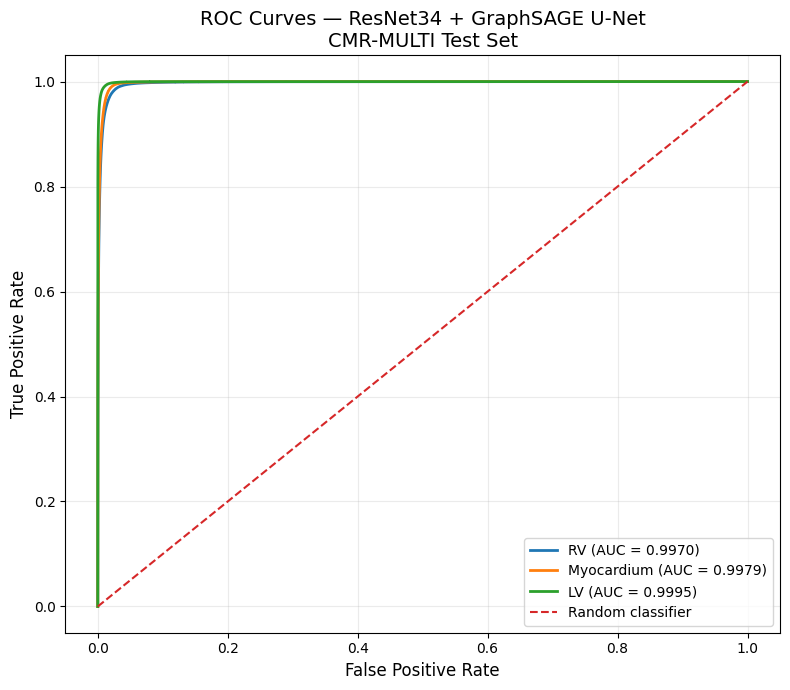

CMR-MULTI GRAPHSAGE ROC-AUC
RV          : 0.9970
Myocardium  : 0.9979
LV          : 0.9995

Macro Average: 0.9981

Figure saved:
/content/drive/MyDrive/Thesis_Figures/CMR_MULTI_GraphSAGE_UNet_ROC.png

✓ GraphSAGE ROC figure successfully saved.


In [ ]:
# CELL 42 — GRAPHSAGE ROC-AUC VISUALIZATION
# CMR-MULTI

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc
)


# 1. OUTPUT DIRECTORY

FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "Thesis_Figures"
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)


ROC_SAVE_PATH = os.path.join(
    FIGURE_DIR,
    "CMR_MULTI_GraphSAGE_UNet_ROC.png"
)


# 2. CLASS INFORMATION

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}


# 3. CREATE ROC FIGURE

plt.figure(
    figsize=(8, 7)
)


roc_values = {}


for class_id, class_name in (
    class_names.items()
):

    y_true = np.concatenate(
        roc_true[class_id]
    )

    y_prob = np.concatenate(
        roc_prob[class_id]
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )


    roc_auc = auc(
        fpr,
        tpr
    )


    roc_values[
        class_name
    ] = roc_auc


    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{class_name} "
            f"(AUC = {roc_auc:.4f})"
        )
    )


# 4. RANDOM-CLASSIFIER REFERENCE

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)


# 5. FORMATTING

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curves — ResNet34 + GraphSAGE U-Net\n"
    "CMR-MULTI Test Set",
    fontsize=14
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()


# 6. SAVE

plt.savefig(
    ROC_SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 7. VERIFY

print("=" * 70)

print(
    "CMR-MULTI GRAPHSAGE ROC-AUC"
)

print("=" * 70)


for class_name, value in (
    roc_values.items()
):

    print(
        f"{class_name:<12}: "
        f"{value:.4f}"
    )


macro_auc = np.mean(
    list(
        roc_values.values()
    )
)


print(
    f"\nMacro Average: "
    f"{macro_auc:.4f}"
)


print(
    "\nFigure saved:"
)

print(
    ROC_SAVE_PATH
)


assert os.path.exists(
    ROC_SAVE_PATH
)


print(
    "\n✓ GraphSAGE ROC figure successfully saved."
)

# Check Saved CMR-MULTI Files

In [ ]:
# CELL 43 — CHECK SAVED CMR-MULTI MODELS AND FIGURES

import os

DRIVE_ROOT = "/content/drive/MyDrive"

print("=" * 70)
print("SEARCHING FOR SAVED CMR-MULTI FILES")
print("=" * 70)

matches = []

keywords = [
    "cmr",
    "multi"
]

for root, dirs, files in os.walk(DRIVE_ROOT):

    for filename in files:

        full_path = os.path.join(
            root,
            filename
        )

        name_lower = filename.lower()

        # Look for anything that appears related to CMR-MULTI
        if (
            "cmr" in name_lower
            or "cmr_multi" in name_lower
        ):

            matches.append(
                full_path
            )


print(
    f"\nFound {len(matches)} "
    f"CMR-related files:\n"
)


for i, path in enumerate(
    sorted(matches),
    start=1
):

    try:

        size_mb = (
            os.path.getsize(path)
            / (1024 ** 2)
        )

        print(
            f"{i:02d}. "
            f"{path}"
        )

        print(
            f"    Size: "
            f"{size_mb:.2f} MB"
        )

    except:

        print(
            f"{i:02d}. "
            f"{path}"
        )


print(
    "\n" + "=" * 70
)

print(
    "SEARCH COMPLETE"
)

print(
    "=" * 70
)

SEARCHING FOR SAVED CMR-MULTI FILES

Found 3 CMR-related files:

01. /content/drive/MyDrive/Thesis_Checkpoints/CMR_MULTI/best_graphsage_unet_cmr_multi.pth
    Size: 331.61 MB
02. /content/drive/MyDrive/Thesis_Checkpoints/CMR_MULTI/latest_graphsage_unet_cmr_multi.pth
    Size: 331.62 MB
03. /content/drive/MyDrive/Thesis_Figures/CMR_MULTI_GraphSAGE_UNet_ROC.png
    Size: 0.19 MB

SEARCH COMPLETE


# CMR-MULTI GraphSAGE Qualitative Visualization

Selected test indices: [25, 325, 625]


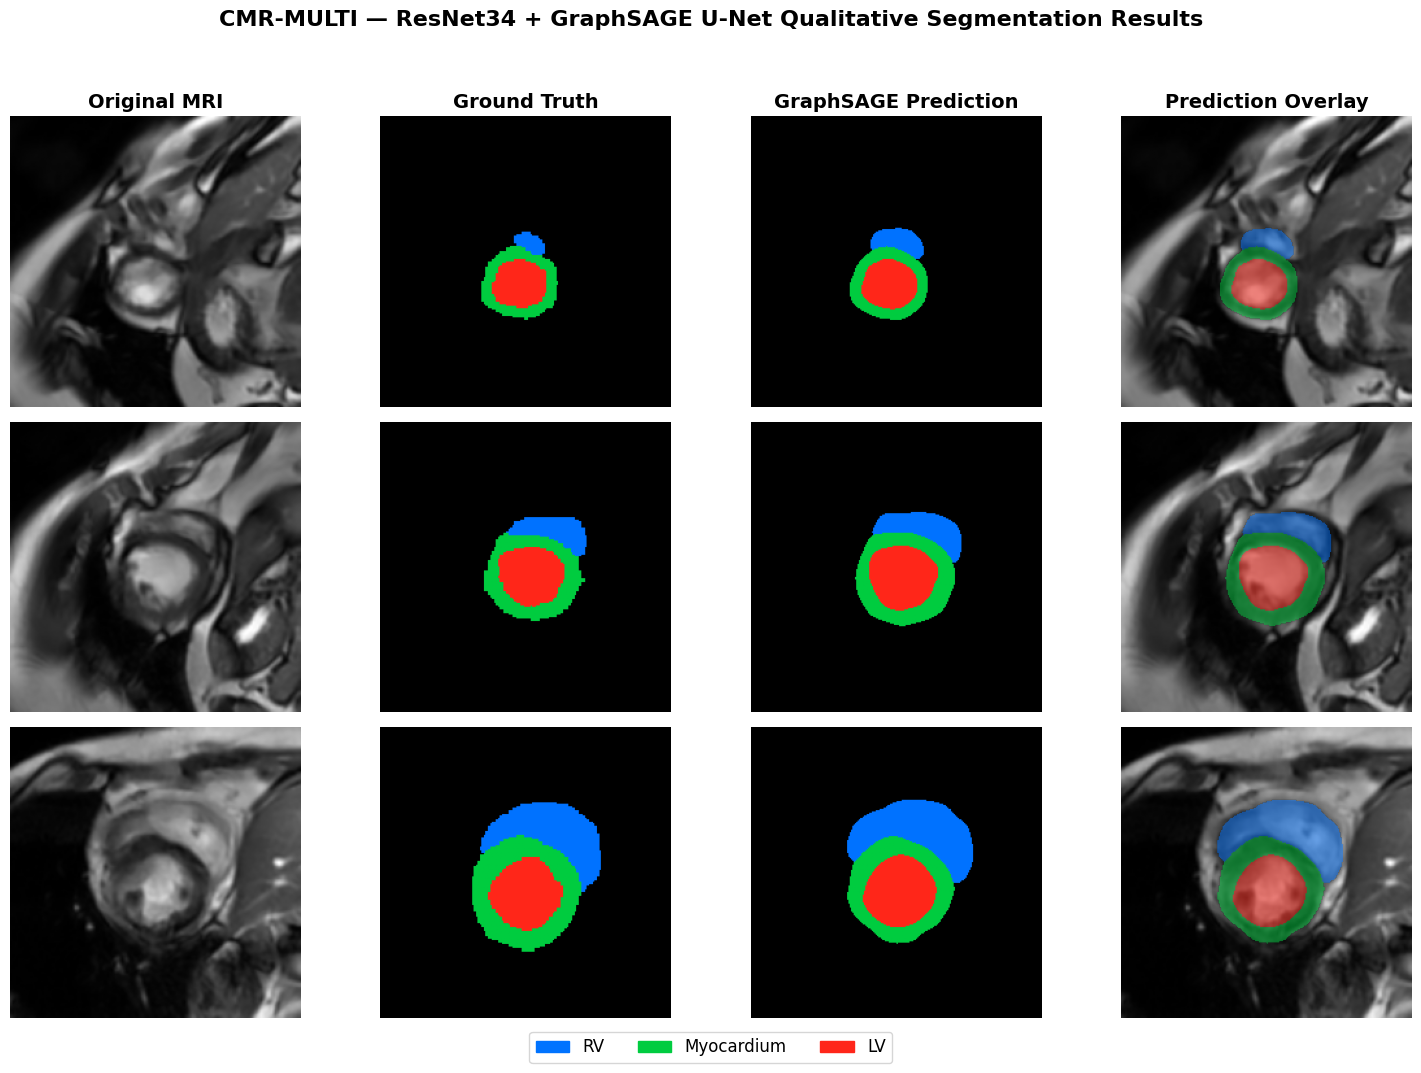


Selected test indices: [25, 325, 625]
Figure saved:
/content/drive/MyDrive/Thesis_Figures/CMR_MULTI_GraphSAGE_Qualitative_Comparison.png
Figure size: 0.42 MB

✓ CMR-MULTI GraphSAGE qualitative figure saved.


In [ ]:
# CELL 44 — GRAPHSAGE QUALITATIVE SEGMENTATION VISUALIZATION
# CMR-MULTI
#
# 3 test examples:
# Original MRI | Ground Truth | Prediction | Overlay

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch


# 1. SETTINGS

FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "Thesis_Figures"
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)


FIGURE_PATH = os.path.join(
    FIGURE_DIR,
    "CMR_MULTI_GraphSAGE_Qualitative_Comparison.png"
)


# Explicit colors:
#
# 0 = Background = black
# 1 = RV         = blue
# 2 = Myocardium = green
# 3 = LV         = red

SEG_COLORS = np.array([
    [0.00, 0.00, 0.00],   # Background
    [0.00, 0.45, 1.00],   # RV
    [0.00, 0.80, 0.25],   # Myocardium
    [1.00, 0.15, 0.10]    # LV
])


# 2. HELPER — DENORMALIZE MRI

IMAGENET_MEAN = np.array([
    0.485,
    0.456,
    0.406
])

IMAGENET_STD = np.array([
    0.229,
    0.224,
    0.225
])


def denormalize_image(image_tensor):

    image = (
        image_tensor
        .detach()
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    image = (
        image * IMAGENET_STD
        + IMAGENET_MEAN
    )

    image = np.clip(
        image,
        0,
        1
    )

    # Original input is grayscale repeated
    # over three channels.

    return image[:, :, 0]


# 3. HELPER — COLORIZE SEGMENTATION

def colorize_mask(mask):

    mask = mask.astype(
        np.int64
    )

    return SEG_COLORS[
        mask
    ]


# 4. FIND 3 QUALITATIVE EXAMPLES
#
# Require all three foreground classes:
# RV = 1, Myocardium = 2, LV = 3

selected_examples = []

selected_indices = []


graphsage_model.eval()


with torch.no_grad():

    for idx in range(
        len(test_dataset)
    ):

        image, mask = (
            test_dataset[idx]
        )


        unique_labels = set(
            torch.unique(mask)
            .cpu()
            .numpy()
            .tolist()
        )


        # Require all 3 anatomical structures
        if not {
            1,
            2,
            3
        }.issubset(
            unique_labels
        ):

            continue


        # Spread examples through test dataset
        # instead of simply taking 3 adjacent slices.

        if len(
            selected_examples
        ) == 0:

            choose = True

        else:

            choose = (
                idx
                - selected_indices[-1]
                >= 300
            )


        if not choose:

            continue


        input_image = (
            image
            .unsqueeze(0)
            .to(device)
        )


        logits = graphsage_model(
            input_image
        )


        prediction = torch.argmax(
            logits,
            dim=1
        )[0]


        selected_examples.append(
            (
                image.cpu(),
                mask.cpu(),
                prediction.cpu()
            )
        )


        selected_indices.append(
            idx
        )


        if len(
            selected_examples
        ) == 3:

            break

# 5. SAFETY CHECK

if len(
    selected_examples
) < 3:

    raise RuntimeError(
        "Could not find 3 suitable "
        "all-class test examples."
    )


print(
    "Selected test indices:",
    selected_indices
)

# 6. CREATE 3 × 4 FIGURE

fig, axes = plt.subplots(
    3,
    4,
    figsize=(15, 11)
)


column_titles = [
    "Original MRI",
    "Ground Truth",
    "GraphSAGE Prediction",
    "Prediction Overlay"
]


for col, title in enumerate(
    column_titles
):

    axes[0, col].set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )


# 7. DRAW EACH EXAMPLE

for row, (
    image_tensor,
    mask_tensor,
    pred_tensor
) in enumerate(
    selected_examples
):

    image = denormalize_image(
        image_tensor
    )


    gt = (
        mask_tensor
        .numpy()
        .astype(np.int64)
    )


    pred = (
        pred_tensor
        .numpy()
        .astype(np.int64)
    )


    gt_rgb = colorize_mask(
        gt
    )


    pred_rgb = colorize_mask(
        pred
    )


    # Original MRI

    axes[row, 0].imshow(
        image,
        cmap="gray"
    )


    # Ground Truth

    axes[row, 1].imshow(
        gt_rgb
    )


    # Prediction


    axes[row, 2].imshow(
        pred_rgb
    )

    # Overlay

    axes[row, 3].imshow(
        image,
        cmap="gray"
    )


    foreground_overlay = np.ma.masked_where(
        pred == 0,
        pred
    )


    axes[row, 3].imshow(
        foreground_overlay,
        cmap=plt.matplotlib.colors.ListedColormap(
            SEG_COLORS[1:]
        ),
        vmin=1,
        vmax=3,
        alpha=0.50
    )


    # Row label

    axes[row, 0].set_ylabel(
        f"Example {row + 1}",
        fontsize=12,
        fontweight="bold"
    )


    for col in range(4):

        axes[row, col].axis(
            "off"
        )


# 8. LEGEND

legend_handles = [

    mpatches.Patch(
        color=SEG_COLORS[1],
        label="RV"
    ),

    mpatches.Patch(
        color=SEG_COLORS[2],
        label="Myocardium"
    ),

    mpatches.Patch(
        color=SEG_COLORS[3],
        label="LV"
    )

]


fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    fontsize=12,
    bbox_to_anchor=(
        0.5,
        0.015
    )
)


# 9. MAIN TITLE

fig.suptitle(
    "CMR-MULTI — ResNet34 + GraphSAGE U-Net "
    "Qualitative Segmentation Results",
    fontsize=16,
    fontweight="bold",
    y=0.98
)


plt.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.95
    ]
)


# 10. SAVE

plt.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 11. VERIFY SAVE

assert os.path.exists(
    FIGURE_PATH
)


size_mb = (
    os.path.getsize(
        FIGURE_PATH
    )
    / (1024 ** 2)
)


print(
    "\nSelected test indices:",
    selected_indices
)

print(
    "Figure saved:"
)

print(
    FIGURE_PATH
)

print(
    f"Figure size: "
    f"{size_mb:.2f} MB"
)

print(
    "\n✓ CMR-MULTI GraphSAGE qualitative figure saved."
)

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".pth", ".pt", ".ckpt")):
            print(os.path.join(root, file))